# Import Relevant Libraries

In [1]:
!export PATH="${HOME}/.local/bin:${PATH}" && uv pip uninstall --system jax

Using Python 3.12.13 environment at: /usr/local
Uninstalled 1 package in 197ms
 - jax==0.10.1


In [2]:
!export PATH="${HOME}/.local/bin:${PATH}" && uv pip install --system tensorflow=="2.18.0" tensorflow-tpu=="2.18.0" optuna optuna-integration polars git+https://github.com/Nindaime/keras-tcn.git@master --find-links https://storage.googleapis.com/libtpu-tf-releases/index.html

Using Python 3.12.13 environment at: /usr/local
Resolved 51 packages in 2.97s                                        
Prepared 17 packages in 15.08s                                           
Uninstalled 6 packages in 4.80s
Installed 17 packages in 8.95s0                             
 + alembic==1.18.5
 + colorlog==6.11.0
 + greenlet==3.5.3
 + keras-tcn==3.5.7 (from git+https://github.com/Nindaime/keras-tcn.git@7576256b8b2a138b88ae2483b8616681686e424f)
 - libtpu==0.0.17
 + libtpu==2.18.0
 + mako==1.3.12
 - ml-dtypes==0.5.4
 + ml-dtypes==0.4.1
 - numpy==2.4.6
 + numpy==2.0.2
 + optuna==4.9.0
 + optuna-integration==4.9.0
 + polars==1.42.1
 + polars-runtime-32==1.42.1
 - protobuf==7.35.0
 + protobuf==5.29.6
 + sqlalchemy==2.0.51
 - tensorboard==2.20.0
 + tensorboard==2.18.0
 - tensorflow==2.20.0
 + tensorflow==2.18.0
 + tensorflow-tpu==2.18.0


In [1]:
import tensorflow as tf
print('TensorFlow version' + tf.__version__)

2026-08-17 00:03:13.739424: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1786924993.934760      59 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1786924993.993765      59 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1786924994.442571      59 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1786924994.442620      59 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1786924994.442623      59 computation_placer.cc:177] computation placer alr

TensorFlow version2.19.0


In [9]:
import os
# 0 = INFO, 1 = WARNING, 2 = ERROR, 3 = FATAL
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3" 

# Setting this to 2 will suppress INFO/WARNING logs from the C++ runtime
os.environ["GLOG_minloglevel"] = "2"

In [5]:
from tqdm.notebook import tqdm
from tcn import TCN
import pandas as pd
import polars as pl
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import os, gc, sys, glob, matplotlib, joblib, pickle, json, datetime
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.preprocessing import StandardScaler, LabelEncoder
import tensorflow as tf
from pandas.api.types import is_numeric_dtype
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import LSTM, Conv1D, GRU, Dense, Bidirectional, LayerNormalization, BatchNormalization, GlobalAveragePooling1D, Input, MultiHeadAttention, Dropout
from tensorflow.keras.models import Model, load_model
import seaborn as sns
from scipy import stats
import optuna
from optuna_integration.tfkeras import TFKerasPruningCallback
from optuna.trial import TrialState, FixedTrial
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import numpy as np
from tensorflow.keras import backend as K
from sklearn.metrics import confusion_matrix, classification_report, f1_score, recall_score, precision_score, roc_auc_score

sns.set_theme(style="white", palette=None)
color_pal = plt.rcParams["axes.prop_cycle"].by_key()["color"]

2026-07-22 00:52:33.298123: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1784681553.450912      58 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1784681553.499359      58 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1784681553.859320      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1784681553.859351      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1784681553.859354      58 computation_placer.cc:177] computation placer alr

## Function Defined to Clear Memory for Memory Management

In [2]:
def clear_memory():
    # Clear the last output reference
    _ = None
    
    # Clear the entire output history dictionary
    import sys
    if 'ipykernel' in sys.modules:
        from IPython import get_ipython
        get_ipython().user_ns['Out'] = {}
        print('memory cleared')

## Load Raw Dataset

In [3]:
# --- CONFIGURATION ---
DATASET_PATH = "/kaggle/input/datasets/nguyennhuwz/nf-uq-nids-v3-55features/NF_merged_shuffled.parquet"  # Replace with your actual path
TARGET_COL = "Attack"
DROPPED_COLS = ["source_dataset", "Attack_std", "Label"]

# Full list of columns as provided
ALL_COLUMNS = [
    "FLOW_START_MILLISECONDS",
    "FLOW_END_MILLISECONDS",
    "IPV4_SRC_ADDR",
    "L4_SRC_PORT",
    "IPV4_DST_ADDR",
    "L4_DST_PORT",
    "PROTOCOL",
    "L7_PROTO",
    "IN_BYTES",
    "IN_PKTS",
    "OUT_BYTES",
    "OUT_PKTS",
    "TCP_FLAGS",
    "CLIENT_TCP_FLAGS",
    "SERVER_TCP_FLAGS",
    "FLOW_DURATION_MILLISECONDS",
    "DURATION_IN",
    "DURATION_OUT",
    "MIN_TTL",
    "MAX_TTL",
    "LONGEST_FLOW_PKT",
    "SHORTEST_FLOW_PKT",
    "MIN_IP_PKT_LEN",
    "MAX_IP_PKT_LEN",
    "SRC_TO_DST_SECOND_BYTES",
    "DST_TO_SRC_SECOND_BYTES",
    "RETRANSMITTED_IN_BYTES",
    "RETRANSMITTED_IN_PKTS",
    "RETRANSMITTED_OUT_BYTES",
    "RETRANSMITTED_OUT_PKTS",
    "SRC_TO_DST_AVG_THROUGHPUT",
    "DST_TO_SRC_AVG_THROUGHPUT",
    "NUM_PKTS_UP_TO_128_BYTES",
    "NUM_PKTS_128_TO_256_BYTES",
    "NUM_PKTS_256_TO_512_BYTES",
    "NUM_PKTS_512_TO_1024_BYTES",
    "NUM_PKTS_1024_TO_1514_BYTES",
    "TCP_WIN_MAX_IN",
    "TCP_WIN_MAX_OUT",
    "ICMP_TYPE",
    "ICMP_IPV4_TYPE",
    "DNS_QUERY_ID",
    "DNS_QUERY_TYPE",
    "DNS_TTL_ANSWER",
    "FTP_COMMAND_RET_CODE",
    "SRC_TO_DST_IAT_MIN",
    "SRC_TO_DST_IAT_MAX",
    "SRC_TO_DST_IAT_AVG",
    "SRC_TO_DST_IAT_STDDEV",
    "DST_TO_SRC_IAT_MIN",
    "DST_TO_SRC_IAT_MAX",
    "DST_TO_SRC_IAT_AVG",
    "DST_TO_SRC_IAT_STDDEV",
    "Label",
    "Attack",
    "Attack_std",
    "source_dataset",
]

# Identify the 53 feature columns to analyze
FEATURE_COLS = [
    col for col in ALL_COLUMNS if col not in DROPPED_COLS and col != TARGET_COL
]

# Initialize the tracking dataframe (4 rows x 53 columns)
analysis_metrics = ["Extra_Tree", "Pearson", "Spearman", "Average_Rank"]
results_df = pd.DataFrame(
    0.0, index=analysis_metrics, columns=FEATURE_COLS
)

# --- STEP 1: LOAD TARGET VARIABLE WITH SUBSAMPLING ---
# To prevent ExtraTrees from crashing 32GB RAM, we use a large representative sample (2 million rows)
print("Loading target variable...")
target_series = pd.read_parquet(DATASET_PATH, columns=[TARGET_COL])[TARGET_COL]

# Encode target if it's categorical
if not is_numeric_dtype(target_series):
    print(f"Target detected as {target_series.dtype}. Encoding text to numbers...")
    le_target = LabelEncoder()
    encoded_vals = le_target.fit_transform(target_series.astype(str))
    target_series = pd.Series(encoded_vals, index=target_series.index)

target_series = pd.to_numeric(target_series)

# Create a sample index for the calculations to respect RAM limits
SAMPLE_SIZE = min(2000000, len(target_series))
np.random.seed(42)
sample_idx = np.random.choice(len(target_series), size=SAMPLE_SIZE, replace=False)

y_sample = target_series.iloc[sample_idx].reset_index(drop=True)
print(f"Target ready. Shape: {y_sample.shape}, Dtype: {y_sample.dtype}")

# A quick sanity check to prove no strings made it through:
assert is_numeric_dtype(y_sample), "Target is STILL not numeric! Check your dataset."

Loading target variable...
Target detected as category. Encoding text to numbers...
Target ready. Shape: (2000000,), Dtype: int64


### Perform Feature Selection and Extraction Based on User Constraints to Manage Memory Resource

In [5]:
# --- STEP 2: PROCESS COLUMNS IN CHUNKS ---
chunk_size = 10

for i in tqdm(range(0, len(FEATURE_COLS), chunk_size)):
    chunk_cols = FEATURE_COLS[i : i + chunk_size]
    print(f"Processing chunk: {chunk_cols}")

    # Load chunk, slice using sample_idx, and reset index
    chunk_df = pd.read_parquet(DATASET_PATH, columns=chunk_cols).iloc[sample_idx].reset_index(drop=True)

    # 1. Feature Analysis Loop
    for col in chunk_cols:
        s = chunk_df[col].copy()
        
        if not is_numeric_dtype(s) or isinstance(s.dtype, pd.CategoricalDtype):
            s = pd.Series(LabelEncoder().fit_transform(s.astype(str)))
        else:
            # DESTROY INFINITIES: Convert inf to NaN, then fill with median
            s = s.replace([np.inf, -np.inf], np.nan)
            s = s.fillna(s.median())

        # Pearson & Spearman Analysis
        pearson_val = abs(s.corr(y_sample, method="pearson"))
        spearman_val = abs(s.corr(y_sample, method="spearman"))

        results_df.loc["Pearson", col] = 0.0 if np.isnan(pearson_val) else pearson_val
        results_df.loc["Spearman", col] = 0.0 if np.isnan(spearman_val) else spearman_val

    # 2. Extra Trees Preparation
    X_chunk = chunk_df.copy()
    for col in X_chunk.columns:
        if not is_numeric_dtype(X_chunk[col]) or isinstance(X_chunk[col].dtype, pd.CategoricalDtype):
            encoded_vals = LabelEncoder().fit_transform(X_chunk[col].astype(str))
            X_chunk[col] = pd.Series(encoded_vals, index=X_chunk.index)
        else:
            # DESTROY INFINITIES for the tree classifier as well
            X_chunk[col] = X_chunk[col].replace([np.inf, -np.inf], np.nan)
            X_chunk[col] = X_chunk[col].fillna(X_chunk[col].median())

    # Fit Extra Trees
    et = ExtraTreesClassifier(n_estimators=50, max_depth=12, random_state=42, n_jobs=-1)
    et.fit(X_chunk, y_sample)

    for col, importance in zip(chunk_cols, et.feature_importances_):
        results_df.loc["Extra_Tree", col] = importance

    # Garbage collection to maintain RAM
    del chunk_df, X_chunk
    gc.collect()

print("\nProcessing complete! Infinities neutralized.")

NameError: name 'FEATURE_COLS' is not defined

### View Feature Ranking based on Feature Analysis Score (Extra Tree Classifier, Pearson & Spearman)

In [5]:
# Use apply() to calculate the mean of those rows for each column
metrics = analysis_metrics[:3]
print(metrics)
results_df.loc["Average_Rank"] = results_df.loc[metrics].apply(np.mean, axis=0)
results_df.head()

['Extra_Tree', 'Pearson', 'Spearman']


,FLOW_START_MILLISECONDS,FLOW_END_MILLISECONDS,IPV4_SRC_ADDR,L4_SRC_PORT,IPV4_DST_ADDR,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,IN_PKTS,...,DNS_TTL_ANSWER,FTP_COMMAND_RET_CODE,SRC_TO_DST_IAT_MIN,SRC_TO_DST_IAT_MAX,SRC_TO_DST_IAT_AVG,SRC_TO_DST_IAT_STDDEV,DST_TO_SRC_IAT_MIN,DST_TO_SRC_IAT_MAX,DST_TO_SRC_IAT_AVG,DST_TO_SRC_IAT_STDDEV
Extra_Tree,0.320527,0.280370,0.077776,0.057307,0.059539,0.113779,0.031467,0.045864,0.004132,0.009241,...,0.001572,0.002761,0.194946,0.228364,0.280194,0.111504,0.029770,0.292510,0.375896,0.331594
Pearson,0.303316,0.303316,0.133383,0.140414,0.080567,0.232896,0.110225,0.084082,0.003484,0.002817,...,0.001973,0.009633,0.010685,0.073945,0.025212,0.078621,0.007969,0.089559,0.040710,0.099483
Spearman,0.310317,0.310316,0.385473,0.004573,0.316699,0.282134,0.041416,0.065375,0.171982,0.232963,...,0.234422,0.048720,0.324844,0.236412,0.249155,0.224376,0.078695,0.044231,0.035072,0.050520
Average_Rank,0.311387,0.298001,0.198877,0.067431,0.152268,0.209603,0.061036,0.065107,0.059866,0.081674,...,0.079322,0.020371,0.176825,0.179574,0.184853,0.138167,0.038811,0.142100,0.150559,0.160533


### Plot Feature Selection Based on Average Ranking

/tmp/ipykernel_58/578309841.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=sorted_series.values, x=sorted_series.index, palette="viridis")


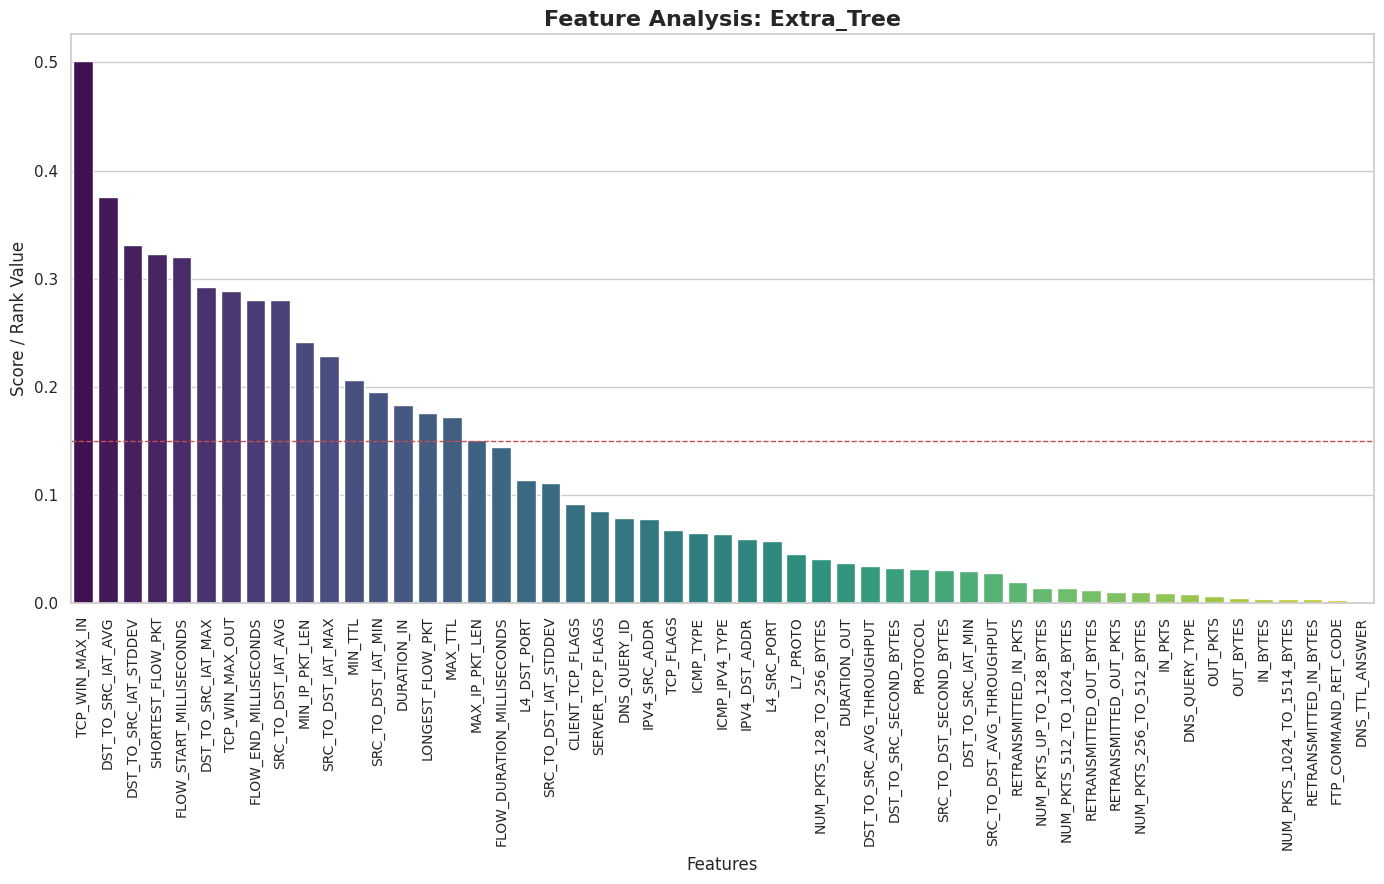

/tmp/ipykernel_58/578309841.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=sorted_series.values, x=sorted_series.index, palette="viridis")


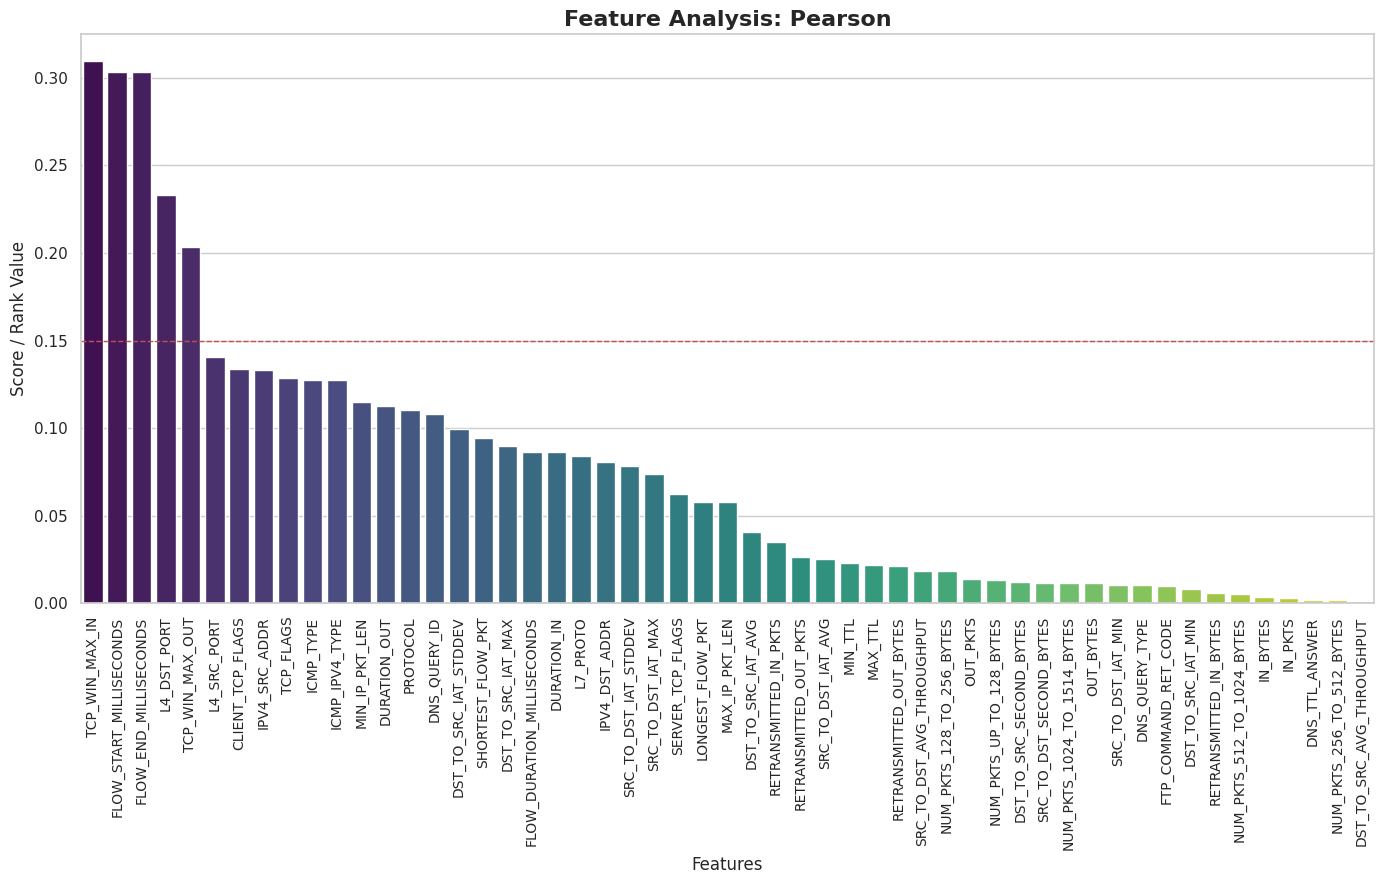

/tmp/ipykernel_58/578309841.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=sorted_series.values, x=sorted_series.index, palette="viridis")


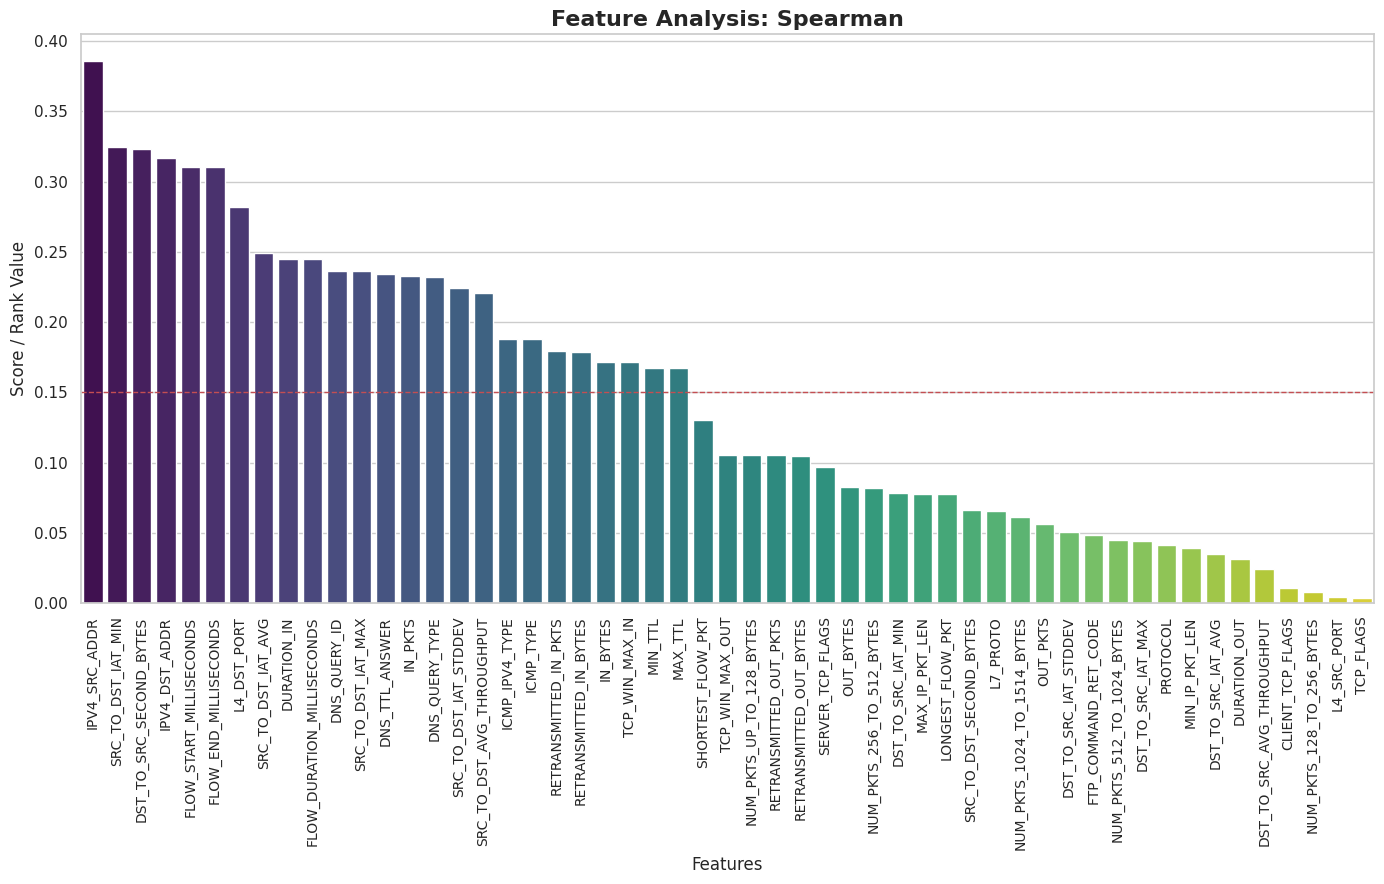

/tmp/ipykernel_58/578309841.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=sorted_series.values, x=sorted_series.index, palette="viridis")


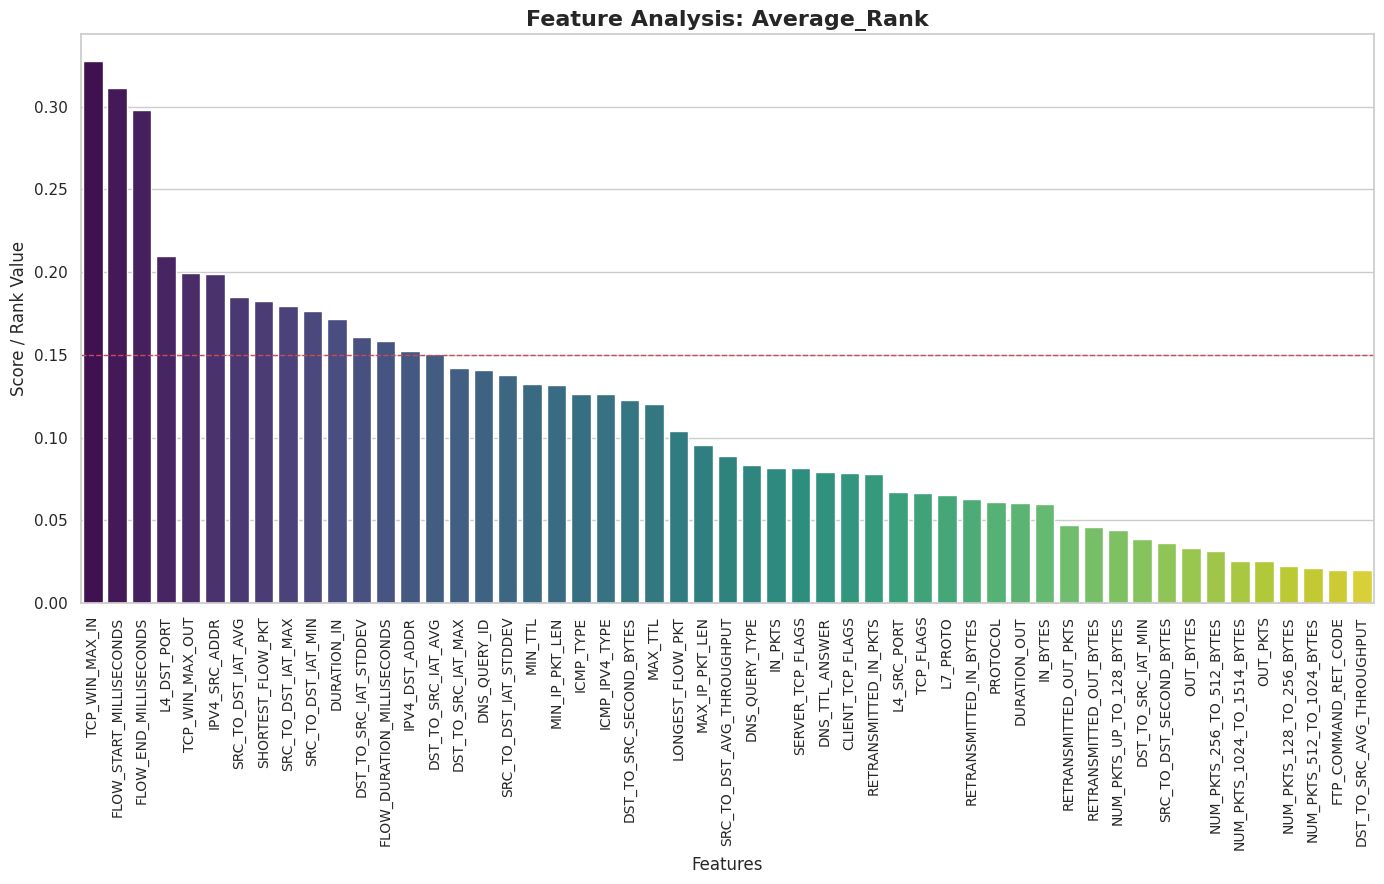

In [6]:
# Setup plotting style
sns.set_theme(style="whitegrid")
metrics_to_plot = ["Extra_Tree", "Pearson", "Spearman", "Average_Rank"]

for metric in metrics_to_plot:
    plt.figure(figsize=(14, 9))

    # For metrics, higher is better. For Rank, lower numerical value is better.
    # ascending_order = True if metric == "Average_Rank" else False
    sorted_series = results_df.loc[metric].sort_values(ascending=False)
    threshold_feature_score = 0.15

    sns.barplot(y=sorted_series.values, x=sorted_series.index, palette="viridis")
    plt.axhline(y=threshold_feature_score, color='r', linestyle='dashed', linewidth=1, label=f'Threshold: {threshold_feature_score}')  # Add line
    plt.title(f"Feature Analysis: {metric}", fontsize=16, fontweight="bold")
    plt.ylabel("Score / Rank Value", fontsize=12)
    plt.xlabel("Features", fontsize=12)
    plt.xticks(rotation=90, fontsize=10)
    plt.tight_layout()
    # plt.savefig(f"{metric}_barchart.png", dpi=300)
    plt.show()

In [7]:
results_df.T.sort_values(by='Average_Rank', ascending=False)

,Extra_Tree,Pearson,Spearman,Average_Rank
TCP_WIN_MAX_IN,0.500955,0.309385,0.171494,0.327278
FLOW_START_MILLISECONDS,0.320527,0.303316,0.310317,0.311387
FLOW_END_MILLISECONDS,0.280370,0.303316,0.310316,0.298001
L4_DST_PORT,0.113779,0.232896,0.282134,0.209603
TCP_WIN_MAX_OUT,0.288650,0.203251,0.105637,0.199179
IPV4_SRC_ADDR,0.077776,0.133383,0.385473,0.198877
SRC_TO_DST_IAT_AVG,0.280194,0.025212,0.249155,0.184853
SHORTEST_FLOW_PKT,0.323094,0.094625,0.130214,0.182644
SRC_TO_DST_IAT_MAX,0.228364,0.073945,0.236412,0.179574
SRC_TO_DST_IAT_MIN,0.194946,0.010685,0.324844,0.176825


### Selected Features Based on Threshold Value (0.15)

In [8]:
selected_features_15_label = results_df.T[results_df.T['Average_Rank'] >= 0.15].index.tolist()
print(f'There are {len(selected_features_15_label)} features')
selected_features_15_label

There are 15 features


['FLOW_START_MILLISECONDS',
 'FLOW_END_MILLISECONDS',
 'IPV4_SRC_ADDR',
 'IPV4_DST_ADDR',
 'L4_DST_PORT',
 'FLOW_DURATION_MILLISECONDS',
 'DURATION_IN',
 'SHORTEST_FLOW_PKT',
 'TCP_WIN_MAX_IN',
 'TCP_WIN_MAX_OUT',
 'SRC_TO_DST_IAT_MIN',
 'SRC_TO_DST_IAT_MAX',
 'SRC_TO_DST_IAT_AVG',
 'DST_TO_SRC_IAT_AVG',
 'DST_TO_SRC_IAT_STDDEV']

### Append Label column to extract input-output features

In [9]:
selected_features_15_label.append('Attack')
selected_features_15_label

['FLOW_START_MILLISECONDS',
 'FLOW_END_MILLISECONDS',
 'IPV4_SRC_ADDR',
 'IPV4_DST_ADDR',
 'L4_DST_PORT',
 'FLOW_DURATION_MILLISECONDS',
 'DURATION_IN',
 'SHORTEST_FLOW_PKT',
 'TCP_WIN_MAX_IN',
 'TCP_WIN_MAX_OUT',
 'SRC_TO_DST_IAT_MIN',
 'SRC_TO_DST_IAT_MAX',
 'SRC_TO_DST_IAT_AVG',
 'DST_TO_SRC_IAT_AVG',
 'DST_TO_SRC_IAT_STDDEV',
 'Attack']

### Prepare Input Dataset for Processing

In [14]:
combined_df = pd.read_parquet('/kaggle/input/datasets/nguyennhuwz/nf-uq-nids-v3-55features/NF_merged_shuffled.parquet', columns=selected_features_15_label)
combined_df.head()

,FLOW_START_MILLISECONDS,FLOW_END_MILLISECONDS,IPV4_SRC_ADDR,IPV4_DST_ADDR,L4_DST_PORT,FLOW_DURATION_MILLISECONDS,DURATION_IN,SHORTEST_FLOW_PKT,TCP_WIN_MAX_IN,TCP_WIN_MAX_OUT,SRC_TO_DST_IAT_MIN,SRC_TO_DST_IAT_MAX,SRC_TO_DST_IAT_AVG,DST_TO_SRC_IAT_AVG,DST_TO_SRC_IAT_STDDEV,Attack
0,1519935379918,1519935398849,63.141.245.34,172.31.65.75,3389,18931,18931,40,8192,64000,0,11009,1720,2592,3649,Benign
1,1556345352336,1556345352339,192.168.1.32,192.168.1.1,53,2,0,65,0,0,0,0,0,0,0,xss
2,1519237930542,1519237930579,18.219.9.1,172.31.69.28,80,36,36,40,65535,26883,0,33,8,9,14,DDOS_attack-HOIC
3,1528081327329,1528081353704,192.168.100.149,192.168.100.5,80,26375,26375,40,512,0,6124,12459,8791,0,0,DoS
4,1556076279764,1556076279764,192.168.1.32,192.168.35.221,443,1,0,44,1024,0,0,0,0,0,0,scanning


#### Statistical Distribution of Each Attack Type in the Dataset

In [5]:
combined_df['Attack'].value_counts()

Attack
Benign                      36596560
DoS                          8040170
DDoS                         7150882
ddos                         4141256
xss                          2834435
Reconnaissance               1712206
password                     1594777
scanning                     1358977
DDOS_attack-HOIC             1032311
FTP-BruteForce                386720
injection                     381777
DDoS_attacks-LOIC-HTTP        288589
Backdoor                      208043
Bot                           207703
dos                           203456
SSH-Bruteforce                188474
Infilteration                 188152
DoS_attacks-SlowHTTPTest      105550
DoS_attacks-Hulk              100076
DoS_attacks-GoldenEye          61300
Exploits                       42748
DoS_attacks-Slowloris          36040
Fuzzers                        33816
Generic                        19651
mitm                            6013
ransomware                      3971
DDOS_attack-LOIC-UDP           

#### Define Inplace Encode Function

In [16]:
def encode_dataset_inplace(dataset):
    encoding_mappings = {}
    
    # Identify categorical columns first so we don't change the list while iterating
    obj_cols = dataset.select_dtypes(include=['object', 'category']).columns
    
    
    for column in tqdm(obj_cols, desc="Encoding columns"):
        # 1. Get the unique categories and their codes
        # We use pd.factorize because it is generally faster and more memory-efficient 
        # than converting the whole column to a 'category' type first.
        codes, uniques = pd.factorize(dataset[column])
        
        # 2. Store the mapping (converted to list for your legend)
        encoding_mappings[column] = uniques.tolist()
        
        # 3. Overwrite the column with 32-bit integers immediately
        dataset[column] = codes.astype('int32')
        
        # 4. Explicitly cleanup the temporary 'uniques' and 'codes' objects
        del codes
        del uniques
        gc.collect() # Force clear after every large column
            
    return encoding_mappings # No need to return the dataset if modified in-place

In [17]:
mappings = encode_dataset_inplace(combined_df)

Encoding columns: 0it [00:00, ?it/s]

#### Encode and Save Feature Selected Dataset

In [16]:
# Save the combined dataframe
combined_df.to_parquet('ids_encoded_15_sel_feat.parquet', engine='pyarrow', compression='snappy')

# Save the mapping dictionary to disk
joblib.dump(mappings, 'ids_encoded_15_mappings.pkl')

['ids_encoded_15_mappings.pkl']

#### List Attach Type Encoding As Saved in the Mapping File

In [17]:
mappings['Attack']

['Benign',
 'xss',
 'DDOS_attack-HOIC',
 'DoS',
 'scanning',
 'password',
 'DDoS',
 'Reconnaissance',
 'ddos',
 'FTP-BruteForce',
 'SSH-Bruteforce',
 'Infilteration',
 'injection',
 'Backdoor',
 'DoS_attacks-SlowHTTPTest',
 'DDoS_attacks-LOIC-HTTP',
 'DoS_attacks-Hulk',
 'DoS_attacks-Slowloris',
 'dos',
 'Bot',
 'Fuzzers',
 'Exploits',
 'DoS_attacks-GoldenEye',
 'Generic',
 'Brute_Force_-XSS',
 'Brute_Force_-Web',
 'mitm',
 'DDOS_attack-LOIC-UDP',
 'Analysis',
 'Shellcode',
 'ransomware',
 'Theft',
 'SQL_Injection',
 'Worms']

# Load Dataset Stratified

## Define Function to Load Stratified Dataset

In [6]:
def load_stratified_data(parquet_path, mappings_path, total_rows=10_000_000, target_col="Attack", threshold_pct=0.10):
    print("1. Initializing LazyFrame and Loading Mappings...")
    # Scan the encoded parquet file without loading it into RAM
    lazy_df = pl.scan_parquet(parquet_path)
    
    # Load the dictionary mapping (Assuming it's structured like: {'Attack': {'Benign': 0, 'DoS': 1, ...}})
    with open(mappings_path, 'rb') as f:
        mappings = pickle.load(f)
        
    # Extract just the mapping for the target column
    label_map = mappings.get(target_col, mappings) 
    num_subcategories = len(label_map)
    print(f"   Detected {num_subcategories} unique classes from mappings.")

    print("\n2. Dynamically Computing Class Distributions...")
    # Calculate exact counts directly from the lazy frame (Highly optimized by Polars)
    counts_df = lazy_df.group_by(target_col).agg(pl.len().alias("count")).collect()
    
    # Convert to a dictionary of {encoded_int_label: count}
    class_counts = dict(zip(counts_df[target_col].to_list(), counts_df["count"].to_list()))
    
    print("\n3. Applying Threshold Stratification Logic...")
    threshold_limit = int(total_rows * threshold_pct)
    print(f"   10% Threshold Limit: {threshold_limit:,} rows")
    
    minority_classes = []
    majority_classes = []
    minority_total_rows = 0
    
    # Sort classes into minority (take all) and majority (stratify)
    for encoded_label, count in class_counts.items():
        if count < threshold_limit:
            minority_classes.append(encoded_label)
            minority_total_rows += count
        else:
            majority_classes.append(encoded_label)
            
    print(f"   Found {len(minority_classes)} Minority classes (Count < {threshold_limit:,}) -> Taking all rows.")
    print(f"   Found {len(majority_classes)} Majority classes (Count >= {threshold_limit:,}) -> Stratifying.")
    
    # Calculate the remaining quota to be divided among the majority classes
    remaining_rows_needed = total_rows - minority_total_rows
    rows_per_majority_class = remaining_rows_needed // max(1, len(majority_classes))
    
    print(f"   Minority classes consumed {minority_total_rows:,} rows.")
    print(f"   Remaining {remaining_rows_needed:,} rows will be split evenly.")
    print(f"   Target for each Majority class: {rows_per_majority_class:,} rows.\n")

    print("4. Executing Chunked Memory-Safe Extraction...")
    sampled_chunks = []
    
    # Iterate over every unique class present in the dataset
    for cat, count in tqdm(class_counts.items(), desc="Sampling Classes"):
        
        # Determine the target sample size for this specific class
        if cat in minority_classes:
            target_n = count # Take everything
        else:
            # Take the calculated majority target, but cap it if the class is somehow slightly smaller
            target_n = min(count, rows_per_majority_class)
            
        # Extract only this class into memory, sample it, and immediately append
        # By sampling immediately, we free up the massive un-sampled chunk from memory
        chunk = (
            lazy_df
            .filter(pl.col(target_col) == cat)
            .collect()
            .sample(n=target_n, shuffle=True)
        )
        
        sampled_chunks.append(chunk)
        
        # Force garbage collection to clear the un-sampled Polars objects from RAM
        del chunk
        gc.collect()

    print("\n5. Assembling and Shuffling Final Dataset...")
    # Concatenate all the sampled chunks into one contiguous DataFrame
    stratified_df = pl.concat(sampled_chunks)
    
    # Perform one final global shuffle so the model doesn't see classes sequentially
    stratified_df = stratified_df.sample(fraction=1.0, shuffle=True)
    
    # Convert to Pandas for your downstream ML pipeline
    encoded_iot_df = stratified_df.to_pandas()
    
    print("\nFinal Class Distribution in Memory:")
    print(encoded_iot_df[target_col].value_counts())
    print(f"\nTotal Dataset Shape: {encoded_iot_df.shape}")
    
    return encoded_iot_df

## Load Stratified Dataset of 15 Selected Features, 10 million Rows and 10% stratification threshold for Attack Types

In [7]:
# Thre
combined_df = load_stratified_data(
    parquet_path='/kaggle/working/ids_encoded_15_sel_feat.parquet',
    mappings_path='/kaggle/working/ids_encoded_15_mappings.pkl',
    total_rows=10_000_000,
    target_col="Attack",
    threshold_pct=0.10 #Attach Types with less than 10% of the requested number of rows (10 million) are loaded as is, the rest are stratifed
)

1. Initializing LazyFrame and Loading Mappings...
   Detected 34 unique classes from mappings.

2. Dynamically Computing Class Distributions...

3. Applying Threshold Stratification Logic...
   10% Threshold Limit: 1,000,000 rows
   Found 25 Minority classes (Count < 1,000,000) -> Taking all rows.
   Found 9 Majority classes (Count >= 1,000,000) -> Stratifying.
   Minority classes consumed 2,473,447 rows.
   Remaining 7,526,553 rows will be split evenly.
   Target for each Majority class: 836,283 rows.

4. Executing Chunked Memory-Safe Extraction...


Sampling Classes:   0%|          | 0/34 [00:00<?, ?it/s]


5. Assembling and Shuffling Final Dataset...

Final Class Distribution in Memory:
Attack
6     836283
2     836283
5     836283
4     836283
7     836283
1     836283
3     836283
8     836283
0     836283
9     386720
12    381777
15    288589
13    208043
19    207703
18    203456
10    188474
11    188152
14    105550
16    100076
22     61300
21     42748
17     36040
20     33816
23     19651
26      6013
30      3971
27      3450
29      2381
25      1618
31      1615
28      1226
24       480
32       440
33       158
Name: count, dtype: int64

Total Dataset Shape: (9999994, 16)


## Load 1 million rows for Optimization

In [12]:
# Thre
combined_df = load_stratified_data(
    parquet_path='/kaggle/working/ids_encoded_15_sel_feat.parquet',
    mappings_path='/kaggle/working/ids_encoded_15_mappings.pkl',
    total_rows=1_000_000,
    target_col="Attack",
    threshold_pct=0.03 #Attach Types with less than 10% of the requested number of rows (10 million) are loaded as is, the rest are stratifed
)

1. Initializing LazyFrame and Loading Mappings...
   Detected 34 unique classes from mappings.

2. Dynamically Computing Class Distributions...

3. Applying Threshold Stratification Logic...
   10% Threshold Limit: 30,000 rows
   Found 11 Minority classes (Count < 30,000) -> Taking all rows.
   Found 23 Majority classes (Count >= 30,000) -> Stratifying.
   Minority classes consumed 41,003 rows.
   Remaining 958,997 rows will be split evenly.
   Target for each Majority class: 41,695 rows.

4. Executing Chunked Memory-Safe Extraction...


Sampling Classes:   0%|          | 0/34 [00:00<?, ?it/s]


5. Assembling and Shuffling Final Dataset...

Final Class Distribution in Memory:
Attack
4     41695
11    41695
2     41695
0     41695
9     41695
10    41695
13    41695
15    41695
18    41695
22    41695
19    41695
8     41695
1     41695
16    41695
5     41695
3     41695
21    41695
6     41695
12    41695
7     41695
14    41695
17    36040
20    33816
23    19651
26     6013
30     3971
27     3450
29     2381
25     1618
31     1615
28     1226
24      480
32      440
33      158
Name: count, dtype: int64

Total Dataset Shape: (986454, 16)


#### Size of Loaded Stratified Feature Selected Dataset in Memory

In [6]:
print(f"Final Memory Usage: {combined_df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

Final Memory Usage: 514.98 MB


In [7]:
combined_df.head()

,FLOW_START_MILLISECONDS,FLOW_END_MILLISECONDS,IPV4_SRC_ADDR,IPV4_DST_ADDR,L4_DST_PORT,FLOW_DURATION_MILLISECONDS,DURATION_IN,SHORTEST_FLOW_PKT,TCP_WIN_MAX_IN,TCP_WIN_MAX_OUT,SRC_TO_DST_IAT_MIN,SRC_TO_DST_IAT_MAX,SRC_TO_DST_IAT_AVG,DST_TO_SRC_IAT_AVG,DST_TO_SRC_IAT_STDDEV,Attack
0,1556315254575,1556315254594,1,6,80,18,18,40,29200,65535,0,17,4,5,8,5
1,1556319056354,1556319056875,1,6,80,520,520,40,29200,65535,43,358,103,103,150,5
2,1528085802384,1528085823225,3,10,80,20840,20840,28,0,0,827,1160,905,0,0,3
3,1528099725913,1528099737122,14,10,80,11208,11208,28,0,0,2226,2255,2241,0,0,6
4,1556347218203,1556347218205,143,1,53,2,0,65,0,0,0,0,0,0,0,1


#### Check for Null and Infinity Values

In [18]:
# Find indices with NA or inf values
indices_with_na_inf = combined_df.index[combined_df.isna().any(axis=1) | combined_df.isin([np.inf, -np.inf]).any(axis=1)]

print("Indices with NA or infinity values:", indices_with_na_inf)

Indices with NA or infinity values: Index([], dtype='int64')


#### Fill Null And Infinity Values If Present

In [9]:
combined_df.fillna(0, inplace=True)
combined_df.replace([np.inf, -np.inf], 0, inplace=True)
combined_df.head()

,FLOW_START_MILLISECONDS,FLOW_END_MILLISECONDS,IPV4_SRC_ADDR,IPV4_DST_ADDR,L4_DST_PORT,FLOW_DURATION_MILLISECONDS,DURATION_IN,MIN_TTL,MAX_TTL,LONGEST_FLOW_PKT,...,ICMP_IPV4_TYPE,DNS_QUERY_ID,SRC_TO_DST_IAT_MIN,SRC_TO_DST_IAT_MAX,SRC_TO_DST_IAT_AVG,SRC_TO_DST_IAT_STDDEV,DST_TO_SRC_IAT_MAX,DST_TO_SRC_IAT_AVG,DST_TO_SRC_IAT_STDDEV,Attack
0,1518702564933,1518702569393,272,26,80,4460,4460,63,63,714,...,0,0,36,4423,1114,1910,4422,2211,2211,22
1,1528081933655,1528081954803,7,28,80,21147,21147,64,64,140,...,0,0,21147,21147,21147,0,0,0,0,3
2,1519137135568,1519137158429,38,26,80,22861,22861,127,127,1004,...,0,0,1485,21374,5714,9061,1485,495,700,15
3,1556249819800,1556249819801,44,24,443,1,0,64,64,60,...,0,0,0,0,0,0,0,0,0,8
4,1556525549292,1556525550824,64,57,8080,1531,1531,128,128,48,...,144,0,0,515,305,249,515,305,249,13


#### Perform Final Check for Null and Infinity Values

In [10]:
# Find indices with NA or inf values
indices_with_na_inf = combined_df.index[combined_df.isna().any(axis=1) | combined_df.isin([np.inf, -np.inf]).any(axis=1)]

print("Indices with NA or infinity values:", indices_with_na_inf)

Indices with NA or infinity values: Index([], dtype='int64')


## Extract Input and Output Label, and Scale Input Features

In [8]:
X = combined_df.drop(['Attack'], axis=1)
y = combined_df['Attack']

def scale_X(X):
    X_scaled = StandardScaler().fit_transform(X)
    return X_scaled
    
X_scaled = scale_X(X)
print(X_scaled[:5])

# Delete and collect immediately
del X
gc.collect()

[[-0.38033369 -0.38033228 -0.05136126 -0.15658915 -0.36224416  1.91998446
   1.92186699 -0.66044163 -0.84138594 -0.77208089  0.6144226   1.02295883
   0.83107943 -0.14346844 -0.13847269]
 [-0.78099916 -0.7809996   0.00914152 -0.15834984 -0.36224416 -0.41412661
  -0.41252033 -0.32535124  2.50030104  0.58989541 -0.29750042 -0.39150885
  -0.39400188 -0.14198385 -0.13386182]
 [ 0.89473824  0.89473809 -0.05765115 -0.15130705 -0.36224416 -0.38718075
  -0.38557129 -0.32535124  0.64754761  2.54812581 -0.29750042 -0.34037647
  -0.36869373 -0.11496422  0.01091944]
 [ 0.88900596  0.88900579 -0.01511949  4.10078007 -0.33412855 -0.40430137
  -0.40269394  0.00973916 -0.8293011  -0.76899044 -0.2327986  -0.3652122
  -0.34227314 -0.14346844 -0.13847269]
 [ 0.88211891  0.88211873 -0.05765115  1.39458632 -0.36224416 -0.41547978
  -0.41393251 -0.32535124 -0.78917128 -0.77208089 -0.29750042 -0.39311587
  -0.39539244 -0.14346844 -0.13847269]]


18

## Split Dataset into Training and Validation Dataset

In [9]:
from sklearn.model_selection import train_test_split

def split_train_test(X, y):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = .3, stratify = y, random_state=10)
    return X_train, X_test, y_train, y_test

X_train, X_test, y_train, y_test = split_train_test(X_scaled, y)
print(f'X_train Shape: {X_train.shape}') # shape of the training input variables i.e., row and columns
print(f'X_test Shape: {X_test.shape}') # shape of the test input variables i.e., row and columns
print(f'y_train Shape: {y_train.shape}') # shape of the training output variables i.e., row and columns
print(f'y_test Shape: {y_test.shape}') # shape of the test output variables i.e., row and columns

# Delete and collect immediately
del X_scaled, y
gc.collect()

X_train Shape: (6999995, 15)
X_test Shape: (2999999, 15)
y_train Shape: (6999995,)
y_test Shape: (2999999,)


0

## Define Function To Encode Output Variable with OneHot

In [10]:
# This code changes the "is_attack" column from 1 to 8 which maps to the number of attacks to enable the NN model classify better
def reshape_y(output):
    onehot = pd.get_dummies(output)
    output = onehot.to_numpy()
    
    return output

## Define Function to Encode Input Variables

In [11]:
# Define Method to Reshape 2D input - features to 3D for Reccurent Models¶
def reshape_x(data):
    if isinstance(data, pd.DataFrame):
        data = data.values
    
    # Reshape the data into a 3D array
    num_samples = data.shape[0] 
    input = np.zeros((num_samples, time_steps, num_features))
    for i in range(num_samples):
        if i+time_steps < num_samples:
            input[i, :, :] = data[i:i+time_steps, :]
            
    return input

In [12]:
time_steps = 4
num_features = X_train.shape[1]
tgat_num_features = num_features - 3 # Three features are combined into 1 feature from the TGAT graph network mapping
EPOCHS = 50
print(f'Feature Count: {num_features}')
print(f'TGAT Feature Count: {tgat_num_features}')
num_classes = len(y_train.value_counts())
print(f'Num Classes: {num_classes}')

Feature Count: 15
TGAT Feature Count: 12
Num Classes: 34


## Reshape Input 2D to 3D and Output 1D to 2D for Main Dataset

In [13]:
# reshape the X_train, X_test to be 3d array & trim the y_test and y_train to fit the row count of X_train and X_test
reshaped_X_train = reshape_x(X_train)
reshaped_X_test = reshape_x(X_test)
reshaped_y_train = reshape_y(y_train)
reshaped_y_test = reshape_y(y_test)

print(f'reshaped_X_train Shape: {reshaped_X_train.shape}') # shape of the training input variables i.e., row and columns
print(f'reshaped_X_test Shape: {reshaped_X_test.shape}') # shape of the test input variables i.e., row and columns
print(f'reshaped_y_train Shape: {reshaped_y_train.shape}') # shape of the training output variables i.e., row and columns
print(f'reshaped_y_test Shape: {reshaped_y_test.shape}') # shape of the test output variables i.e., row and columns

reshaped_X_train Shape: (6999995, 4, 15)
reshaped_X_test Shape: (2999999, 4, 15)
reshaped_y_train Shape: (6999995, 34)
reshaped_y_test Shape: (2999999, 34)


## Reshape Input 2D to 3D and Output 1D to 2D for Optimization Dataset

In [ ]:
# reshape the X_train, X_test to be 3d array & trim the y_test and y_train to fit the row count of X_train and X_test
optimized_reshaped_X_train = reshape_x(X_train)
optimized_reshaped_X_test = reshape_x(X_test)
optimized_reshaped_y_train = reshape_y(y_train)
optimized_reshaped_y_test = reshape_y(y_test)

print(f'optimized_reshaped_X_train Shape: {optimized_reshaped_X_train.shape}') # shape of the training input variables i.e., row and columns
print(f'optimized_reshaped_X_test Shape: {optimized_reshaped_X_test.shape}') # shape of the test input variables i.e., row and columns
print(f'optimized_reshaped_y_train Shape: {optimized_reshaped_y_train.shape}') # shape of the training output variables i.e., row and columns
print(f'optimized_reshaped_y_test Shape: {optimized_reshaped_y_test.shape}') # shape of the test output variables i.e., row and columns

# BUILD MACHINE LEARNING MODELS

## Define Gated Recurrent Unit (GRU) IDS Model

In [33]:
def Build_GRU(strategy):
    with strategy.scope():
        
        # Define Input
        inputs = Input(shape=(time_steps, num_features))
        
        # BiLSTM Layers
        x = GRU(num_features*4, activation='tanh', dropout=0.00048473169852149387, return_sequences=True)(inputs)
        x = BatchNormalization()(x)
        x = GRU(num_features*5, activation='softmax', dropout=0.20117357354978743)(x)
        x = BatchNormalization()(x)
        
        outputs = Dense(num_classes, activation='softmax')(x)  # Output Layer

        model = Model(inputs=inputs, outputs=outputs, name='GRU_IDS') 
        model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
        model.summary(line_length=70, show_trainable=True)
        return model

## Define Bidirectional Gated Recurrent Unit (BiGRU) IDS Model

In [34]:
def Build_BiGRU(strategy):
    with strategy.scope():
        
        # Define Input
        inputs = Input(shape=(time_steps, num_features))
        
        # BiLSTM Layers
        x = Bidirectional(GRU(num_features*4, activation='tanh', dropout=0.00048473169852149387, return_sequences=True))(inputs)
        x = BatchNormalization()(x)
        x = Bidirectional(GRU(num_features*5, activation='softmax', dropout=0.20117357354978743))(x)
        x = BatchNormalization()(x)
        
        outputs = Dense(num_classes, activation='softmax')(x)  # Output Layer

        model = Model(inputs=inputs, outputs=outputs, name='BiGRU_IDS') 
        model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
        model.summary(line_length=70, show_trainable=True)
        return model

In [12]:
def Build_LSTM(strategy):
    with strategy.scope():
        
        # Define Input
        inputs = Input(shape=(time_steps, num_features))
        
        # BiLSTM Layers
        x = LSTM(num_features*4, activation='tanh', dropout=0.00048473169852149387, return_sequences=True)(inputs)
        x = BatchNormalization()(x)
        x = LSTM(num_features*5, activation='softmax', dropout=0.20117357354978743)(x)
        x = BatchNormalization()(x)

        outputs = Dense(num_classes, activation='softmax')(x)  # Output Layer

        model = Model(inputs=inputs, outputs=outputs, name='LSTM_IDS') 
        model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
        model.summary(line_length=70, show_trainable=True)
        return model

In [13]:
def Build_BiLSTM(strategy):
    with strategy.scope():
        
        # Define Input
        inputs = Input(shape=(time_steps, num_features))
        
        # BiLSTM Layers
        x = Bidirectional(LSTM(num_features*4, activation='tanh', dropout=0.00048473169852149387, return_sequences=True))(inputs)
        x = BatchNormalization()(x)
        x = Bidirectional(LSTM(num_features*5, activation='softmax', dropout=0.20117357354978743))(x)
        x = BatchNormalization()(x)

        outputs = Dense(num_classes, activation='softmax')(x)  # Output Layer

        model = Model(inputs=inputs, outputs=outputs, name='BiLSTM_IDS') 
        model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
        model.summary(line_length=70, show_trainable=True)
        return model

In [28]:
def Build_MultiHead_Attention(strategy):
    with strategy.scope():
        
        # Define Input
        inputs = Input(shape=(time_steps, num_features))

        # Explicitly project input to fit attention projections
        x = Dense(16, activation='relu') (inputs)
        
        # Self-Attention Mechanism
        attn_output1 = MultiHeadAttention(num_heads=4, key_dim= 4, attention_axes=1)(x, x, use_causal_mask=True)
        x = LayerNormalization()(x + attn_output1)
        
        attn_output2 = MultiHeadAttention(num_heads=4, key_dim=4, attention_axes=1)(x, x, use_causal_mask=True)
        x = LayerNormalization()(x + attn_output2)

        x = GlobalAveragePooling1D()(x)

        outputs = Dense(num_classes, activation='softmax')(x)  # Output Layer

        model = Model(inputs=inputs, outputs=outputs, name='MHA_IDS') 
        model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
        model.summary(line_length=70, show_trainable=True)
        return model

In [61]:
def Build_TCN(strategy):
    with strategy.scope():
        # Define Input
        inputs = Input(shape=(time_steps, num_features))
        
        # TCN Layers
        x = TCN(64, dilations=[1,2], dropout_rate=0.00048473169852149387, return_sequences=True)(inputs)
        x = BatchNormalization()(x)
        x = TCN(64, dilations=[1,2], dropout_rate=0.00048473169852149387)(x)
        x = BatchNormalization()(x)
        
        outputs = Dense(num_classes, activation='softmax')(x)  # Output Layer
    
        # Compile the modelL
        encoder_optimizer = Adam(learning_rate=0.0001, clipnorm=1.0) # Use clipnorm or clipvalue to cap gradient magnitudes
        model = Model(inputs=inputs, outputs=outputs, name='TCN_IDS') 
        model.compile(loss='categorical_crossentropy', optimizer=encoder_optimizer, metrics=['accuracy'])
        model.summary(line_length=70, show_trainable=True)
    
        return model

## Define Temporal Graph Attention Networks (TGAT) IDS Model

In [14]:
# 1. Register the attention layer
@tf.keras.utils.register_keras_serializable(package="Custom")
class MultiHeadTemporalAttention(tf.keras.layers.Layer):
    def __init__(self, d_model, num_heads, **kwargs):
        super(MultiHeadTemporalAttention, self).__init__(**kwargs)
        self.num_heads = num_heads
        self.d_model = d_model
        
        assert d_model % self.num_heads == 0
        self.depth = d_model // self.num_heads

        self.wq = tf.keras.layers.Dense(d_model)
        self.wk = tf.keras.layers.Dense(d_model)
        self.wv = tf.keras.layers.Dense(d_model)
        self.dense = tf.keras.layers.Dense(d_model)

    def split_heads(self, x, batch_size):
        x = tf.reshape(x, (batch_size, -1, self.num_heads, self.depth))
        return tf.transpose(x, perm=[0, 2, 1, 3])

    def call(self, q, k, v):
        batch_size = tf.shape(q)[0]
        q = self.split_heads(self.wq(q), batch_size)
        k = self.split_heads(self.wk(k), batch_size)
        v = self.split_heads(self.wv(v), batch_size)

        matmul_qk = tf.matmul(q, k, transpose_b=True)
        dk = tf.cast(tf.shape(k)[-1], tf.float32)
        scaled_attention_logits = matmul_qk / tf.math.sqrt(dk)

        attention_weights = tf.nn.softmax(scaled_attention_logits, axis=-1)
        output = tf.matmul(attention_weights, v)

        output = tf.transpose(output, perm=[0, 2, 1, 3])
        concat_attention = tf.reshape(output, (batch_size, -1, self.d_model))
        return self.dense(concat_attention)

    # CRITICAL FOR SERIALIZATION: Save state configuration
    def get_config(self):
        config = super(MultiHeadTemporalAttention, self).get_config()
        config.update({
            "d_model": self.d_model,
            "num_heads": self.num_heads,
        })
        return config


# 2. Register the wrapper block layer
@tf.keras.utils.register_keras_serializable(package="Custom")
class TGATLayer(tf.keras.layers.Layer):
    def __init__(self, d_model, num_heads, **kwargs):
        super(TGATLayer, self).__init__(**kwargs)
        # Store configuration as fields for easy access in get_config
        self.d_model = d_model
        self.num_heads = num_heads
        
        self.mha = MultiHeadTemporalAttention(d_model, num_heads)
        self.layernorm1 = LayerNormalization(epsilon=1e-6)
        self.layernorm2 = LayerNormalization(epsilon=1e-6)
        self.ffn = tf.keras.Sequential([
            Dense(d_model * 2, activation='relu'),
            Dense(d_model)
        ])

    def call(self, x):
        attn_output = self.mha(x, x, x)
        out1 = self.layernorm1(x + attn_output)
        ffn_output = self.ffn(out1)
        return self.layernorm2(out1 + ffn_output)

    # CRITICAL FOR SERIALIZATION: Save state configuration
    def get_config(self):
        config = super(TGATLayer, self).get_config()
        config.update({
            "d_model": self.d_model,
            "num_heads": self.num_heads,
        })
        return config

def build_tpu_tgat_model(strategy, sequence_length=4, num_features=12, num_classes=34):
    with strategy.scope():
        # Updated input layer using sequence_length parameter instead of time_step
        inputs = Input(shape=(sequence_length, num_features), name="tgat_input")

        x = Dense(64, name="input_feature_projection")(inputs)
        
        # 1. Temporal Attention Blocks
        x = TGATLayer(d_model=64, num_heads=4)(x)
        x = TGATLayer(d_model=64, num_heads=4)(x)
        
        # 2. Pooling (Collapsing the timeline down to an embedding vector)
        x = GlobalAveragePooling1D()(x)
        
        # 3. Classification Head
        x = Dense(32, activation='relu')(x)
        outputs = Dense(num_classes, activation='softmax', name="predictions")(x)
        
        # Compile the model
        optimizer = Adam(learning_rate=0.0001, clipnorm=1.0)
        model = Model(inputs=inputs, outputs=outputs, name='TGAT_IDS') 
        
        # CRITICAL ALTERATION: Swapped to sparse_categorical_crossentropy to handle integer targets
        model.compile(
            loss='sparse_categorical_crossentropy', 
            optimizer=optimizer, 
            metrics=['accuracy']
        )
        
        model.summary(line_length=70, show_trainable=True)
    
        return model

## Define Transformer 2.0 (TITAN) IDS Model

In [11]:
time_steps = 4
num_features = 15
EPOCHS = 50
print(f'Feature Count: {num_features}')
num_classes = 34
print(f'Num Classes: {num_classes}')

Feature Count: 15
Num Classes: 34


In [15]:
@tf.keras.utils.register_keras_serializable(package="Custom")
class TitanMACBlock(tf.keras.layers.Layer):
    def __init__(self, d_model, num_heads, num_persistent_tokens=8, **kwargs):
        super(TitanMACBlock, self).__init__(**kwargs)
        self.d_model = d_model
        self.num_heads = num_heads
        self.num_persistent_tokens = num_persistent_tokens
        
        self.mha = tf.keras.layers.MultiHeadAttention(
            num_heads=num_heads, 
            key_dim=d_model // num_heads,
            dropout=0.1
        )
        
        self.mem_q = tf.keras.layers.Dense(d_model)
        self.mem_k = tf.keras.layers.Dense(d_model)
        self.mem_v = tf.keras.layers.Dense(d_model)
        
        # EFFICIENCY FIX: Added non-linear projection to align the memory and break the 91.7% plateau
        self.l_mem_proj = tf.keras.layers.Dense(d_model, activation='swish', name='l_mem_projection')

        self.input_norm = tf.keras.layers.LayerNormalization(epsilon=1e-6)
        self.context_norm = tf.keras.layers.LayerNormalization(epsilon=1e-6)
        self.ffn_norm = tf.keras.layers.LayerNormalization(epsilon=1e-6)
        
        self.ffn = tf.keras.Sequential([
            tf.keras.layers.Dense(d_model * 2, activation='swish'),
            tf.keras.layers.Dense(d_model)
        ])

    def build(self, input_shape):
        self.persistent_memory = self.add_weight(
            shape=(1, self.num_persistent_tokens, self.d_model),
            initializer=tf.keras.initializers.TruncatedNormal(stddev=0.02),
            trainable=True,
            name="persistent_memory"
        )
        super(TitanMACBlock, self).build(input_shape)

    def call(self, inputs):
        batch_size = tf.shape(inputs)[0]
        seq_len = tf.shape(inputs)[1]
        p_len = self.num_persistent_tokens
        
        norm_inputs = self.input_norm(inputs)
        p_mem = tf.tile(self.persistent_memory, [batch_size, 1, 1]) 
        
        # --- A. LIGHTNING-FAST Neural Long-Term Memory (Temporal Form) ---
        scale = tf.math.rsqrt(tf.cast(self.d_model, tf.float32))
        q = tf.nn.swish(self.mem_q(norm_inputs)) * scale
        k = tf.nn.swish(self.mem_k(norm_inputs)) * scale
        v = self.mem_v(norm_inputs)
        
        # 1. Temporal Dot Product Matrix: O(S^2 * D). Extremely fast for short sequences.
        scores = tf.matmul(q, k, transpose_b=True) 
        
        # 2. Strict Causal Masking applied directly to the scores matrix
        causal_mask_scores = tf.linalg.band_part(tf.ones((seq_len, seq_len), dtype=tf.float32), -1, 0)
        scores = scores * tf.expand_dims(causal_mask_scores, axis=0)
        
        # 3. Compute weighted historical values: Shape remains (Batch, Seq_Len, d_model)
        l_mem_raw = tf.matmul(scores, v)
        
        # 4. ACCURACY FIX: Scale outputs by the exact number of accumulated tokens at each step
        token_counts = tf.cumsum(tf.ones((seq_len, 1), dtype=tf.float32), axis=0)
        l_mem_norm = l_mem_raw / token_counts
        
        # 5. Non-linear alignment to prevent redundancy inside the Attention layer
        l_mem = self.l_mem_proj(l_mem_norm)
        
        # --- B. MAC Assembly ---
        context = tf.concat([p_mem, l_mem, norm_inputs], axis=1)
        context = self.context_norm(context)
        
        # --- C. Asymmetric Attention Mask ---
        mask_p = tf.ones((seq_len, p_len), dtype=tf.float32)
        mask_l = tf.linalg.band_part(tf.ones((seq_len, seq_len), dtype=tf.float32), -1, 0)
        mask_x = tf.linalg.band_part(tf.ones((seq_len, seq_len), dtype=tf.float32), -1, 0)
        
        full_causal_mask = tf.concat([mask_p, mask_l, mask_x], axis=1)
        attention_mask = tf.expand_dims(tf.cast(full_causal_mask, tf.bool), axis=0)
        
        # --- D. Core Attention ---
        attn_output = self.mha(
            query=norm_inputs, 
            value=context, 
            key=context, 
            attention_mask=attention_mask
        )
        
        # --- E. Residuals ---
        out1 = inputs + attn_output
        ffn_output = self.ffn(self.ffn_norm(out1))
        
        return out1 + ffn_output

    def get_config(self):
        config = super(TitanMACBlock, self).get_config()
        config.update({
            "d_model": self.d_model,
            "num_heads": self.num_heads,
            "num_persistent_tokens": self.num_persistent_tokens,
        })
        return config
        
def build_tpu_titan_model(strategy, sequence_length=4, num_features=num_features, num_classes=num_classes):
    with strategy.scope():
        inputs = tf.keras.Input(shape=(sequence_length, num_features), name="tgat_input")
        
        # 1. Feature Projection (Crucial for residual alignments)
        x = Dense(64, name="input_feature_projection")(inputs)
        
        # 2. TITAN / Transformer 2.0 Blocks
        x = TitanMACBlock(d_model=64, num_heads=4, num_persistent_tokens=8)(x)
        x = TitanMACBlock(d_model=64, num_heads=4, num_persistent_tokens=8)(x)
        
        # 3. Pooling & Classification
        x = GlobalAveragePooling1D()(x)
        x = Dense(32, activation='swish')(x)
        outputs = Dense(num_classes, activation='softmax', name="predictions")(x)
        
        # Compile Model
        optimizer = Adam(learning_rate=0.001, clipnorm=1.0)
        model = Model(inputs=inputs, outputs=outputs, name='TITAN_IDS') 
        model.compile(loss='categorical_crossentropy', optimizer=optimizer, metrics=['accuracy'])
        model.summary(line_length=70, show_trainable=True)
        
        return model

## Define Transformer Anomaly Detection (TranAD) IDS Model

In [16]:
@tf.keras.utils.register_keras_serializable(package="Custom")
class PositionalEncoding(tf.keras.layers.Layer):
    def __init__(self, max_seq_len, d_model, **kwargs):
        super(PositionalEncoding, self).__init__(**kwargs)
        self.max_seq_len = max_seq_len
        self.d_model = d_model
        
        # Generates the fixed positional encoding matrix during layer initialization
        self.pos_encoding = self._generate_positional_encoding(max_seq_len, d_model)

    def _get_angles(self, position, i, d_model):
        # Calculates the frequency angles for the sine and cosine functions
        angles = 1 / tf.pow(10000.0, (2 * (i // 2)) / tf.cast(d_model, tf.float32))
        return position * angles

    def _generate_positional_encoding(self, position, d_model):
        # Applies sine to even indices and cosine to odd indices of the embedding vector
        angle_rads = self._get_angles(
            position=tf.range(position, dtype=tf.float32)[:, tf.newaxis],
            i=tf.range(d_model, dtype=tf.float32)[tf.newaxis, :],
            d_model=d_model
        )
        sines = tf.math.sin(angle_rads[:, 0::2])
        cosines = tf.math.cos(angle_rads[:, 1::2])
        
        # Interleaves the sines and cosines
        pos_encoding = tf.concat([sines, cosines], axis=-1)
        pos_encoding = pos_encoding[tf.newaxis, ...]
        return tf.cast(pos_encoding, tf.float32)

    def call(self, inputs):
        # Slices the encoding matrix to match the current sequence length and adds it to inputs
        seq_len = tf.shape(inputs)[1]
        return inputs + self.pos_encoding[:, :seq_len, :]

    def get_config(self):
        config = super(PositionalEncoding, self).get_config()
        config.update({
            "max_seq_len": self.max_seq_len,
            "d_model": self.d_model,
        })
        return config


@tf.keras.utils.register_keras_serializable(package="Custom")
class TransformerEncoderBlock(tf.keras.layers.Layer):
    def __init__(self, d_model, num_heads, ff_dim, dropout_rate=0.1, **kwargs):
        super(TransformerEncoderBlock, self).__init__(**kwargs)
        self.d_model = d_model
        self.num_heads = num_heads
        self.ff_dim = ff_dim
        self.dropout_rate = dropout_rate
        
        # Core attention mechanism
        self.mha = tf.keras.layers.MultiHeadAttention(
            num_heads=num_heads, 
            key_dim=d_model // num_heads,
            dropout=dropout_rate
        )
        
        # Point-wise feed-forward network
        self.ffn = tf.keras.Sequential([
            tf.keras.layers.Dense(ff_dim, activation='swish'),
            tf.keras.layers.Dropout(dropout_rate),
            tf.keras.layers.Dense(d_model)
        ])
        
        # Layer normalization and dropout for the residual connections
        self.layernorm1 = tf.keras.layers.LayerNormalization(epsilon=1e-6)
        self.layernorm2 = tf.keras.layers.LayerNormalization(epsilon=1e-6)
        self.dropout1 = Dropout(dropout_rate)
        self.dropout2 = Dropout(dropout_rate)

    def call(self, inputs, training=False):
        # Evaluates self-attention over the sequence
        attn_output = self.mha(query=inputs, value=inputs, key=inputs, training=training)
        attn_output = self.dropout1(attn_output, training=training)
        out1 = self.layernorm1(inputs + attn_output)
        
        # Evaluates the feed-forward network on the attention output
        ffn_output = self.ffn(out1, training=training)
        ffn_output = self.dropout2(ffn_output, training=training)
        out2 = self.layernorm2(out1 + ffn_output)
        
        return out2

    def get_config(self):
        config = super(TransformerEncoderBlock, self).get_config()
        config.update({
            "d_model": self.d_model,
            "num_heads": self.num_heads,
            "ff_dim": self.ff_dim,
            "dropout_rate": self.dropout_rate
        })
        return config


def build_tpu_tranAD_model(strategy, sequence_length=4, num_features=num_features, num_classes=num_classes, d_model=32, num_heads=4, ff_dim=64, num_blocks=3):
    """
    Constructs and compiles the Transformer AD model within the TPU distribution strategy.
    """
    with strategy.scope():
        inputs = Input(shape=(sequence_length, num_features), name="input_layer")
        
        # Projects raw features into the latent dimension
        x = Dense(d_model, name="feature_projection")(inputs)
        x = PositionalEncoding(max_seq_len=sequence_length, d_model=d_model, name="positional_injection")(x)
        
        # Passes the sequence through the transformer encoder stack
        for i in range(num_blocks):
            x = TransformerEncoderBlock(
                d_model=d_model, 
                num_heads=num_heads, 
                ff_dim=ff_dim,
                name=f"transformer_encoder_block_{i+1}"
            )(x)

        # Aggregates temporal dimensions across the sequence length window
        x = GlobalAveragePooling1D(name="temporal_pooling")(x)
            
        # Reconstructs the original sequence from the contextualized embeddings
        outputs = Dense(num_classes, activation='softmax', name="classification_head")(x)
        
        model = Model(inputs=inputs, outputs=outputs, name="TranAD_IDS")
        
        # Prepares the model for distributed training using Mean Squared Error
        model.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
            loss='categorical_crossentropy',
            metrics=['accuracy']
        )

        model.summary(line_length=70, show_trainable=True)
        
    return model

## Model Registry

In [17]:
class ModelRegistry:
    def __init__(self, file_path="/kaggle/working/all_network_models_report.json"):
        self.file_path = file_path
        self.registry = self._load_existing_registry()

    def _load_existing_registry(self):
        """Loads existing benchmarks if the file exists; otherwise initializes empty."""
        if os.path.exists(self.file_path):
            with open(self.file_path, "r") as f:
                return json.load(f)
        return {}

    def add_model_metrics(self, model_name, history_object, train_eval, test_eval):
        """
        Extracts and stores model performance without redundant epoch tracking.
        """
        self.registry[model_name] = {
            "epoch_history": {
                "train_accuracy": [float(x) for x in history_object.history.get('accuracy', [])],
                "val_accuracy": [float(x) for x in history_object.history.get('val_accuracy', [])],
                "train_loss": [float(x) for x in history_object.history.get('loss', [])],
                "val_loss": [float(x) for x in history_object.history.get('val_loss', [])]
            },
            "final_evaluation": {
                "train_accuracy": float(train_eval.get("accuracy", 0.0)),
                "train_loss": float(train_eval.get("loss", 0.0)),
                "test_accuracy": float(test_eval.get("accuracy", 0.0)),
                "test_loss": float(test_eval.get("loss", 0.0))
            }
        }
        print(f"Successfully added '{model_name}' metrics to registry container.")

    def import_raw_record(self, model_name, raw_record_dict):
        """
        Directly imports a pre-formatted dictionary record (e.g., from another registry).
        """
        import copy
        self.registry[model_name] = copy.deepcopy(raw_record_dict)
        print(f"Successfully imported raw record for '{model_name}'.")

    def remove_model_metrics(self, model_name):
        """
        Removes a model's record from the registry by its name.
        Note: You must call save_to_disk() afterwards to persist this change to the file.
        """
        if model_name in self.registry:
            del self.registry[model_name]
            print(f"Successfully removed '{model_name}' from the registry memory.")
        else:
            print(f"Warning: '{model_name}' not found in the registry. No action taken.")

    def save_to_disk(self):
        """Persists the multi-model data structure to a single JSON file."""
        with open(self.file_path, "w") as f:
            json.dump(self.registry, f, indent=4)
        print(f"Master benchmark dataset written to: {self.file_path}")

## Initialize GPU for Tensorflow Model Training

In [18]:
gpu_strategy = tf.distribute.MirroredStrategy()
print('DEVICES AVAILABLE: {}'.format(gpu_strategy.num_replicas_in_sync))

INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0', '/job:localhost/replica:0/task:0/device:GPU:1')
DEVICES AVAILABLE: 2


I0000 00:00:1784681688.350447      58 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1784681688.356583      58 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


## Initialize TPU for Tensorflow Model Training

In [ ]:
# Detect and initialize TPU
try:
    tpu = tf.distribute.cluster_resolver.TPUClusterResolver(tpu="local")  
    tf.config.experimental_connect_to_cluster(tpu)
    tf.tpu.experimental.initialize_tpu_system(tpu)
    tpu_strategy = tf.distribute.TPUStrategy(tpu)
    print(f"Running on TPU: {tpu.master()}")
except Exception as e:
    print(f"Could not initialize TPU: {e}")
    tpu_strategy = tf.distribute.get_strategy()  # Fallback to default CPU/GPU
    print("Running on CPU or single GPU")

# Print number of available TPU cores
print("Number of devices:", tpu_strategy.num_replicas_in_sync, "🚀")

# Train IDS Models

## Build Long Short-Term Memory (LSTM) IDS Model

In [22]:
lstm_model = Build_LSTM(gpu_strategy)
lstm_model_checkpoint_callback = ModelCheckpoint(
    'lstm_model_best_v1.keras', monitor='val_loss', mode='min', verbose=1, 
    save_best_only=True
    )

Model: "LSTM_IDS"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━┓
┃ Layer (type)              ┃ Output Shape        ┃   Param # ┃ Tra… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━┩
│ input_layer_1             │ (None, 4, 15)       │         0 │  -   │
│ (InputLayer)              │                     │           │      │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ lstm_2 (LSTM)             │ (None, 4, 60)       │    18,240 │  Y   │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ batch_normalization_2     │ (None, 4, 60)       │       240 │  Y   │
│ (BatchNormalization)      │                     │           │      │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ lstm_3 (LSTM)             │ (None, 75)          │    40,800 │  Y   │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ batch_normalization_3     │ (None, 75)          │       300 │  Y   │
│ (BatchNormalization)      │                     │           │      │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ dense_1 (Dense)           │ (None, 34)          │     2,584 │  Y   │
└───────────────────────────┴─────────────────────┴───────────┴──────┘

 Total params: 62,164 (242.83 KB)

 Trainable params: 61,894 (241.77 KB)

 Non-trainable params: 270 (1.05 KB)

#### Train Long Short-Term Memory (LSTM) IDS Model

In [23]:
lstm_history = lstm_model.fit(reshaped_X_train.astype('float32'), reshaped_y_train.astype('float32'), 
                                epochs = EPOCHS, 
                                validation_data=(reshaped_X_test.astype('float32'), reshaped_y_test.astype('float32')), 
                                shuffle=True, 
                                verbose=1,
                                callbacks=[lstm_model_checkpoint_callback],
                                batch_size=8192 * gpu_strategy.num_replicas_in_sync) 

Epoch 1/50
INFO:tensorflow:Collective all_reduce tensors: 12 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
427/428 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.3900 - loss: 2.1760
Epoch 1: val_loss improved from None to 1.55707, saving model to lstm_model_best_v1.keras

Epoch 1: finished saving model to lstm_model_best_v1.keras
428/428 ━━━━━━━━━━━━━━━━━━━━ 40s 84ms/step - accuracy: 0.5679 - loss: 1.4133 - val_accuracy: 0.6168 - val_loss: 1.5571
Epoch 2/50
427/428 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.7793 - loss: 0.6392
Epoch 2: val_loss improved from 1.55707 to 0.49247, saving model to lstm_model_best_v1.keras

Epoch 2: finished saving model to lstm_model_best_v1.keras
428/428 ━━━━━━━━━━━━━━━━━━━━ 32s 74ms/step - accuracy: 0.7915 - loss: 0.5868 - val_accuracy: 0.8179 - val_loss: 0.4925
Epoch 3/50
427/428 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.8217 - loss: 0.4824
Epoch 3: val_loss improved from 0.492

#### Plot Long Short-Term Memory (LSTM) IDS Training & Validation Accuracy History

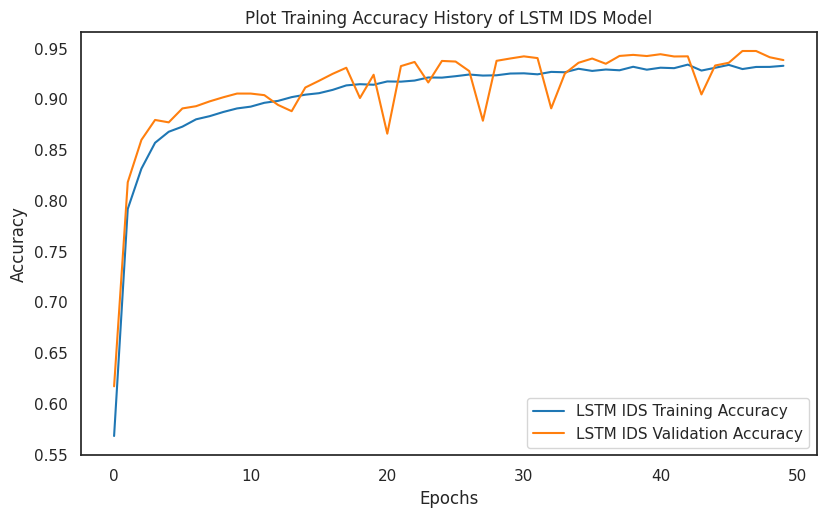

In [24]:
fig, ax = plt.subplots(1, figsize=(9.5,5.5))
plt.plot(range(EPOCHS), lstm_history.history['accuracy'], color=color_pal[0], label='LSTM IDS Training Accuracy')
plt.plot(range(EPOCHS), lstm_history.history['val_accuracy'], color=color_pal[1], label='LSTM IDS Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title("Plot Training Accuracy History of LSTM IDS Model")
plt.legend()
plt.show()

#### Plot Long Short-Term Memory (LSTM) IDS Training & Validation Loss History

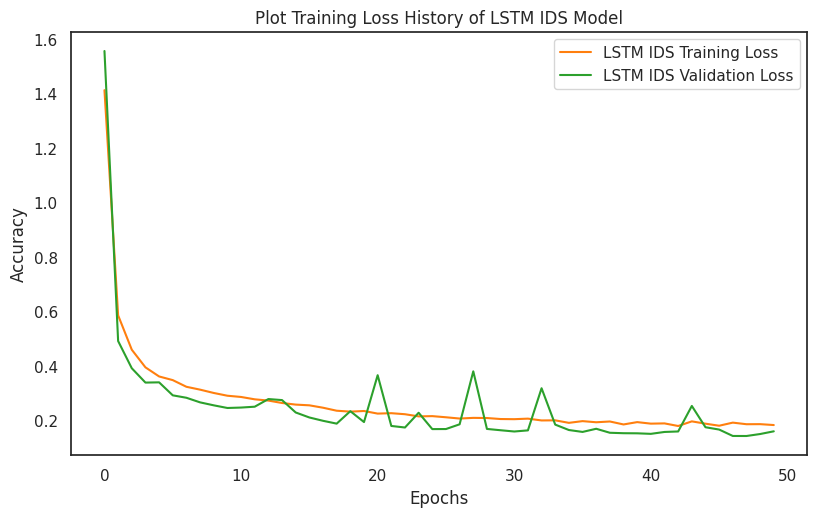

In [25]:
fig, ax = plt.subplots(1, figsize=(9.5,5.5))
plt.plot(range(EPOCHS), lstm_history.history['loss'], color=color_pal[1], label='LSTM IDS Training Loss')
plt.plot(range(EPOCHS), lstm_history.history['val_loss'], color=color_pal[2], label='LSTM IDS Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title("Plot Training Loss History of LSTM IDS Model")
plt.legend()
plt.show()

#### Load Best Variant of LSTM IDS Model

In [23]:
with gpu_strategy.scope():
    loaded_lstm_model = load_model('/kaggle/working/lstm_model_best_v1.keras')
    loaded_lstm_model.summary()

Model: "LSTM_IDS"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 4, 15)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 4, 60)          │        18,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 4, 60)          │           240 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 75)             │        40,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 75)             │           300 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 34)             │         2,584 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 185,954 (726.39 KB)

 Trainable params: 61,894 (241.77 KB)

 Non-trainable params: 270 (1.05 KB)

 Optimizer params: 123,790 (483.56 KB)

#### Evaluate Best Variant of LSTM IDS Model

In [27]:
loaded_lstm_train_metric = loaded_lstm_model.evaluate(reshaped_X_train.astype('float32'), reshaped_y_train.astype('float32'), return_dict=True, batch_size=4096 * gpu_strategy.num_replicas_in_sync)
loaded_lstm_test_metric = loaded_lstm_model.evaluate(reshaped_X_test.astype('float32'), reshaped_y_test.astype('float32'), return_dict=True, batch_size=4096 * gpu_strategy.num_replicas_in_sync)
print(f'Accuracy during training: {round(loaded_lstm_train_metric["accuracy"]*100, 2)}% and loss: {round(loaded_lstm_train_metric["loss"], 4)}')
print(f'Accuracy during test: {round(loaded_lstm_test_metric["accuracy"]*100, 2)}% and loss: {round(loaded_lstm_test_metric["loss"], 4)}')

855/855 ━━━━━━━━━━━━━━━━━━━━ 13s 14ms/step - accuracy: 0.9471 - loss: 0.1437
367/367 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.9471 - loss: 0.1439
Accuracy during training: 94.71% and loss: 0.1437
Accuracy during test: 94.71% and loss: 0.1439


#### Save Histrory Data, Training and Validaiton Metrics for Best LSTM IDS Model

In [38]:
# 1. Initialize the master data structure file
registry = ModelRegistry()

registry.add_model_metrics(
    model_name="LSTM_IDS",
    history_object=lstm_history,
    train_eval=loaded_lstm_train_metric,
    test_eval=loaded_lstm_test_metric
)

# 2. Save everything into the single file
registry.save_to_disk()

# Inside your visualization notebook or function:
with open("/kaggle/working/all_network_models_report.json", "r") as f:
    metrics_data = json.load(f)

print(f'LSTM IDS Accuracy during training: {round(metrics_data["LSTM_IDS"]['final_evaluation']['train_accuracy']*100, 2)}%')
print(f'LSTM IDS Accuracy during training: {round(metrics_data["LSTM_IDS"]['final_evaluation']['test_accuracy']*100, 2)}%')

Successfully added 'LSTM_IDS' metrics to registry container.
Master benchmark dataset written to: /kaggle/working/all_network_models_report.json


#### Check encoding_mappings is null else load pkl file

In [38]:
# Define the expected path to your mappings file
mapping_file_path = '/kaggle/working/ids_encoded_15_mappings.pkl'

# Check if 'encoding_mappings' is not in the local/global scope or if it is None
if 'encoding_mappings' not in locals() and 'encoding_mappings' not in globals() or encoding_mappings is None:
    print(f"'encoding_mappings' is missing. Attempting to load from disk...")
    
    if os.path.exists(mapping_file_path):
        encoding_mappings = joblib.load(mapping_file_path)
        print("Successfully loaded 'encoding_mappings' from storage.")
    else:
        raise FileNotFoundError(f"Critical Error: Mapping file not found at {mapping_file_path}. Cannot resolve class names.")
else:
    print("'encoding_mappings' is already initialized in memory. Skipping file read.")

'encoding_mappings' is already initialized in memory. Skipping file read.


#### Evaluate Best LSTM Using Confusion Matrix & Plot Confusion Matrix on HeatMap

184/184 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step


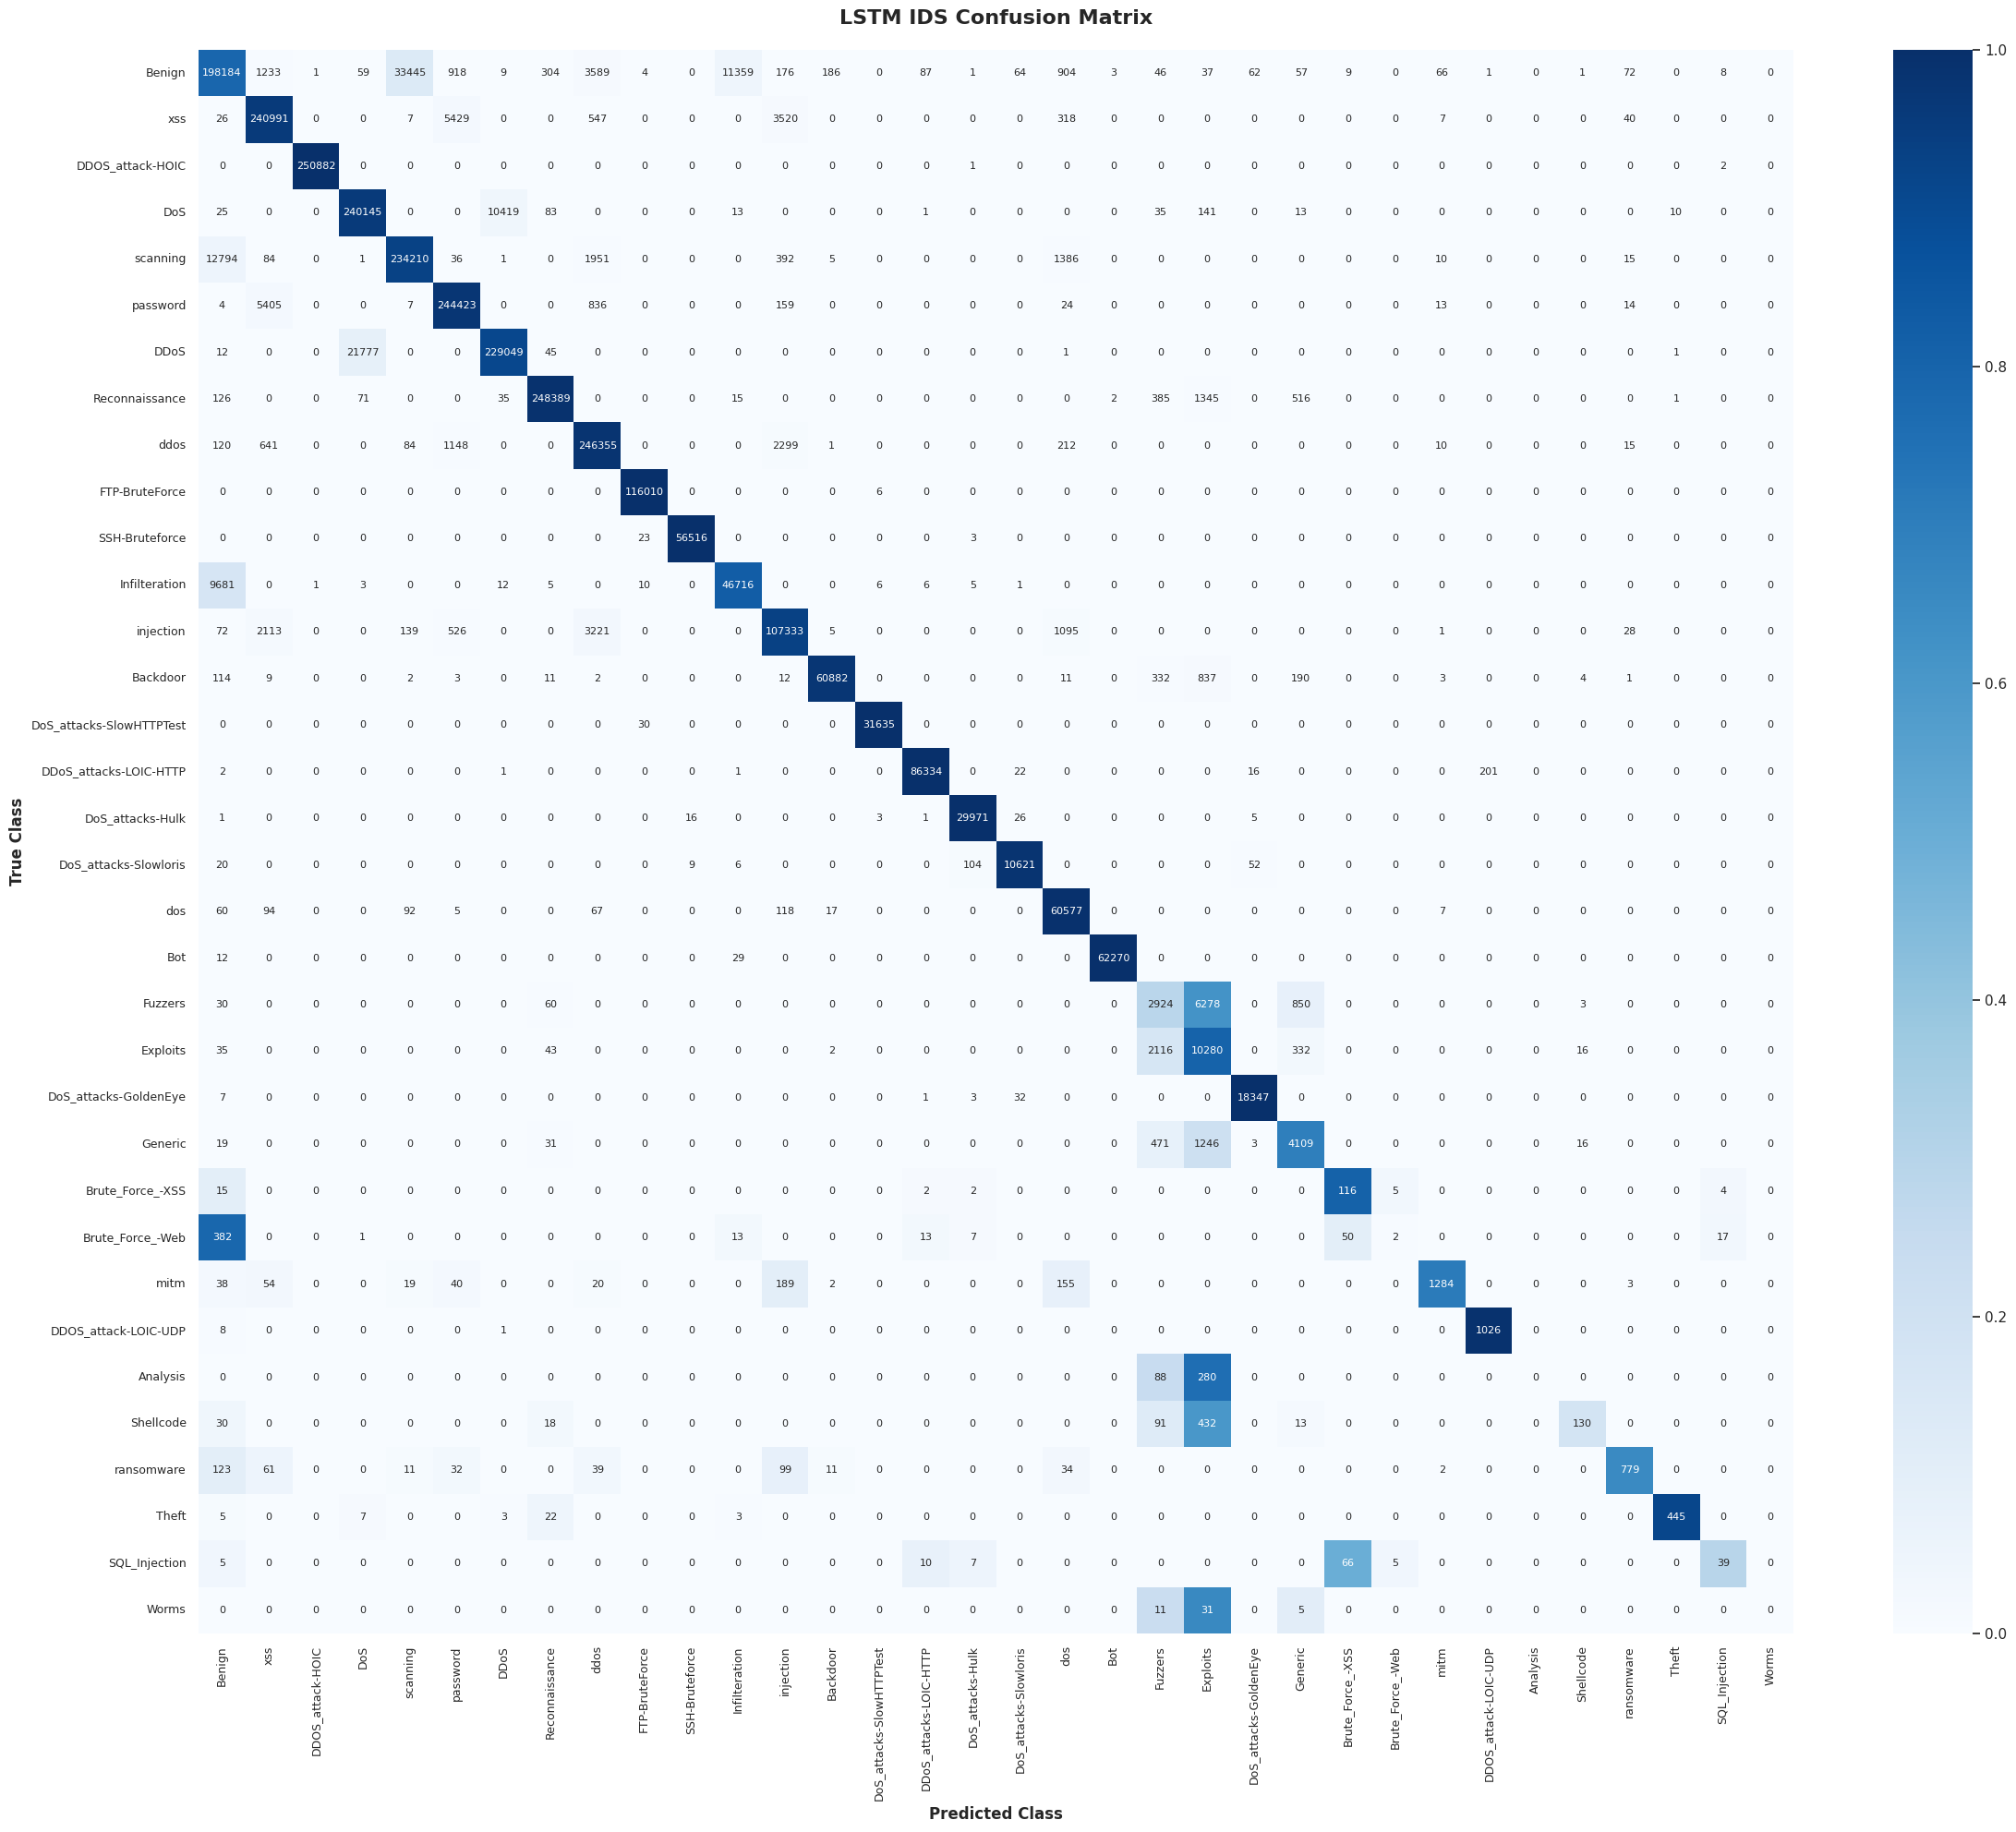

LSTM IDS F1-score:  94.7%
LSTM IDS Recall:    94.7%
LSTM IDS Precision: 94.7%
LSTM IDS AUC-ROC:   99.96%

Classification Report:


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


                         precision   recall f1-score  support
Benign                      89.29%   78.99%   83.83%   250885
xss                         96.13%   96.06%   96.09%   250885
DDOS_attack-HOIC           100.00%  100.00%  100.00%   250885
DoS                         91.64%   95.72%   93.63%   250885
scanning                    87.39%   93.35%   90.27%   250885
password                    96.78%   97.42%   97.10%   250885
DDoS                        95.62%   91.30%   93.41%   250885
Reconnaissance              99.75%   99.01%   99.38%   250885
ddos                        96.00%   98.19%   97.08%   250885
FTP-BruteForce              99.94%   99.99%   99.97%   116016
SSH-Bruteforce              99.96%   99.95%   99.95%    56542
Infilteration               80.33%   82.76%   81.53%    56446
injection                   93.91%   93.71%   93.81%   114533
Backdoor                    99.63%   97.55%   98.58%    62413
DoS_attacks-SlowHTTPTest    99.95%   99.91%   99.93%    31665
DDoS_att

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [34]:
# Ensure GPU is used for prediction
with tf.device('/GPU:0'):
    lstm_y_pred_prob = loaded_lstm_model.predict(reshaped_X_test, batch_size=8192 * gpu_strategy.num_replicas_in_sync)
    lstm_y_pred = np.argmax(lstm_y_pred_prob, axis=1)

# True labels
lstm_y_true = np.argmax(reshaped_y_test, axis=1)

# ---------------------------------------------------------
# 1. HEATMAP CONFUSION MATRIX (NORMALIZED COLORS, RAW TEXT)
# ---------------------------------------------------------
# Extract the exact ordered class names from your pipeline's mapping
class_names = encoding_mappings['Attack'] 

# Calculate absolute counts (for the text inside the boxes)
raw_conf_matrix = confusion_matrix(lstm_y_true, lstm_y_pred)

# Calculate normalized counts by row (for the background colors)
# This calculates the Recall for each class (how many actual instances were predicted correctly)
norm_conf_matrix = confusion_matrix(lstm_y_true, lstm_y_pred, normalize='true')

# Plotting the Heatmap
plt.figure(figsize=(24, 20)) 
sns.heatmap(
    norm_conf_matrix,           # <-- Drives the colors (values are between 0.0 and 1.0)
    annot=raw_conf_matrix,      # <-- Prints the absolute figures inside the squares
    annot_kws={"size": 8},      
    cmap='Blues', 
    fmt='g',                    # Ensures the raw numbers print cleanly (no scientific notation)
    xticklabels=class_names, 
    yticklabels=class_names,
    vmin=0.0,                   # Locks the color bar base at 0%
    vmax=1.0                    # Locks the color bar ceiling at 100%
)

plt.title('LSTM IDS Confusion Matrix', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('True Class', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Class', fontsize=12, fontweight='bold')
plt.xticks(rotation=90, fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 2. OVERALL METRICS
# ---------------------------------------------------------
lstm_attention_f1 = round(f1_score(lstm_y_true, lstm_y_pred, average="micro") * 100, 2)
lstm_attention_recall = round(recall_score(lstm_y_true, lstm_y_pred, average="micro") * 100, 2)
lstm_attention_precision = round(precision_score(lstm_y_true, lstm_y_pred, average="micro") * 100, 2)
lstm_attention_auc = round(roc_auc_score(lstm_y_true, lstm_y_pred_prob, multi_class='ovr', average="micro") * 100, 2)

print(f"LSTM IDS F1-score:  {lstm_attention_f1}%")
print(f"LSTM IDS Recall:    {lstm_attention_recall}%")
print(f"LSTM IDS Precision: {lstm_attention_precision}%")
print(f"LSTM IDS AUC-ROC:   {lstm_attention_auc}%\n")

# ---------------------------------------------------------
# 3. PERCENTAGE-BASED CLASSIFICATION REPORT WITH NAMES
# ---------------------------------------------------------
print("Classification Report:")

# Get the report as a dictionary instead of a raw string
report_dict = classification_report(lstm_y_true, lstm_y_pred, target_names=class_names, output_dict=True)

# Convert to Pandas DataFrame for easy manipulation
report_df = pd.DataFrame(report_dict).transpose()

# Clean up the 'accuracy' row to mimic standard sklearn visual structure
total_support = int(report_df.loc['macro avg', 'support'])
report_df.loc['accuracy', 'support'] = total_support
report_df.loc['accuracy', 'precision'] = np.nan
report_df.loc['accuracy', 'recall'] = np.nan

# Format decimals to percentages with '%' appended
metrics_cols = ['precision', 'recall', 'f1-score']
for col in metrics_cols:
    report_df[col] = report_df[col].apply(lambda x: f"{x * 100:.2f}%" if pd.notnull(x) else "")

# Ensure support remains a clean integer
report_df['support'] = report_df['support'].astype(int)

# Print the beautifully formatted DataFrame
print(report_df.to_string())

#### Build Bidirectional Long Short-Term Memory (Bi-LSTM) IDS Model

In [16]:
bi_lstm_model = Build_BiLSTM(gpu_strategy)
bi_lstm_model_checkpoint_callback = ModelCheckpoint(
    'bi_lstm_model_best_v1.keras', monitor='val_loss', mode='min', verbose=1, 
    save_best_only=True
    )

Model: "BiLSTM_IDS"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━┓
┃ Layer (type)              ┃ Output Shape        ┃   Param # ┃ Tra… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━┩
│ input_layer (InputLayer)  │ (None, 4, 15)       │         0 │  -   │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ bidirectional             │ (None, 4, 120)      │    36,480 │  Y   │
│ (Bidirectional)           │                     │           │      │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ batch_normalization       │ (None, 4, 120)      │       480 │  Y   │
│ (BatchNormalization)      │                     │           │      │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ bidirectional_1           │ (None, 150)         │   117,600 │  Y   │
│ (Bidirectional)           │                     │           │      │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ batch_normalization_1     │ (None, 150)         │       600 │  Y   │
│ (BatchNormalization)      │                     │           │      │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ dense (Dense)             │ (None, 34)          │     5,134 │  Y   │
└───────────────────────────┴─────────────────────┴───────────┴──────┘

 Total params: 160,294 (626.15 KB)

 Trainable params: 159,754 (624.04 KB)

 Non-trainable params: 540 (2.11 KB)

## Train Bidirectional Long Short-Term Memory (Bi-LSTM) IDS Model

In [17]:
bi_lstm_history = bi_lstm_model.fit(reshaped_X_train.astype('float32'), reshaped_y_train.astype('float32'), 
                                epochs = EPOCHS, 
                                validation_data=(reshaped_X_test.astype('float32'), reshaped_y_test.astype('float32')), 
                                shuffle=True, 
                                verbose=1,
                                callbacks=[bi_lstm_model_checkpoint_callback],
                                batch_size=8192 * gpu_strategy.num_replicas_in_sync) 

INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Redu

I0000 00:00:1781379892.400331     151 cuda_dnn.cc:529] Loaded cuDNN version 91002
I0000 00:00:1781379893.251814     153 cuda_dnn.cc:529] Loaded cuDNN version 91002


427/428 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step - accuracy: 0.5143 - loss: 1.8449INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).

Epoch 1: val_loss improved from None to 1.54137, saving model to bi_lstm_model_best_v1.keras

Epoch 1: finished saving model to bi_lstm_model_best_v1.keras
428/428 ━━━━━━━━━━━━━━━━━━━━ 71s 142ms/step - accuracy: 0.6580 - loss: 1.1380 - val_accuracy: 0.4897 - val_loss: 1.5414
Epoch 2/50
427/428 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step - accuracy: 0.8094 - loss: 0.5102
Epoch 2: val_loss improved from 1.54137 to 0.36485, saving model to bi_lstm_model_best_v1.keras

Epoch 2: finished saving model to bi_lstm_model_best_v1.keras
428/428 ━━━━━━━━━━━━━━━━━━━━ 60s 138ms/step - accuracy: 0.8267 - loss: 0.4651 - val_accuracy: 0.8699 - val_loss: 0.3648


#### Plot Training History of BiLSTM IDS Model

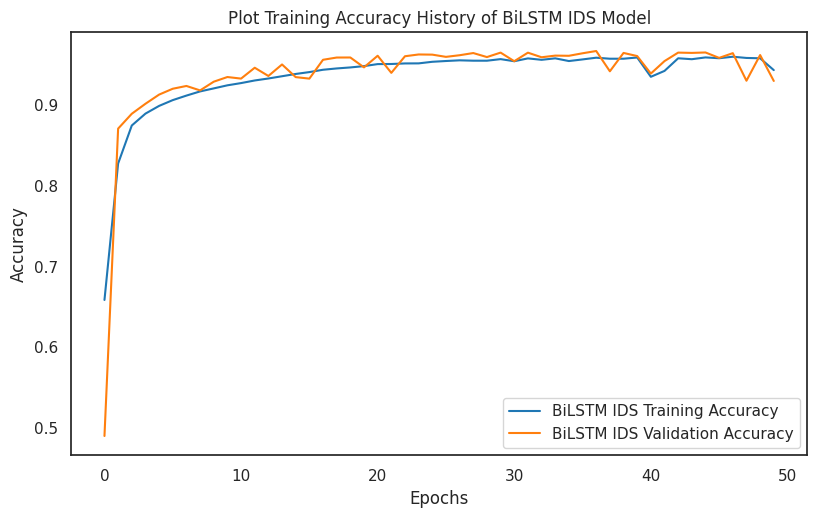

In [18]:
fig, ax = plt.subplots(1, figsize=(9.5,5.5))
plt.plot(range(EPOCHS), bi_lstm_history.history['accuracy'], color=color_pal[0], label='BiLSTM IDS Training Accuracy')
plt.plot(range(EPOCHS), bi_lstm_history.history['val_accuracy'], color=color_pal[1], label='BiLSTM IDS Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title("Plot Training Accuracy History of BiLSTM IDS Model")
plt.legend() 
plt.show()

#### Plot Loss History of BiLSTM IDS Model

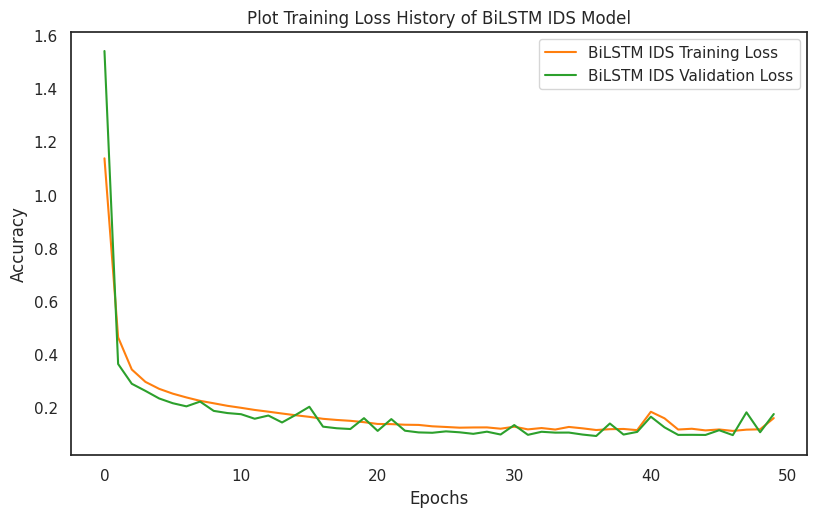

In [19]:
fig, ax = plt.subplots(1, figsize=(9.5,5.5))
plt.plot(range(EPOCHS), bi_lstm_history.history['loss'], color=color_pal[1], label='BiLSTM IDS Training Loss')
plt.plot(range(EPOCHS), bi_lstm_history.history['val_loss'], color=color_pal[2], label='BiLSTM IDS Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title("Plot Training Loss History of BiLSTM IDS Model")
plt.legend()
plt.show()

#### Load Best Trained Variant of BiLSTM IDS Model 

In [37]:
with gpu_strategy.scope():
    loaded_bilstm_model = load_model('/kaggle/working/bi_lstm_model_best_v1.keras')
    loaded_bilstm_model.summary()

Model: "BiLSTM_IDS"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 4, 15)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 4, 120)         │        36,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 4, 120)         │           480 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 150)            │       117,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 150)            │           600 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 34)             │         5,134 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 479,804 (1.83 MB)

 Trainable params: 159,754 (624.04 KB)

 Non-trainable params: 540 (2.11 KB)

 Optimizer params: 319,510 (1.22 MB)

#### Evaluate Best Trained Variant of BiLSTM IDS Model 

In [21]:
loaded_bilstm_train_metric = loaded_bilstm_model.evaluate(reshaped_X_train.astype('float32'), reshaped_y_train.astype('float32'), return_dict=True, batch_size=4096 * gpu_strategy.num_replicas_in_sync)
loaded_bilstm_test_metric = loaded_bilstm_model.evaluate(reshaped_X_test.astype('float32'), reshaped_y_test.astype('float32'), return_dict=True, batch_size=4096 * gpu_strategy.num_replicas_in_sync)
print(f'Accuracy during training: {round(loaded_bilstm_train_metric["accuracy"]*100, 2)}% and loss: {round(loaded_bilstm_train_metric["loss"], 4)}')
print(f'Accuracy during test: {round(loaded_bilstm_test_metric["accuracy"]*100, 2)}% and loss: {round(loaded_bilstm_test_metric["loss"], 4)}')

855/855 ━━━━━━━━━━━━━━━━━━━━ 18s 20ms/step - accuracy: 0.9657 - loss: 0.0940
367/367 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.9658 - loss: 0.0942
Accuracy during training: 96.57% and loss: 0.094
Accuracy during test: 96.58% and loss: 0.0942


#### Save and Load the BiLSTM IDS metrics

In [22]:
# 1. Initialize the master data structure file
registry = ModelRegistry()

registry.add_model_metrics(
    model_name="BiLSTM_IDS",
    history_object=bi_lstm_history,
    train_eval=loaded_bilstm_train_metric,
    test_eval=loaded_bilstm_test_metric
)

# 2. Save everything into the single file
registry.save_to_disk()

# Inside your visualization notebook or function:
with open("/kaggle/working/all_network_models_report.json", "r") as f:
    metrics_data = json.load(f)

# Test performance parameters of TGAT IDS are saved properly
print(f'BiLSTM IDS Accuracy during training: {round(metrics_data["BiLSTM_IDS"]['final_evaluation']['train_accuracy']*100, 2)}%')
print(f'BiLSTM IDS Accuracy during training: {round(metrics_data["BiLSTM_IDS"]['final_evaluation']['test_accuracy']*100, 2)}%')

Successfully added 'BiLSTM_IDS' metrics to registry container.
Master benchmark dataset written to: /kaggle/working/all_network_models_report.json
BiLSTM IDS Accuracy during training: 96.57%
BiLSTM IDS Accuracy during training: 96.58%


#### Evaluate Best BiLSTM Using Confusion Matrix & Plot Confusion Matrix on HeatMap

184/184 ━━━━━━━━━━━━━━━━━━━━ 10s 48ms/step


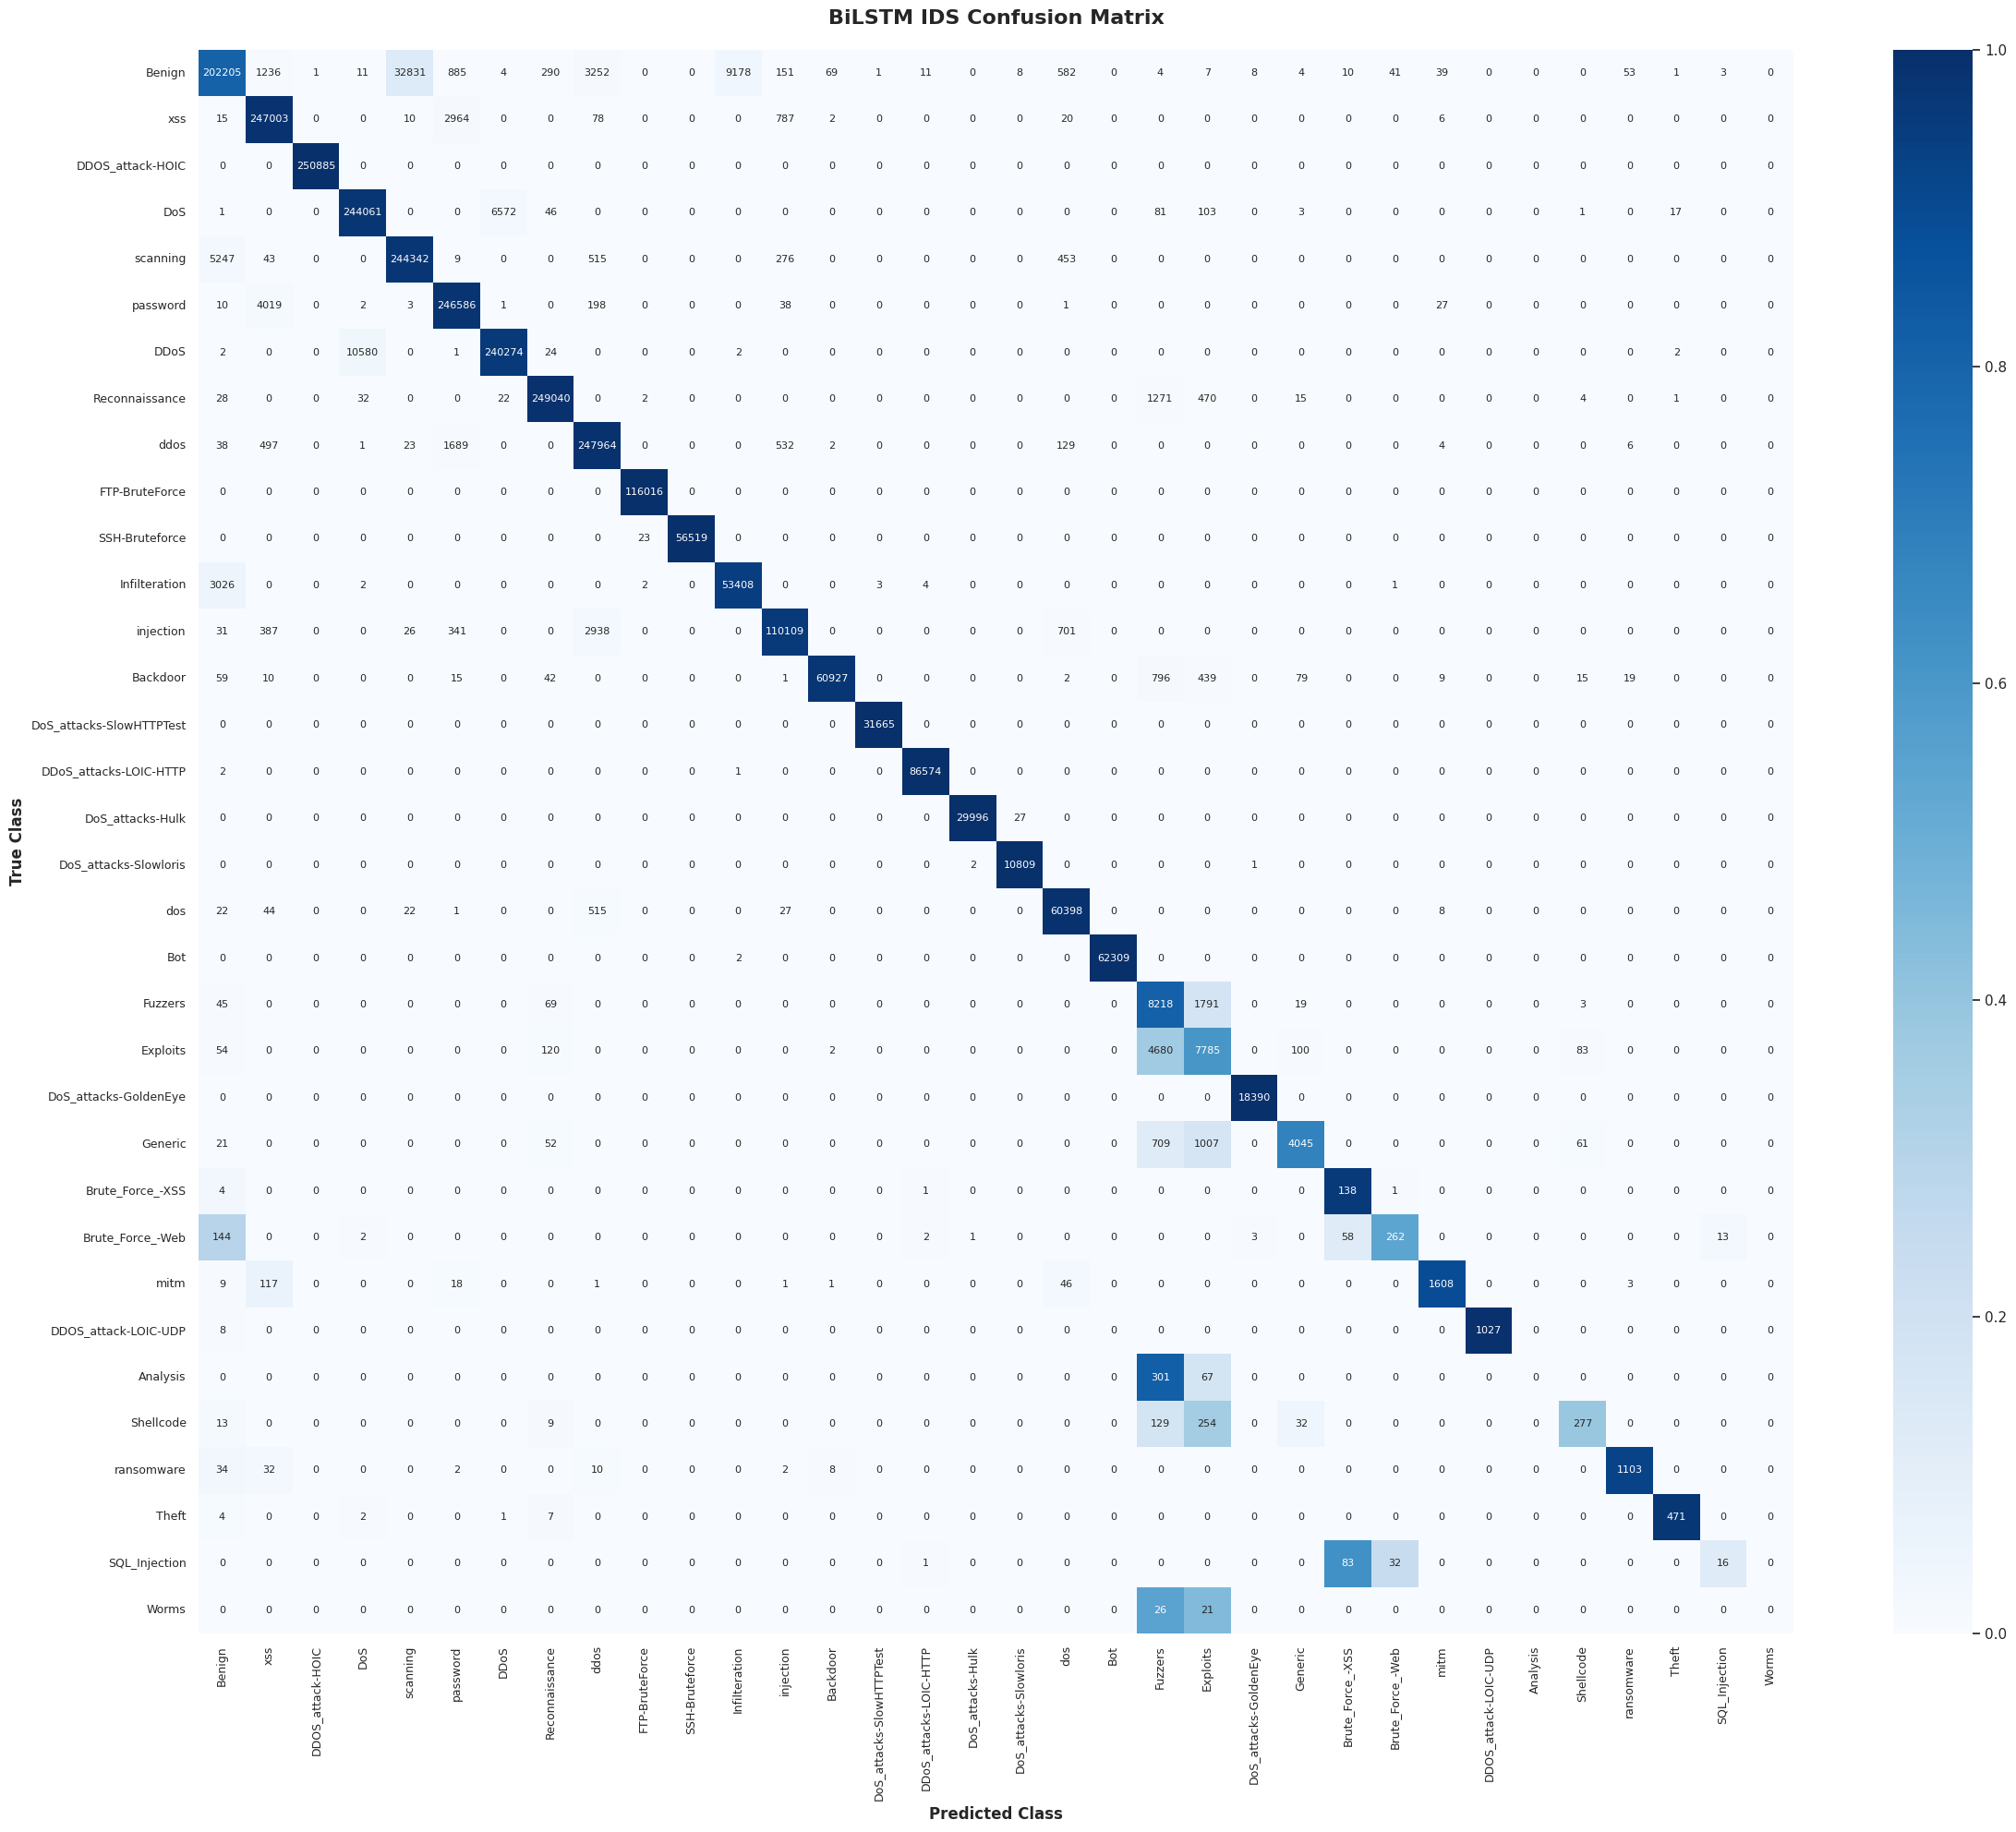

BiLSTM IDS F1-score:  96.48%
BiLSTM IDS Recall:    96.48%
BiLSTM IDS Precision: 96.48%
BiLSTM IDS AUC-ROC:   99.98%

Classification Report:


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


                         precision   recall f1-score  support
Benign                      95.82%   80.60%   87.55%   250885
xss                         97.48%   98.45%   97.96%   250885
DDOS_attack-HOIC           100.00%  100.00%  100.00%   250885
DoS                         95.83%   97.28%   96.55%   250885
scanning                    88.13%   97.39%   92.53%   250885
password                    97.65%   98.29%   97.97%   250885
DDoS                        97.33%   95.77%   96.54%   250885
Reconnaissance              99.74%   99.26%   99.50%   250885
ddos                        97.06%   98.84%   97.94%   250885
FTP-BruteForce              99.98%  100.00%   99.99%   116016
SSH-Bruteforce             100.00%   99.96%   99.98%    56542
Infilteration               85.33%   94.62%   89.73%    56446
injection                   98.38%   96.14%   97.24%   114533
Backdoor                    99.86%   97.62%   98.73%    62413
DoS_attacks-SlowHTTPTest    99.99%  100.00%   99.99%    31665
DDoS_att

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [39]:
# Ensure GPU is used for prediction
with tf.device('/GPU:0'):
    bi_lstm_y_pred_prob = loaded_bilstm_model.predict(reshaped_X_test, batch_size=8192 * gpu_strategy.num_replicas_in_sync)
    bi_lstm_y_pred = np.argmax(bi_lstm_y_pred_prob, axis=1)

# True labels
bi_lstm_y_true = np.argmax(reshaped_y_test, axis=1)

# ---------------------------------------------------------
# 1. HEATMAP CONFUSION MATRIX (NORMALIZED COLORS, RAW TEXT)
# ---------------------------------------------------------
# Extract the exact ordered class names from your pipeline's mapping
class_names = encoding_mappings['Attack'] 

# Calculate absolute counts (for the text inside the boxes)
raw_conf_matrix = confusion_matrix(bi_lstm_y_true, bi_lstm_y_pred)

# Calculate normalized counts by row (for the background colors)
# This calculates the Recall for each class (how many actual instances were predicted correctly)
norm_conf_matrix = confusion_matrix(bi_lstm_y_true, bi_lstm_y_pred, normalize='true')

# Plotting the Heatmap
plt.figure(figsize=(24, 20)) 
sns.heatmap(
    norm_conf_matrix,           # <-- Drives the colors (values are between 0.0 and 1.0)
    annot=raw_conf_matrix,      # <-- Prints the absolute figures inside the squares
    annot_kws={"size": 8},      
    cmap='Blues', 
    fmt='g',                    # Ensures the raw numbers print cleanly (no scientific notation)
    xticklabels=class_names, 
    yticklabels=class_names,
    vmin=0.0,                   # Locks the color bar base at 0%
    vmax=1.0                    # Locks the color bar ceiling at 100%
)

plt.title('BiLSTM IDS Confusion Matrix', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('True Class', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Class', fontsize=12, fontweight='bold')
plt.xticks(rotation=90, fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 2. OVERALL METRICS
# ---------------------------------------------------------
bi_lstm_attention_f1 = round(f1_score(bi_lstm_y_true, bi_lstm_y_pred, average="micro") * 100, 2)
bi_lstm_attention_recall = round(recall_score(bi_lstm_y_true, bi_lstm_y_pred, average="micro") * 100, 2)
bi_lstm_attention_precision = round(precision_score(bi_lstm_y_true, bi_lstm_y_pred, average="micro") * 100, 2)
bi_lstm_attention_auc = round(roc_auc_score(bi_lstm_y_true, bi_lstm_y_pred_prob, multi_class='ovr', average="micro") * 100, 2)

print(f"BiLSTM IDS F1-score:  {bi_lstm_attention_f1}%")
print(f"BiLSTM IDS Recall:    {bi_lstm_attention_recall}%")
print(f"BiLSTM IDS Precision: {bi_lstm_attention_precision}%")
print(f"BiLSTM IDS AUC-ROC:   {bi_lstm_attention_auc}%\n")

# ---------------------------------------------------------
# 3. PERCENTAGE-BASED CLASSIFICATION REPORT WITH NAMES
# ---------------------------------------------------------
print("Classification Report:")

# Get the report as a dictionary instead of a raw string
report_dict = classification_report(bi_lstm_y_true, bi_lstm_y_pred, target_names=class_names, output_dict=True)

# Convert to Pandas DataFrame for easy manipulation
report_df = pd.DataFrame(report_dict).transpose()

# Clean up the 'accuracy' row to mimic standard sklearn visual structure
total_support = int(report_df.loc['macro avg', 'support'])
report_df.loc['accuracy', 'support'] = total_support
report_df.loc['accuracy', 'precision'] = np.nan
report_df.loc['accuracy', 'recall'] = np.nan

# Format decimals to percentages with '%' appended
metrics_cols = ['precision', 'recall', 'f1-score']
for col in metrics_cols:
    report_df[col] = report_df[col].apply(lambda x: f"{x * 100:.2f}%" if pd.notnull(x) else "")

# Ensure support remains a clean integer
report_df['support'] = report_df['support'].astype(int)

# Print the beautifully formatted DataFrame
print(report_df.to_string())

## Build Gated Recurrent Unit (GRU) IDS Model

In [25]:
gru_model = Build_GRU(gpu_strategy)
gru_model_checkpoint_callback = ModelCheckpoint(
    'gru_model_best_v1.keras', monitor='val_loss', mode='min', verbose=1, 
    save_best_only=True
    )

Model: "GRU_IDS"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━┓
┃ Layer (type)              ┃ Output Shape        ┃   Param # ┃ Tra… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━┩
│ input_layer_1             │ (None, 4, 15)       │         0 │  -   │
│ (InputLayer)              │                     │           │      │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ gru_2 (GRU)               │ (None, 4, 60)       │    13,860 │  Y   │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ batch_normalization_2     │ (None, 4, 60)       │       240 │  Y   │
│ (BatchNormalization)      │                     │           │      │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ gru_3 (GRU)               │ (None, 75)          │    30,825 │  Y   │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ batch_normalization_3     │ (None, 75)          │       300 │  Y   │
│ (BatchNormalization)      │                     │           │      │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ dense_1 (Dense)           │ (None, 34)          │     2,584 │  Y   │
└───────────────────────────┴─────────────────────┴───────────┴──────┘

 Total params: 47,809 (186.75 KB)

 Trainable params: 47,539 (185.70 KB)

 Non-trainable params: 270 (1.05 KB)

In [ ]:
Selected Best Trial (Trial #121):
  Validation Loss: 0.0329
Optimized Hyperparameters:
Optimized Hyperparameters:
    - units_1: 60
    - units_2: 90
    - activation_1: tanh
    - activation_2: tanh
    - dropout_1: 0.000391459803891457
    - dropout_2: 0.023030056576652806
    - lr: 0.004700132582897673
    - loss: categorical_focal_crossentropy

In [35]:
def Build_GRU_2(strategy):
    with strategy.scope():
        
        # Define Input
        inputs = Input(shape=(time_steps, num_features))
        
        # BiLSTM Layers
        x = GRU(num_features*4, activation='tanh', dropout=0.000391459803891457, return_sequences=True)(inputs)
        x = LayerNormalization()(x)
        x = GRU(num_features*6, activation='tanh', dropout=0.023030056576652806)(x)
        x = LayerNormalization()(x)
        
        outputs = Dense(num_classes, activation='softmax')(x)  # Output Layer

        model = Model(inputs=inputs, outputs=outputs, name='GRU_IDS') 
        model.compile(loss='categorical_focal_crossentropy', optimizer=Adam(learning_rate=0.004700132582897673), metrics=['accuracy'])
        model.summary(line_length=70, show_trainable=True)
        return model

In [36]:
gru_model_2 = Build_GRU_2(gpu_strategy)
gru_model_checkpoint_callback_2 = ModelCheckpoint(
    'gru_model_best_v2.keras', monitor='val_loss', mode='min', verbose=1, 
    save_best_only=True
    )

Model: "GRU_IDS"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━┓
┃ Layer (type)              ┃ Output Shape        ┃   Param # ┃ Tra… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━┩
│ input_layer (InputLayer)  │ (None, 4, 15)       │         0 │  -   │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ gru (GRU)                 │ (None, 4, 60)       │    13,860 │  Y   │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ layer_normalization       │ (None, 4, 60)       │       120 │  Y   │
│ (LayerNormalization)      │                     │           │      │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ gru_1 (GRU)               │ (None, 90)          │    41,040 │  Y   │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ layer_normalization_1     │ (None, 90)          │       180 │  Y   │
│ (LayerNormalization)      │                     │           │      │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ dense (Dense)             │ (None, 34)          │     3,094 │  Y   │
└───────────────────────────┴─────────────────────┴───────────┴──────┘

 Total params: 58,294 (227.71 KB)

 Trainable params: 58,294 (227.71 KB)

 Non-trainable params: 0 (0.00 B)

In [37]:
gru_history_2 = gru_model_2.fit(reshaped_X_train.astype('float32'), reshaped_y_train.astype('float32'), 
                                epochs = EPOCHS, 
                                validation_data=(reshaped_X_test.astype('float32'), reshaped_y_test.astype('float32')), 
                                shuffle=True, 
                                verbose=1,
                                callbacks=[gru_model_checkpoint_callback_2],
                                batch_size=8192 * gpu_strategy.num_replicas_in_sync) 

INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Redu

I0000 00:00:1782739311.247520     193 cuda_dnn.cc:529] Loaded cuDNN version 91002
I0000 00:00:1782739311.831455     195 cuda_dnn.cc:529] Loaded cuDNN version 91002


427/428 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 0.7009 - loss: 0.1460INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).

Epoch 1: val_loss improved from None to 0.03267, saving model to gru_model_best_v2.keras

Epoch 1: finished saving model to gru_model_best_v2.keras
428/428 ━━━━━━━━━━━━━━━━━━━━ 58s 116ms/step - accuracy: 0.8020 - loss: 0.0723 - val_accuracy: 0.8803 - val_loss: 0.0327
Epoch 2/50
427/428 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - accuracy: 0.8827 - loss: 0.0311
Epoch 2: val_loss improved from 0.03267 to 0.02583, saving model to gru_model_best_v2.keras

Epoch 2: finished saving model to gru_model_best_v2.keras
428/428 ━━━━━━━━━━━━━━━━━━━━ 45s 105ms/step - accuracy: 0.8872 - loss: 0.0294 - val_accuracy: 0.8949 - val_loss: 0.0258
Epoch 3/50
427/428

#### Train Gated Recurrent Unit (GRU) IDS Model

In [ ]:
Selected Best Trial (Trial #98):
  Validation Loss: 0.0362
Optimized Hyperparameters:
Optimized Hyperparameters:
    - units_1: 90
    - units_2: 90
    - activation_1: relu
    - activation_2: relu
    - dropout_1: 0.01844003207676649
    - dropout_2: 0.13951651597981618
    - lr: 0.003624285658433479
    - loss: categorical_focal_crossentropy

In [39]:
def Build_GRU_3(strategy):
    with strategy.scope():
        
        # Define Input
        inputs = Input(shape=(time_steps, num_features))
        
        # BiLSTM Layers
        x = GRU(num_features*6, activation='relu', dropout=0.01844003207676649, return_sequences=True)(inputs)
        x = LayerNormalization()(x)
        x = GRU(num_features*6, activation='relu', dropout=0.13951651597981618)(x)
        x = LayerNormalization()(x)
        
        outputs = Dense(num_classes, activation='softmax')(x)  # Output Layer

        model = Model(inputs=inputs, outputs=outputs, name='GRU_IDS') 
        model.compile(loss='categorical_focal_crossentropy', optimizer=Adam(learning_rate=0.003624285658433479), metrics=['accuracy'])
        model.summary(line_length=70, show_trainable=True)
        return model

In [40]:
gru_model_3 = Build_GRU_3(gpu_strategy)
gru_model_checkpoint_callback_3 = ModelCheckpoint(
    'gru_model_best_v3.keras', monitor='val_loss', mode='min', verbose=1, 
    save_best_only=True
    )

Model: "GRU_IDS"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━┓
┃ Layer (type)              ┃ Output Shape        ┃   Param # ┃ Tra… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━┩
│ input_layer_1             │ (None, 4, 15)       │         0 │  -   │
│ (InputLayer)              │                     │           │      │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ gru_2 (GRU)               │ (None, 4, 90)       │    28,890 │  Y   │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ layer_normalization_2     │ (None, 4, 90)       │       180 │  Y   │
│ (LayerNormalization)      │                     │           │      │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ gru_3 (GRU)               │ (None, 90)          │    49,140 │  Y   │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ layer_normalization_3     │ (None, 90)          │       180 │  Y   │
│ (LayerNormalization)      │                     │           │      │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ dense_1 (Dense)           │ (None, 34)          │     3,094 │  Y   │
└───────────────────────────┴─────────────────────┴───────────┴──────┘

 Total params: 81,484 (318.30 KB)

 Trainable params: 81,484 (318.30 KB)

 Non-trainable params: 0 (0.00 B)

In [41]:
gru_history_3 = gru_model_3.fit(reshaped_X_train.astype('float32'), reshaped_y_train.astype('float32'), 
                                epochs = EPOCHS, 
                                validation_data=(reshaped_X_test.astype('float32'), reshaped_y_test.astype('float32')), 
                                shuffle=True, 
                                verbose=1,
                                callbacks=[gru_model_checkpoint_callback_3],
                                batch_size=8192 * gpu_strategy.num_replicas_in_sync) 

Epoch 1/50
INFO:tensorflow:Collective all_reduce tensors: 12 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
428/428 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.6888 - loss: 0.1544
Epoch 1: val_loss improved from None to 0.03328, saving model to gru_model_best_v3.keras

Epoch 1: finished saving model to gru_model_best_v3.keras
428/428 ━━━━━━━━━━━━━━━━━━━━ 30s 61ms/step - accuracy: 0.7833 - loss: 0.0803 - val_accuracy: 0.8817 - val_loss: 0.0333
Epoch 2/50
428/428 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.8627 - loss: 0.0390
Epoch 2: val_loss improved from 0.03328 to 0.02611, saving model to gru_model_best_v3.keras

Epoch 2: finished saving model to gru_model_best_v3.keras
428/428 ━━━━━━━━━━━━━━━━━━━━ 22s 49ms/step - accuracy: 0.8686 - loss: 0.0368 - val_accuracy: 0.9001 - val_loss: 0.0261
Epoch 3/50
427/428 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.8823 - loss: 0.0319
Epoch 3: val_loss improved from 0.02611 t

In [26]:
gru_history = gru_model.fit(reshaped_X_train.astype('float32'), reshaped_y_train.astype('float32'), 
                                epochs = EPOCHS, 
                                validation_data=(reshaped_X_test.astype('float32'), reshaped_y_test.astype('float32')), 
                                shuffle=True, 
                                verbose=1,
                                callbacks=[gru_model_checkpoint_callback],
                                batch_size=8192 * gpu_strategy.num_replicas_in_sync) 

Epoch 1/50
INFO:tensorflow:Collective all_reduce tensors: 12 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
427/428 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.4516 - loss: 1.9083
Epoch 1: val_loss improved from None to 1.13184, saving model to gru_model_best_v1.keras

Epoch 1: finished saving model to gru_model_best_v1.keras
428/428 ━━━━━━━━━━━━━━━━━━━━ 41s 88ms/step - accuracy: 0.6442 - loss: 1.1315 - val_accuracy: 0.7613 - val_loss: 1.1318
Epoch 2/50
427/428 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.8289 - loss: 0.4682
Epoch 2: val_loss improved from 1.13184 to 0.34172, saving model to gru_model_best_v1.keras

Epoch 2: finished saving model to gru_model_best_v1.keras
428/428 ━━━━━━━━━━━━━━━━━━━━ 32s 75ms/step - accuracy: 0.8468 - loss: 0.4196 - val_accuracy: 0.8784 - val_loss: 0.3417
Epoch 3/50
427/428 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.8758 - loss: 0.3347
Epoch 3: val_loss improved from 0.34172 t

#### Plot Training & Validation History of GRU IDS Model

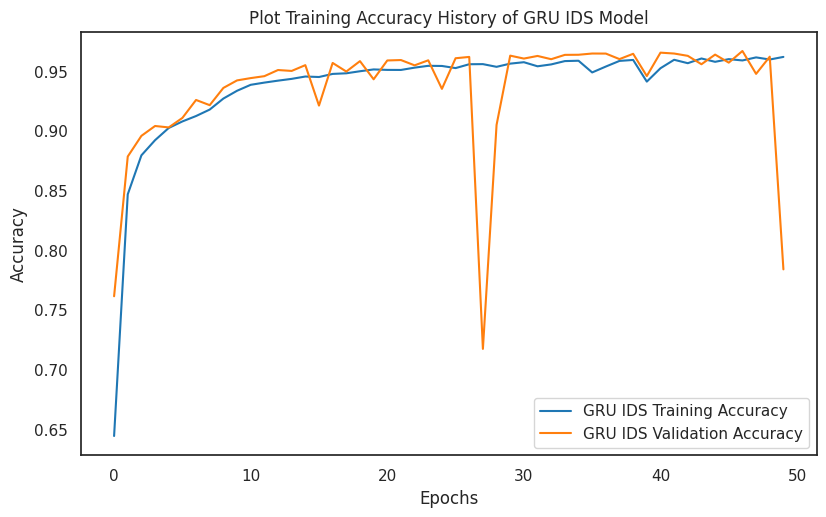

In [27]:
fig, ax = plt.subplots(1, figsize=(9.5,5.5))
plt.plot(range(EPOCHS), gru_history.history['accuracy'], color=color_pal[0], label='GRU IDS Training Accuracy')
plt.plot(range(EPOCHS), gru_history.history['val_accuracy'], color=color_pal[1], label='GRU IDS Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title("Plot Training Accuracy History of GRU IDS Model")
plt.legend()
plt.show()

#### Plot Loss History of GRU IDS Model

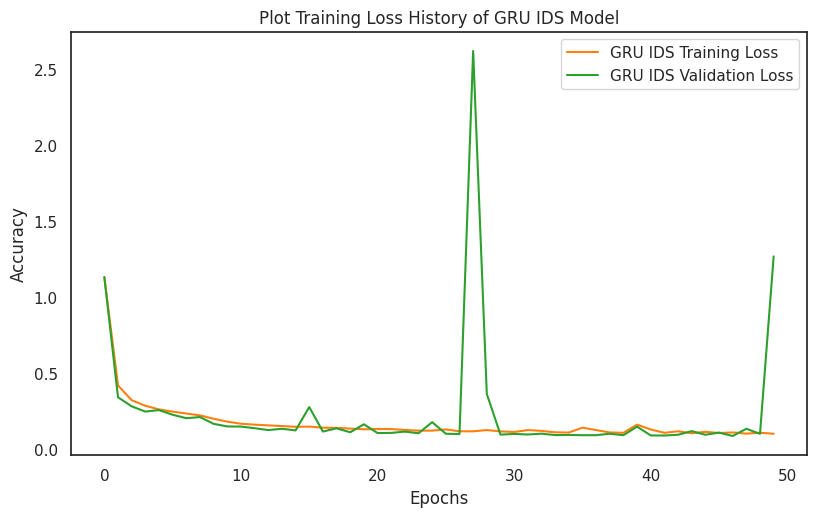

In [28]:
fig, ax = plt.subplots(1, figsize=(9.5,5.5))
plt.plot(range(EPOCHS), gru_history.history['loss'], color=color_pal[1], label='GRU IDS Training Loss')
plt.plot(range(EPOCHS), gru_history.history['val_loss'], color=color_pal[2], label='GRU IDS Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title("Plot Training Loss History of GRU IDS Model")
plt.legend()
plt.show()

#### Load Best Variant of GRU IDS Model

In [42]:
with gpu_strategy.scope():
    loaded_gru_model = load_model('/kaggle/working/gru_model_best_v1.keras')
    loaded_gru_model.summary()

Model: "GRU_IDS"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 4, 15)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_2 (GRU)                     │ (None, 4, 60)          │        13,860 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 4, 60)          │           240 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_3 (GRU)                     │ (None, 75)             │        30,825 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 75)             │           300 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 34)             │         2,584 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 142,889 (558.16 KB)

 Trainable params: 47,539 (185.70 KB)

 Non-trainable params: 270 (1.05 KB)

 Optimizer params: 95,080 (371.41 KB)

#### Evaluate Best Variant of GRU IDS Model

In [30]:
loaded_gru_train_metric = loaded_gru_model.evaluate(reshaped_X_train.astype('float32'), reshaped_y_train.astype('float32'), return_dict=True, batch_size=4096 * gpu_strategy.num_replicas_in_sync)
loaded_gru_test_metric = loaded_gru_model.evaluate(reshaped_X_test.astype('float32'), reshaped_y_test.astype('float32'), return_dict=True, batch_size=4096 * gpu_strategy.num_replicas_in_sync)
print(f'Accuracy during training: {round(loaded_gru_train_metric["accuracy"]*100, 2)}% and loss: {round(loaded_gru_train_metric["loss"], 4)}')
print(f'Accuracy during test: {round(loaded_gru_test_metric["accuracy"]*100, 2)}% and loss: {round(loaded_gru_test_metric["loss"], 4)}')

855/855 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - accuracy: 0.9669 - loss: 0.0871
367/367 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.9669 - loss: 0.0871
Accuracy during training: 96.69% and loss: 0.0871
Accuracy during test: 96.69% and loss: 0.0871


#### Save GRU IDS Model Metrics

In [32]:
# 1. Initialize the master data structure file
registry = ModelRegistry("all_network_models_report.json")

registry.add_model_metrics(
    model_name="GRU_IDS",
    history_object=gru_history,
    train_eval=loaded_gru_train_metric,
    test_eval=loaded_gru_test_metric
)

# 2. Save everything into the single file
registry.save_to_disk()

# Inside your visualization notebook or function:
with open("/kaggle/working/all_network_models_report.json", "r") as f:
    metrics_data = json.load(f)

# Test performance parameters of TGAT IDS are saved properly
print(f'GRU IDS Accuracy during training: {round(metrics_data["GRU_IDS"]['final_evaluation']['train_accuracy']*100, 2)}%')
print(f'GRU IDS Accuracy during training: {round(metrics_data["GRU_IDS"]['final_evaluation']['test_accuracy']*100, 2)}%')

Successfully added 'GRU_IDS' metrics to registry container.
Master benchmark dataset written to: all_network_models_report.json
GRU IDS Accuracy during training: 96.69%
GRU IDS Accuracy during training: 96.69%


#### Evaluate Best GRU Using Confusion Matrix & Plot Confusion Matrix on HeatMap

184/184 ━━━━━━━━━━━━━━━━━━━━ 6s 28ms/step


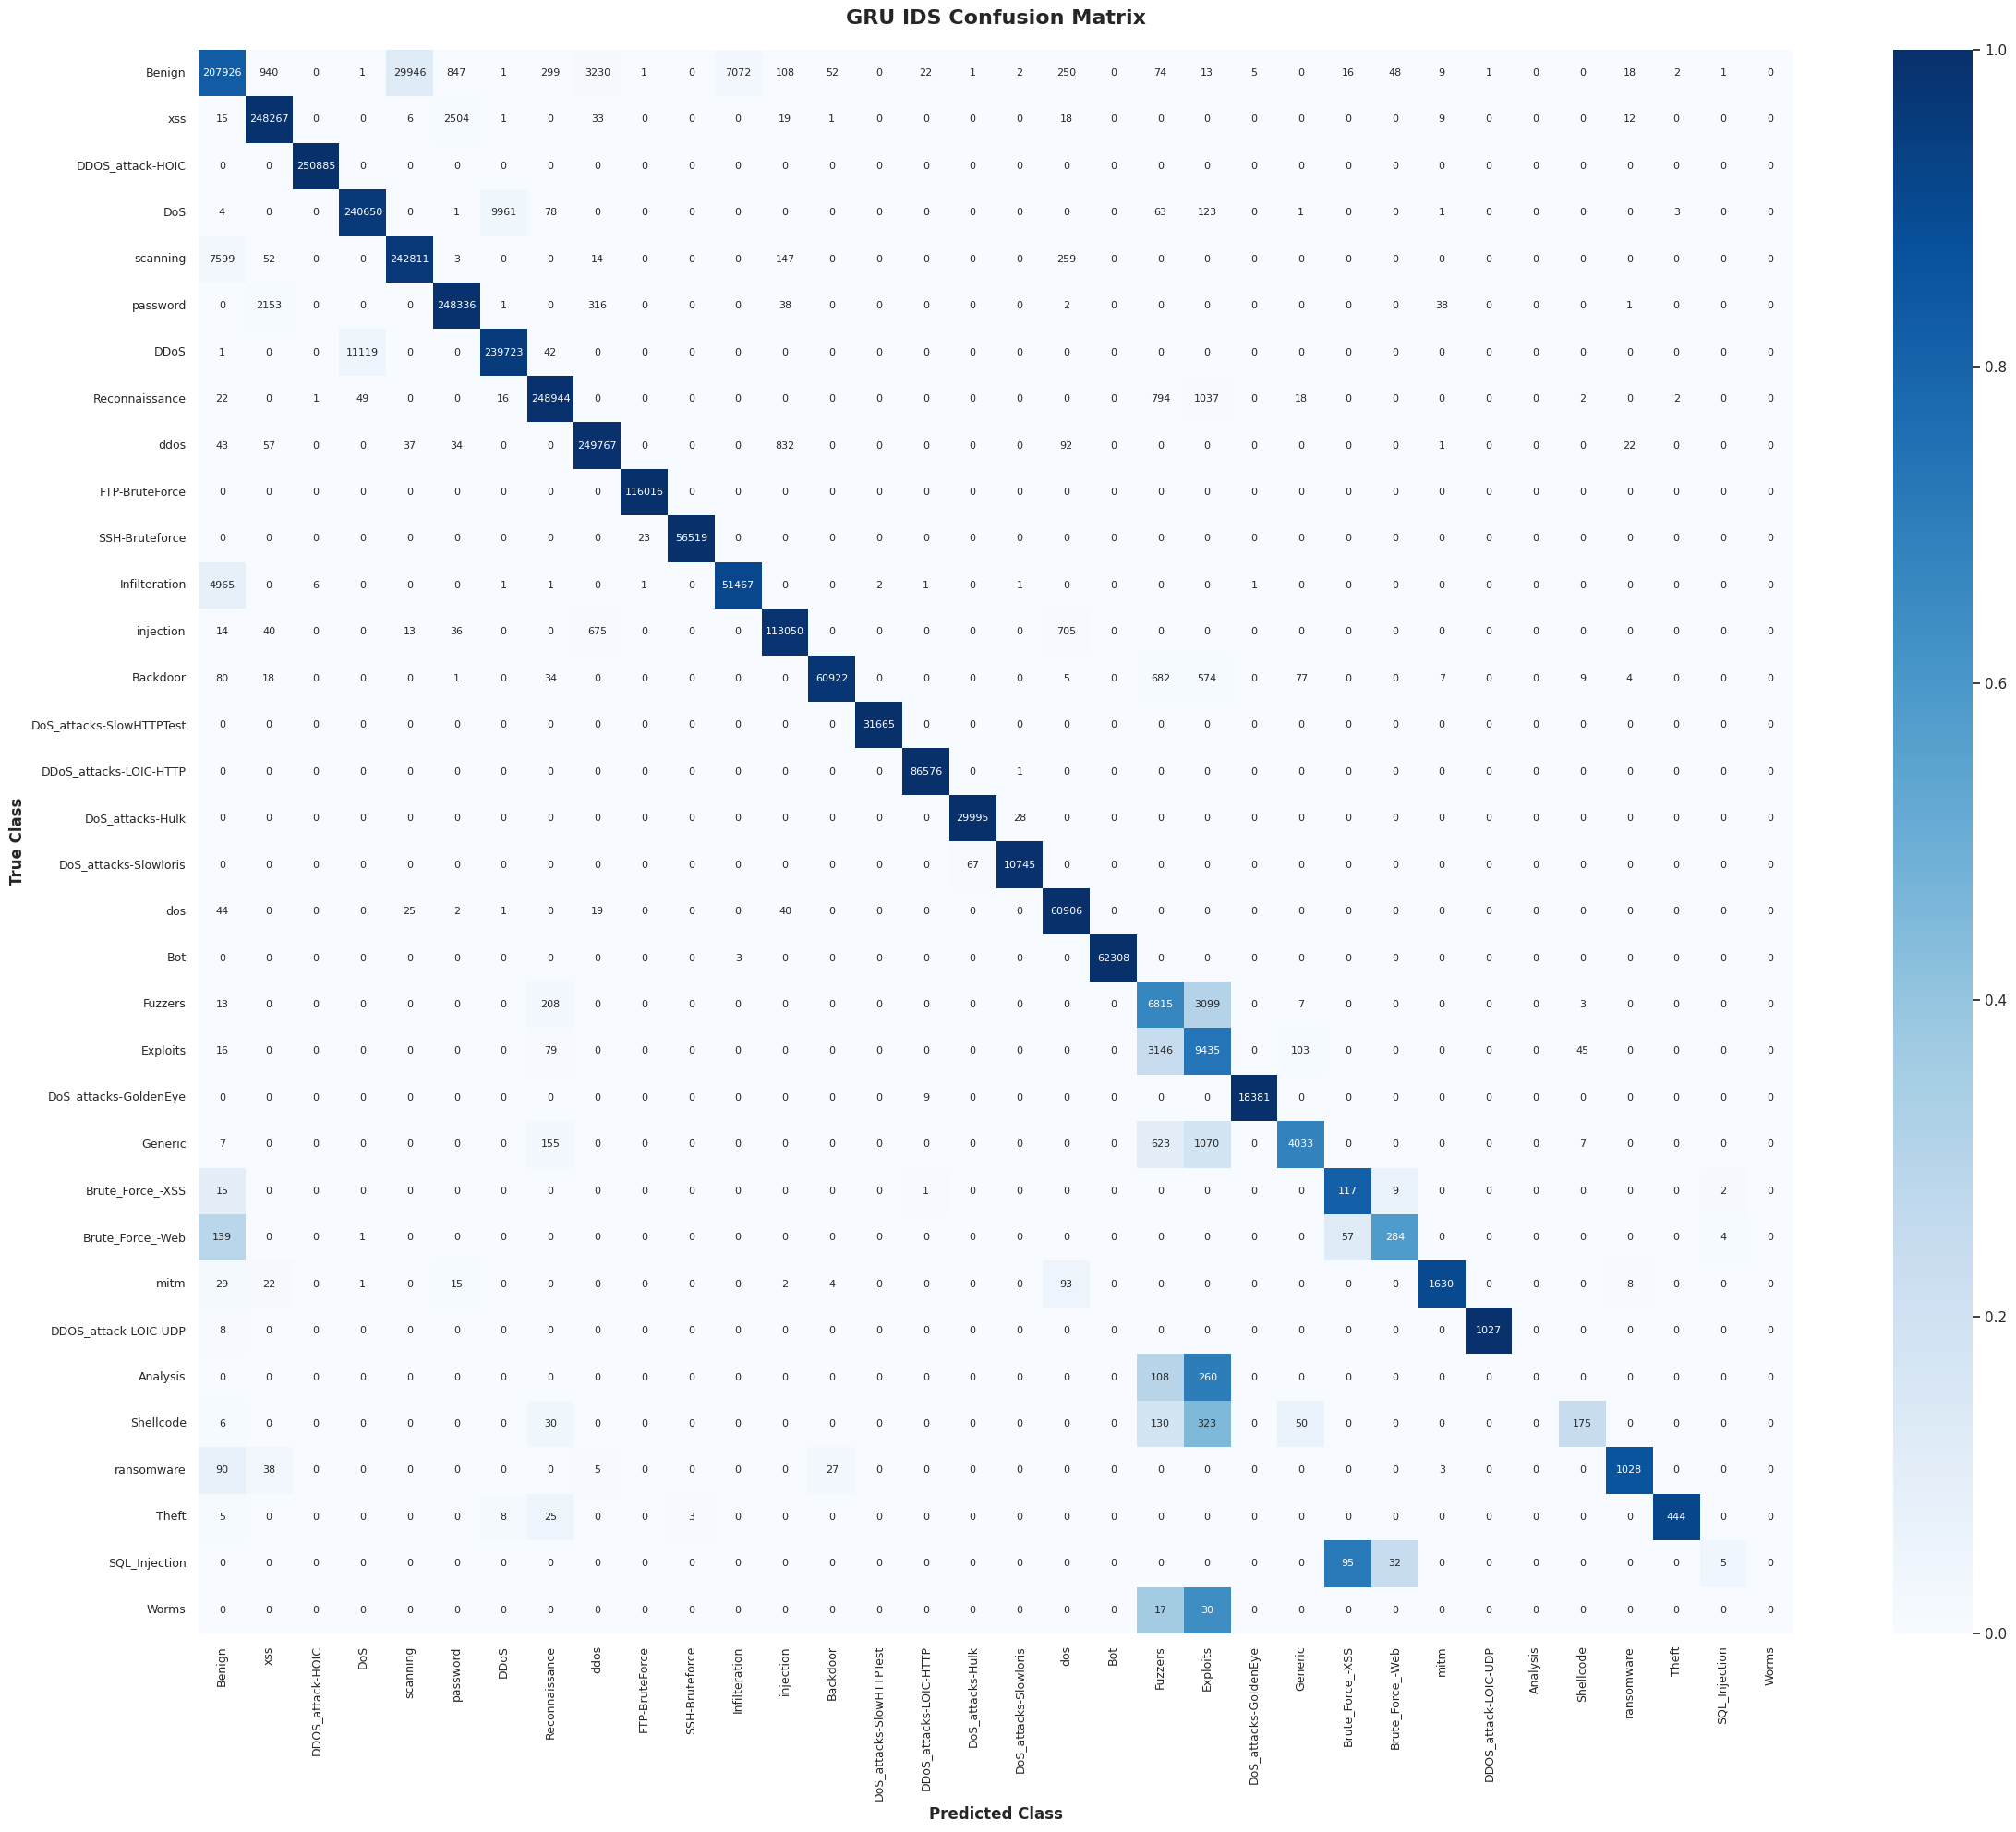

GRU IDS F1-score:  96.7%
GRU IDS Recall:    96.7%
GRU IDS Precision: 96.7%
GRU IDS AUC-ROC:   99.99%

Classification Report:


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


                         precision   recall f1-score  support
Benign                      95.82%   80.60%   87.55%   250885
xss                         97.48%   98.45%   97.96%   250885
DDOS_attack-HOIC           100.00%  100.00%  100.00%   250885
DoS                         95.83%   97.28%   96.55%   250885
scanning                    88.13%   97.39%   92.53%   250885
password                    97.65%   98.29%   97.97%   250885
DDoS                        97.33%   95.77%   96.54%   250885
Reconnaissance              99.74%   99.26%   99.50%   250885
ddos                        97.06%   98.84%   97.94%   250885
FTP-BruteForce              99.98%  100.00%   99.99%   116016
SSH-Bruteforce             100.00%   99.96%   99.98%    56542
Infilteration               85.33%   94.62%   89.73%    56446
injection                   98.38%   96.14%   97.24%   114533
Backdoor                    99.86%   97.62%   98.73%    62413
DoS_attacks-SlowHTTPTest    99.99%  100.00%   99.99%    31665
DDoS_att

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [43]:
# Ensure GPU is used for prediction
with tf.device('/GPU:0'):
    gru_y_pred_prob = loaded_gru_model.predict(reshaped_X_test, batch_size=8192 * gpu_strategy.num_replicas_in_sync)
    gru_y_pred = np.argmax(gru_y_pred_prob, axis=1)

# True labels
gru_y_true = np.argmax(reshaped_y_test, axis=1)

# ---------------------------------------------------------
# 1. HEATMAP CONFUSION MATRIX (NORMALIZED COLORS, RAW TEXT)
# ---------------------------------------------------------
# Extract the exact ordered class names from your pipeline's mapping
class_names = encoding_mappings['Attack'] 

# Calculate absolute counts (for the text inside the boxes)
raw_conf_matrix = confusion_matrix(bi_lstm_y_true, gru_y_pred)

# Calculate normalized counts by row (for the background colors)
# This calculates the Recall for each class (how many actual instances were predicted correctly)
norm_conf_matrix = confusion_matrix(gru_y_true, gru_y_pred, normalize='true')

# Plotting the Heatmap
plt.figure(figsize=(24, 20)) 
sns.heatmap(
    norm_conf_matrix,           # <-- Drives the colors (values are between 0.0 and 1.0)
    annot=raw_conf_matrix,      # <-- Prints the absolute figures inside the squares
    annot_kws={"size": 8},      
    cmap='Blues', 
    fmt='g',                    # Ensures the raw numbers print cleanly (no scientific notation)
    xticklabels=class_names, 
    yticklabels=class_names,
    vmin=0.0,                   # Locks the color bar base at 0%
    vmax=1.0                    # Locks the color bar ceiling at 100%
)

plt.title('GRU IDS Confusion Matrix', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('True Class', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Class', fontsize=12, fontweight='bold')
plt.xticks(rotation=90, fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 2. OVERALL METRICS
# ---------------------------------------------------------
gru_attention_f1 = round(f1_score(gru_y_true, gru_y_pred, average="micro") * 100, 2)
gru_attention_recall = round(recall_score(gru_y_true, gru_y_pred, average="micro") * 100, 2)
gru_attention_precision = round(precision_score(gru_y_true, gru_y_pred, average="micro") * 100, 2)
gru_attention_auc = round(roc_auc_score(gru_y_true, gru_y_pred_prob, multi_class='ovr', average="micro") * 100, 2)

print(f"GRU IDS F1-score:  {gru_attention_f1}%")
print(f"GRU IDS Recall:    {gru_attention_recall}%")
print(f"GRU IDS Precision: {gru_attention_precision}%")
print(f"GRU IDS AUC-ROC:   {gru_attention_auc}%\n")

# ---------------------------------------------------------
# 3. PERCENTAGE-BASED CLASSIFICATION REPORT WITH NAMES
# ---------------------------------------------------------
print("Classification Report:")

# Get the report as a dictionary instead of a raw string
report_dict = classification_report(bi_lstm_y_true, bi_lstm_y_pred, target_names=class_names, output_dict=True)

# Convert to Pandas DataFrame for easy manipulation
report_df = pd.DataFrame(report_dict).transpose()

# Clean up the 'accuracy' row to mimic standard sklearn visual structure
total_support = int(report_df.loc['macro avg', 'support'])
report_df.loc['accuracy', 'support'] = total_support
report_df.loc['accuracy', 'precision'] = np.nan
report_df.loc['accuracy', 'recall'] = np.nan

# Format decimals to percentages with '%' appended
metrics_cols = ['precision', 'recall', 'f1-score']
for col in metrics_cols:
    report_df[col] = report_df[col].apply(lambda x: f"{x * 100:.2f}%" if pd.notnull(x) else "")

# Ensure support remains a clean integer
report_df['support'] = report_df['support'].astype(int)

# Print the beautifully formatted DataFrame
print(report_df.to_string())

### Build Bidirectional Recurrent Gated Unit (Bi-GRU) IDS Model

In [13]:
bi_gru_model = Build_BiGRU(gpu_strategy)
bi_gru_model_checkpoint_callback = ModelCheckpoint(
    'bi_gru_model_best_v1.keras', monitor='val_loss', mode='min', verbose=1, 
    save_best_only=True
    )

Model: "BiGRU_IDS"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━┓
┃ Layer (type)              ┃ Output Shape        ┃   Param # ┃ Tra… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━┩
│ input_layer (InputLayer)  │ (None, 4, 15)       │         0 │  -   │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ bidirectional             │ (None, 4, 120)      │    27,720 │  Y   │
│ (Bidirectional)           │                     │           │      │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ batch_normalization       │ (None, 4, 120)      │       480 │  Y   │
│ (BatchNormalization)      │                     │           │      │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ bidirectional_1           │ (None, 150)         │    88,650 │  Y   │
│ (Bidirectional)           │                     │           │      │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ batch_normalization_1     │ (None, 150)         │       600 │  Y   │
│ (BatchNormalization)      │                     │           │      │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ dense (Dense)             │ (None, 34)          │     5,134 │  Y   │
└───────────────────────────┴─────────────────────┴───────────┴──────┘

 Total params: 122,584 (478.84 KB)

 Trainable params: 122,044 (476.73 KB)

 Non-trainable params: 540 (2.11 KB)

#### Train Bidirectional Recurrent Gated Unit (Bi-GRU) IDS Model

In [14]:
bi_gru_history = bi_gru_model.fit(reshaped_X_train.astype('float32'), reshaped_y_train.astype('float32'), 
                                epochs = EPOCHS, 
                                validation_data=(reshaped_X_test.astype('float32'), reshaped_y_test.astype('float32')), 
                                shuffle=True, 
                                verbose=1,
                                callbacks=[bi_gru_model_checkpoint_callback],
                                batch_size=8192 * gpu_strategy.num_replicas_in_sync) 

INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Redu

I0000 00:00:1781467736.083624     152 cuda_dnn.cc:529] Loaded cuDNN version 91002
I0000 00:00:1781467737.338074     153 cuda_dnn.cc:529] Loaded cuDNN version 91002


427/428 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step - accuracy: 0.5889 - loss: 1.4360INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).

Epoch 1: val_loss improved from None to 1.10311, saving model to bi_gru_model_best_v1.keras

Epoch 1: finished saving model to bi_gru_model_best_v1.keras
428/428 ━━━━━━━━━━━━━━━━━━━━ 72s 143ms/step - accuracy: 0.7245 - loss: 0.8572 - val_accuracy: 0.7310 - val_loss: 1.1031
Epoch 2/50
427/428 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step - accuracy: 0.8602 - loss: 0.3830
Epoch 2: val_loss improved from 1.10311 to 0.28977, saving model to bi_gru_model_best_v1.keras

Epoch 2: finished saving model to bi_gru_model_best_v1.keras
428/428 ━━━━━━━━━━━━━━━━━━━━ 60s 139ms/step - accuracy: 0.8729 - loss: 0.3427 - val_accuracy: 0.8885 - val_loss: 0.2898
Epoc

#### Plot Training & Validation Histry of BiGRU IDS Model

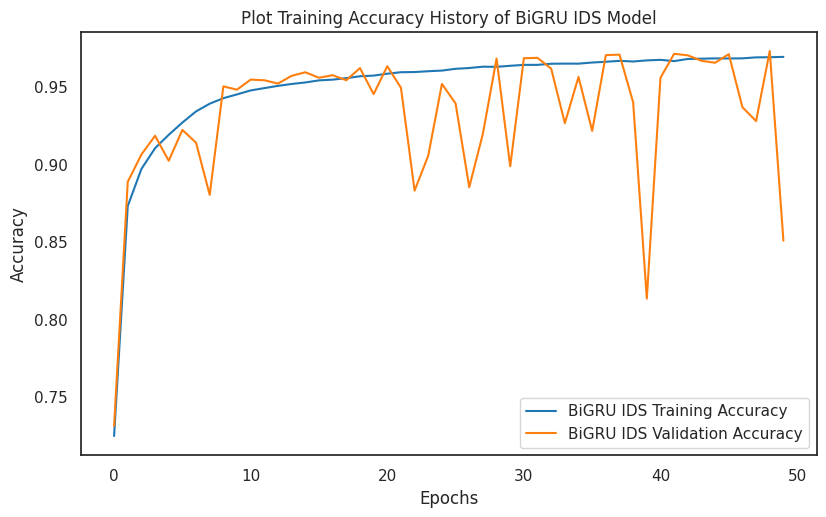

In [15]:
fig, ax = plt.subplots(1, figsize=(9.5,5.5))
plt.plot(range(EPOCHS), bi_gru_history.history['accuracy'], color=color_pal[0], label='BiGRU IDS Training Accuracy')
plt.plot(range(EPOCHS), bi_gru_history.history['val_accuracy'], color=color_pal[1], label='BiGRU IDS Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title("Plot Training Accuracy History of BiGRU IDS Model")
plt.legend() 
plt.show()

#### Plot Loss History of BiGRU IDS Model

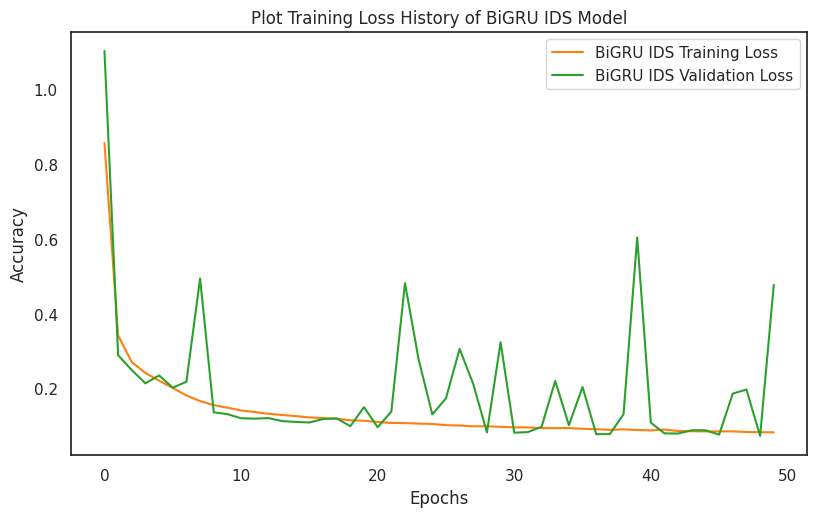

In [16]:
fig, ax = plt.subplots(1, figsize=(9.5,5.5))
plt.plot(range(EPOCHS), bi_gru_history.history['loss'], color=color_pal[1], label='BiGRU IDS Training Loss')
plt.plot(range(EPOCHS), bi_gru_history.history['val_loss'], color=color_pal[2], label='BiGRU IDS Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title("Plot Training Loss History of BiGRU IDS Model")
plt.legend()
plt.show()

#### Load Best Variant of BiGRU IDS Model

In [40]:
with gpu_strategy.scope():
    loaded_bi_gru_model = load_model('/kaggle/working/bi_gru_model_best_v1.keras')
    loaded_bi_gru_model.summary()

Model: "BiGRU_IDS"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 4, 15)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 4, 120)         │        27,720 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 4, 120)         │           480 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 150)            │        88,650 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 150)            │           600 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 34)             │         5,134 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 366,674 (1.40 MB)

 Trainable params: 122,044 (476.73 KB)

 Non-trainable params: 540 (2.11 KB)

 Optimizer params: 244,090 (953.48 KB)

#### Evaluate Best Variant of BiGRU IDS Model

In [18]:
loaded_bi_gru_train_metric = loaded_bi_gru_model.evaluate(reshaped_X_train.astype('float32'), reshaped_y_train.astype('float32'), return_dict=True, batch_size=4096 * gpu_strategy.num_replicas_in_sync)
loaded_bi_gru_test_metric = loaded_bi_gru_model.evaluate(reshaped_X_test.astype('float32'), reshaped_y_test.astype('float32'), return_dict=True, batch_size=4096 * gpu_strategy.num_replicas_in_sync)
print(f'Accuracy during training: {round(loaded_bi_gru_train_metric["accuracy"]*100, 2)}% and loss: {round(loaded_bi_gru_train_metric["loss"], 4)}')
print(f'Accuracy during test: {round(loaded_bi_gru_test_metric["accuracy"]*100, 2)}% and loss: {round(loaded_bi_gru_test_metric["loss"], 4)}')

855/855 ━━━━━━━━━━━━━━━━━━━━ 18s 19ms/step - accuracy: 0.9731 - loss: 0.0731
367/367 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.9729 - loss: 0.0739
Accuracy during training: 97.31% and loss: 0.0731
Accuracy during test: 97.29% and loss: 0.0739


#### Save BiGRU IDS Model Metrics

In [19]:
# 1. Initialize the master data structure file
registry = ModelRegistry()

registry.add_model_metrics(
    model_name="BiGRU_IDS",
    history_object=bi_gru_history,
    train_eval=loaded_bi_gru_train_metric,
    test_eval=loaded_bi_gru_test_metric
)

# 2. Save everything into the single file
registry.save_to_disk()

# Inside your visualization notebook or function:
with open("/kaggle/working/all_network_models_report.json", "r") as f:
    metrics_data = json.load(f)

# Test performance parameters of TGAT IDS are saved properly
print(f'BiGRU IDS Accuracy during training: {round(metrics_data["BiGRU_IDS"]['final_evaluation']['train_accuracy']*100, 2)}%')
print(f'BiGRU IDS Accuracy during training: {round(metrics_data["BiGRU_IDS"]['final_evaluation']['test_accuracy']*100, 2)}%')

Successfully added 'BiGRU_IDS' metrics to registry container.
Master benchmark dataset written to: /kaggle/working/all_network_models_report.json
BiGRU IDS Accuracy during training: 97.31%
BiGRU IDS Accuracy during training: 97.29%


#### Evaluate Best BiGRU Using Confusion Matrix & Plot Confusion Matrix on HeatMap

184/184 ━━━━━━━━━━━━━━━━━━━━ 8s 42ms/step


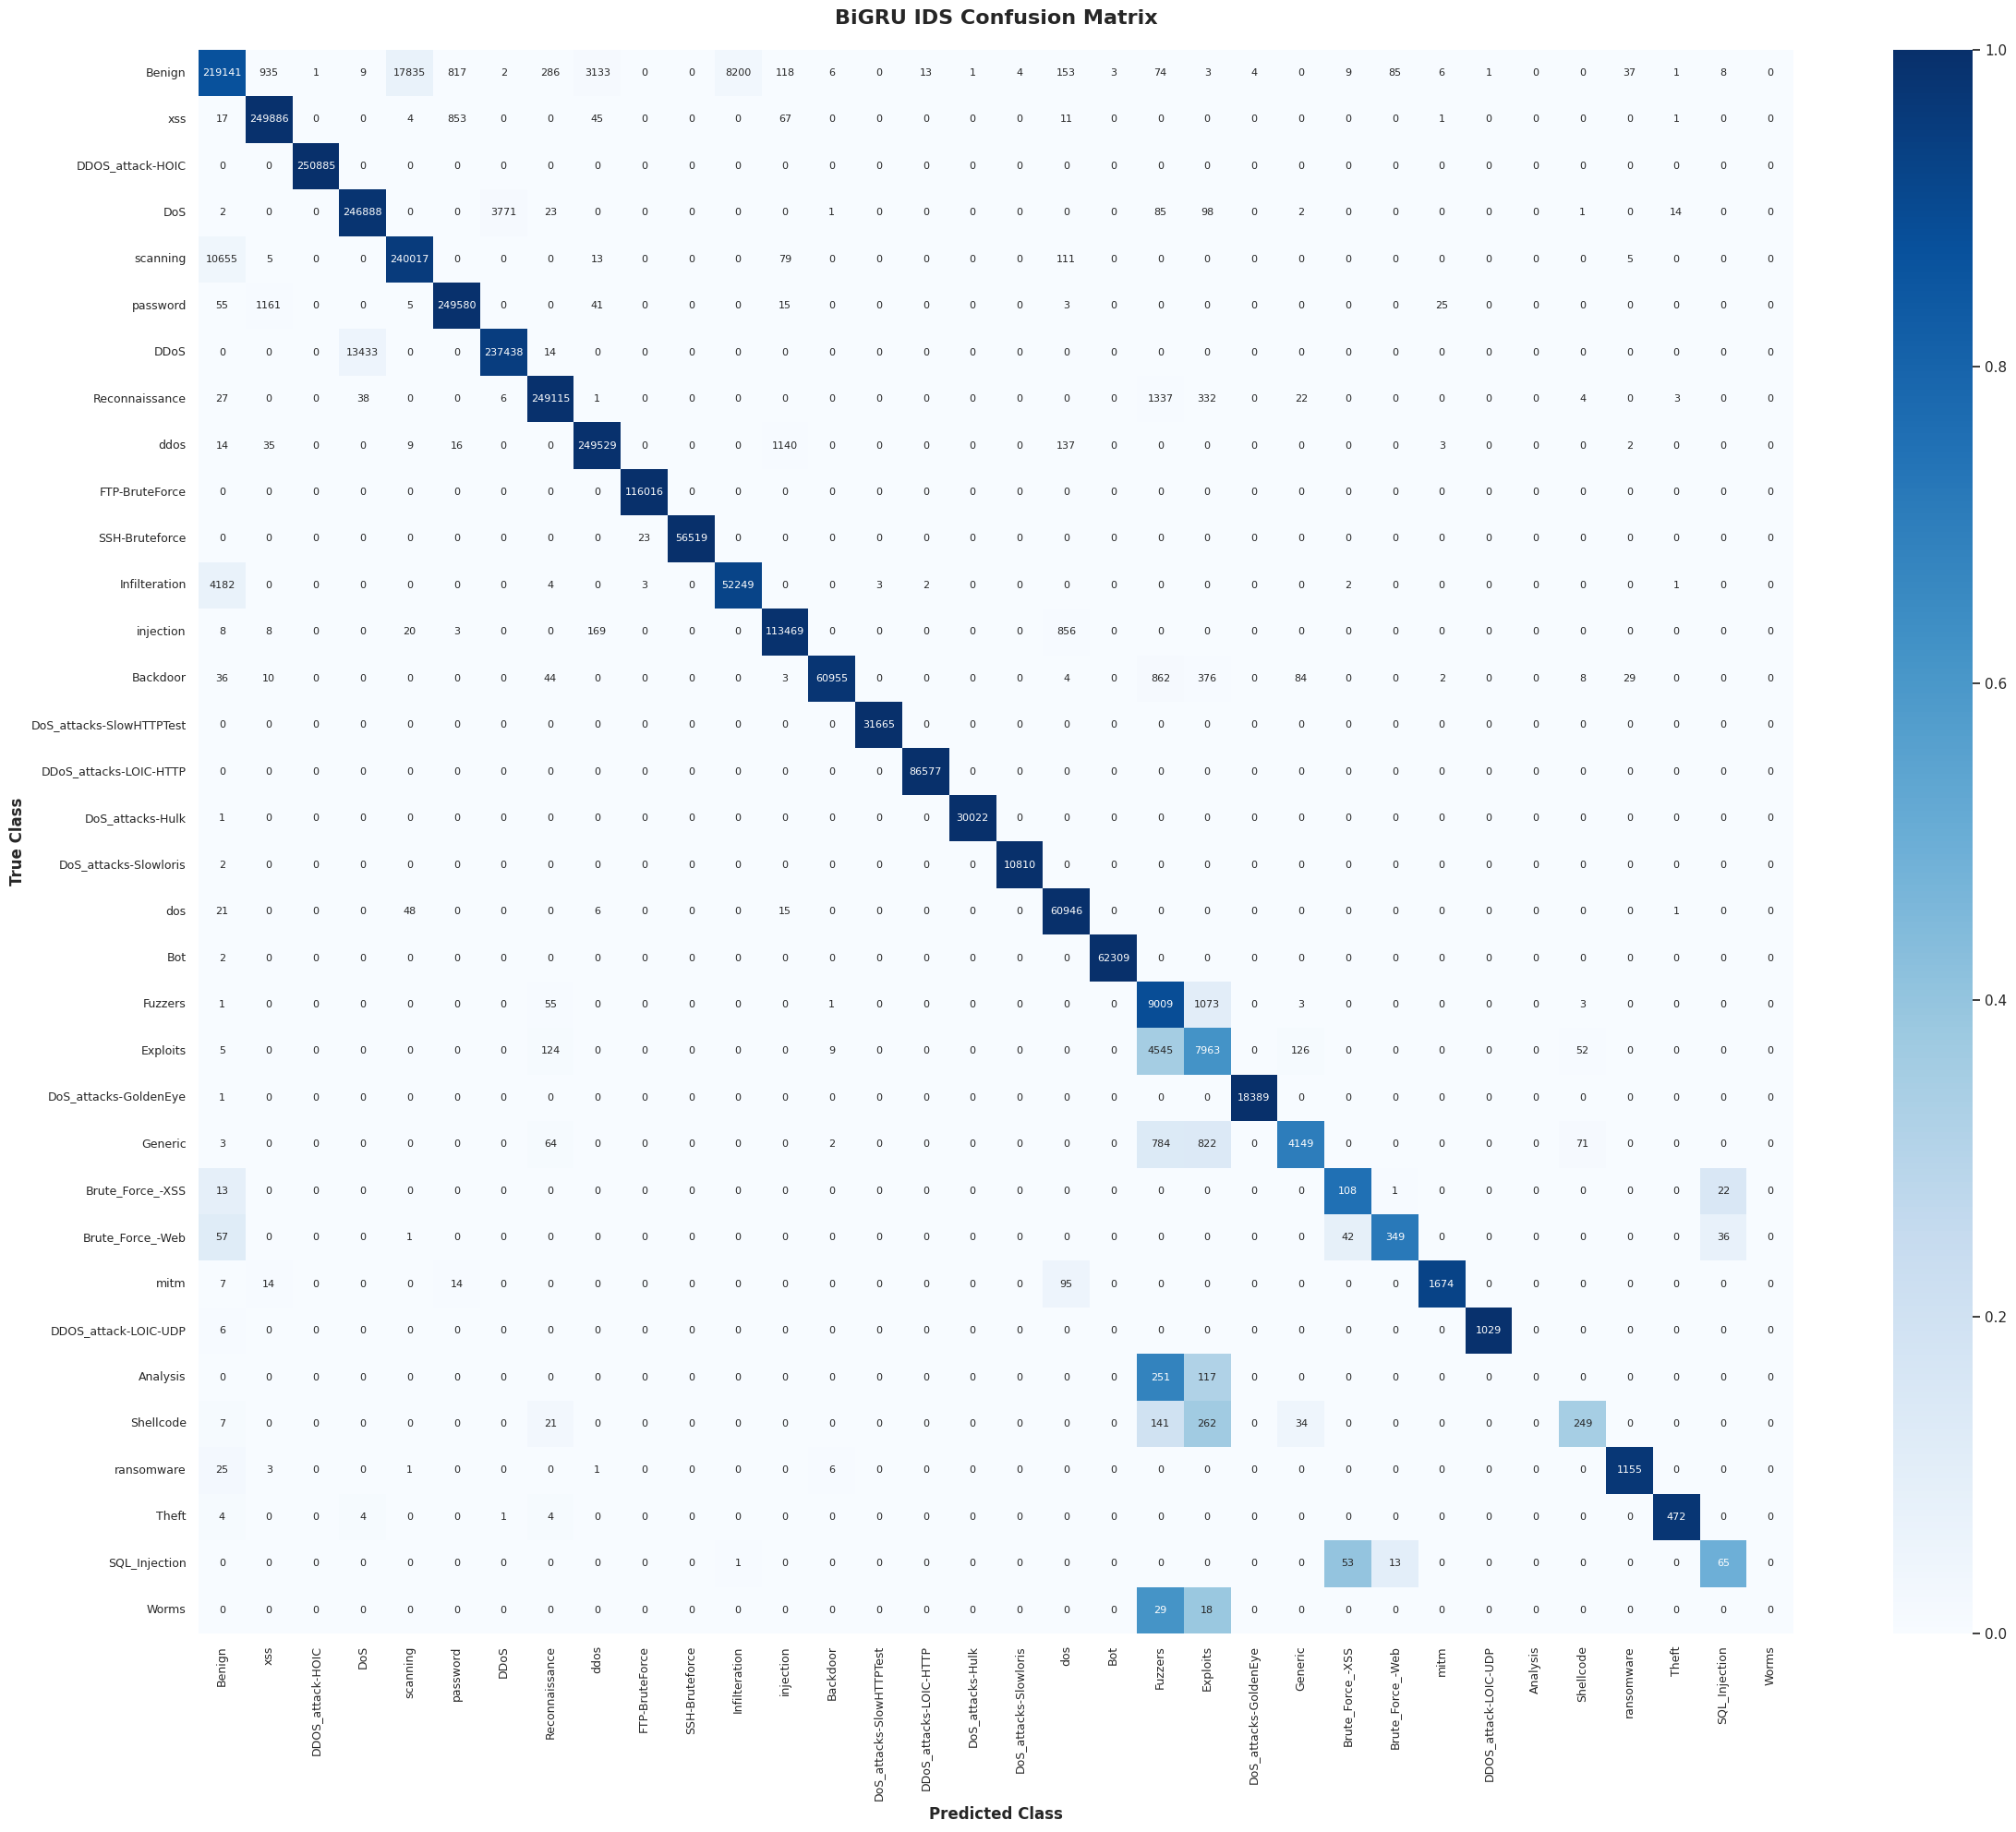

BiGRU IDS F1-score:  97.29%
BiGRU IDS Recall:    97.29%
BiGRU IDS Precision: 97.29%
BiGRU IDS AUC-ROC:   99.99%

Classification Report:


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


                         precision   recall f1-score  support
Benign                      93.53%   87.35%   90.33%   250885
xss                         99.14%   99.60%   99.37%   250885
DDOS_attack-HOIC           100.00%  100.00%  100.00%   250885
DoS                         94.82%   98.41%   96.58%   250885
scanning                    93.05%   95.67%   94.34%   250885
password                    99.32%   99.48%   99.40%   250885
DDoS                        98.43%   94.64%   96.50%   250885
Reconnaissance              99.74%   99.29%   99.52%   250885
ddos                        98.65%   99.46%   99.05%   250885
FTP-BruteForce              99.98%  100.00%   99.99%   116016
SSH-Bruteforce             100.00%   99.96%   99.98%    56542
Infilteration               86.43%   92.56%   89.39%    56446
injection                   98.75%   99.07%   98.91%   114533
Backdoor                    99.96%   97.66%   98.80%    62413
DoS_attacks-SlowHTTPTest    99.99%  100.00%  100.00%    31665
DDoS_att

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [46]:
# Ensure GPU is used for prediction
with tf.device('/GPU:0'):
    bi_gru_y_pred_prob = loaded_bi_gru_model.predict(reshaped_X_test, batch_size=8192 * gpu_strategy.num_replicas_in_sync)
    bi_gru_y_pred = np.argmax(bi_gru_y_pred_prob, axis=1)

# True labels
bi_gru_y_true = np.argmax(reshaped_y_test, axis=1)

# ---------------------------------------------------------
# 1. HEATMAP CONFUSION MATRIX (NORMALIZED COLORS, RAW TEXT)
# ---------------------------------------------------------
# Extract the exact ordered class names from your pipeline's mapping
class_names = encoding_mappings['Attack'] 

# Calculate absolute counts (for the text inside the boxes)
raw_conf_matrix = confusion_matrix(bi_gru_y_true, bi_gru_y_pred)

# Calculate normalized counts by row (for the background colors)
# This calculates the Recall for each class (how many actual instances were predicted correctly)
norm_conf_matrix = confusion_matrix(bi_gru_y_true, bi_gru_y_pred, normalize='true')

# Plotting the Heatmap
plt.figure(figsize=(24, 20)) 
sns.heatmap(
    norm_conf_matrix,           # <-- Drives the colors (values are between 0.0 and 1.0)
    annot=raw_conf_matrix,      # <-- Prints the absolute figures inside the squares
    annot_kws={"size": 8},      
    cmap='Blues', 
    fmt='g',                    # Ensures the raw numbers print cleanly (no scientific notation)
    xticklabels=class_names, 
    yticklabels=class_names,
    vmin=0.0,                   # Locks the color bar base at 0%
    vmax=1.0                    # Locks the color bar ceiling at 100%
)

plt.title('BiGRU IDS Confusion Matrix', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('True Class', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Class', fontsize=12, fontweight='bold')
plt.xticks(rotation=90, fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 2. OVERALL METRICS
# ---------------------------------------------------------
bi_gru_attention_f1 = round(f1_score(bi_gru_y_true, bi_gru_y_pred, average="micro") * 100, 2)
bi_gru_attention_recall = round(recall_score(bi_gru_y_true, bi_gru_y_pred, average="micro") * 100, 2)
bi_gru_attention_precision = round(precision_score(bi_gru_y_true, bi_gru_y_pred, average="micro") * 100, 2)
bi_gru_attention_auc = round(roc_auc_score(bi_gru_y_true, bi_gru_y_pred_prob, multi_class='ovr', average="micro") * 100, 2)

print(f"BiGRU IDS F1-score:  {bi_gru_attention_f1}%")
print(f"BiGRU IDS Recall:    {bi_gru_attention_recall}%")
print(f"BiGRU IDS Precision: {bi_gru_attention_precision}%")
print(f"BiGRU IDS AUC-ROC:   {bi_gru_attention_auc}%\n")

# ---------------------------------------------------------
# 3. PERCENTAGE-BASED CLASSIFICATION REPORT WITH NAMES
# ---------------------------------------------------------
print("Classification Report:")

# Get the report as a dictionary instead of a raw string
report_dict = classification_report(bi_gru_y_true, bi_gru_y_pred, target_names=class_names, output_dict=True)

# Convert to Pandas DataFrame for easy manipulation
report_df = pd.DataFrame(report_dict).transpose()

# Clean up the 'accuracy' row to mimic standard sklearn visual structure
total_support = int(report_df.loc['macro avg', 'support'])
report_df.loc['accuracy', 'support'] = total_support
report_df.loc['accuracy', 'precision'] = np.nan
report_df.loc['accuracy', 'recall'] = np.nan

# Format decimals to percentages with '%' appended
metrics_cols = ['precision', 'recall', 'f1-score']
for col in metrics_cols:
    report_df[col] = report_df[col].apply(lambda x: f"{x * 100:.2f}%" if pd.notnull(x) else "")

# Ensure support remains a clean integer
report_df['support'] = report_df['support'].astype(int)

# Print the beautifully formatted DataFrame
print(report_df.to_string())

## Build Temporal Convolution Network (TCN) IDS Model

In [24]:
tcn_model = Build_TCN(gpu_strategy)
tcn_model_checkpoint_callback = ModelCheckpoint(
    'tcn_model_best_v1.keras', monitor='val_loss', mode='min', verbose=1, 
    save_best_only=True
    )

Model: "TCN_IDS"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━┓
┃ Layer (type)              ┃ Output Shape        ┃   Param # ┃ Tra… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━┩
│ input_layer (InputLayer)  │ (None, 4, 15)       │         0 │  -   │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ tcn (TCN)                 │ (None, 4, 64)       │    41,024 │  Y   │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ batch_normalization       │ (None, 4, 64)       │       256 │  Y   │
│ (BatchNormalization)      │                     │           │      │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ tcn_1 (TCN)               │ (None, 64)          │    49,408 │  Y   │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ batch_normalization_1     │ (None, 64)          │       256 │  Y   │
│ (BatchNormalization)      │                     │           │      │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ dense (Dense)             │ (None, 34)          │     2,210 │  Y   │
└───────────────────────────┴─────────────────────┴───────────┴──────┘

 Total params: 93,154 (363.88 KB)

 Trainable params: 92,898 (362.88 KB)

 Non-trainable params: 256 (1.00 KB)

#### Train Temporal Convolution Network (TCN) IDS Model

In [25]:
tcn_history = tcn_model.fit(reshaped_X_train.astype('float32'), reshaped_y_train.astype('float32'), 
                                epochs = EPOCHS, 
                                validation_data=(reshaped_X_test.astype('float32'), reshaped_y_test.astype('float32')), 
                                shuffle=True, 
                                verbose=1,
                                callbacks=[tcn_model_checkpoint_callback],
                                batch_size=8192 * gpu_strategy.num_replicas_in_sync ) 

INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Redu

I0000 00:00:1781181531.197593     201 cuda_dnn.cc:529] Loaded cuDNN version 91002
I0000 00:00:1781181531.197611     203 cuda_dnn.cc:529] Loaded cuDNN version 91002


428/428 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.3917 - loss: 2.3720INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).

Epoch 1: val_loss improved from None to 0.93147, saving model to tcn_model_best_v1.keras

Epoch 1: finished saving model to tcn_model_best_v1.keras
428/428 ━━━━━━━━━━━━━━━━━━━━ 37s 61ms/step - accuracy: 0.5762 - loss: 1.5677 - val_accuracy: 0.7234 - val_loss: 0.9315
Epoch 2/50
427/428 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.7699 - loss: 0.7172
Epoch 2: val_loss improved from 0.93147 to 0.56950, saving model to tcn_model_best_v1.keras

Epoch 2: finished saving model to tcn_model_best_v1.keras
428/428 ━━━━━━━━━━━━━━━━━━━━ 22s 50ms/step - accuracy: 0.7854 - loss: 0.6513 - val_accuracy: 0.8082 - val_loss: 0.5695
Epoch 3/50
427/428 ━

#### Plot Training & Validation History of TCN IDS Model

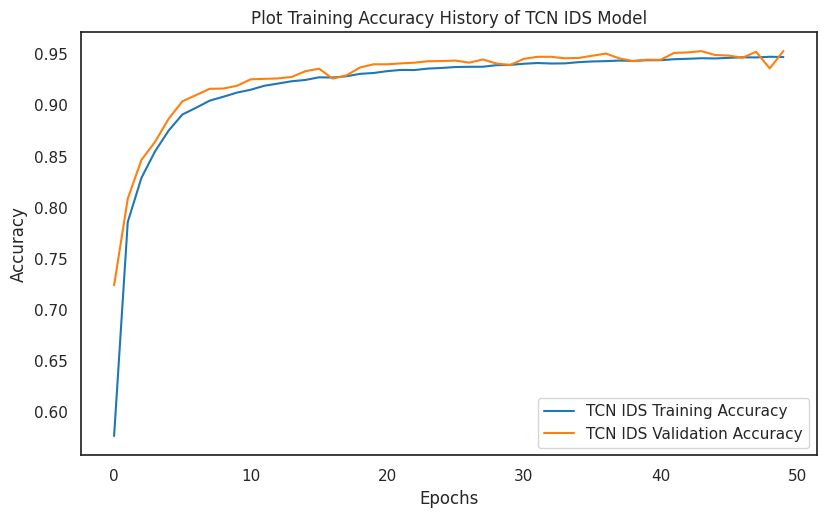

In [26]:
fig, ax = plt.subplots(1, figsize=(9.5,5.5))
plt.plot(range(EPOCHS), tcn_history.history['accuracy'], color=color_pal[0], label='TCN IDS Training Accuracy')
plt.plot(range(EPOCHS), tcn_history.history['val_accuracy'], color=color_pal[1], label='TCN IDS Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title("Plot Training Accuracy History of TCN IDS Model")
plt.legend()
plt.show()

#### Plot Loss History of TCN IDS Model

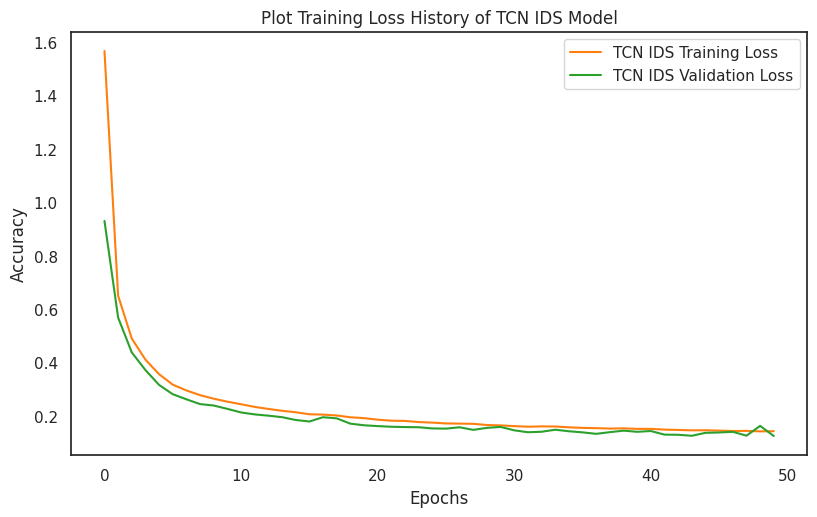

In [27]:
fig, ax = plt.subplots(1, figsize=(9.5,5.5))
plt.plot(range(EPOCHS), tcn_history.history['loss'], color=color_pal[1], label='TCN IDS Training Loss')
plt.plot(range(EPOCHS), tcn_history.history['val_loss'], color=color_pal[2], label='TCN IDS Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title("Plot Training Loss History of TCN IDS Model")
plt.legend()
plt.show()

#### Load Best Variant of TCN IDS Model

In [62]:
with gpu_strategy.scope():
    loaded_tcn_model = load_model('/kaggle/working/tcn_model_best_v1.keras')
    loaded_tcn_model.summary()

Model: "TCN_IDS"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 4, 15)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ tcn (TCN)                       │ (None, 4, 64)          │        41,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 4, 64)          │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ tcn_1 (TCN)                     │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 34)             │         2,210 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 278,952 (1.06 MB)

 Trainable params: 92,898 (362.88 KB)

 Non-trainable params: 256 (1.00 KB)

 Optimizer params: 185,798 (725.78 KB)

#### Evaluate Best Variant of TCN IDS Model

In [29]:
loaded_tcn_train_metric = loaded_tcn_model.evaluate(reshaped_X_train.astype('float32'), reshaped_y_train.astype('float32'), return_dict=True, batch_size=4096 * gpu_strategy.num_replicas_in_sync)
loaded_tcn_test_metric = loaded_tcn_model.evaluate(reshaped_X_test.astype('float32'), reshaped_y_test.astype('float32'), return_dict=True, batch_size=4096 * gpu_strategy.num_replicas_in_sync)
print(f'Accuracy during training: {round(loaded_tcn_train_metric["accuracy"]*100, 2)}% and loss: {round(loaded_tcn_train_metric["loss"], 4)}')
print(f'Accuracy during test: {round(loaded_tcn_test_metric["accuracy"]*100, 2)}% and loss: {round(loaded_tcn_test_metric["loss"], 4)}')

855/855 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - accuracy: 0.9532 - loss: 0.1249
367/367 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9527 - loss: 0.1261
Accuracy during training: 95.32% and loss: 0.1249
Accuracy during test: 95.27% and loss: 0.1261


#### Save TCN IDS Model Metrics

In [33]:
# 1. Initialize the master data structure file
registry = ModelRegistry("all_network_models_report.json")

registry.add_model_metrics(
    model_name="TCN_IDS",
    history_object=tcn_history,
    train_eval=loaded_tcn_train_metric,
    test_eval=loaded_tcn_test_metric
)

# 2. Save everything into the single file
registry.save_to_disk()

# Inside your visualization notebook or function:
with open("/kaggle/working/all_network_models_report.json", "r") as f:
    metrics_data = json.load(f)

# Test performance parameters of TGAT IDS are saved properly
print(f'TCN IDS Accuracy during training: {round(metrics_data["TCN_IDS"]['final_evaluation']['train_accuracy']*100, 2)}%')
print(f'TCN IDS Accuracy during training: {round(metrics_data["TCN_IDS"]['final_evaluation']['test_accuracy']*100, 2)}%')

Successfully added 'TCN_IDS' metrics to registry container.
Master benchmark dataset written to: all_network_models_report.json


184/184 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step


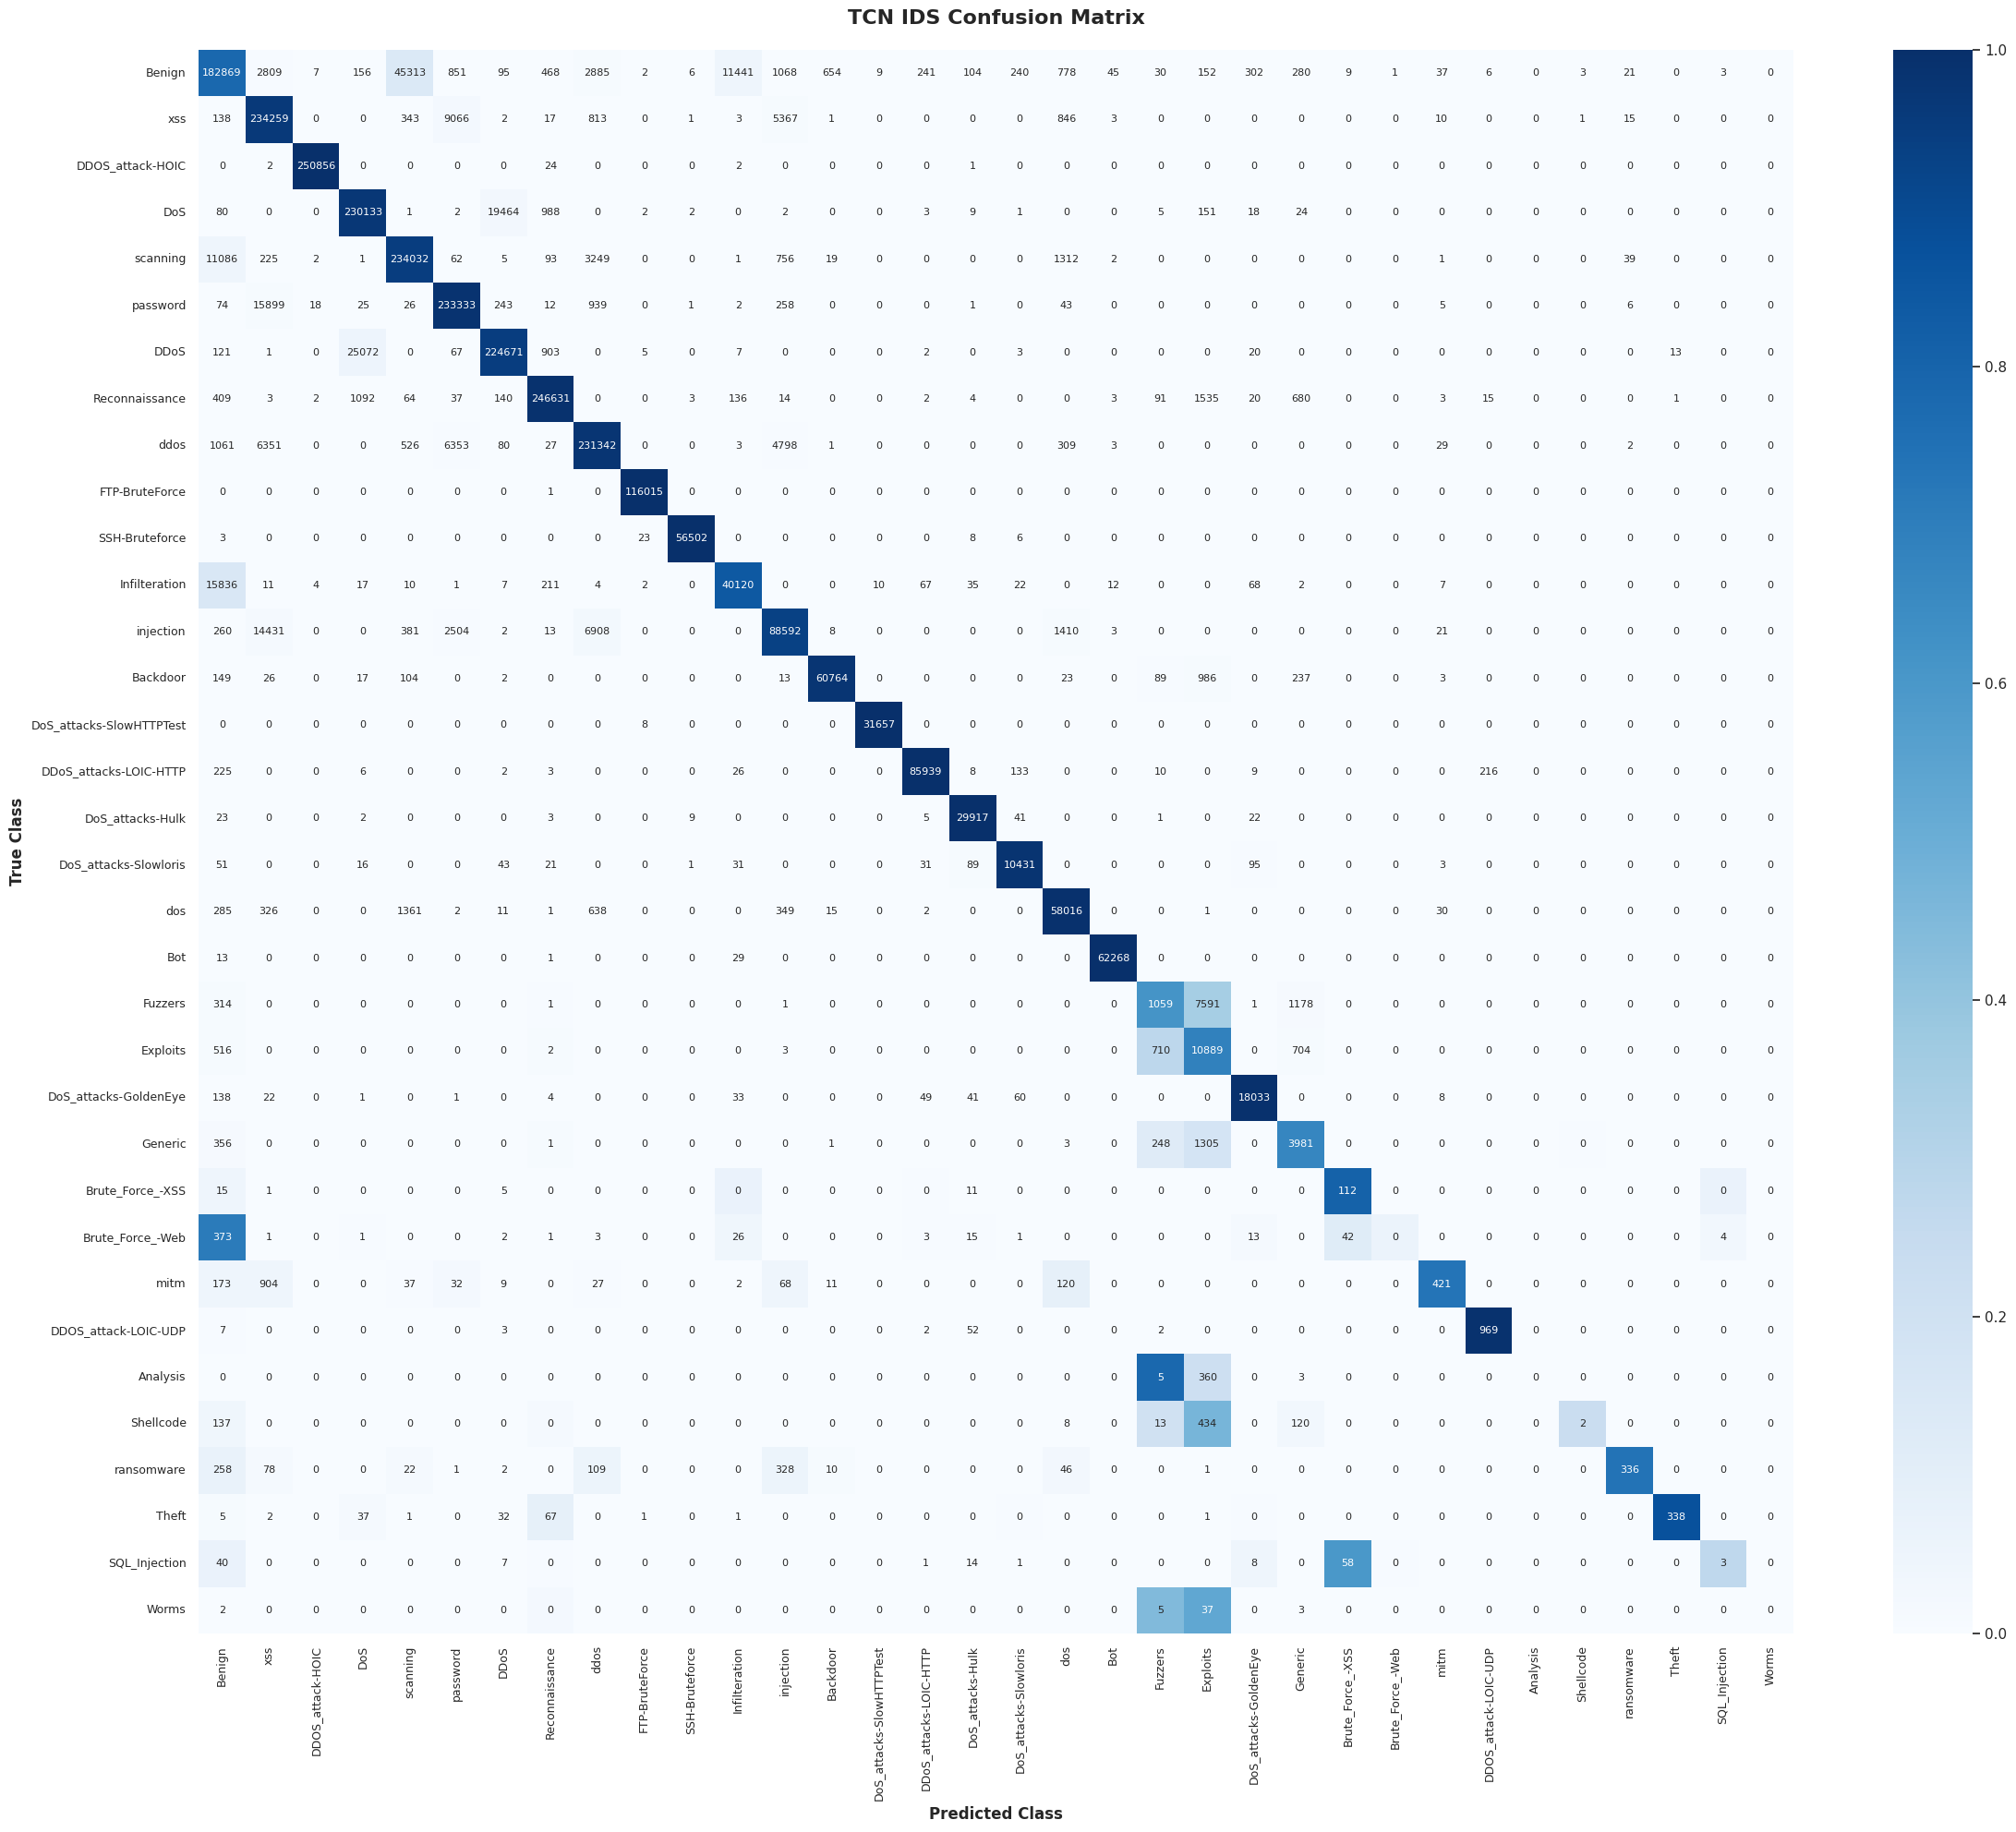

TCN IDS F1-score:  95.35%
TCN IDS Recall:    95.35%
TCN IDS Precision: 95.35%
TCN IDS AUC-ROC:   99.97%

Classification Report:


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


                         precision   recall f1-score  support
Benign                      85.05%   72.89%   78.50%   250885
xss                         85.08%   93.37%   89.03%   250885
DDOS_attack-HOIC            99.99%   99.99%   99.99%   250885
DoS                         89.69%   91.73%   90.70%   250885
scanning                    82.93%   93.28%   87.80%   250885
password                    92.48%   93.00%   92.74%   250885
DDoS                        91.77%   89.55%   90.65%   250885
Reconnaissance              98.85%   98.30%   98.58%   250885
ddos                        93.69%   92.21%   92.95%   250885
FTP-BruteForce              99.96%  100.00%   99.98%   116016
SSH-Bruteforce              99.96%   99.93%   99.94%    56542
Infilteration               77.36%   71.08%   74.08%    56446
injection                   87.18%   77.35%   81.97%   114533
Backdoor                    98.83%   97.36%   98.09%    62413
DoS_attacks-SlowHTTPTest    99.94%   99.97%   99.96%    31665
DDoS_att

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [63]:
# Ensure GPU is used for prediction
with tf.device('/GPU:0'):
    tcn_y_pred_prob = loaded_tcn_model.predict(reshaped_X_test, batch_size=8192 * gpu_strategy.num_replicas_in_sync)
    tcn_y_pred = np.argmax(tcn_y_pred_prob, axis=1)

# True labels
tcn_y_true = np.argmax(reshaped_y_test, axis=1)

# ---------------------------------------------------------
# 1. HEATMAP CONFUSION MATRIX (NORMALIZED COLORS, RAW TEXT)
# ---------------------------------------------------------
# Extract the exact ordered class names from your pipeline's mapping
class_names = encoding_mappings['Attack'] 

# Calculate absolute counts (for the text inside the boxes)
raw_conf_matrix = confusion_matrix(mha_y_true, mha_y_pred)

# Calculate normalized counts by row (for the background colors)
# This calculates the Recall for each class (how many actual instances were predicted correctly)
norm_conf_matrix = confusion_matrix(tcn_y_true, tcn_y_pred, normalize='true')

# Plotting the Heatmap
plt.figure(figsize=(24, 20)) 
sns.heatmap(
    norm_conf_matrix,           # <-- Drives the colors (values are between 0.0 and 1.0)
    annot=raw_conf_matrix,      # <-- Prints the absolute figures inside the squares
    annot_kws={"size": 8},      
    cmap='Blues', 
    fmt='g',                    # Ensures the raw numbers print cleanly (no scientific notation)
    xticklabels=class_names, 
    yticklabels=class_names,
    vmin=0.0,                   # Locks the color bar base at 0%
    vmax=1.0                    # Locks the color bar ceiling at 100%
)

plt.title('TCN IDS Confusion Matrix', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('True Class', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Class', fontsize=12, fontweight='bold')
plt.xticks(rotation=90, fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 2. OVERALL METRICS
# ---------------------------------------------------------
tcn_attention_f1 = round(f1_score(tcn_y_true, tcn_y_pred, average="micro") * 100, 2)
tcn_attention_recall = round(recall_score(tcn_y_true, tcn_y_pred, average="micro") * 100, 2)
tcn_attention_precision = round(precision_score(tcn_y_true, tcn_y_pred, average="micro") * 100, 2)
tcn_attention_auc = round(roc_auc_score(tcn_y_true, tcn_y_pred_prob, multi_class='ovr', average="micro") * 100, 2)

print(f"TCN IDS F1-score:  {tcn_attention_f1}%")
print(f"TCN IDS Recall:    {tcn_attention_recall}%")
print(f"TCN IDS Precision: {tcn_attention_precision}%")
print(f"TCN IDS AUC-ROC:   {tcn_attention_auc}%\n")

# ---------------------------------------------------------
# 3. PERCENTAGE-BASED CLASSIFICATION REPORT WITH NAMES
# ---------------------------------------------------------
print("Classification Report:")

# Get the report as a dictionary instead of a raw string
report_dict = classification_report(mha_y_true, mha_y_pred, target_names=class_names, output_dict=True)

# Convert to Pandas DataFrame for easy manipulation
report_df = pd.DataFrame(report_dict).transpose()

# Clean up the 'accuracy' row to mimic standard sklearn visual structure
total_support = int(report_df.loc['macro avg', 'support'])
report_df.loc['accuracy', 'support'] = total_support
report_df.loc['accuracy', 'precision'] = np.nan
report_df.loc['accuracy', 'recall'] = np.nan

# Format decimals to percentages with '%' appended
metrics_cols = ['precision', 'recall', 'f1-score']
for col in metrics_cols:
    report_df[col] = report_df[col].apply(lambda x: f"{x * 100:.2f}%" if pd.notnull(x) else "")

# Ensure support remains a clean integer
report_df['support'] = report_df['support'].astype(int)

# Print the beautifully formatted DataFrame
print(report_df.to_string())

## Build Multi-Head Attention (MHA) IDS Model

In [37]:
mha_model = Build_MultiHead_Attention(gpu_strategy)
mha_model_checkpoint_callback = ModelCheckpoint(
    'mha_model_best_v1.keras', monitor='val_loss', mode='min', verbose=1, 
    save_best_only=True
    )

Model: "MHA_IDS"

┏━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━┓
┃ Layer (type)    ┃ Output Shape   ┃  Param # ┃ Connected to  ┃ Tra… ┃
┡━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━┩
│ input_layer_8   │ (None, 4, 15)  │        0 │ -             │  -   │
│ (InputLayer)    │                │          │               │      │
├─────────────────┼────────────────┼──────────┼───────────────┼──────┤
│ dense_16        │ (None, 4, 16)  │      256 │ input_layer_… │  Y   │
│ (Dense)         │                │          │               │      │
├─────────────────┼────────────────┼──────────┼───────────────┼──────┤
│ multi_head_att… │ (None, 4, 16)  │    1,088 │ dense_16[0][… │  Y   │
│ (MultiHeadAtte… │                │          │ dense_16[0][… │      │
├─────────────────┼────────────────┼──────────┼───────────────┼──────┤
│ add_4 (Add)     │ (None, 4, 16)  │        0 │ dense_16[0][… │  -   │
│                 │                │          │ multi_head_a… │      │
├─────────────────┼────────────────┼──────────┼───────────────┼──────┤
│ layer_normaliz… │ (None, 4, 16)  │       32 │ add_4[0][0]   │  Y   │
│ (LayerNormaliz… │                │          │               │      │
├─────────────────┼────────────────┼──────────┼───────────────┼──────┤
│ multi_head_att… │ (None, 4, 16)  │    1,088 │ layer_normal… │  Y   │
│ (MultiHeadAtte… │                │          │ layer_normal… │      │
├─────────────────┼────────────────┼──────────┼───────────────┼──────┤
│ add_5 (Add)     │ (None, 4, 16)  │        0 │ layer_normal… │  -   │
│                 │                │          │ multi_head_a… │      │
├─────────────────┼────────────────┼──────────┼───────────────┼──────┤
│ layer_normaliz… │ (None, 4, 16)  │       32 │ add_5[0][0]   │  Y   │
│ (LayerNormaliz… │                │          │               │      │
├─────────────────┼────────────────┼──────────┼───────────────┼──────┤
│ global_average… │ (None, 16)     │        0 │ layer_normal… │  -   │
│ (GlobalAverage… │                │          │               │      │
├─────────────────┼────────────────┼──────────┼───────────────┼──────┤
│ dense_17        │ (None, 34)     │      578 │ global_avera… │  Y   │
│ (Dense)         │                │          │               │      │
└─────────────────┴────────────────┴──────────┴───────────────┴──────┘

 Total params: 3,074 (12.01 KB)

 Trainable params: 3,074 (12.01 KB)

 Non-trainable params: 0 (0.00 B)

#### Train Multi-Head Attention (MHA) IDS Model

In [38]:
mha_history = mha_model.fit(reshaped_X_train.astype('float32'), reshaped_y_train.astype('float32'), 
                                epochs = EPOCHS, 
                                validation_data=(reshaped_X_test.astype('float32'), reshaped_y_test.astype('float32')), 
                                shuffle=True, 
                                verbose=1,
                                callbacks=[mha_model_checkpoint_callback],
                                batch_size=8192 * gpu_strategy.num_replicas_in_sync) 

Epoch 1/50
INFO:tensorflow:Collective all_reduce tensors: 24 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
427/428 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.3563 - loss: 2.3445
Epoch 1: val_loss improved from None to 0.85180, saving model to mha_model_best_v1.keras

Epoch 1: finished saving model to mha_model_best_v1.keras
428/428 ━━━━━━━━━━━━━━━━━━━━ 22s 42ms/step - accuracy: 0.5406 - loss: 1.6061 - val_accuracy: 0.7216 - val_loss: 0.8518
Epoch 2/50
426/428 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.7421 - loss: 0.7742
Epoch 2: val_loss improved from 0.85180 to 0.62083, saving model to mha_model_best_v1.keras

Epoch 2: finished saving model to mha_model_best_v1.keras
428/428 ━━━━━━━━━━━━━━━━━━━━ 14s 31ms/step - accuracy: 0.7542 - loss: 0.7147 - val_accuracy: 0.7760 - val_loss: 0.6208
Epoch 3/50
426/428 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.7863 - loss: 0.5898
Epoch 3: val_loss improved from 0.62083 t

#### Plot Training and Validation History of MHA IDS Model

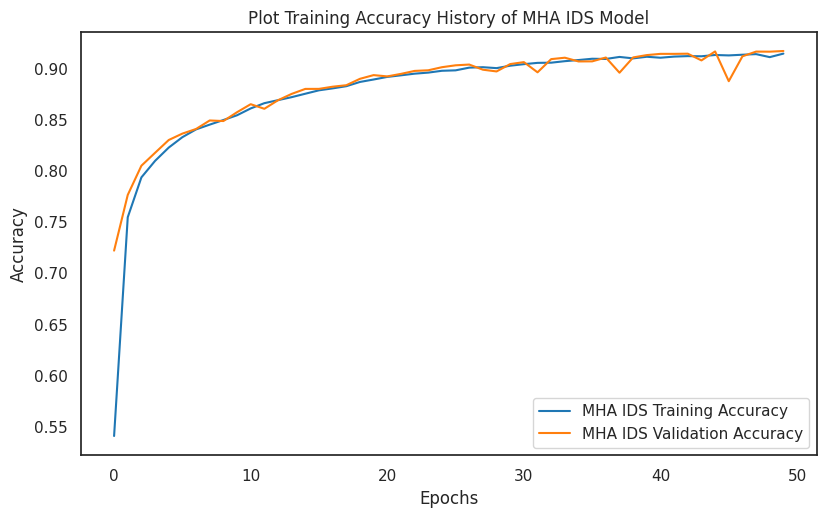

In [39]:
fig, ax = plt.subplots(1, figsize=(9.5,5.5))
plt.plot(range(EPOCHS), mha_history.history['accuracy'], color=color_pal[0], label='MHA IDS Training Accuracy')
plt.plot(range(EPOCHS), mha_history.history['val_accuracy'], color=color_pal[1], label='MHA IDS Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title("Plot Training Accuracy History of MHA IDS Model")
plt.legend()
plt.show()

#### Plot Loss History of MHA IDS Model

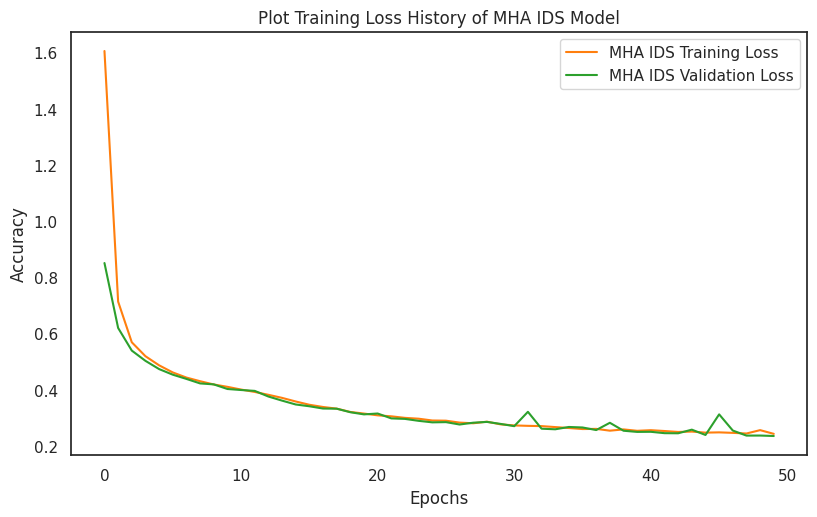

In [40]:
fig, ax = plt.subplots(1, figsize=(9.5,5.5))
plt.plot(range(EPOCHS), mha_history.history['loss'], color=color_pal[1], label='MHA IDS Training Loss')
plt.plot(range(EPOCHS), mha_history.history['val_loss'], color=color_pal[2], label='MHA IDS Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title("Plot Training Loss History of MHA IDS Model")
plt.legend()
plt.show()

#### Load Best Variant of MHA IDS Model

In [45]:
with gpu_strategy.scope():
    loaded_mha_model = load_model('/kaggle/working/mha_model_best_v1.keras')
    loaded_mha_model.summary()

Model: "MHA_IDS"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_8       │ (None, 4, 15)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_16 (Dense)    │ (None, 4, 16)     │        256 │ input_layer_8[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 4, 16)     │      1,088 │ dense_16[0][0],   │
│ (MultiHeadAttentio… │                   │            │ dense_16[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_4 (Add)         │ (None, 4, 16)     │          0 │ dense_16[0][0],   │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 4, 16)     │         32 │ add_4[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 4, 16)     │      1,088 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_5 (Add)         │ (None, 4, 16)     │          0 │ layer_normalizat… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 4, 16)     │         32 │ add_5[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 16)        │          0 │ layer_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_17 (Dense)    │ (None, 34)        │        578 │ global_average_p… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 9,224 (36.04 KB)

 Trainable params: 3,074 (12.01 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 6,150 (24.03 KB)

#### Evaluate Best Variant of MHA IDS Model

In [42]:
loaded_mha_train_metric = loaded_mha_model.evaluate(reshaped_X_train.astype('float32'), reshaped_y_train.astype('float32'), return_dict=True, batch_size=4096 * gpu_strategy.num_replicas_in_sync)
loaded_mha_test_metric = loaded_mha_model.evaluate(reshaped_X_test.astype('float32'), reshaped_y_test.astype('float32'), return_dict=True, batch_size=4096 * gpu_strategy.num_replicas_in_sync)
print(f'Accuracy during training: {round(loaded_mha_train_metric["accuracy"]*100, 2)}% and loss: {round(loaded_mha_train_metric["loss"], 4)}')
print(f'Accuracy during test: {round(loaded_mha_test_metric["accuracy"]*100, 2)}% and loss: {round(loaded_mha_test_metric["loss"], 4)}')

855/855 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.9167 - loss: 0.2359
367/367 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9165 - loss: 0.2365
Accuracy during training: 91.67% and loss: 0.2359
Accuracy during test: 91.65% and loss: 0.2365


#### Save MHA IDS Model Metrics

In [43]:
# 1. Initialize the master data structure file
registry = ModelRegistry()

registry.add_model_metrics(
    model_name="MHA_IDS",
    history_object=mha_history,
    train_eval=loaded_mha_train_metric,
    test_eval=loaded_mha_test_metric
)

# 2. Save everything into the single file
registry.save_to_disk()

# Inside your visualization notebook or function:
with open("/kaggle/working/all_network_models_report.json", "r") as f:
    metrics_data = json.load(f)

print(f'Accuracy during training: {round(metrics_data["MHA_IDS"]['final_evaluation']['train_accuracy']*100, 2)}%')
print(f'Accuracy during Validation: {round(metrics_data["MHA_IDS"]['final_evaluation']['test_accuracy']*100, 2)}%')

Successfully added 'MHA_IDS' metrics to registry container.
Master benchmark dataset written to: /kaggle/working/all_network_models_report.json
Accuracy during training: 91.67%


#### Evaluate Best MHA Using Confusion Matrix & Plot Confusion Matrix on HeatMap

184/184 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step


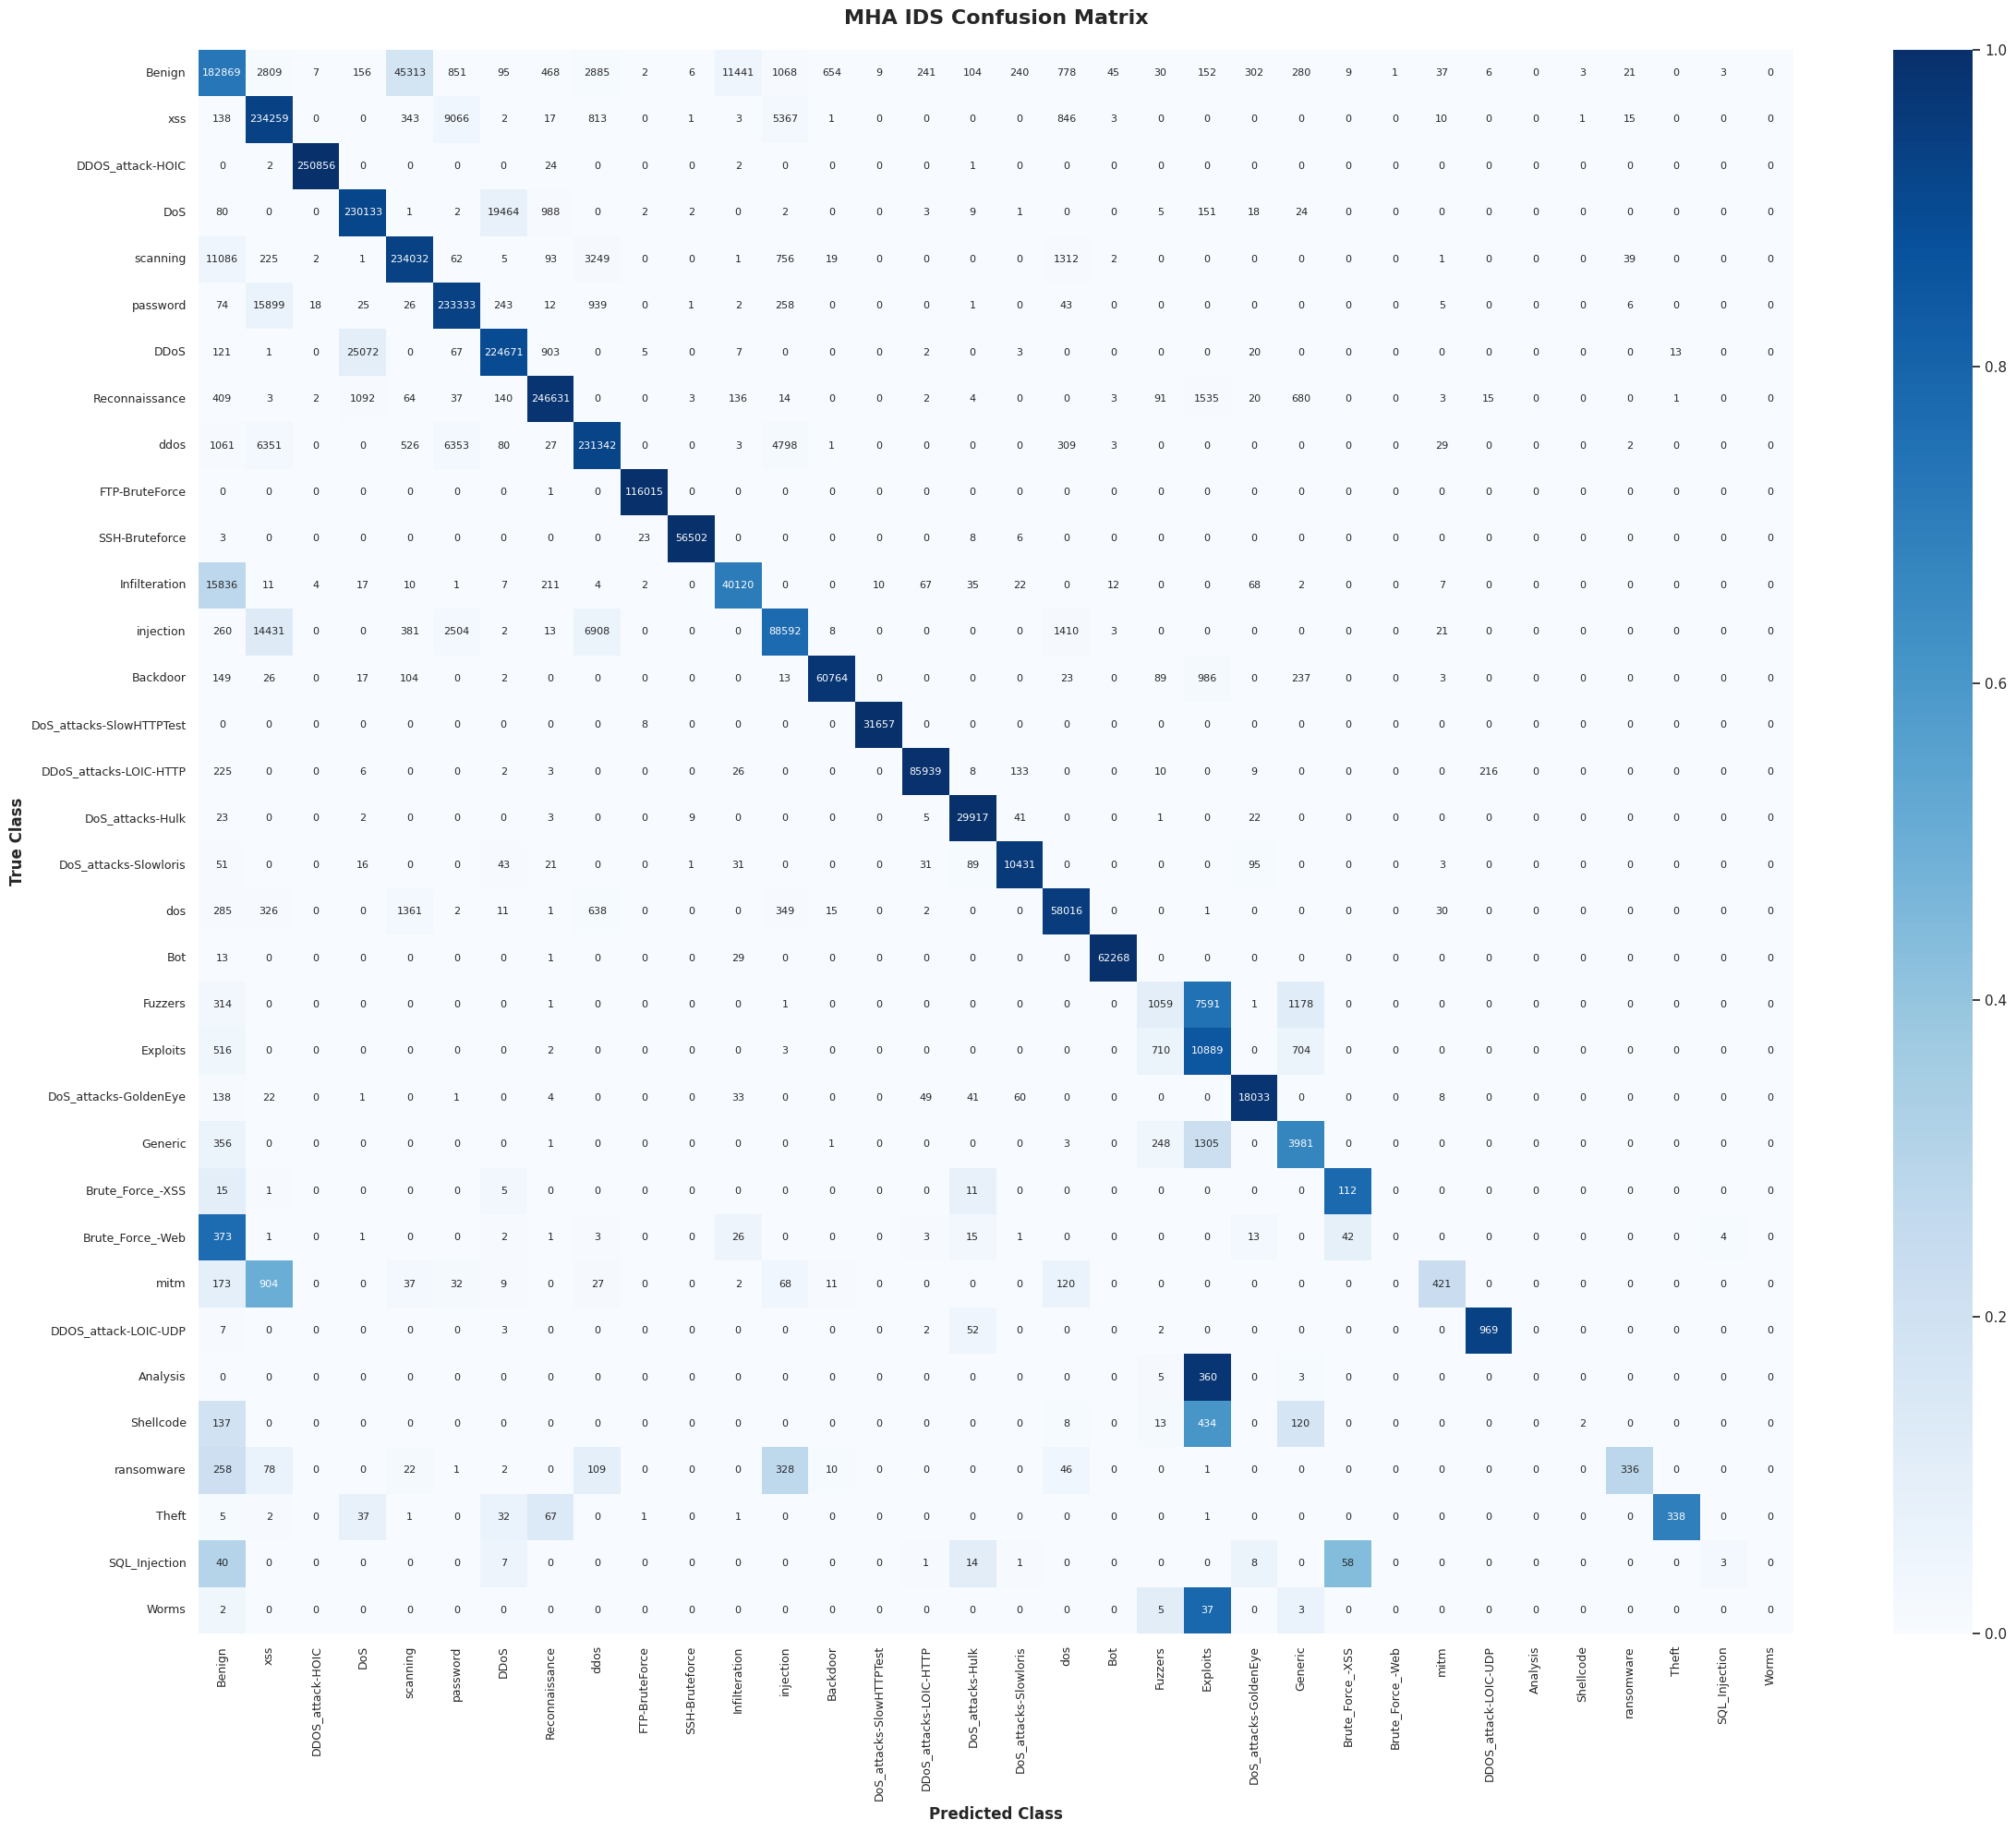

MHA IDS F1-score:  91.48%
MHA IDS Recall:    91.48%
MHA IDS Precision: 91.48%
MHA IDS AUC-ROC:   99.89%

Classification Report:


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


                         precision   recall f1-score  support
Benign                      85.05%   72.89%   78.50%   250885
xss                         85.08%   93.37%   89.03%   250885
DDOS_attack-HOIC            99.99%   99.99%   99.99%   250885
DoS                         89.69%   91.73%   90.70%   250885
scanning                    82.93%   93.28%   87.80%   250885
password                    92.48%   93.00%   92.74%   250885
DDoS                        91.77%   89.55%   90.65%   250885
Reconnaissance              98.85%   98.30%   98.58%   250885
ddos                        93.69%   92.21%   92.95%   250885
FTP-BruteForce              99.96%  100.00%   99.98%   116016
SSH-Bruteforce              99.96%   99.93%   99.94%    56542
Infilteration               77.36%   71.08%   74.08%    56446
injection                   87.18%   77.35%   81.97%   114533
Backdoor                    98.83%   97.36%   98.09%    62413
DoS_attacks-SlowHTTPTest    99.94%   99.97%   99.96%    31665
DDoS_att

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [48]:
# Ensure GPU is used for prediction
with tf.device('/GPU:0'):
    mha_y_pred_prob = loaded_mha_model.predict(reshaped_X_test, batch_size=8192 * gpu_strategy.num_replicas_in_sync)
    mha_y_pred = np.argmax(mha_y_pred_prob, axis=1)

# True labels
mha_y_true = np.argmax(reshaped_y_test, axis=1)

# ---------------------------------------------------------
# 1. HEATMAP CONFUSION MATRIX (NORMALIZED COLORS, RAW TEXT)
# ---------------------------------------------------------
# Extract the exact ordered class names from your pipeline's mapping
class_names = encoding_mappings['Attack'] 

# Calculate absolute counts (for the text inside the boxes)
raw_conf_matrix = confusion_matrix(mha_y_true, mha_y_pred)

# Calculate normalized counts by row (for the background colors)
# This calculates the Recall for each class (how many actual instances were predicted correctly)
norm_conf_matrix = confusion_matrix(mha_y_true, mha_y_pred, normalize='true')

# Plotting the Heatmap
plt.figure(figsize=(24, 20)) 
sns.heatmap(
    norm_conf_matrix,           # <-- Drives the colors (values are between 0.0 and 1.0)
    annot=raw_conf_matrix,      # <-- Prints the absolute figures inside the squares
    annot_kws={"size": 8},      
    cmap='Blues', 
    fmt='g',                    # Ensures the raw numbers print cleanly (no scientific notation)
    xticklabels=class_names, 
    yticklabels=class_names,
    vmin=0.0,                   # Locks the color bar base at 0%
    vmax=1.0                    # Locks the color bar ceiling at 100%
)

plt.title('MHA IDS Confusion Matrix', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('True Class', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Class', fontsize=12, fontweight='bold')
plt.xticks(rotation=90, fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 2. OVERALL METRICS
# ---------------------------------------------------------
mha_attention_f1 = round(f1_score(mha_y_true, mha_y_pred, average="micro") * 100, 2)
mha_attention_recall = round(recall_score(mha_y_true, mha_y_pred, average="micro") * 100, 2)
mha_attention_precision = round(precision_score(mha_y_true, mha_y_pred, average="micro") * 100, 2)
mha_attention_auc = round(roc_auc_score(mha_y_true, mha_y_pred_prob, multi_class='ovr', average="micro") * 100, 2)

print(f"MHA IDS F1-score:  {mha_attention_f1}%")
print(f"MHA IDS Recall:    {mha_attention_recall}%")
print(f"MHA IDS Precision: {mha_attention_precision}%")
print(f"MHA IDS AUC-ROC:   {mha_attention_auc}%\n")

# ---------------------------------------------------------
# 3. PERCENTAGE-BASED CLASSIFICATION REPORT WITH NAMES
# ---------------------------------------------------------
print("Classification Report:")

# Get the report as a dictionary instead of a raw string
report_dict = classification_report(mha_y_true, mha_y_pred, target_names=class_names, output_dict=True)

# Convert to Pandas DataFrame for easy manipulation
report_df = pd.DataFrame(report_dict).transpose()

# Clean up the 'accuracy' row to mimic standard sklearn visual structure
total_support = int(report_df.loc['macro avg', 'support'])
report_df.loc['accuracy', 'support'] = total_support
report_df.loc['accuracy', 'precision'] = np.nan
report_df.loc['accuracy', 'recall'] = np.nan

# Format decimals to percentages with '%' appended
metrics_cols = ['precision', 'recall', 'f1-score']
for col in metrics_cols:
    report_df[col] = report_df[col].apply(lambda x: f"{x * 100:.2f}%" if pd.notnull(x) else "")

# Ensure support remains a clean integer
report_df['support'] = report_df['support'].astype(int)

# Print the beautifully formatted DataFrame
print(report_df.to_string())

## Build Transformer 2.0 (TITAN) IDS Model

In [43]:
titan_model = build_tpu_titan_model(gpu_strategy)
titan_model_checkpoint_callback = ModelCheckpoint(
    'titan_model_best_v1.keras', monitor='val_loss', mode='min', verbose=1, 
    save_best_only=True
    )

Model: "TITAN_IDS"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━┓
┃ Layer (type)              ┃ Output Shape        ┃   Param # ┃ Tra… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━┩
│ tgat_input (InputLayer)   │ (None, 4, 15)       │         0 │  -   │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ input_feature_projection  │ (None, 4, 64)       │     1,024 │  Y   │
│ (Dense)                   │                     │           │      │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ titan_mac_block           │ (None, 4, 64)       │    50,752 │  Y   │
│ (TitanMACBlock)           │                     │           │      │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ titan_mac_block_1         │ (None, 4, 64)       │    50,752 │  Y   │
│ (TitanMACBlock)           │                     │           │      │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ global_average_pooling1d  │ (None, 64)          │         0 │  -   │
│ (GlobalAveragePooling1D)  │                     │           │      │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ dense_12 (Dense)          │ (None, 32)          │     2,080 │  Y   │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ predictions (Dense)       │ (None, 34)          │     1,122 │  Y   │
└───────────────────────────┴─────────────────────┴───────────┴──────┘

 Total params: 105,730 (413.01 KB)

 Trainable params: 105,730 (413.01 KB)

 Non-trainable params: 0 (0.00 B)

#### Train Transformer 2.0 (TITAN) IDS Model

In [44]:
titan_history = titan_model.fit(reshaped_X_train.astype('float32'), reshaped_y_train.astype('float32'), 
                                epochs = EPOCHS, 
                                validation_data=(reshaped_X_test.astype('float32'), reshaped_y_test.astype('float32')), 
                                shuffle=True, 
                                verbose=1,
                                callbacks=[titan_model_checkpoint_callback],
                                batch_size=8192 * gpu_strategy.num_replicas_in_sync) 

Epoch 1/50
INFO:tensorflow:Collective all_reduce tensors: 60 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
428/428 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step - accuracy: 0.6406 - loss: 1.1437
Epoch 1: val_loss improved from None to 0.42643, saving model to titan_model_best_v1.keras

Epoch 1: finished saving model to titan_model_best_v1.keras
428/428 ━━━━━━━━━━━━━━━━━━━━ 99s 203ms/step - accuracy: 0.7607 - loss: 0.6951 - val_accuracy: 0.8468 - val_loss: 0.4264
Epoch 2/50
428/428 ━━━━━━━━━━━━━━━━━━━━ 0s 173ms/step - accuracy: 0.8474 - loss: 0.4154
Epoch 2: val_loss improved from 0.42643 to 0.37399, saving model to titan_model_best_v1.keras

Epoch 2: finished saving model to titan_model_best_v1.keras
428/428 ━━━━━━━━━━━━━━━━━━━━ 83s 192ms/step - accuracy: 0.8544 - loss: 0.3983 - val_accuracy: 0.8599 - val_loss: 0.3740
Epoch 3/50
428/428 ━━━━━━━━━━━━━━━━━━━━ 0s 173ms/step - accuracy: 0.8740 - loss: 0.3420
Epoch 3: val_loss improved f

#### Plot Training and Validation History for TITAN IDS Model

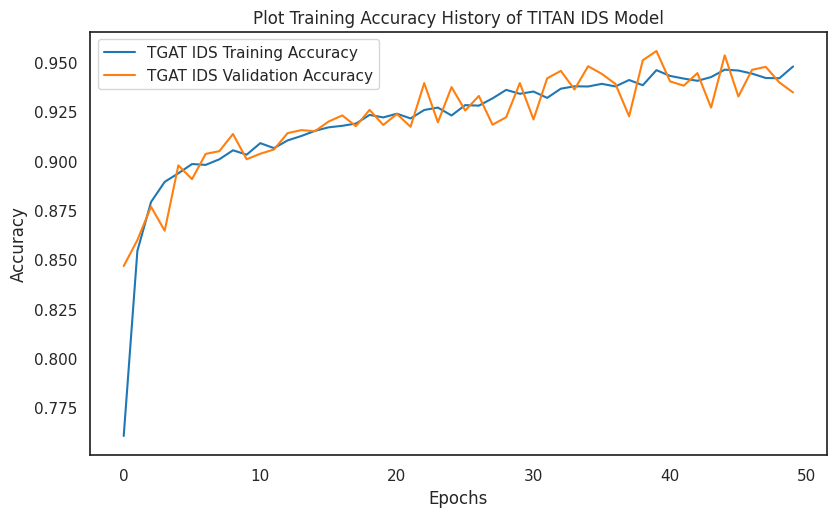

In [47]:
fig, ax = plt.subplots(1, figsize=(9.5,5.5))
plt.plot(range(EPOCHS), titan_history.history['accuracy'], color=color_pal[0], label='TGAT IDS Training Accuracy')
plt.plot(range(EPOCHS), titan_history.history['val_accuracy'], color=color_pal[1], label='TGAT IDS Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title("Plot Training Accuracy History of TITAN IDS Model")
plt.legend()
plt.show()

#### Plot Loss History of TITAN IDS Model

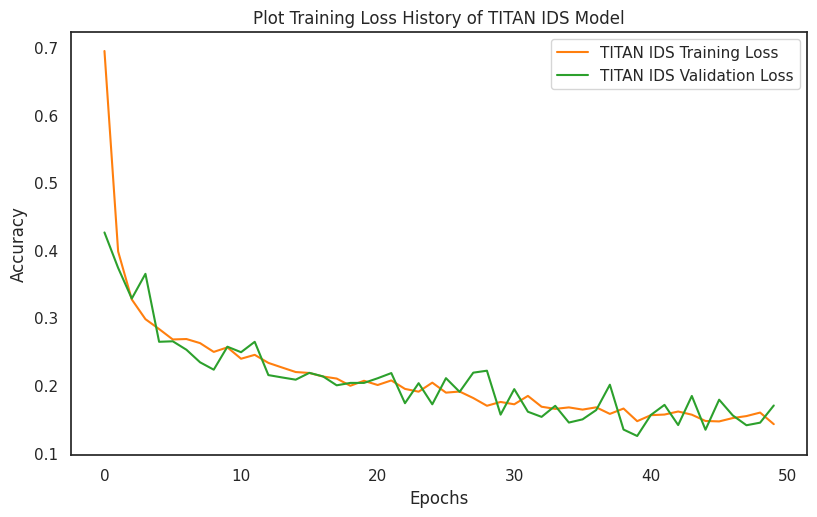

In [48]:
fig, ax = plt.subplots(1, figsize=(9.5,5.5))
plt.plot(range(EPOCHS), titan_history.history['loss'], color=color_pal[1], label='TITAN IDS Training Loss')
plt.plot(range(EPOCHS), titan_history.history['val_loss'], color=color_pal[2], label='TITAN IDS Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title("Plot Training Loss History of TITAN IDS Model")
plt.legend()
plt.show()

#### Load Best Variant TITAN IDS Model

In [52]:
with gpu_strategy.scope():
    loaded_titan_model = load_model('/kaggle/working/titan_model_best_v1.keras')
    loaded_titan_model.summary()

Model: "TITAN_IDS"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ tgat_input (InputLayer)         │ (None, 4, 15)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ input_feature_projection        │ (None, 4, 64)          │         1,024 │
│ (Dense)                         │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ titan_mac_block (TitanMACBlock) │ (None, 4, 64)          │        50,752 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ titan_mac_block_1               │ (None, 4, 64)          │        50,752 │
│ (TitanMACBlock)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 34)             │         1,122 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 317,192 (1.21 MB)

 Trainable params: 105,730 (413.01 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 211,462 (826.03 KB)

#### Evaluate Best Variant of TITAN IDS Model

In [50]:
loaded_titan_train_metric = loaded_titan_model.evaluate(reshaped_X_train.astype('float32'), reshaped_y_train.astype('float32'), return_dict=True, batch_size=4096 * gpu_strategy.num_replicas_in_sync)
loaded_titan_test_metric = loaded_titan_model.evaluate(reshaped_X_test.astype('float32'), reshaped_y_test.astype('float32'), return_dict=True, batch_size=4096 * gpu_strategy.num_replicas_in_sync)
print(f'Accuracy during training: {round(loaded_titan_train_metric["accuracy"]*100, 2)}% and loss: {round(loaded_titan_train_metric["loss"], 4)}')
print(f'Accuracy during test: {round(loaded_titan_test_metric["accuracy"]*100, 2)}% and loss: {round(loaded_titan_test_metric["loss"], 4)}')

855/855 ━━━━━━━━━━━━━━━━━━━━ 22s 23ms/step - accuracy: 0.9560 - loss: 0.1241
367/367 ━━━━━━━━━━━━━━━━━━━━ 9s 23ms/step - accuracy: 0.9557 - loss: 0.1251
Accuracy during training: 95.6% and loss: 0.1241
Accuracy during test: 95.57% and loss: 0.1251


#### Save TITAN IDS Model Metrics

In [53]:
# 1. Initialize the master data structure file
registry = ModelRegistry()

registry.add_model_metrics(
    model_name="TITAN_IDS",
    history_object=titan_history,
    train_eval=loaded_titan_train_metric,
    test_eval=loaded_titan_test_metric
)

# 2. Save everything into the single file
registry.save_to_disk()

# Inside your visualization notebook or function:
with open("/kaggle/working/all_network_models_report.json", "r") as f:
    metrics_data = json.load(f)

print(f'Accuracy during training: {round(metrics_data["TITAN_IDS"]['final_evaluation']['train_accuracy']*100, 2)}%')
print(f'Accuracy during validation: {round(metrics_data["TITAN_IDS"]['final_evaluation']['test_accuracy']*100, 2)}%')

Successfully added 'TITAN_IDS' metrics to registry container.
Master benchmark dataset written to: /kaggle/working/all_network_models_report.json
Accuracy during training: 95.6%


#### Evaluate Best TITAN Using Confusion Matrix & Plot Confusion Matrix on HeatMap

184/184 ━━━━━━━━━━━━━━━━━━━━ 10s 46ms/step


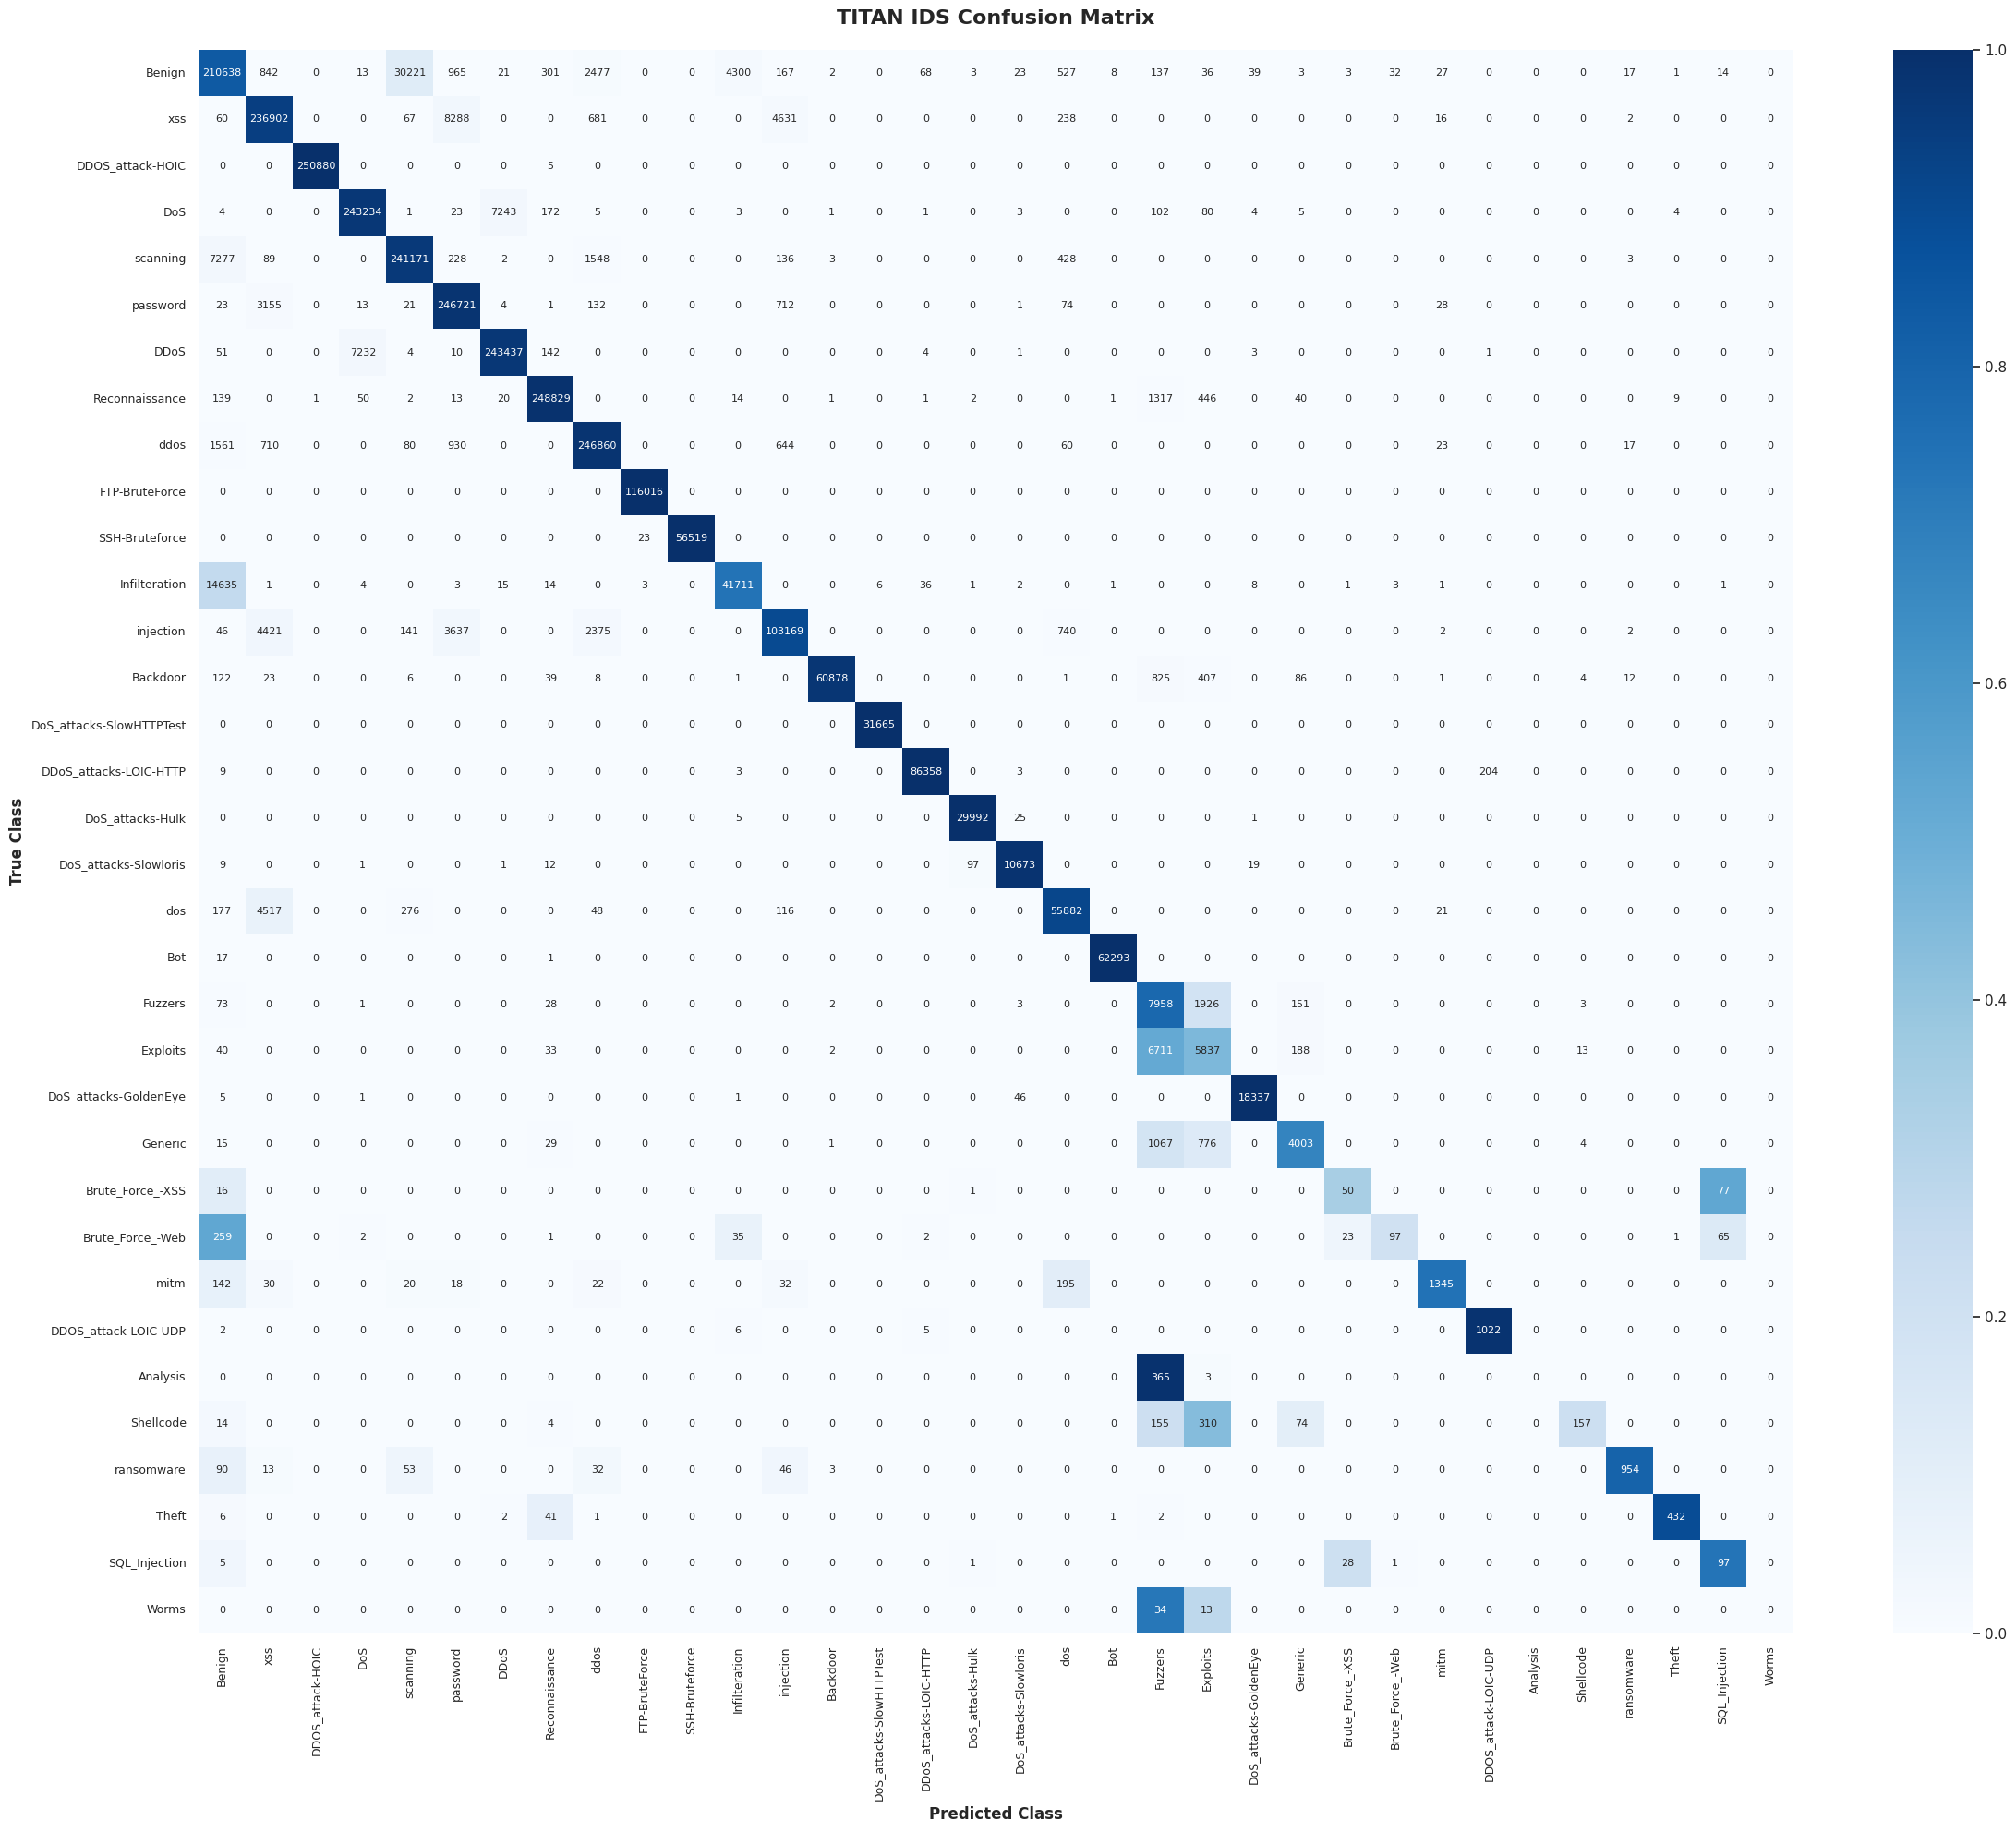

TITAN IDS F1-score:  95.47%
TITAN IDS Recall:    95.47%
TITAN IDS Precision: 95.47%
TITAN IDS AUC-ROC:   99.97%

Classification Report:


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


                         precision   recall f1-score  support
Benign                      89.47%   83.96%   86.63%   250885
xss                         94.50%   94.43%   94.46%   250885
DDOS_attack-HOIC           100.00%  100.00%  100.00%   250885
DoS                         97.08%   96.95%   97.01%   250885
scanning                    88.65%   96.13%   92.24%   250885
password                    94.59%   98.34%   96.43%   250885
DDoS                        97.09%   97.03%   97.06%   250885
Reconnaissance              99.67%   99.18%   99.42%   250885
ddos                        97.12%   98.40%   97.75%   250885
FTP-BruteForce              99.98%  100.00%   99.99%   116016
SSH-Bruteforce             100.00%   99.96%   99.98%    56542
Infilteration               90.52%   73.90%   81.37%    56446
injection                   94.09%   90.08%   92.04%   114533
Backdoor                    99.98%   97.54%   98.74%    62413
DoS_attacks-SlowHTTPTest    99.98%  100.00%   99.99%    31665
DDoS_att

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [53]:
# Ensure GPU is used for prediction
with tf.device('/GPU:0'):
    titan_y_pred_prob = loaded_titan_model.predict(reshaped_X_test, batch_size=8192 * gpu_strategy.num_replicas_in_sync)
    titan_y_pred = np.argmax(titan_y_pred_prob, axis=1)

# True labels
titan_y_true = np.argmax(reshaped_y_test, axis=1)

# ---------------------------------------------------------
# 1. HEATMAP CONFUSION MATRIX (NORMALIZED COLORS, RAW TEXT)
# ---------------------------------------------------------
# Extract the exact ordered class names from your pipeline's mapping
class_names = encoding_mappings['Attack'] 

# Calculate absolute counts (for the text inside the boxes)
raw_conf_matrix = confusion_matrix(titan_y_true, titan_y_pred)

# Calculate normalized counts by row (for the background colors)
# This calculates the Recall for each class (how many actual instances were predicted correctly)
norm_conf_matrix = confusion_matrix(titan_y_true, titan_y_pred, normalize='true')

# Plotting the Heatmap
plt.figure(figsize=(24, 20)) 
sns.heatmap(
    norm_conf_matrix,           # <-- Drives the colors (values are between 0.0 and 1.0)
    annot=raw_conf_matrix,      # <-- Prints the absolute figures inside the squares
    annot_kws={"size": 8},      
    cmap='Blues', 
    fmt='g',                    # Ensures the raw numbers print cleanly (no scientific notation)
    xticklabels=class_names, 
    yticklabels=class_names,
    vmin=0.0,                   # Locks the color bar base at 0%
    vmax=1.0                    # Locks the color bar ceiling at 100%
)

plt.title('TITAN IDS Confusion Matrix', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('True Class', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Class', fontsize=12, fontweight='bold')
plt.xticks(rotation=90, fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 2. OVERALL METRICS
# ---------------------------------------------------------
titan_attention_f1 = round(f1_score(titan_y_true, titan_y_pred, average="micro") * 100, 2)
titan_attention_recall = round(recall_score(titan_y_true, titan_y_pred, average="micro") * 100, 2)
titan_attention_precision = round(precision_score(titan_y_true, titan_y_pred, average="micro") * 100, 2)
titan_attention_auc = round(roc_auc_score(titan_y_true, titan_y_pred_prob, multi_class='ovr', average="micro") * 100, 2)

print(f"TITAN IDS F1-score:  {titan_attention_f1}%")
print(f"TITAN IDS Recall:    {titan_attention_recall}%")
print(f"TITAN IDS Precision: {titan_attention_precision}%")
print(f"TITAN IDS AUC-ROC:   {titan_attention_auc}%\n")

# ---------------------------------------------------------
# 3. PERCENTAGE-BASED CLASSIFICATION REPORT WITH NAMES
# ---------------------------------------------------------
print("Classification Report:")

# Get the report as a dictionary instead of a raw string
report_dict = classification_report(titan_y_true, titan_y_pred, target_names=class_names, output_dict=True)

# Convert to Pandas DataFrame for easy manipulation
report_df = pd.DataFrame(report_dict).transpose()

# Clean up the 'accuracy' row to mimic standard sklearn visual structure
total_support = int(report_df.loc['macro avg', 'support'])
report_df.loc['accuracy', 'support'] = total_support
report_df.loc['accuracy', 'precision'] = np.nan
report_df.loc['accuracy', 'recall'] = np.nan

# Format decimals to percentages with '%' appended
metrics_cols = ['precision', 'recall', 'f1-score']
for col in metrics_cols:
    report_df[col] = report_df[col].apply(lambda x: f"{x * 100:.2f}%" if pd.notnull(x) else "")

# Ensure support remains a clean integer
report_df['support'] = report_df['support'].astype(int)

# Print the beautifully formatted DataFrame
print(report_df.to_string())

## Build Transformer AD (TranAD) IDS Model

In [16]:
tranAD_model = build_tpu_tranAD_model(gpu_strategy)
tranAD_model_checkpoint_callback = ModelCheckpoint(
    'tranAD_model_best_v1.keras', monitor='val_loss', mode='min', verbose=1, 
    save_best_only=True
    )

Model: "TranAD_IDS"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━┓
┃ Layer (type)              ┃ Output Shape        ┃   Param # ┃ Tra… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━┩
│ input_layer (InputLayer)  │ (None, 4, 15)       │         0 │  -   │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ feature_projection        │ (None, 4, 32)       │       512 │  Y   │
│ (Dense)                   │                     │           │      │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ positional_injection      │ (None, 4, 32)       │         0 │  -   │
│ (PositionalEncoding)      │                     │           │      │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ transformer_encoder_bloc… │ (None, 4, 32)       │     8,544 │  Y   │
│ (TransformerEncoderBlock) │                     │           │      │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ transformer_encoder_bloc… │ (None, 4, 32)       │     8,544 │  Y   │
│ (TransformerEncoderBlock) │                     │           │      │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ transformer_encoder_bloc… │ (None, 4, 32)       │     8,544 │  Y   │
│ (TransformerEncoderBlock) │                     │           │      │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ temporal_pooling          │ (None, 32)          │         0 │  -   │
│ (GlobalAveragePooling1D)  │                     │           │      │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ classification_head       │ (None, 34)          │     1,122 │  Y   │
│ (Dense)                   │                     │           │      │
└───────────────────────────┴─────────────────────┴───────────┴──────┘

 Total params: 27,266 (106.51 KB)

 Trainable params: 27,266 (106.51 KB)

 Non-trainable params: 0 (0.00 B)

#### Train Transformer AD (TranAD) IDS Model

In [18]:
tranAD_history = tranAD_model.fit(reshaped_X_train.astype('float32'), reshaped_y_train.astype('float32'), 
                                epochs = EPOCHS, 
                                validation_data=(reshaped_X_test.astype('float32'), reshaped_y_test.astype('float32')), 
                                shuffle=True, 
                                verbose=1,
                                callbacks=[tranAD_model_checkpoint_callback],
                                batch_size=8192 * gpu_strategy.num_replicas_in_sync) 

INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Redu

#### Plot Trainin & Validation History of TranAD IDS Model

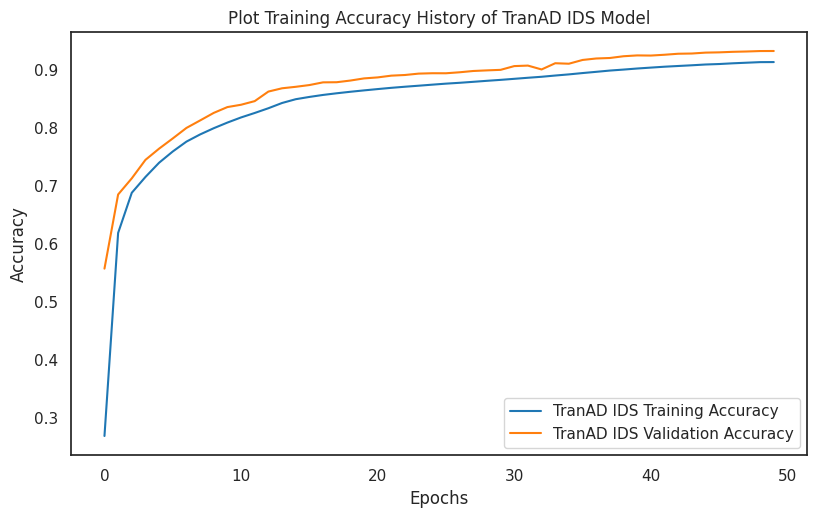

In [19]:
dfig, ax = plt.subplots(1, figsize=(9.5,5.5))
plt.plot(range(EPOCHS), tranAD_history.history['accuracy'], color=color_pal[0], label='TranAD IDS Training Accuracy')
plt.plot(range(EPOCHS), tranAD_history.history['val_accuracy'], color=color_pal[1], label='TranAD IDS Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title("Plot Training Accuracy History of TranAD IDS Model")
plt.legend()
plt.show()

#### Plot Loss History of TranAD IDS Model

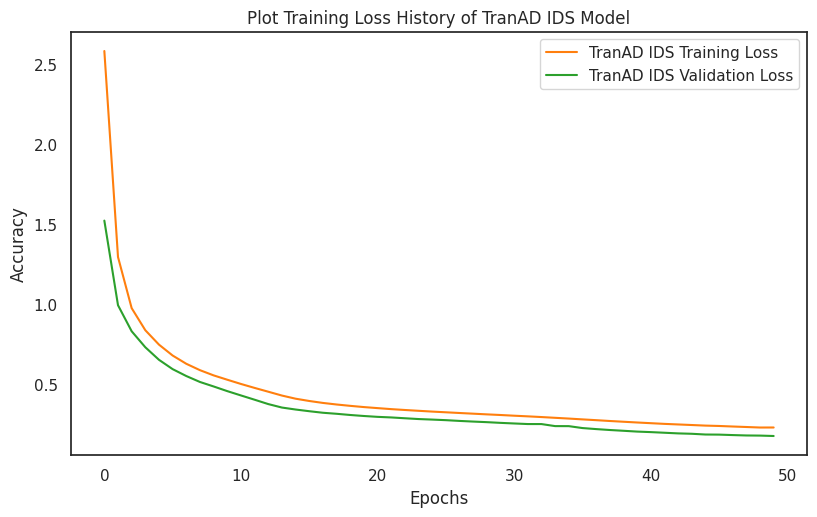

In [20]:
fig, ax = plt.subplots(1, figsize=(9.5,5.5))
plt.plot(range(EPOCHS), tranAD_history.history['loss'], color=color_pal[1], label='TranAD IDS Training Loss')
plt.plot(range(EPOCHS), tranAD_history.history['val_loss'], color=color_pal[2], label='TranAD IDS Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title("Plot Training Loss History of TranAD IDS Model")
plt.legend()
plt.show()

#### Load Best Variant of TranAD IDS Model

In [56]:
with gpu_strategy.scope():
    loaded_tranAD_model = load_model('/kaggle/working/tranAD_model_best_v1.keras')
    loaded_tranAD_model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'transformer_encoder_block_1', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'transformer_encoder_block_2', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'transform

Model: "TranAD_IDS"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 4, 15)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ feature_projection (Dense)      │ (None, 4, 32)          │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ positional_injection            │ (None, 4, 32)          │             0 │
│ (PositionalEncoding)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_encoder_block_1     │ (None, 4, 32)          │         8,544 │
│ (TransformerEncoderBlock)       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_encoder_block_2     │ (None, 4, 32)          │         8,544 │
│ (TransformerEncoderBlock)       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_encoder_block_3     │ (None, 4, 32)          │         8,544 │
│ (TransformerEncoderBlock)       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ temporal_pooling                │ (None, 32)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classification_head (Dense)     │ (None, 34)             │         1,122 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 81,800 (319.54 KB)

 Trainable params: 27,266 (106.51 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 54,534 (213.03 KB)

#### Evaluate Best Variant of TranAD IDS Model

In [22]:
loaded_tranAD_train_metric = loaded_tranAD_model.evaluate(reshaped_X_train.astype('float32'), reshaped_y_train.astype('float32'), return_dict=True, batch_size=4096 * gpu_strategy.num_replicas_in_sync)
loaded_tranAD_test_metric = loaded_tranAD_model.evaluate(reshaped_X_test.astype('float32'), reshaped_y_test.astype('float32'), return_dict=True, batch_size=4096 * gpu_strategy.num_replicas_in_sync)
print(f'Accuracy during training: {round(loaded_tranAD_train_metric["accuracy"]*100, 2)}% and loss: {round(loaded_tranAD_train_metric["loss"], 4)}')
print(f'Accuracy during test: {round(loaded_tranAD_test_metric["accuracy"]*100, 2)}% and loss: {round(loaded_tranAD_test_metric["loss"], 4)}')

855/855 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - accuracy: 0.9324 - loss: 0.1785
367/367 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.9323 - loss: 0.1787
Accuracy during training: 93.24% and loss: 0.1785
Accuracy during test: 93.23% and loss: 0.1787


#### Save TranAD IDS Model Metrics

In [24]:
# 1. Initialize the master data structure file
registry = ModelRegistry()

registry.add_model_metrics(
    model_name="TranAD_IDS",
    history_object=tranAD_history,
    train_eval=loaded_tranAD_train_metric,
    test_eval=loaded_tranAD_test_metric
)

# 2. Save everything into the single file
registry.save_to_disk()

# Inside your visualization notebook or function:
with open("/kaggle/working/all_network_models_report.json", "r") as f:
    metrics_data = json.load(f)

print(f'Accuracy during training: {round(metrics_data["TranAD_IDS"]['final_evaluation']['train_accuracy']*100, 2)}%')

Successfully added 'TranAD_IDS' metrics to registry container.
Master benchmark dataset written to: /kaggle/working/all_network_models_report.json
Accuracy during training: 93.24%


#### Evaluate Best TranAD Using Confusion Matrix & Plot Confusion Matrix on HeatMap

184/184 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step


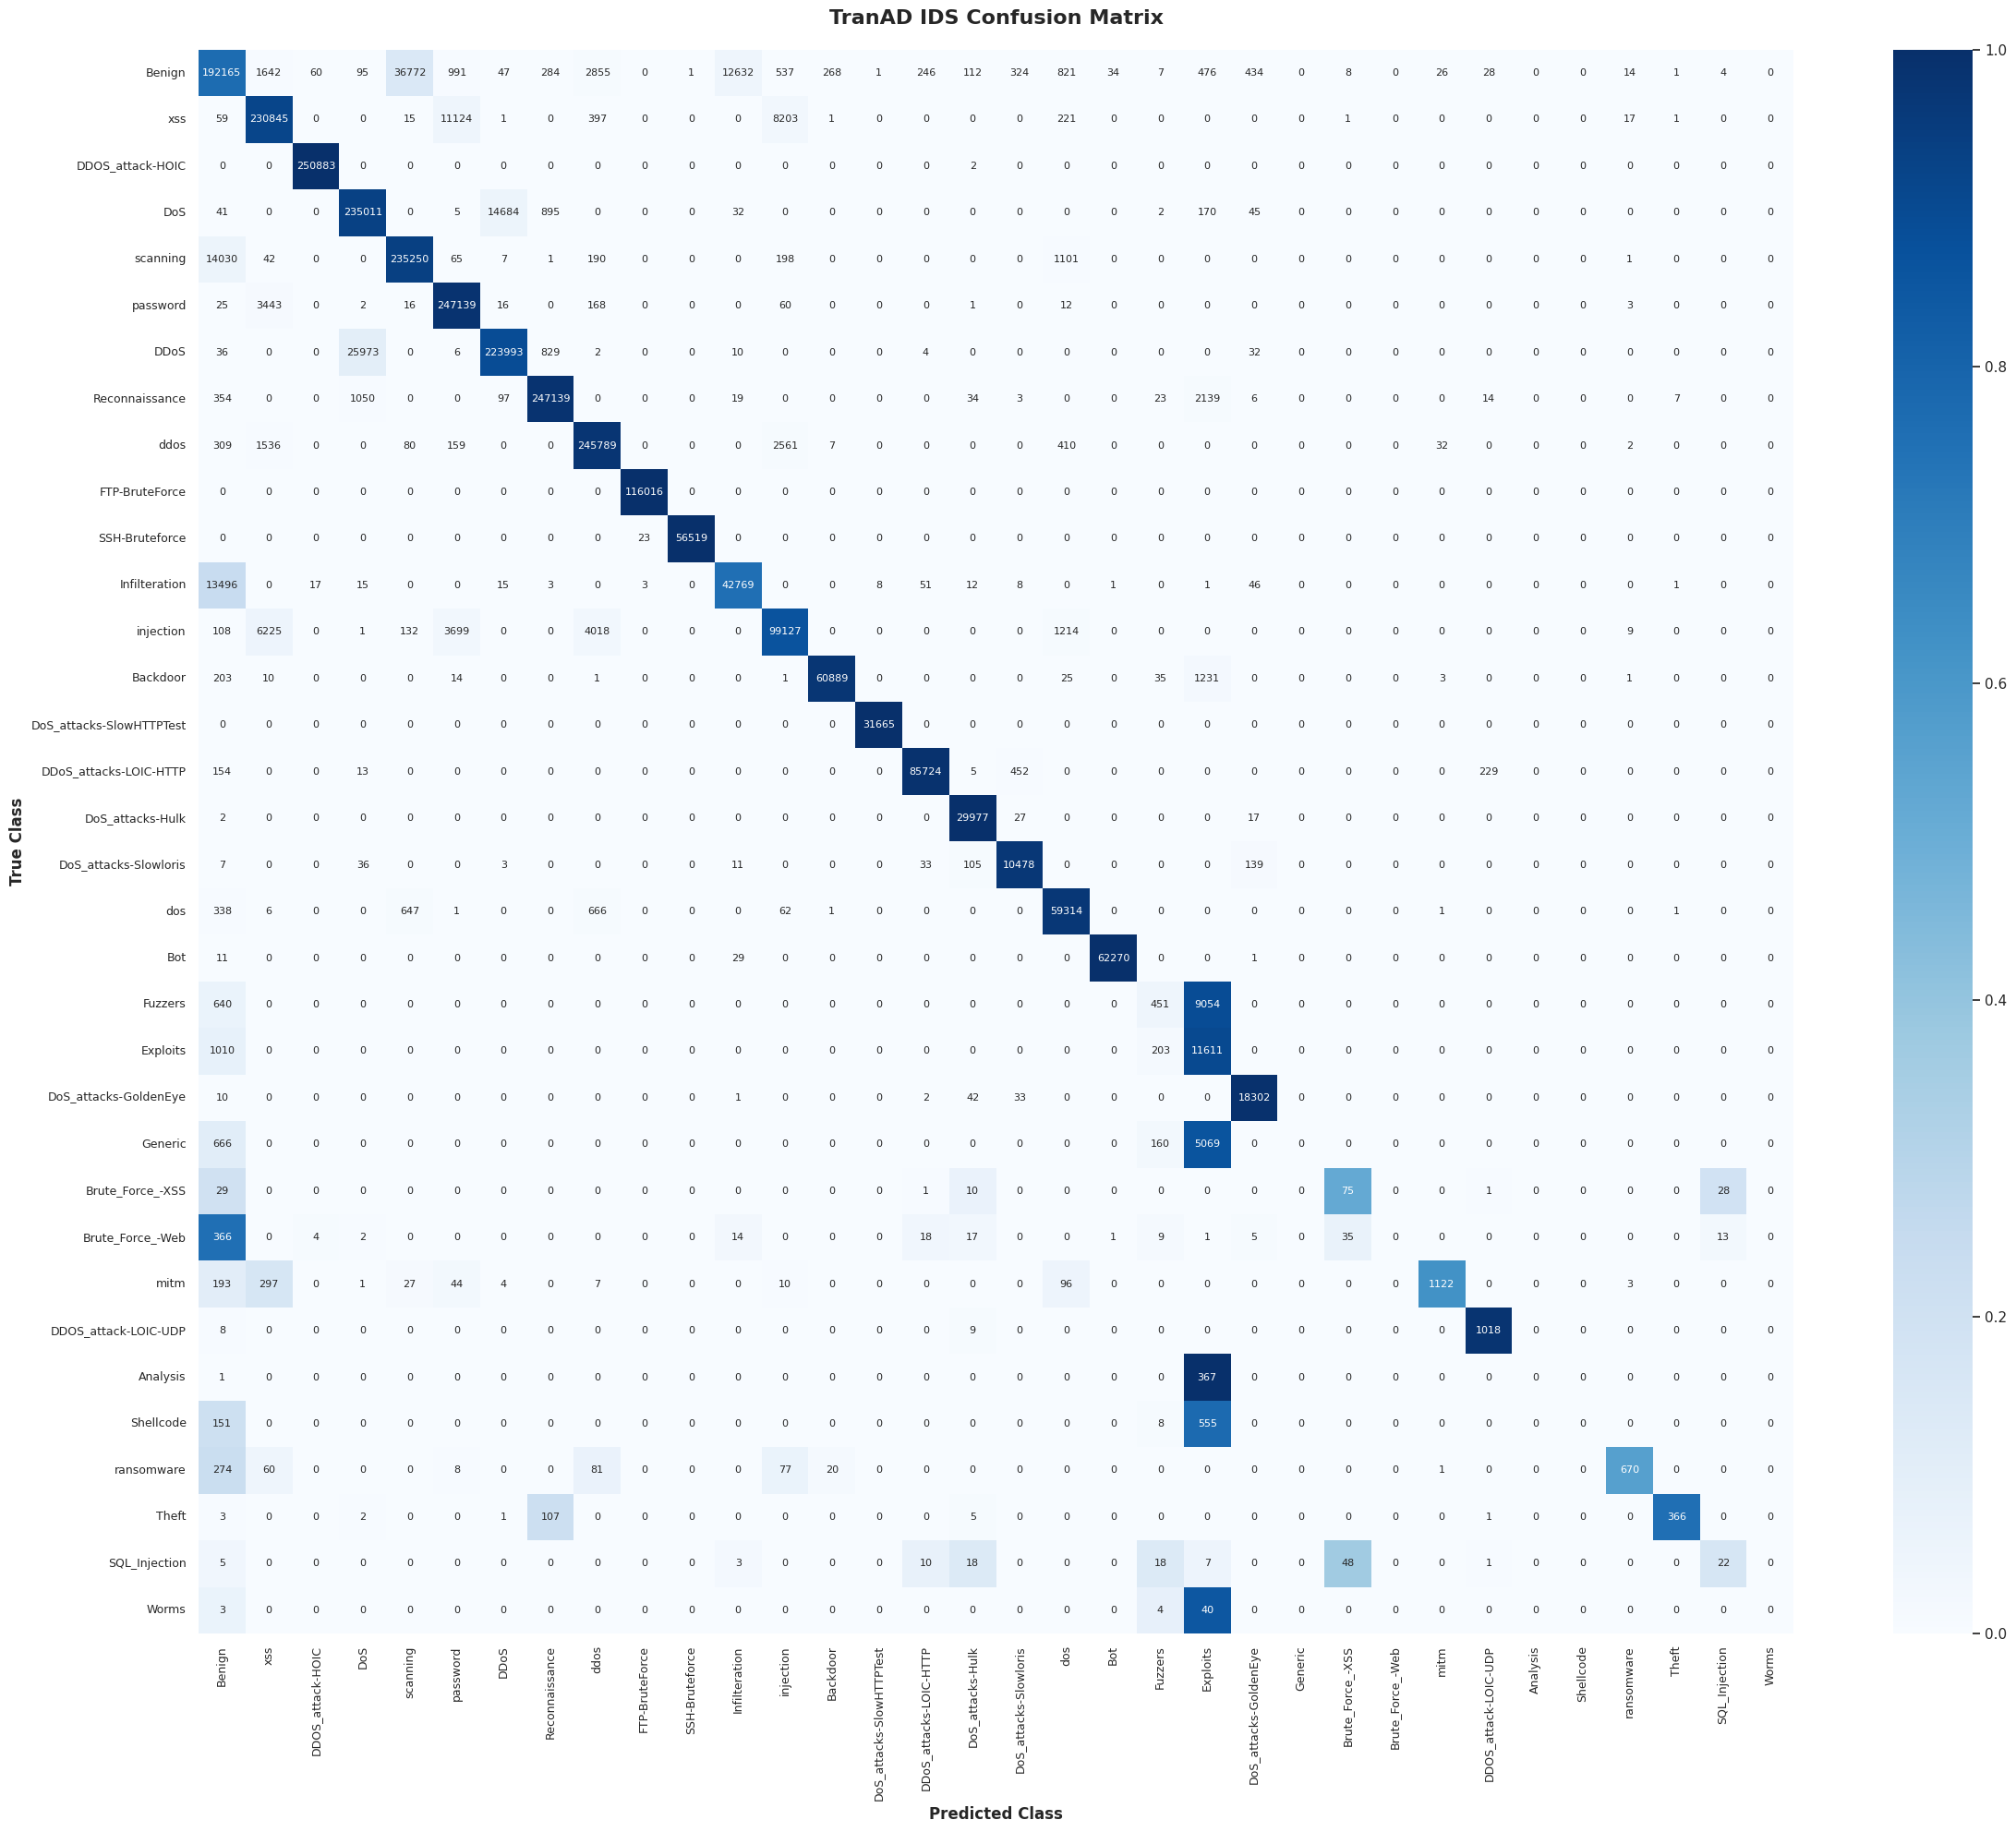

TranAD IDS F1-score:  93.22%
TranAD IDS Recall:    93.22%
TranAD IDS Precision: 93.22%
TranAD IDS AUC-ROC:   99.94%

Classification Report:


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


                         precision   recall f1-score  support
Benign                      85.05%   72.89%   78.50%   250885
xss                         85.08%   93.37%   89.03%   250885
DDOS_attack-HOIC            99.99%   99.99%   99.99%   250885
DoS                         89.69%   91.73%   90.70%   250885
scanning                    82.93%   93.28%   87.80%   250885
password                    92.48%   93.00%   92.74%   250885
DDoS                        91.77%   89.55%   90.65%   250885
Reconnaissance              98.85%   98.30%   98.58%   250885
ddos                        93.69%   92.21%   92.95%   250885
FTP-BruteForce              99.96%  100.00%   99.98%   116016
SSH-Bruteforce              99.96%   99.93%   99.94%    56542
Infilteration               77.36%   71.08%   74.08%    56446
injection                   87.18%   77.35%   81.97%   114533
Backdoor                    98.83%   97.36%   98.09%    62413
DoS_attacks-SlowHTTPTest    99.94%   99.97%   99.96%    31665
DDoS_att

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [57]:
# Ensure GPU is used for prediction
with tf.device('/GPU:0'):
    tranAD_y_pred_prob = loaded_tranAD_model.predict(reshaped_X_test, batch_size=8192 * gpu_strategy.num_replicas_in_sync)
    tranAD_y_pred = np.argmax(tranAD_y_pred_prob, axis=1)

# True labels
tranAD_y_true = np.argmax(reshaped_y_test, axis=1)

# ---------------------------------------------------------
# 1. HEATMAP CONFUSION MATRIX (NORMALIZED COLORS, RAW TEXT)
# ---------------------------------------------------------
# Extract the exact ordered class names from your pipeline's mapping
class_names = encoding_mappings['Attack'] 

# Calculate absolute counts (for the text inside the boxes)
raw_conf_matrix = confusion_matrix(tranAD_y_true, tranAD_y_pred)

# Calculate normalized counts by row (for the background colors)
# This calculates the Recall for each class (how many actual instances were predicted correctly)
norm_conf_matrix = confusion_matrix(tranAD_y_true, tranAD_y_pred, normalize='true')

# Plotting the Heatmap
plt.figure(figsize=(24, 20)) 
sns.heatmap(
    norm_conf_matrix,           # <-- Drives the colors (values are between 0.0 and 1.0)
    annot=raw_conf_matrix,      # <-- Prints the absolute figures inside the squares
    annot_kws={"size": 8},      
    cmap='Blues', 
    fmt='g',                    # Ensures the raw numbers print cleanly (no scientific notation)
    xticklabels=class_names, 
    yticklabels=class_names,
    vmin=0.0,                   # Locks the color bar base at 0%
    vmax=1.0                    # Locks the color bar ceiling at 100%
)

plt.title('TranAD IDS Confusion Matrix', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('True Class', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Class', fontsize=12, fontweight='bold')
plt.xticks(rotation=90, fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 2. OVERALL METRICS
# ---------------------------------------------------------
tranAD_attention_f1 = round(f1_score(tranAD_y_true, tranAD_y_pred, average="micro") * 100, 2)
tranAD_attention_recall = round(recall_score(tranAD_y_true, tranAD_y_pred, average="micro") * 100, 2)
tranAD_attention_precision = round(precision_score(tranAD_y_true, tranAD_y_pred, average="micro") * 100, 2)
tranAD_attention_auc = round(roc_auc_score(tranAD_y_true, tranAD_y_pred_prob, multi_class='ovr', average="micro") * 100, 2)

print(f"TranAD IDS F1-score:  {tranAD_attention_f1}%")
print(f"TranAD IDS Recall:    {tranAD_attention_recall}%")
print(f"TranAD IDS Precision: {tranAD_attention_precision}%")
print(f"TranAD IDS AUC-ROC:   {tranAD_attention_auc}%\n")

# ---------------------------------------------------------
# 3. PERCENTAGE-BASED CLASSIFICATION REPORT WITH NAMES
# ---------------------------------------------------------
print("Classification Report:")

# Get the report as a dictionary instead of a raw string
report_dict = classification_report(mha_y_true, mha_y_pred, target_names=class_names, output_dict=True)

# Convert to Pandas DataFrame for easy manipulation
report_df = pd.DataFrame(report_dict).transpose()

# Clean up the 'accuracy' row to mimic standard sklearn visual structure
total_support = int(report_df.loc['macro avg', 'support'])
report_df.loc['accuracy', 'support'] = total_support
report_df.loc['accuracy', 'precision'] = np.nan
report_df.loc['accuracy', 'recall'] = np.nan

# Format decimals to percentages with '%' appended
metrics_cols = ['precision', 'recall', 'f1-score']
for col in metrics_cols:
    report_df[col] = report_df[col].apply(lambda x: f"{x * 100:.2f}%" if pd.notnull(x) else "")

# Ensure support remains a clean integer
report_df['support'] = report_df['support'].astype(int)

# Print the beautifully formatted DataFrame
print(report_df.to_string())

## Prepare and Extract Stratified Dataset for TGAT Model using Selected Features Based on User Constraints

In [20]:
def run_threshold_netflow_tgat_pipeline(parquet_path, total_rows=10_000_000, threshold_pct=0.10, sequence_length=4, train_ratio=0.7):
    # 1. Scan the raw parquet file lazily and immediately inject a synthetic global sequence index
    lf = pl.scan_parquet(parquet_path).with_row_index("synthetic_seq_id")
    
    structural_cols = [
        'IPV4_SRC_ADDR', 'IPV4_DST_ADDR', 
        'FLOW_START_MILLISECONDS', 'FLOW_END_MILLISECONDS', 'synthetic_seq_id'
    ]
    
    # Model features now contain ONLY continuous flow metrics
    model_features = [
        'L4_DST_PORT', 'FLOW_DURATION_MILLISECONDS', 
        'DURATION_IN', 'SHORTEST_FLOW_PKT', 'TCP_WIN_MAX_IN', 'TCP_WIN_MAX_OUT', 
        'SRC_TO_DST_IAT_MIN', 'SRC_TO_DST_IAT_MAX', 'SRC_TO_DST_IAT_AVG', 
        'DST_TO_SRC_IAT_AVG', 'DST_TO_SRC_IAT_STDDEV'
    ]
    
    target_col = 'Attack'
    categorical_cols = ['IPV4_SRC_ADDR', 'IPV4_DST_ADDR', 'Attack']
    
    # ----------------------------------------------------
    # STEP 1: LAZY ENCODING & SAFE DOWNCASTING
    # ----------------------------------------------------
    print("Preparing lazy encoding and safe downcasting...")
    encoding_mappings = {}
    encoding_expressions = []
    
    for col in categorical_cols:
        unique_vals = lf.select(pl.col(col).unique()).collect()[col].to_list()
        encoding_mappings[col] = unique_vals
        
        expr = pl.col(col).replace_strict(
            old=unique_vals, 
            new=list(range(len(unique_vals))), 
            default=None
        ).cast(pl.Int32).alias(col)
        encoding_expressions.append(expr)
        
    lf_schema = lf.collect_schema()
    numeric_cols = [c for c in (structural_cols + model_features) if c not in categorical_cols]
    
    downcast_expressions = []
    for c in numeric_cols:
        if c in ['FLOW_START_MILLISECONDS', 'FLOW_END_MILLISECONDS']:
            downcast_expressions.append(pl.col(c).cast(pl.Int64).alias(c))
        elif lf_schema[c] == pl.Float64:
            downcast_expressions.append(pl.col(c).cast(pl.Float32).alias(c))
        else:
            downcast_expressions.append(pl.col(c).cast(pl.Int32).alias(c))
            
    encoded_lazy_df = lf.with_columns(encoding_expressions + downcast_expressions)

    # ----------------------------------------------------
    # STEP 2: TEMPORAL GRAPH WINDOWING (The "Skipper")
    # ----------------------------------------------------
    print("Mapping temporal windows (incomplete sequences will be automatically skipped)...")
    expressions = []
    for i in range(sequence_length):
        suffix = f"_tminus_{i}" if i > 0 else "_now"
        for col in model_features:
            # Added order_by to guarantee chronological shifting per IP address
            expressions.append(
                pl.col(col).shift(i).over("IPV4_SRC_ADDR", order_by="FLOW_START_MILLISECONDS").alias(f"{col}{suffix}")
            )
            
        if i > 0:
            expressions.append(
                (pl.col("FLOW_START_MILLISECONDS") - pl.col("FLOW_START_MILLISECONDS").shift(i).over("IPV4_SRC_ADDR", order_by="FLOW_START_MILLISECONDS"))
                .fill_null(0.0)
                .cast(pl.Float32)
                .alias(f"time_delta_tminus_{i}")
            )
        else:
            expressions.append(pl.lit(0.0, dtype=pl.Float32).alias("time_delta_now"))

    # .drop_nulls() acts as your ip-skipper. If an IP doesn't have a history of `sequence_length`, it is dropped here.
    lazy_tgat_pool = (
        encoded_lazy_df
        .sort(["FLOW_START_MILLISECONDS", "synthetic_seq_id"])
        .select(expressions + [pl.col(target_col)])
        .drop_nulls()
        .with_row_index("row_id")
    )

    # ----------------------------------------------------
    # STEP 3: DYNAMIC THRESHOLD STRATIFICATION
    # ----------------------------------------------------
    print("Evaluating post-window class distributions for Threshold Stratification...")
    # Stream the layout map to prevent memory spikes
    meta_df = lazy_tgat_pool.select(["row_id", target_col]).collect(streaming=True)
    
    # Calculate exact counts of available valid windows per class
    class_counts = meta_df[target_col].value_counts().sort("count", descending=True)
    
    threshold_limit = total_rows * threshold_pct
    
    small_classes = class_counts.filter(pl.col("count") < threshold_limit)
    large_classes = class_counts.filter(pl.col("count") >= threshold_limit)
    
    # Sum the rows we will take "as is" from minority classes
    minority_row_total = small_classes["count"].sum()
    
    # Calculate what is left, and divide evenly among the large classes
    remaining_quota = total_rows - minority_row_total
    quota_per_large_class = remaining_quota // len(large_classes)
    
    print(f"Threshold: {int(threshold_limit)} rows. Minorities keep all ({minority_row_total} total).")
    print(f"The {len(large_classes)} major classes will be capped at ~{quota_per_large_class} rows each.")

    sampled_row_ids = []
    
    # Extract IDs safely
    encoded_classes = list(range(len(encoding_mappings[target_col])))
    for cls in tqdm(encoded_classes, desc="Stratifying Classes"):
        cls_df = meta_df.filter(pl.col(target_col) == cls)
        
        # If it is a minority class, take all of them. If majority, cap at the quota.
        if len(cls_df) < threshold_limit:
            actual_sample_size = len(cls_df)
        else:
            actual_sample_size = quota_per_large_class
            
        sampled_ids = cls_df.sample(n=actual_sample_size, with_replacement=False)["row_id"].to_list()
        sampled_row_ids.extend(sampled_ids)

    del meta_df
    gc.collect()

    ids_to_keep = pl.DataFrame({"row_id": pl.Series(sampled_row_ids, dtype=pl.UInt32)})

    # ----------------------------------------------------
    # STEP 4: OUT-OF-CORE TARGET EXTRACTION
    # ----------------------------------------------------
    print(f"Extracting stratified rows via streaming batch execution...")
    stratified_df = (
        lazy_tgat_pool
        .join(ids_to_keep.lazy(), on="row_id", how="inner")
        .drop("row_id")
        .collect(streaming=True) # Forces Out-of-core batching to prevent OOM
        .sample(fraction=1.0, shuffle=True)
    )
    
    del ids_to_keep
    gc.collect()

    # ----------------------------------------------------
    # STEP 5 & 6: SPLIT & TENSOR ASSEMBLY
    # ----------------------------------------------------
    print(f"Splitting dataset into {int(train_ratio*100)}% Train and {int((1-train_ratio)*100)}% Test...")
    total_samples = len(stratified_df)
    train_size = int(total_samples * train_ratio)
    
    train_df = stratified_df.slice(0, train_size)
    test_df = stratified_df.slice(train_size, total_samples - train_size)
    
    del stratified_df
    gc.collect()

    print("Assembling final 3D NumPy matrices for TGAT training...")
    num_features_with_time = len(model_features) + 1
    
    y_train = train_df[target_col].to_numpy()
    X_train = train_df.drop(target_col).to_numpy().reshape(len(train_df), sequence_length, num_features_with_time)
    X_train = X_train[:, ::-1, :]
    del train_df
    gc.collect()
    
    y_test = test_df[target_col].to_numpy()
    X_test = test_df.drop(target_col).to_numpy().reshape(len(test_df), sequence_length, num_features_with_time)
    X_test = X_test[:, ::-1, :]
    del test_df
    gc.collect()

    # Reshape to 2D to apply the scaler, then reshape back to 3D
    num_samples_train, seq_len, num_features = X_train.shape
    X_train_2d = X_train.reshape(-1, num_features)
    
    scaler = StandardScaler()
    X_train_scaled_2d = scaler.fit_transform(X_train_2d)
    X_train = X_train_scaled_2d.reshape(num_samples_train, seq_len, num_features)
    
    # Apply the same fitted scaler to the test set
    num_samples_test = X_test.shape[0]
    X_test_2d = X_test.reshape(-1, num_features)
    X_test_scaled_2d = scaler.transform(X_test_2d)
    X_test = X_test_scaled_2d.reshape(num_samples_test, seq_len, num_features)
    
    print(f"\nPipeline Executed Successfully without OOM!")
    print(f"X_train Shape: {X_train.shape} | y_train Shape: {y_train.shape}")
    print(f"X_test Shape:  {X_test.shape}  | y_test Shape:  {y_test.shape}")
    return X_train, X_test, y_train, y_test, encoding_mappings

#### Load TGAT Dataset

In [4]:
X_train, X_test, y_train, y_test, encoding_mappings = run_threshold_netflow_tgat_pipeline('/kaggle/working/ids_encoded_15_sel_feat.parquet')

Preparing lazy encoding and safe downcasting...
Mapping temporal windows (incomplete sequences will be automatically skipped)...
Evaluating post-window class distributions for Threshold Stratification...


/tmp/ipykernel_6795/1919361477.py:95: DeprecationWarning: the `streaming` parameter was deprecated in 1.25.0; use `engine` instead.
  meta_df = lazy_tgat_pool.select(["row_id", target_col]).collect(streaming=True)


Threshold: 1000000 rows. Minorities keep all (2472910 total).
The 9 major classes will be capped at ~836343 rows each.


Stratifying Classes:   0%|          | 0/34 [00:00<?, ?it/s]

Extracting stratified rows via streaming batch execution...


/tmp/ipykernel_6795/1919361477.py:144: DeprecationWarning: the `streaming` parameter was deprecated in 1.25.0; use `engine` instead.
  .collect(streaming=True) # Forces Out-of-core batching to prevent OOM


Splitting dataset into 70% Train and 30% Test...
Assembling final 3D NumPy matrices for TGAT training...

Pipeline Executed Successfully without OOM!
X_train Shape: (6999997, 4, 12) | y_train Shape: (6999997,)
X_test Shape:  (3000000, 4, 12)  | y_test Shape:  (3000000,)


### Build Temporal Graph Attention Network (TGAT) IDS Model

In [8]:
tgat_model = build_tpu_tgat_model(gpu_strategy)
tgat_model_checkpoint_callback = ModelCheckpoint(
    'tgat_model_best_v1.keras', monitor='val_loss', mode='min', verbose=1, 
    save_best_only=True
    )

Model: "TGAT_IDS"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━┓
┃ Layer (type)              ┃ Output Shape        ┃   Param # ┃ Tra… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━┩
│ tgat_input (InputLayer)   │ (None, 4, 12)       │         0 │  -   │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ input_feature_projection  │ (None, 4, 64)       │       832 │  Y   │
│ (Dense)                   │                     │           │      │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ tgat_layer (TGATLayer)    │ (None, 4, 64)       │    33,472 │  Y   │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ tgat_layer_1 (TGATLayer)  │ (None, 4, 64)       │    33,472 │  Y   │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ global_average_pooling1d  │ (None, 64)          │         0 │  -   │
│ (GlobalAveragePooling1D)  │                     │           │      │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ dense_12 (Dense)          │ (None, 32)          │     2,080 │  Y   │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ predictions (Dense)       │ (None, 34)          │     1,122 │  Y   │
└───────────────────────────┴─────────────────────┴───────────┴──────┘

 Total params: 70,978 (277.26 KB)

 Trainable params: 70,978 (277.26 KB)

 Non-trainable params: 0 (0.00 B)

#### Temporal Graph Attention Network (TGAT) TGAT IDS Model

In [9]:
tgat_history = tgat_model.fit(X_train.astype('float32'), y_train.astype('float32'), 
                                epochs = EPOCHS, 
                                validation_data=(X_test.astype('float32'), y_test.astype('float32')), 
                                shuffle=True, 
                                verbose=1,
                                callbacks=[tgat_model_checkpoint_callback],
                                batch_size=8192 * gpu_strategy.num_replicas_in_sync) 

INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Redu

#### Plot Training & Validation History TGAT IDS Model

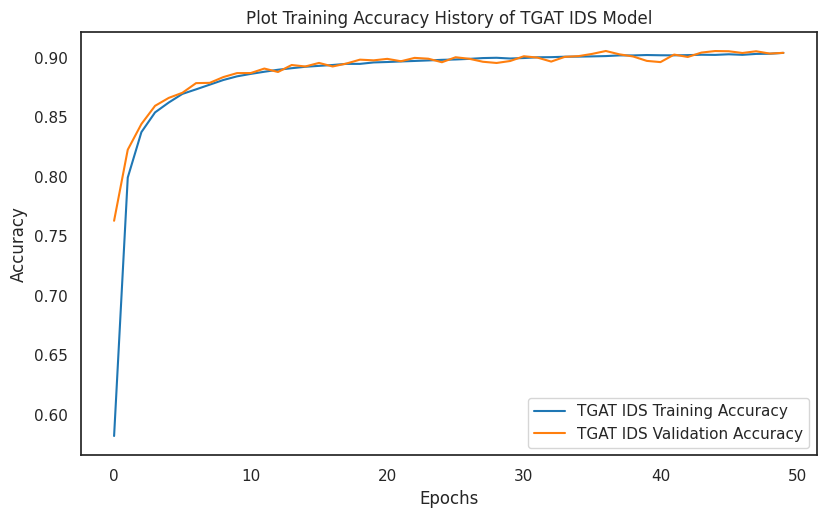

In [12]:
fig, ax = plt.subplots(1, figsize=(9.5,5.5))
plt.plot(range(EPOCHS), tgat_history.history['accuracy'], color=color_pal[0], label='TGAT IDS Training Accuracy')
plt.plot(range(EPOCHS), tgat_history.history['val_accuracy'], color=color_pal[1], label='TGAT IDS Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title("Plot Training Accuracy History of TGAT IDS Model")
plt.legend()
plt.show()

#### Plot Loss History of TGAT IDS Model

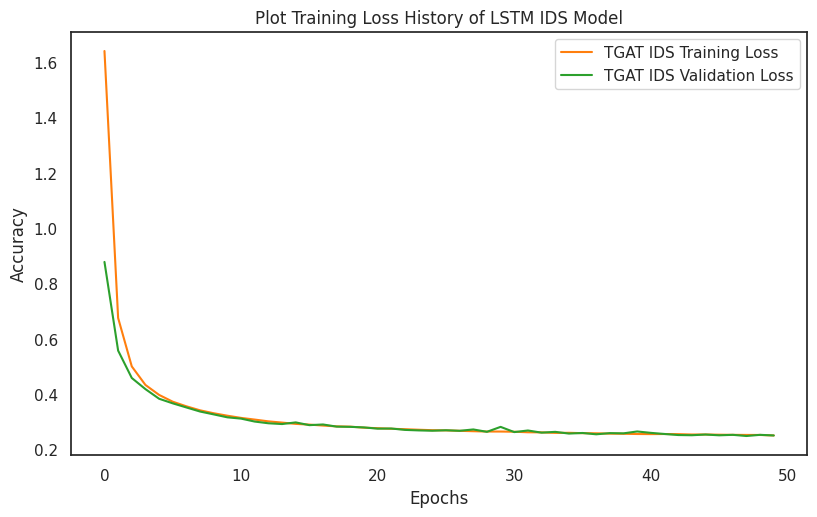

In [13]:
fig, ax = plt.subplots(1, figsize=(9.5,5.5))
plt.plot(range(EPOCHS), tgat_history.history['loss'], color=color_pal[1], label='TGAT IDS Training Loss')
plt.plot(range(EPOCHS), tgat_history.history['val_loss'], color=color_pal[2], label='TGAT IDS Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title("Plot Training Loss History of LSTM IDS Model")
plt.legend()
plt.show()

#### Load Best Variant of TGAT IDS Model

In [7]:
with gpu_strategy.scope():
    loaded_tgat_model = load_model('/kaggle/working/tgat_model_best_v1.keras')
    loaded_tgat_model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'tgat_layer', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'tgat_layer_1', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


Model: "TGAT_IDS"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ tgat_input (InputLayer)         │ (None, 4, 12)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ input_feature_projection        │ (None, 4, 64)          │           832 │
│ (Dense)                         │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ tgat_layer (TGATLayer)          │ (None, 4, 64)          │        33,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ tgat_layer_1 (TGATLayer)        │ (None, 4, 64)          │        33,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 34)             │         1,122 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 212,936 (831.79 KB)

 Trainable params: 70,978 (277.26 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 141,958 (554.53 KB)

#### Evalutate Best Variant of TGAT IDS Model

In [16]:
loaded_tgat_train_metric = loaded_tgat_model.evaluate(X_train.astype('float32'), y_train.astype('float32'), return_dict=True, batch_size=4096 * gpu_strategy.num_replicas_in_sync)
loaded_tgat_test_metric = loaded_tgat_model.evaluate(X_test.astype('float32'), y_test.astype('float32'), return_dict=True, batch_size=4096 * gpu_strategy.num_replicas_in_sync)
print(f'Accuracy during training: {round(loaded_tgat_train_metric["accuracy"]*100, 2)}% and loss: {round(loaded_tgat_train_metric["loss"], 4)}')
print(f'Accuracy during test: {round(loaded_tgat_test_metric["accuracy"]*100, 2)}% and loss: {round(loaded_tgat_test_metric["loss"], 4)}')

855/855 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.9054 - loss: 0.2486
367/367 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.9050 - loss: 0.2496
Accuracy during training: 90.54% and loss: 0.2486
Accuracy during test: 90.5% and loss: 0.2496


#### Save TGAT IDS Model Metrics

In [29]:
# 1. Initialize the master data structure file
registry = ModelRegistry()

registry.add_model_metrics(
    model_name="TGAT_IDS",
    history_object=tgat_history,
    train_eval=loaded_tgat_train_metric,
    test_eval=loaded_tgat_test_metric
)

# 2. Save everything into the single file
registry.save_to_disk()

# Inside your visualization notebook or function:
with open("/kaggle/working/all_network_models_report.json", "r") as f:
    metrics_data = json.load(f)

# Test performance parameters of TGAT IDS are saved properly
print(f'TGAT IDS Accuracy during training: {round(metrics_data["TGAT_IDS"]['final_evaluation']['train_accuracy']*100, 2)}%')
print(f'TGAT IDS Accuracy during training: {round(metrics_data["TGAT_IDS"]['final_evaluation']['test_accuracy']*100, 2)}%')

Successfully added 'TGAT_IDS' metrics to registry container.
Master benchmark dataset written to: /kaggle/working/all_network_models_report.json
TGAT IDS Accuracy during training: 90.54%
TGAT IDS Accuracy during training: 90.5%


In [13]:
reshape_y_test = reshape_y(y_test)
reshape_y_test

array([[False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       ...,
       [False, False, False, ..., False, False, False],
       [False,  True, False, ..., False, False, False],
       [False, False, False, ..., False, False, False]],
      shape=(3000000, 34))

#### Evaluate Best TGAT Using Confusion Matrix & Plot Confusion Matrix on HeatMap

184/184 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step


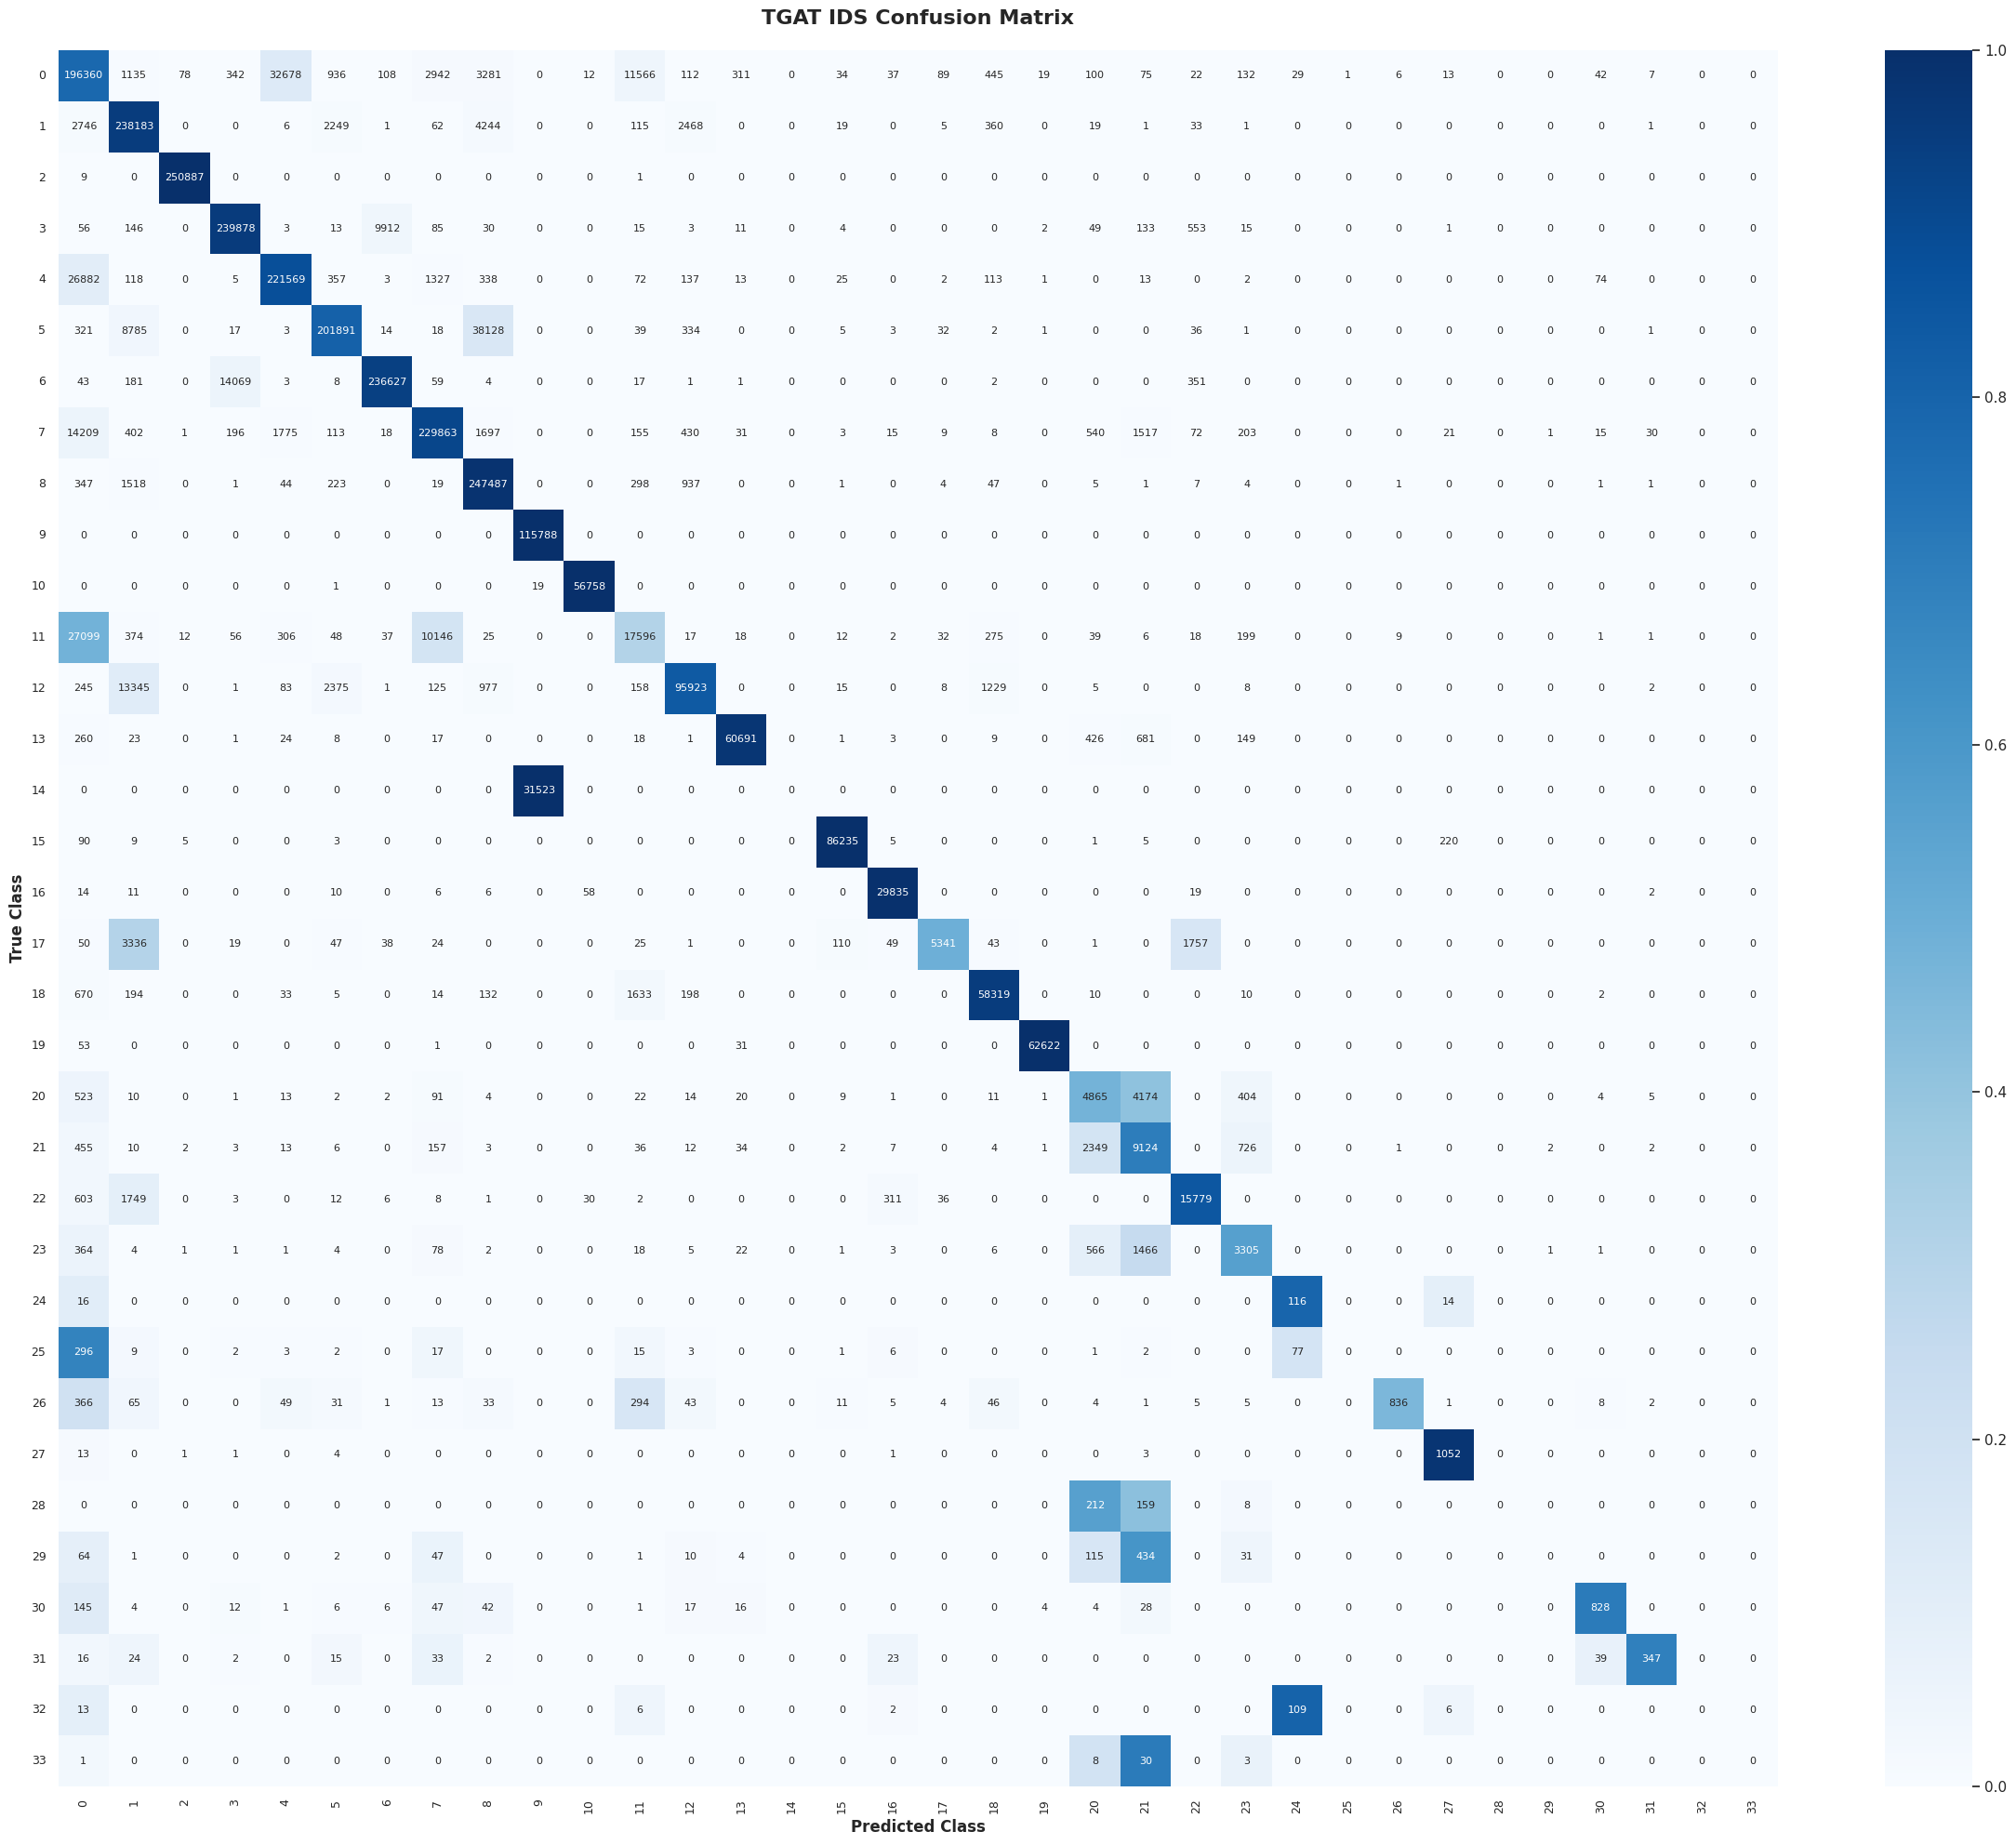

TGAT IDS F1-score:  89.6%
TGAT IDS Recall:    89.6%
TGAT IDS Precision: 89.6%
TGAT IDS AUC-ROC:   99.88%

Classification Report:


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


             precision   recall f1-score  support
0               72.10%   78.26%   75.06%   250912
1               88.34%   95.08%   91.58%   250513
2               99.96%  100.00%   99.98%   250897
3               94.21%   95.60%   94.90%   250909
4               86.35%   88.26%   87.29%   251051
5               96.89%   80.88%   88.16%   249631
6               95.89%   94.14%   95.00%   251366
7               93.75%   91.46%   92.59%   251324
8               83.49%   98.62%   90.43%   250946
9               78.59%  100.00%   88.01%   115788
10              99.82%   99.96%   99.89%    56778
11              54.81%   31.24%   39.80%    56328
12              95.29%   83.78%   89.16%   114500
13              99.16%   97.40%   98.27%    62312
14               0.00%    0.00%    0.00%    31523
15              99.71%   99.61%   99.66%    86573
16              98.44%   99.58%   99.01%    29961
17              96.03%   49.27%   65.12%    10841
18              95.73%   95.26%   95.50%    61220


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [14]:
# Ensure GPU is used for prediction
with tf.device('/GPU:0'):
    tgat_y_pred_prob = loaded_tgat_model.predict(X_test, batch_size=8192 * gpu_strategy.num_replicas_in_sync)
    tgat_y_pred = np.argmax(tgat_y_pred_prob, axis=1)

# True labels
tgat_y_true = np.argmax(reshape_y_test, axis=1)

# ---------------------------------------------------------
# 1. HEATMAP CONFUSION MATRIX (NORMALIZED COLORS, RAW TEXT)
# ---------------------------------------------------------
# Extract the exact ordered class names from your pipeline's mapping
class_names = encoding_mappings['Attack'] 

# Calculate absolute counts (for the text inside the boxes)
raw_conf_matrix = confusion_matrix(tgat_y_true, tgat_y_pred)

# Calculate normalized counts by row (for the background colors)
# This calculates the Recall for each class (how many actual instances were predicted correctly)
norm_conf_matrix = confusion_matrix(tgat_y_true, tgat_y_pred, normalize='true')

# Plotting the Heatmap
plt.figure(figsize=(24, 20)) 
sns.heatmap(
    norm_conf_matrix,           # <-- Drives the colors (values are between 0.0 and 1.0)
    annot=raw_conf_matrix,      # <-- Prints the absolute figures inside the squares
    annot_kws={"size": 8},      
    cmap='Blues', 
    fmt='g',                    # Ensures the raw numbers print cleanly (no scientific notation)
    xticklabels=class_names, 
    yticklabels=class_names,
    vmin=0.0,                   # Locks the color bar base at 0%
    vmax=1.0                    # Locks the color bar ceiling at 100%
)

plt.title('TGAT IDS Confusion Matrix', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('True Class', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Class', fontsize=12, fontweight='bold')
plt.xticks(rotation=90, fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 2. OVERALL METRICS
# ---------------------------------------------------------
tgat_attention_f1 = round(f1_score(tgat_y_true, tgat_y_pred, average="micro") * 100, 2)
tgat_attention_recall = round(recall_score(tgat_y_true, tgat_y_pred, average="micro") * 100, 2)
tgat_attention_precision = round(precision_score(tgat_y_true, tgat_y_pred, average="micro") * 100, 2)
tgat_attention_auc = round(roc_auc_score(tgat_y_true, tgat_y_pred_prob, multi_class='ovr', average="micro") * 100, 2)

print(f"TGAT IDS F1-score:  {tgat_attention_f1}%")
print(f"TGAT IDS Recall:    {tgat_attention_recall}%")
print(f"TGAT IDS Precision: {tgat_attention_precision}%")
print(f"TGAT IDS AUC-ROC:   {tgat_attention_auc}%\n")

# ---------------------------------------------------------
# 3. PERCENTAGE-BASED CLASSIFICATION REPORT WITH NAMES
# ---------------------------------------------------------
print("Classification Report:")

# Get the report as a dictionary instead of a raw string
report_dict = classification_report(tgat_y_true, tgat_y_pred, target_names=class_names, output_dict=True)

# Convert to Pandas DataFrame for easy manipulation
report_df = pd.DataFrame(report_dict).transpose()

# Clean up the 'accuracy' row to mimic standard sklearn visual structure
total_support = int(report_df.loc['macro avg', 'support'])
report_df.loc['accuracy', 'support'] = total_support
report_df.loc['accuracy', 'precision'] = np.nan
report_df.loc['accuracy', 'recall'] = np.nan

# Format decimals to percentages with '%' appended
metrics_cols = ['precision', 'recall', 'f1-score']
for col in metrics_cols:
    report_df[col] = report_df[col].apply(lambda x: f"{x * 100:.2f}%" if pd.notnull(x) else "")

# Ensure support remains a clean integer
report_df['support'] = report_df['support'].astype(int)

# Print the beautifully formatted DataFrame
print(report_df.to_string())

#### Print Names of IDS Models whose names are saved in JSON File

In [22]:
print("Models currently in registry:")
for model_name in registry.registry.keys():
    print(f"- {model_name}")

Models currently in registry:
- TCN_IDS
- LSTM_IDS
- TITAN_IDS
- TranAD_IDS
- MHA_IDS
- TGAT_IDS
- BiLSTM_IDS
- GRU_IDS
- BiGRU_IDS


## Define Function to Plot Comparatively the Training and Validation Accuracy of IDS Models

In [26]:
def plot_registry_accuracies(model_registry):
    """
    Plots a grouped bar chart showing final training vs validation accuracy 
    for every model in the ModelRegistry.
    """
    registry_data = model_registry.registry
    if not registry_data:
        print("No data found in registry to plot.")
        return

    # Extract model names and their corresponding final evaluation metrics
    model_names = list(registry_data.keys())
    train_accs = [
        registry_data[model]["final_evaluation"]["train_accuracy"] 
        for model in model_names
    ]
    val_accs = [
        registry_data[model]["final_evaluation"]["test_accuracy"] 
        for model in model_names
    ]

    # Convert to percentages for cleaner display if stored as decimals (e.g., 0.92 -> 92.0)
    # If they are already stored as whole percents (e.g., 92.0), remove the "* 100" multiplier
    train_accs = [acc * 100 if acc <= 1.0 else acc for acc in train_accs]
    val_accs = [acc * 100 if acc <= 1.0 else acc for acc in val_accs]

    # Set up positions for the grouped bar configuration
    x = np.arange(len(model_names))  # Label locations
    width = 0.30                     # Width of individual bars

    fig, ax = plt.subplots(figsize=(18, 7))

    # Plot grouped bars with distinct color signatures
    rects1 = ax.bar(x - width/2, train_accs, width, label='Training Accuracy', color='#1f77b4')
    rects2 = ax.bar(x + width/2, val_accs, width, label='Validation Accuracy', color='#ff7f0e')

    # Style definitions and axis labeling
    ax.set_ylabel('Accuracy (%)', fontsize=12, fontweight='bold')
    ax.set_title('Model Performance Breakdown: Training vs. Validation Accuracy', fontsize=14, fontweight='bold', pad=15)
    ax.set_xticks(x)
    ax.set_xticklabels(model_names, rotation=15, ha='right', fontsize=11)
    ax.set_ylim(0, 115) # Leave headroom at the top for labels
    ax.legend(loc='upper right', fontsize=11)
    ax.grid(axis='y', linestyle='--', alpha=0.5)

    # Helper function to auto-attach text labels above each bar
    def autolabel(rects):
        for rect in rects:
            height = rect.get_height()
            ax.annotate(f'{height:.2f}%',
                        xy=(rect.get_x() + rect.get_width() / 2, height),
                        xytext=(0, 4),  # 4 points vertical offset
                        textcoords="offset points",
                        ha='center', va='bottom', 
                        fontsize=9, fontweight='semibold')

    autolabel(rects1)
    autolabel(rects2)

    plt.tight_layout()
    plt.show()

In [21]:
def plot_registry_metrics(model_registry):
    """
    Plots a dual-axis chart showing final training vs validation accuracy (as bars) 
    and training vs validation loss (as lines) for every model in the ModelRegistry.
    """
    registry_data = model_registry.registry
    if not registry_data:
        print("No data found in registry to plot.")
        return

    # Extract model names and their corresponding final evaluation metrics
    model_names = list(registry_data.keys())
    
    train_accs = [registry_data[m]["final_evaluation"]["train_accuracy"] for m in model_names]
    val_accs = [registry_data[m]["final_evaluation"]["test_accuracy"] for m in model_names]
    train_losses = [registry_data[m]["final_evaluation"]["train_loss"] for m in model_names]
    val_losses = [registry_data[m]["final_evaluation"]["test_loss"] for m in model_names]

    # Convert to percentages for cleaner display if stored as decimals
    train_accs = [acc * 100 if acc <= 1.0 else acc for acc in train_accs]
    val_accs = [acc * 100 if acc <= 1.0 else acc for acc in val_accs]

    # Set up positions for the grouped bar configuration
    x = np.arange(len(model_names))  
    width = 0.35  

    fig, ax1 = plt.subplots(figsize=(18, 8))

    # ==========================================
    # 1. Plot Accuracies (Bars on Primary Axis)
    # ==========================================
    rects1 = ax1.bar(x - width/2, train_accs, width, label='Train Accuracy', color='#4C72B0', alpha=0.85)
    rects2 = ax1.bar(x + width/2, val_accs, width, label='Val Accuracy', color='#DD8452', alpha=0.85)

    ax1.set_ylabel('Accuracy (%)', fontsize=12, fontweight='bold', color='#333333')
    ax1.set_xticks(x)
    ax1.set_xticklabels(model_names, rotation=25, ha='right', fontsize=11)
    ax1.set_ylim(0, 115) # Headroom for labels
    ax1.grid(axis='y', linestyle='--', alpha=0.4)

    # Auto-attach text labels above each bar
    def autolabel(rects, axis):
        for rect in rects:
            height = rect.get_height()
            axis.annotate(f'{height:.2f}%',
                        xy=(rect.get_x() + rect.get_width() / 2, height),
                        xytext=(0, 4),  
                        textcoords="offset points",
                        ha='center', va='bottom', 
                        fontsize=9, fontweight='semibold')
    
    autolabel(rects1, ax1)
    autolabel(rects2, ax1)

    # ==========================================
    # 2. Plot Losses (Lines on Secondary Axis)
    # ==========================================
    ax2 = ax1.twinx()  # Instantiate a second axes that shares the same x-axis
    
    # We use markers ('o', 's') so the data points stand out against the bars
    line1, = ax2.plot(x, train_losses, color='#55A868', marker='o', linewidth=2.5, markersize=8, label='Train Loss')
    line2, = ax2.plot(x, val_losses, color='#C44E52', marker='s', linewidth=2.5, markersize=8, label='Val Loss')

    ax2.set_ylabel('Loss Value', fontsize=12, fontweight='bold', color='#333333')
    
    # Calculate a dynamic upper bound for the loss axis (add 20% padding above the max loss)
    max_loss = max(max(train_losses), max(val_losses))
    ax2.set_ylim(0, max_loss * 1.2) 

    # ==========================================
    # 3. Unified Legend & Styling
    # ==========================================
    plt.title('Model Performance Breakdown: Accuracy vs. Loss', fontsize=15, fontweight='bold', pad=20)
    
    # Combine the legends from both axes into one cohesive box
    bars1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(bars1 + lines2, labels1 + labels2, loc='upper center', bbox_to_anchor=(0.5, 1.0), 
               ncol=4, fontsize=11, framealpha=0.95)

    plt.tight_layout()
    plt.show()

## Plot Comparatively the Training and Validation Accuracy of IDS Models

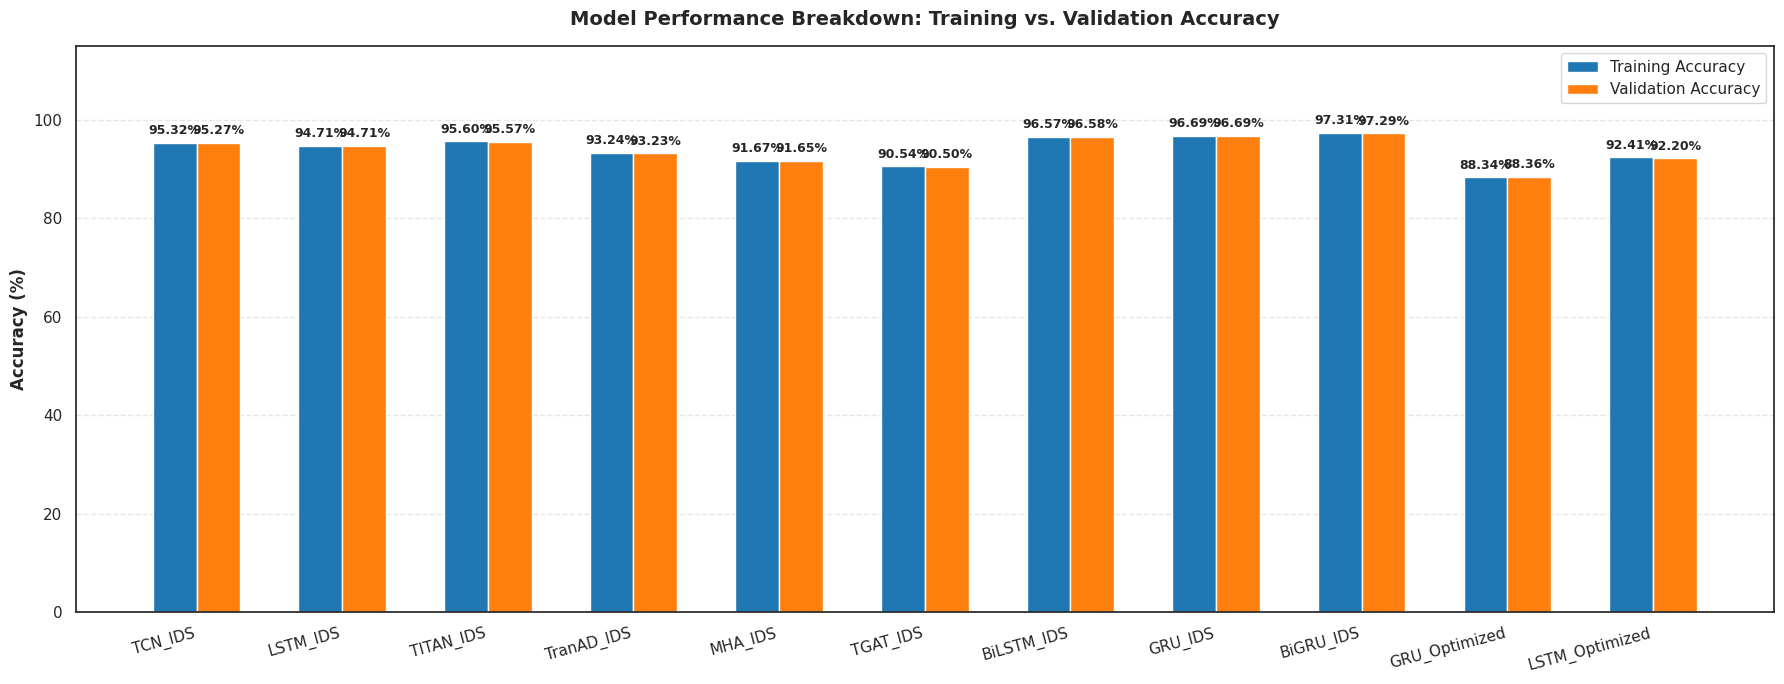

In [38]:
# Initialize registry from Saved JSON Model performance metrics
registry = ModelRegistry()

# Example Usage:
plot_registry_accuracies(registry)

# Define Optimization for IDS Models Using Optuna

In [22]:
# ==========================================
# CELL 1: OPTUNA IMPORTS & CUSTOM OBJECTS
# ==========================================

# Required for loading the Transformer/Attention based models after saving
CUSTOM_OBJECTS = {
    'MultiHeadTemporalAttention': MultiHeadTemporalAttention,
    'TGATLayer': TGATLayer,
    'TitanMACBlock': TitanMACBlock,
    'PositionalEncoding': PositionalEncoding,
    'TransformerEncoderBlock': TransformerEncoderBlock
}

In [23]:
# ==========================================
# CELL 2: THE ROUTER (create_model)
# ==========================================
def create_model(trial, algo_abbr):
    """
    Switch-case router that dynamically redirects the Optuna trial 
    to the specific model architecture builder.
    """
    if algo_abbr == "LSTM":
        return create_lstm_model(trial)
    elif algo_abbr == "BiLSTM":
        return create_bilstm_model(trial)
    elif algo_abbr == "GRU":
        return create_gru_model(trial)
    elif algo_abbr == "BiGRU":
        return create_bigru_model(trial)
    elif algo_abbr == "TCN":
        return create_tcn_model(trial)
    elif algo_abbr == "MHA":
        return create_mha_model(trial)
    elif algo_abbr == "TGAT":
        return create_tgat_model(trial)
    elif algo_abbr == "TITAN":
        return create_titan_model(trial)
    elif algo_abbr == "TranAD":
        return create_tranad_model(trial)
    else:
        raise ValueError(f"Algorithm abbreviation '{algo_abbr}' not recognized.")

## Define Objective Function for Optimization

In [23]:
# ==========================================
# CELL 3: THE SINGLE-OBJECTIVE FUNCTION
# ==========================================
def objective(trial, algo_abbr):
    """
    Unified multi-objective function. Clears memory, routes data, 
    and returns both validation loss and validation accuracy.
    """
    # 1. Clear session to prevent OOM errors over multiple trials
    tf.keras.backend.clear_session()
    gc.collect()
    
    # 2. Build the trial model
    model = create_model(trial, algo_abbr)
    
    # 3. Handle specific data routing 
    if algo_abbr == "TGAT":
        X_tr, y_tr = X_train, y_train
        X_val, y_val = X_test, y_test
    else:
        X_tr, y_tr = optimized_reshaped_X_train, optimized_reshaped_y_train
        X_val, y_val = optimized_reshaped_X_test, optimized_reshaped_y_test

    # 4. Define aggressive batch size for fast tuning
    batch_sz = 3096 * gpu_strategy.num_replicas_in_sync
    
    # 5. Fast search training 
    OPTUNA_EPOCHS = 10 

    # We monitor 'val_loss' to allow the MedianPruner to kill bad trials early
    pruning_callback = TFKerasPruningCallback(trial, "val_loss")
    
    history = model.fit(
        X_tr.astype('float32'), y_tr.astype('float32'),
        epochs=OPTUNA_EPOCHS,
        validation_data=(X_val.astype('float32'), y_val.astype('float32')),
        batch_size=batch_sz,
        verbose=0, # Keep output clean during Optuna trials
        shuffle=True,
        callbacks=[pruning_callback] # <-- FIX: Callback properly injected
    )
    
    # 6. Extract both metrics for multi-objective evaluation
    val_loss = history.history['val_loss'][-1]
    
    # Optuna expects the return order to match the objective function
    return val_loss

## Load Best Trial from Saved Json File

In [24]:
# ---------------------------------------------------------
# NEW: Load the JSON parameters and wrap in a FixedTrial
# ---------------------------------------------------------
def get_best_trial(trial_filename):
    with open(trial_filename, 'r') as f:
        best_params = json.load(f)
        
    best_trial = FixedTrial(best_params)

    # Attach the dictionary directly to the trial object for easy printing
    best_trial.saved_params = best_params

    return best_trial

## Save the Best Trial & Show Results

In [25]:
# ==========================================
# CELL 4: THE PARETO SAVER (show_result)
# ==========================================
def show_result(study, algo_abbr):
    """
    Analyzes the Pareto front, selects the best accuracy model, 
    retrains it for full epochs, and logs it to the registry.
    """
    print(f"\n{'='*50}")
    print(f" SINGLE-OBJECTIVE OPTIMIZATION COMPLETE: {algo_abbr}")
    print(f"{'='*50}")

    pruned_trials = study.get_trials(deepcopy=False, states=[TrialState.PRUNED])
    complete_trials = study.get_trials(deepcopy=False, states=[TrialState.COMPLETE])

    print("Study statistics: ")
    print("\tNumber of finished trials: ", len(study.trials))
    print("\tNumber of pruned trials: ", len(pruned_trials))
    print("\tNumber of complete trials: ", len(complete_trials))

    # In a single-objective study, there is only one absolute best trial
    best_trial = study.best_trial

    # ---------------------------------------------------------
    # NEW: Save best trial parameters to a JSON file
    # ---------------------------------------------------------
    timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
    trial_filename = f"/kaggle/working/{algo_abbr.lower()}_best_trial_{timestamp}.json"
    
    with open(trial_filename, 'w') as f:
        json.dump(best_trial.params, f, indent=4)
        
    print(f"\n[+] Best trial parameters saved to: {trial_filename}")
    # ---------------------------------------------------------
    
    print(f"\nSelected Best Trial (Trial #{best_trial.number}):")
    print(f"  Validation Loss: {round(best_trial.value, 4)}")
    print("Optimized Hyperparameters:")
    for key, value in best_trial.params.items():
        print(f"    - {key}: {value}")

## Train Best Model

In [26]:
# ==========================================
# CELL 5: TRAIN THE BEST CONFIGURATION FROM THE OPTIMIZATION
# ==========================================
def train_best_model(best_trial, algo_abbr):
    print(f"\nRetraining Optimized {algo_abbr} Model for Full {EPOCHS} Epochs...")
    tf.keras.backend.clear_session()
    gc.collect()

    # In a single-objective study, there is only one absolute best trial
    # best_trial = study.best_trial
    
    # Rebuild using the best trial parameters
    best_model = create_model(best_trial, algo_abbr)
    model_filepath = f"{algo_abbr.lower()}_optimized_best_v1.keras"
    
    checkpoint = ModelCheckpoint(
        model_filepath, monitor='val_loss', mode='min', save_best_only=True, verbose=1
    )

    # Data Routing
    if algo_abbr == "TGAT":
        X_tr, y_tr = X_train, y_train
        X_val, y_val = X_test, y_test
    else:
        X_tr, y_tr = reshaped_X_train, reshaped_y_train
        X_val, y_val = reshaped_X_test, reshaped_y_test

    # 1. Define batch size
    batch_sz = 16384 * tpu_strategy.num_replicas_in_sync

    # 2. Calculate optimal shuffle buffer
    # Use the full dataset size for perfect shuffling, or cap it if RAM is limited
    buffer_sz = len(X_tr) 

    # 3. Wrap data in tf.data.Dataset and optimize
    train_ds = tf.data.Dataset.from_tensor_slices((X_tr.astype('float32'), y_tr.astype('float32')))
    
    # CRITICAL PIPELINE ORDER: cache -> shuffle -> batch -> prefetch
    train_ds = (train_ds
                .cache()                                         # <-- Epoch 2+ becomes instant
                .shuffle(buffer_sz)                              # <-- Properly scales the randomness
                .batch(batch_sz, drop_remainder=True)            # <-- Fixed typo: drop_remainder=True
                .prefetch(tf.data.AUTOTUNE))
    
    val_ds = tf.data.Dataset.from_tensor_slices((X_val.astype('float32'), y_val.astype('float32')))
    val_ds = (val_ds
              .cache()                                           # <-- Speeds up validation significantly
              .batch(batch_sz)
              .prefetch(tf.data.AUTOTUNE))

    # Full Training
    full_history = best_model.fit(
        train_ds,
        epochs=EPOCHS,
        validation_data=val_ds,
        callbacks=[checkpoint],
        verbose=1
        # shuffle=True has been REMOVED here. It is ignored when passing a tf.data.Dataset
    )

    # Full Training
    # full_history = best_model.fit(
    #     X_tr.astype('float32'), y_tr.astype('float32'),
    #     epochs=EPOCHS,
    #     validation_data=(X_val.astype('float32'), y_val.astype('float32')),
    #     batch_size=3096 * gpu_strategy.num_replicas_in_sync,
    #     callbacks=[checkpoint],
    #     verbose=1,
    #     shuffle=True
    # )
    
    # Load best weights and evaluate
    print(f"\nEvaluating Final Optimized {algo_abbr} Model...")
    loaded_opt_model = load_model(model_filepath, custom_objects=CUSTOM_OBJECTS)
    
    # batch_size=batch_sz has been REMOVED here. You cannot pass batch_size to evaluate() when using tf.data
    train_eval = loaded_opt_model.evaluate(train_ds, return_dict=True, verbose=0)
    test_eval  = loaded_opt_model.evaluate(val_ds, return_dict=True, verbose=0)
    
    print(f"Train Acc: {round(train_eval['accuracy']*100, 2)}% | Test Acc: {round(test_eval['accuracy']*100, 2)}%")
    
    # Save to your existing registry structure
    registry_name = f"{algo_abbr}_Optimized"
    registry.add_model_metrics(registry_name, full_history, train_eval, test_eval)
    registry.save_to_disk()

    # Example Usage:
    plot_registry_accuracies(registry)

In [26]:
# ==========================================
# CELL 5: TRAIN THE BEST CONFIGURATION FROM THE OPTIMIZATION
# ==========================================
def train_best_model(best_trial, algo_abbr):
    print(f"\nRetraining Optimized {algo_abbr} Model for Full {EPOCHS} Epochs...")
    tf.keras.backend.clear_session()
    gc.collect()

    # In a single-objective study, there is only one absolute best trial
    # best_trial = study.best_trial
    
    # Rebuild using the best trial parameters
    best_model = create_model(best_trial, algo_abbr)
    model_filepath = f"{algo_abbr.lower()}_optimized_best_v1.keras"
    
    checkpoint = ModelCheckpoint(
        model_filepath, monitor='val_loss', mode='min', save_best_only=True, verbose=1
    )

    # Data Routing
    if algo_abbr == "TGAT":
        X_tr, y_tr = X_train, y_train
        X_val, y_val = X_test, y_test
    else:
        X_tr, y_tr = reshaped_X_train, reshaped_y_train
        X_val, y_val = reshaped_X_test, reshaped_y_test

    batch_sz = 2048 * gpu_strategy.num_replicas_in_sync
    # batch_sz = 3096 * gpu_strategy.num_replicas_in_sync
    # batch_sz = 16384 * tpu_strategy.num_replicas_in_sync

    # Full Training
    full_history = best_model.fit(
        X_tr.astype('float32'), y_tr.astype('float32'),
        epochs=EPOCHS,
        validation_data=(X_val.astype('float32'), y_val.astype('float32')),
        batch_size=batch_sz,
        callbacks=[checkpoint],
        verbose=1,
        shuffle=True
    )
    
    # Load best weights and evaluate
    print(f"\nEvaluating Final Optimized {algo_abbr} Model...")
    loaded_opt_model = load_model(model_filepath, custom_objects=CUSTOM_OBJECTS)
    
    train_eval = loaded_opt_model.evaluate(X_tr.astype('float32'), y_tr.astype('float32'), return_dict=True, batch_size=batch_sz, verbose=0)
    test_eval  = loaded_opt_model.evaluate(X_val.astype('float32'), y_val.astype('float32'), return_dict=True, batch_size=batch_sz, verbose=0)
    
    print(f"Train Acc: {round(train_eval['accuracy']*100, 2)}% | Test Acc: {round(test_eval['accuracy']*100, 2)}%")
    
    # Save to your existing registry structure
    registry_name = f"{algo_abbr}_Optimized"
    registry.add_model_metrics(registry_name, full_history, train_eval, test_eval)
    registry.save_to_disk()

    # # Example Usage:
    # plot_registry_accuracies(registry)

## Define Trial Variable

In [27]:
# ==========================================
# CELL 6: DYNAMICALLY DERIVE THE TRIAL VARIABLES BASED ON ALGORITHM OPTIMIZED
# ==========================================
def get_trial_variables(trial, algo_abbr):
    """
    Universal hyperparameter generator. Returns a dictionary of parameters 
    specifically tailored to the requested algorithm family.
    """
    params = {}
    
    # ==========================================
    # 1. UNIVERSAL PARAMETERS (Shared by all models)
    # ==========================================
    params['lr'] = trial.suggest_float('lr', 1e-4, 5e-3, log=True)
    
    # ---> Optimizer Selection <---
    optimizer_choices = ['Adam', 'AdamW', 'Nadam', 'RMSprop']
    params['optimizer'] = trial.suggest_categorical('optimizer', optimizer_choices)
    
    # Determine the appropriate loss function
    if algo_abbr == "TGAT":
        params['loss'] = 'sparse_categorical_crossentropy'
    else:
        loss_choices = [
            'categorical_crossentropy', 
            'categorical_focal_crossentropy', 
            'categorical_hinge'
        ]
        params['loss'] = trial.suggest_categorical('loss', loss_choices)

    # ==========================================
    # 2. ALGORITHM-SPECIFIC PARAMETERS
    # ==========================================
    rnn_family = ["LSTM", "BiLSTM", "GRU", "BiGRU"]
    transformer_family = ["MHA", "TGAT", "TITAN", "TranAD"]
    
    # --- A. Recurrent Networks ---
    if algo_abbr in rnn_family:
        multipliers = np.array([1, 2, 4, 6])
        params['units_1'] = trial.suggest_categorical('units_1', (multipliers * num_features).tolist())
        params['units_2'] = trial.suggest_categorical('units_2', (multipliers * num_features).tolist())
        
        params['dropout_1'] = trial.suggest_float('dropout_1', 0.0001, 0.001)
        params['dropout_2'] = trial.suggest_float('dropout_2', 0.001, 0.05)
        
        activation_choices = ['tanh', 'swish', 'gelu', 'relu', 'softmax']
        params['activation_1'] = trial.suggest_categorical('activation_1', activation_choices)
        params['activation_2'] = trial.suggest_categorical('activation_2', activation_choices)

    # --- B. Attention & Transformer Networks ---
    elif algo_abbr in transformer_family:
        params['d_model'] = trial.suggest_categorical('d_model', [32, 64])
        params['num_heads'] = trial.suggest_categorical('num_heads', [2, 4])
        
        if algo_abbr == "TGAT":
            params['dense_dim'] = trial.suggest_categorical('dense_dim', [32, 64])
            
        elif algo_abbr == "TITAN":
            params['persistent_tokens'] = trial.suggest_categorical('persistent_tokens', [4, 8])
            params['titan_dense_units'] = trial.suggest_categorical('titan_dense_units', [16, 32, 64])
            params['titan_dense_act'] = trial.suggest_categorical('titan_dense_act', ['relu', 'swish', 'gelu'])
            
        elif algo_abbr == "TranAD":
            params['ff_dim'] = trial.suggest_categorical('ff_dim', [64, 128])
            params['dropout'] = trial.suggest_float('dropout', 0.0, 0.2)
            
        elif algo_abbr == "MHA":
            params['key_dim'] = trial.suggest_categorical('key_dim', [4, 8, 16])
            params['dense_proj'] = trial.suggest_categorical('dense_proj', [16, 32, 64])

    # --- C. Temporal Convolutional Networks ---
    elif algo_abbr == "TCN":
        params['filters'] = trial.suggest_categorical('filters', [32, 64, 128])
        params['dropout_1'] = trial.suggest_float('dropout_1', 0.0, 0.1)
        params['dropout_2'] = trial.suggest_float('dropout_2', 0.0, 0.3)
        
        activation_choices = ['tanh', 'swish', 'gelu', 'relu', 'softmax']
        params['activation_1'] = trial.suggest_categorical('activation_1', activation_choices)
        params['activation_2'] = trial.suggest_categorical('activation_2', activation_choices)
        
    return params

## Define Trial Configuration for Recurrent IDS Models (GRU, BiGRU, LSTM, BiLSTM)

In [28]:
# ==========================================
# CELL 7: RECURRENT BUILDERS (LSTM, BiLSTM, GRU, BiGRU)
# ==========================================

def create_lstm_model(trial):
    with gpu_strategy.scope():
        inputs = Input(shape=(time_steps, num_features))
        
        # 1. Fetch the dictionary of parameters
        p = get_trial_variables(trial, "GRU")

        x = LSTM(p['units_1'], activation=p['activation_1'], dropout=p['dropout_1'], return_sequences=True)(inputs)
        x = LayerNormalization()(x)
        x = LSTM(p['units_2'], activation=p['activation_2'], dropout=p['dropout_2'])(x)
        x = LayerNormalization()(x)
        outputs = Dense(num_classes, activation='softmax')(x)

        model = Model(inputs=inputs, outputs=outputs)
           
        # ---> Dynamic Optimizer Instantiation <---
        # This fetches the class (e.g., tf.keras.optimizers.AdamW) and initializes it with your LR
        OptimizerClass = getattr(tf.keras.optimizers, p['optimizer'])
        optimizer_instance = OptimizerClass(learning_rate=p['lr'], clipnorm=1.0) # Kept your clipnorm for stability

        model.compile(
            loss=p['loss'], 
            optimizer=optimizer_instance, 
            metrics=['accuracy']
        )

        return model
        
def create_bilstm_model(trial):
    with gpu_strategy.scope():
        inputs = Input(shape=(time_steps, num_features))

        # 1. Fetch the dictionary of parameters
        p = get_trial_variables(trial, "BiLSTM")

        # 2. Plug them in using dictionary keys
        x = Bidirectional(LSTM(p['units_1'], activation=p['activation_1'], dropout=p['dropout_1'], return_sequences=True))(inputs)
        x = LayerNormalization()(x)
        x = Bidirectional(LSTM(p['units_2'], activation=p['activation_2'], dropout=p['dropout_2']))(x)
        x = LayerNormalization()(x)
        
        outputs = Dense(num_classes, activation='softmax')(x)

        model = Model(inputs=inputs, outputs=outputs)

        # ---> Dynamic Optimizer Instantiation <---
        # This fetches the class (e.g., tf.keras.optimizers.AdamW) and initializes it with your LR
        OptimizerClass = getattr(tf.keras.optimizers, p['optimizer'])
        optimizer_instance = OptimizerClass(learning_rate=p['lr'], clipnorm=1.0) # Kept your clipnorm for stability

        model.compile(
            loss=p['loss'], 
            optimizer=optimizer_instance, 
            metrics=['accuracy']
        )
        
        return model

def create_gru_model(trial):
    with gpu_strategy.scope():
        inputs = Input(shape=(time_steps, num_features))
        
        # 1. Fetch the dictionary of parameters
        p = get_trial_variables(trial, "GRU")

        x = GRU(p['units_1'], activation=p['activation_1'], dropout=p['dropout_1'], return_sequences=True)(inputs)
        x = LayerNormalization()(x)
        x = GRU(p['units_2'], activation=p['activation_2'], dropout=p['dropout_2'])(x)
        x = LayerNormalization()(x)
        
        outputs = Dense(num_classes, activation='softmax')(x)
        model = Model(inputs=inputs, outputs=outputs)
        
        # ---> NEW: Dynamic Optimizer Instantiation <---
        # This fetches the class (e.g., tf.keras.optimizers.AdamW) and initializes it with your LR
        OptimizerClass = getattr(tf.keras.optimizers, p['optimizer'])
        optimizer_instance = OptimizerClass(learning_rate=p['lr'], clipnorm=1.0) # Kept your clipnorm for stability

        model.compile(
            loss=p['loss'], 
            optimizer=optimizer_instance, 
            metrics=['accuracy']
        )
        
        return model

def create_bigru_model(trial):
    with gpu_strategy.scope():
        inputs = Input(shape=(time_steps, num_features))
        
        # 1. Fetch the dictionary of parameters
        p = get_trial_variables(trial, "BiGRU")

        x = Bidirectional(GRU(p['units_1'], activation=p['activation_1'], dropout=p['dropout_1'], return_sequences=True))(inputs)
        x = LayerNormalization()(x)
        x = Bidirectional(GRU(p['units_2'], activation=p['activation_2'], dropout=p['dropout_2']))(x)
        x = LayerNormalization()(x)
        outputs = Dense(num_classes, activation='softmax')(x)

        model = Model(inputs=inputs, outputs=outputs)
          
        # ---> Dynamic Optimizer Instantiation <---
        # This fetches the class (e.g., tf.keras.optimizers.AdamW) and initializes it with your LR
        OptimizerClass = getattr(tf.keras.optimizers, p['optimizer'])
        optimizer_instance = OptimizerClass(learning_rate=p['lr'], clipnorm=1.0) # Kept your clipnorm for stability

        model.compile(
            loss=p['loss'], 
            optimizer=optimizer_instance, 
            metrics=['accuracy']
        )

        return model

## Define Trial Configuration for Convolutional (TCN) and Transformer IDS Models (MHA)

In [29]:
# ==========================================
# CELL 8: CONVOLUTION & TRANSFORMER BUILDERS (TCN, MHA)
# ==========================================
def create_tcn_model(trial):
    with gpu_strategy.scope():
        inputs = Input(shape=(time_steps, num_features))
        p = get_trial_variables(trial, "TCN")
        
        x = TCN(p['filters'], dilations=[1,2], activation=p['activation_1'], dropout_rate=p['dropout_1'], return_sequences=True)(inputs)
        x = LayerNormalization()(x)
        x = TCN(p['filters'], dilations=[1,2], activation=p['activation_2'], dropout_rate=p['dropout_2'])(x)
        x = LayerNormalization()(x)
        outputs = Dense(num_classes, activation='softmax')(x)
        
        model = Model(inputs=inputs, outputs=outputs)
           
        # ---> NEW: Dynamic Optimizer Instantiation <---
        # This fetches the class (e.g., tf.keras.optimizers.AdamW) and initializes it with your LR
        OptimizerClass = getattr(tf.keras.optimizers, p['optimizer'])
        optimizer_instance = OptimizerClass(learning_rate=p['lr'], clipnorm=1.0) # Kept your clipnorm for stability

        model.compile(
            loss=p['loss'], 
            optimizer=optimizer_instance, 
            metrics=['accuracy']
        )

        return model

def create_mha_model(trial):
    with gpu_strategy.scope():
        inputs = Input(shape=(time_steps, num_features))
        p = get_trial_variables(trial, "MHA")

        x = Dense(p['dense_proj'], activation='relu')(inputs)
        
        attn1 = MultiHeadAttention(num_heads=p['num_heads'], key_dim=p['key_dim'], attention_axes=1)(x, x, use_causal_mask=True)
        x = LayerNormalization()(x + attn1)
        
        attn2 = MultiHeadAttention(num_heads=p['num_heads'], key_dim=p['key_dim'], attention_axes=1)(x, x, use_causal_mask=True)
        x = LayerNormalization()(x + attn2)

        x = GlobalAveragePooling1D()(x)
        outputs = Dense(num_classes, activation='softmax')(x)

        model = Model(inputs=inputs, outputs=outputs)
           
        # ---> NEW: Dynamic Optimizer Instantiation <---
        # This fetches the class (e.g., tf.keras.optimizers.AdamW) and initializes it with your LR
        OptimizerClass = getattr(tf.keras.optimizers, p['optimizer'])
        optimizer_instance = OptimizerClass(learning_rate=p['lr'], clipnorm=1.0) # Kept your clipnorm for stability

        model.compile(
            loss=p['loss'], 
            optimizer=optimizer_instance, 
            metrics=['accuracy']
        )

        return model
        

## Define Trial Configuration for Novel Transformer IDS Models (TGAT, TranAD, TITAN)

In [30]:
# ==========================================
# CELL 9: TRANSFORMER BUILDERS (TGAT, TITAN, TRANAD)
# ==========================================
def create_tgat_model(trial):
    with gpu_strategy.scope():
        inputs = Input(shape=(time_steps, tgat_num_features))
        p = get_trial_variables(trial, "TGAT")

        x = Dense(p['d_model'])(inputs)
        x = TGATLayer(d_model=p['d_model'], num_heads=p['num_heads'])(x)
        x = TGATLayer(d_model=p['d_model'], num_heads=p['num_heads'])(x)
        
        x = GlobalAveragePooling1D()(x)
        x = Dense(p['dense_dim'], activation='relu')(x)
        outputs = Dense(num_classes, activation='softmax')(x)
        
        model = Model(inputs=inputs, outputs=outputs)
           
        # ---> NEW: Dynamic Optimizer Instantiation <---
        # This fetches the class (e.g., tf.keras.optimizers.AdamW) and initializes it with your LR
        OptimizerClass = getattr(tf.keras.optimizers, p['optimizer'])
        optimizer_instance = OptimizerClass(learning_rate=p['lr'], clipnorm=1.0) # Kept your clipnorm for stability

        model.compile(
            loss=p['loss'], 
            optimizer=optimizer_instance, 
            metrics=['accuracy']
        )

        return model

def create_titan_model(trial):
    with gpu_strategy.scope():
        inputs = Input(shape=(time_steps, num_features))
        p = get_trial_variables(trial, "TITAN")

        x = Dense(p['d_model'])(inputs)
        x = TitanMACBlock(d_model=p['d_model'], num_heads=p['num_heads'], num_persistent_tokens=p['persistent_tokens'])(x)
        x = TitanMACBlock(d_model=p['d_model'], num_heads=p['num_heads'], num_persistent_tokens=p['persistent_tokens'])(x)
        
        x = GlobalAveragePooling1D()(x)
        # Using the newly integrated Dense layer variables
        x = Dense(p['titan_dense_units'], activation=p['titan_dense_act'])(x)
        outputs = Dense(num_classes, activation='softmax')(x)
        
        model = Model(inputs=inputs, outputs=outputs)
           
        # ---> NEW: Dynamic Optimizer Instantiation <---
        # This fetches the class (e.g., tf.keras.optimizers.AdamW) and initializes it with your LR
        OptimizerClass = getattr(tf.keras.optimizers, p['optimizer'])
        optimizer_instance = OptimizerClass(learning_rate=p['lr'], clipnorm=1.0) # Kept your clipnorm for stability

        model.compile(
            loss=p['loss'], 
            optimizer=optimizer_instance, 
            metrics=['accuracy']
        )
        
        return model

def create_tranad_model(trial):
    with gpu_strategy.scope():
        inputs = Input(shape=(time_steps, num_features))
        p = get_trial_variables(trial, "TranAD")

        x = Dense(p['d_model'])(inputs)
        x = PositionalEncoding(max_seq_len=time_steps, d_model=p['d_model'])(x)
        
        for _ in range(2):
            x = TransformerEncoderBlock(d_model=p['d_model'], num_heads=p['num_heads'], ff_dim=p['ff_dim'], dropout_rate=p['dropout'])(x)

        x = GlobalAveragePooling1D()(x)
        outputs = Dense(num_classes, activation='softmax')(x)
        
        model = Model(inputs=inputs, outputs=outputs)
           
        # ---> NEW: Dynamic Optimizer Instantiation <---
        # This fetches the class (e.g., tf.keras.optimizers.AdamW) and initializes it with your LR
        OptimizerClass = getattr(tf.keras.optimizers, p['optimizer'])
        optimizer_instance = OptimizerClass(learning_rate=p['lr'], clipnorm=1.0) # Kept your clipnorm for stability

        model.compile(
            loss=p['loss'], 
            optimizer=optimizer_instance, 
            metrics=['accuracy']
        )
        
        return model

## Define and Set Custom Loggnig Callback

In [31]:
# ---------------------------------------------------------
# CUSTOM LOGGING CALLBACK
# ---------------------------------------------------------
# 1. Suppress Optuna's default INFO logger to prevent duplicate printouts
optuna.logging.set_verbosity(optuna.logging.WARNING)

# 2. Define the custom callback to format the output string
def duration_logging_callback(study, trial):
    # Generate the exact timestamp format Optuna uses
    log_timestamp = datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S,%f")[:-3]
    
    if trial.state == optuna.trial.TrialState.COMPLETE:
        # Format: [I 2026-06-24 22:50:33,295] Trial 0 finished... Duration: X:XX:XX
        print(f"[I {log_timestamp}] Trial {trial.number} finished with values: {trial.values} "
              f"and parameters: {trial.params}. Duration: {trial.duration}")
    elif trial.state == optuna.trial.TrialState.FAIL:
        print(f"[W {log_timestamps}] Trial {trial.number} failed. Duration: {trial.duration}")

## Define Study Function for Optimization

In [32]:
def get_study(study_name):    # Create the multi-objective study: [minimize loss, maximize accuracy]
    study = optuna.create_study(
        direction="minimize", 
        study_name = study_name,
        sampler=optuna.samplers.TPESampler(multivariate=True, seed=42, n_startup_trials=5),
        pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=2), 
        storage="sqlite:///db.sqlite3",  # Specify the storage URL here.
        load_if_exists=True
    )

    return study

# Initialize the master data structure file
registry = ModelRegistry()

# Optimize IDS Models Using Optuna

## Optimize GRU IDS Model

In [37]:
# ==========================================
# CELL 10: OPTUNA SINGLE-OBJECTIVE EXECUTION
# ==========================================
# Set which algorithm you want to optimize in this run
ALGO_TO_TUNE = "GRU" 
timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
study_name = f"{ALGO_TO_TUNE}_Single_Objective_{timestamp}"
N_TRIALS = 50         


def main():
    print(f"Initializing Single-Objective Optuna Study for {study_name}...")
    
    study = get_study(study_name)
    
    # Pass the trial and the algo_abbr securely using a lambda function
    study.optimize(
        lambda trial: objective(trial, ALGO_TO_TUNE), 
        n_trials=N_TRIALS,
        callbacks=[duration_logging_callback],
        show_progress_bar=True
    )

    return study

In [ ]:
if __name__ == "__main__":
    main()

Initializing Single-Objective Optuna Study for GRU_Single_Objective_20260629_211609...


/tmp/ipykernel_58/376658603.py:5: ExperimentalWarning: Argument ``multivariate`` is an experimental feature. The interface can change in the future.
  sampler=optuna.samplers.TPESampler(multivariate=True, seed=42, n_startup_trials=5),


  0%|          | 0/200 [00:00<?, ?it/s]

INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Redu

I0000 00:00:1782767904.563608     210 cuda_dnn.cc:529] Loaded cuDNN version 91002
I0000 00:00:1782767904.563626     208 cuda_dnn.cc:529] Loaded cuDNN version 91002


[I 2026-06-29 21:18:59,902] Trial 3 finished with values: [0.06886740773916245] and parameters: {'units_1': 30, 'units_2': 15, 'activation_1': 'tanh', 'activation_2': 'relu', 'dropout_1': 0.00020763482134447155, 'dropout_2': 0.03594899457392676, 'lr': 0.001961331382415546, 'loss': 'categorical_focal_crossentropy'}. Duration: 0:00:41.389553
INFO:tensorflow:Collective all_reduce tensors: 12 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
[I 2026-06-29 21:19:40,087] Trial 4 finished with values: [0.06009281426668167] and parameters: {'units_1': 15, 'units_2': 30, 'activation_1': 'tanh', 'activation_2': 'relu', 'dropout_1': 0.0006700633808593812, 'dropout_2': 0.04370156891919817, 'lr': 0.0023196088229293613, 'loss': 'categorical_focal_crossentropy'}. Duration: 0:00:40.158532
INFO:tensorflow:Collective all_reduce tensors: 12 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_pack

In [37]:
if __name__ == "__main__":
    study = main()

Initializing Single-Objective Optuna Study for GRU_Single_Objective_20260706_081124...


/tmp/ipykernel_58/376658603.py:5: ExperimentalWarning: Argument ``multivariate`` is an experimental feature. The interface can change in the future.
  sampler=optuna.samplers.TPESampler(multivariate=True, seed=42, n_startup_trials=5),


  0%|          | 0/50 [00:00<?, ?it/s]

INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Redu

I0000 00:00:1783325918.863142     219 cuda_dnn.cc:529] Loaded cuDNN version 91002
I0000 00:00:1783325918.863160     220 cuda_dnn.cc:529] Loaded cuDNN version 91002


[I 2026-07-06 08:20:10,070] Trial 3 finished with values: [0.9987738132476807] and parameters: {'lr': 0.0003375589571206087, 'optimizer': 'RMSprop', 'loss': 'categorical_hinge', 'units_1': 60, 'units_2': 15, 'dropout_1': 0.00012828626711806082, 'dropout_2': 0.03218411015192524, 'activation_1': 'gelu', 'activation_2': 'tanh'}. Duration: 0:01:37.443393
INFO:tensorflow:Collective all_reduce tensors: 12 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
[I 2026-07-06 08:22:27,852] Trial 4 finished with values: [0.031658612191677094] and parameters: {'lr': 0.0037977679442478553, 'optimizer': 'Nadam', 'loss': 'categorical_focal_crossentropy', 'units_1': 30, 'units_2': 90, 'dropout_1': 0.00010625691747807163, 'dropout_2': 0.026026617826300724, 'activation_1': 'softmax', 'activation_2': 'softmax'}. Duration: 0:02:17.759990
INFO:tensorflow:Collective all_reduce tensors: 12 all_reduces, num_devices = 2, group_size = 2, implementation = 

In [38]:
show_result(study, ALGO_TO_TUNE)


 SINGLE-OBJECTIVE OPTIMIZATION COMPLETE: GRU
Study statistics: 
	Number of finished trials:  50
	Number of pruned trials:  29
	Number of complete trials:  21

Selected Best Trial (Trial #47):
  Validation Loss: 0.023
Optimized Hyperparameters:
    - lr: 0.0035974030319680787
    - optimizer: AdamW
    - loss: categorical_focal_crossentropy
    - units_1: 60
    - units_2: 90
    - dropout_1: 0.00038309998431295994
    - dropout_2: 0.022936237350179293
    - activation_1: gelu
    - activation_2: tanh


In [ ]:
train_best_model(study.best_trial, ALGO_TO_TUNE)


Retraining Optimized GRU Model for Full 50 Epochs...
Epoch 1/50
INFO:tensorflow:Collective all_reduce tensors: 12 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
3418/3418 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.8241 - loss: 0.0643
Epoch 1: val_loss improved from None to 0.01888, saving model to gru_optimized_best_v1.keras

Epoch 1: finished saving model to gru_optimized_best_v1.keras
3418/3418 ━━━━━━━━━━━━━━━━━━━━ 103s 29ms/step - accuracy: 0.8778 - loss: 0.0349 - val_accuracy: 0.9174 - val_loss: 0.0189
Epoch 2/50
3418/3418 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9161 - loss: 0.0205
Epoch 2: val_loss did not improve from 0.01888
3418/3418 ━━━━━━━━━━━━━━━━━━━━ 94s 27ms/step - accuracy: 0.9199 - loss: 0.0198 - val_accuracy: 0.9258 - val_loss: 0.0190
Epoch 3/50
3416/3418 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9259 - loss: 0.0188
Epoch 3: val_loss improved from 0.01888 to 0.01424, saving model to gru_

## Optimize BiGRU IDS Model

In [40]:
# ==========================================
# CELL 8: OPTUNA SINGLE-OBJECTIVE EXECUTION
# ==========================================
# Set which algorithm you want to optimize in this run
ALGO_TO_TUNE = "BiGRU" 
timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
study_name = f"{ALGO_TO_TUNE}_Single_Objective_{timestamp}"
N_TRIALS = 50         


def main():
    print(f"Initializing Single-Objective Optuna Study for {study_name}...")
    
    study = get_study(study_name)
    
    # Pass the trial and the algo_abbr securely using a lambda function
    study.optimize(
        lambda trial: objective(trial, ALGO_TO_TUNE), 
        n_trials=N_TRIALS,
        callbacks=[duration_logging_callback]
    )

    return study

In [39]:
if __name__ == "__main__":
    study = main()

Initializing Single-Objective Optuna Study for BiGRU_Single_Objective_20260706_165222...


/tmp/ipykernel_58/376658603.py:5: ExperimentalWarning: Argument ``multivariate`` is an experimental feature. The interface can change in the future.
  sampler=optuna.samplers.TPESampler(multivariate=True, seed=42, n_startup_trials=5),


INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Redu

I0000 00:00:1783357437.145753     178 cuda_dnn.cc:529] Loaded cuDNN version 91002
I0000 00:00:1783357437.145771     180 cuda_dnn.cc:529] Loaded cuDNN version 91002


[I 2026-07-06 17:06:11,410] Trial 3 finished with values: [0.38781923055648804] and parameters: {'lr': 0.0003375589571206087, 'optimizer': 'RMSprop', 'loss': 'categorical_hinge', 'units_1': 60, 'units_2': 15, 'dropout_1': 0.00012828626711806082, 'dropout_2': 0.03218411015192524, 'activation_1': 'gelu', 'activation_2': 'tanh'}. Duration: 0:02:23.505718
INFO:tensorflow:Collective all_reduce tensors: 18 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
[I 2026-07-06 17:09:47,889] Trial 4 finished with values: [0.028790445998311043] and parameters: {'lr': 0.0037977679442478553, 'optimizer': 'Nadam', 'loss': 'categorical_focal_crossentropy', 'units_1': 30, 'units_2': 90, 'dropout_1': 0.00010625691747807163, 'dropout_2': 0.026026617826300724, 'activation_1': 'softmax', 'activation_2': 'softmax'}. Duration: 0:03:36.460108
INFO:tensorflow:Collective all_reduce tensors: 18 all_reduces, num_devices = 2, group_size = 2, implementation =

In [40]:
# Save results, fully retrain, and log to the global JSON registry
show_result(study, ALGO_TO_TUNE)


 SINGLE-OBJECTIVE OPTIMIZATION COMPLETE: BiGRU
Study statistics: 
	Number of finished trials:  50
	Number of pruned trials:  26
	Number of complete trials:  24

[+] Best trial parameters saved to: /kaggle/working/bigru_best_trial_20260706_183824.json

Selected Best Trial (Trial #35):
  Validation Loss: 0.0207
Optimized Hyperparameters:
    - lr: 0.003647238049005446
    - optimizer: Adam
    - loss: categorical_focal_crossentropy
    - units_1: 60
    - units_2: 90
    - dropout_1: 0.0002858335876153571
    - dropout_2: 0.01149030603463025
    - activation_1: relu
    - activation_2: tanh


In [49]:
bi_gru_best_trial = get_best_trial('/kaggle/working/bigru_best_trial_20260706_183824.json')
# Rebuild using the best trial parameters
bi_gru_best_model = create_model(bi_gru_best_trial, ALGO_TO_TUNE)
bi_gru_best_model.summary(line_length=70, show_trainable=True)

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━┓
┃ Layer (type)              ┃ Output Shape        ┃   Param # ┃ Tra… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━┩
│ input_layer_3             │ (None, 4, 15)       │         0 │  -   │
│ (InputLayer)              │                     │           │      │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ bidirectional_6           │ (None, 4, 120)      │    27,720 │  Y   │
│ (Bidirectional)           │                     │           │      │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ layer_normalization_6     │ (None, 4, 120)      │       240 │  Y   │
│ (LayerNormalization)      │                     │           │      │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ bidirectional_7           │ (None, 180)         │   114,480 │  Y   │
│ (Bidirectional)           │                     │           │      │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ layer_normalization_7     │ (None, 180)         │       360 │  Y   │
│ (LayerNormalization)      │                     │           │      │
├───────────────────────────┼─────────────────────┼───────────┼──────┤
│ dense_3 (Dense)           │ (None, 34)          │     6,154 │  Y   │
└───────────────────────────┴─────────────────────┴───────────┴──────┘

 Total params: 148,954 (581.85 KB)

 Trainable params: 148,954 (581.85 KB)

 Non-trainable params: 0 (0.00 B)

In [50]:
for key, value in bi_gru_best_trial.params.items():
    print(f"    - {key}: {value}")

    - lr: 0.003647238049005446
    - optimizer: Adam
    - loss: categorical_focal_crossentropy
    - units_1: 60
    - units_2: 90
    - dropout_1: 0.0002858335876153571
    - dropout_2: 0.01149030603463025
    - activation_1: relu
    - activation_2: tanh


In [ ]:
train_best_model(study.best_trial, ALGO_TO_TUNE)


Retraining Optimized BiGRU Model for Full 50 Epochs...
Epoch 1/50
INFO:tensorflow:Collective all_reduce tensors: 18 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
427/428 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step - accuracy: 0.7453 - loss: 0.1151
Epoch 1: val_loss improved from None to 0.03888, saving model to bigru_optimized_best_v1.keras

Epoch 1: finished saving model to bigru_optimized_best_v1.keras
428/428 ━━━━━━━━━━━━━━━━━━━━ 71s 150ms/step - accuracy: 0.8224 - loss: 0.0614 - val_accuracy: 0.8776 - val_loss: 0.0389
Epoch 2/50
427/428 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step - accuracy: 0.8875 - loss: 0.0308
Epoch 2: val_loss improved from 0.03888 to 0.02324, saving model to bigru_optimized_best_v1.keras

Epoch 2: finished saving model to bigru_optimized_best_v1.keras
428/428 ━━━━━━━━━━━━━━━━━━━━ 59s 137ms/step - accuracy: 0.8950 - loss: 0.0280 - val_accuracy: 0.9018 - val_loss: 0.0232
Epoch 3/50
427/428 ━━━━━━━━━━━━━━━━━━━━ 0s 1

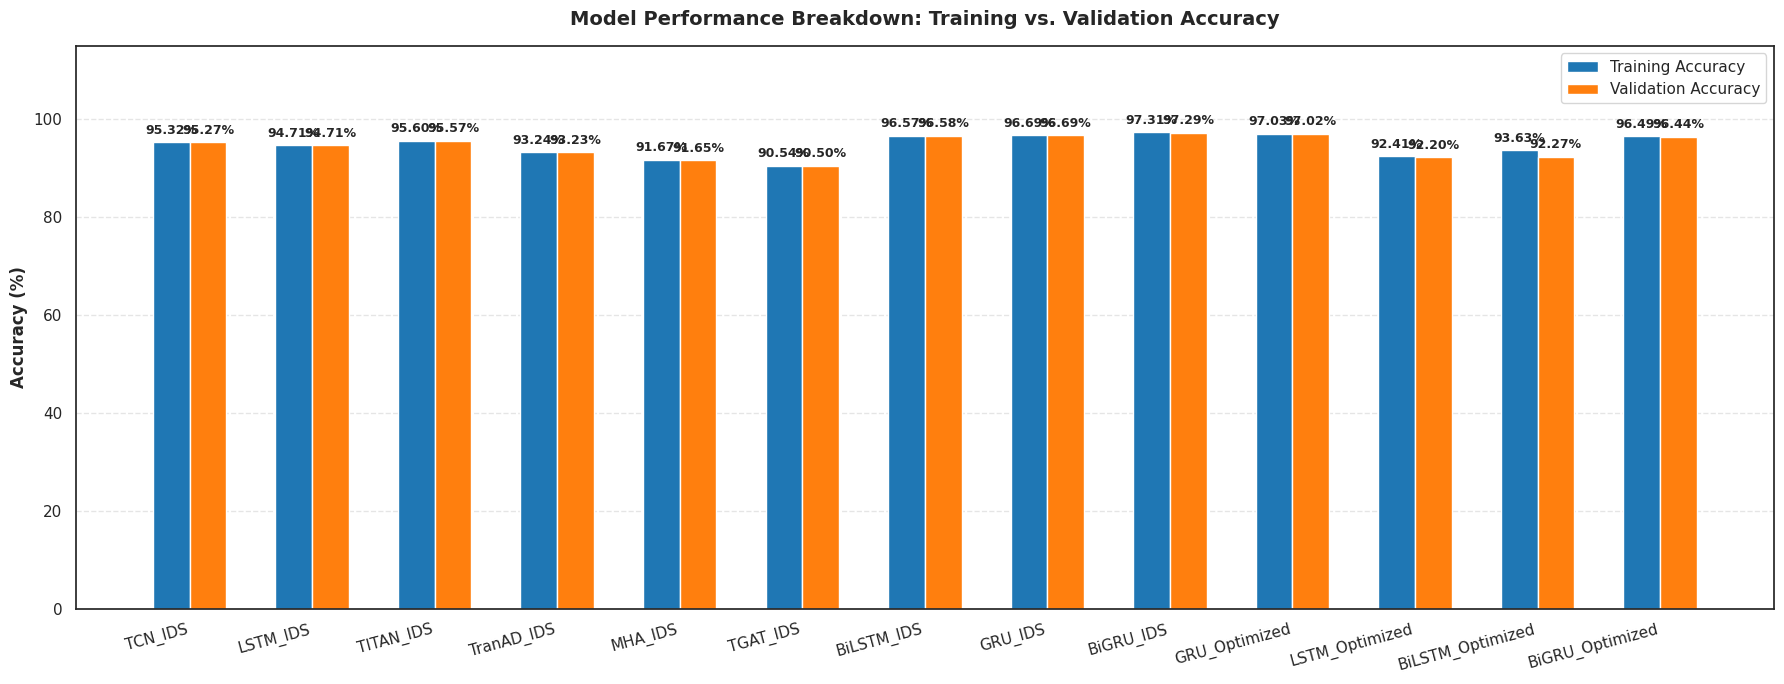

In [43]:
# Plot Model Registry the Latest Metrics:
plot_registry_accuracies(registry)

## Optimize LSTM IDS Model

In [54]:
# ==========================================
# CELL 8: OPTUNA SINGLE-OBJECTIVE EXECUTION (LSTM IDS)
# ==========================================
# Set which algorithm you want to optimize in this run
ALGO_TO_TUNE = "LSTM" 
timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
study_name = f"{ALGO_TO_TUNE}_Single_Objective_{timestamp}"
N_TRIALS = 50         


def main():
    print(f"Initializing Single-Objective Optuna Study for {study_name}...")
    
    lstm_study = get_study(study_name)
    
    # Pass the trial and the algo_abbr securely using a lambda function
    lstm_study.optimize(
        lambda trial: objective(trial, ALGO_TO_TUNE), 
        n_trials=N_TRIALS,
        callbacks=[duration_logging_callback]
    )

    return lstm_study

In [55]:
if __name__ == "__main__":
    lstm_study = main()

Initializing Single-Objective Optuna Study for LSTM_Single_Objective_20260706_195501...


/tmp/ipykernel_58/376658603.py:5: ExperimentalWarning: Argument ``multivariate`` is an experimental feature. The interface can change in the future.
  sampler=optuna.samplers.TPESampler(multivariate=True, seed=42, n_startup_trials=5),


INFO:tensorflow:Collective all_reduce tensors: 12 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
[I 2026-07-06 19:56:05,509] Trial 0 finished with values: [0.9907723069190979] and parameters: {'lr': 0.00043284502212938834, 'optimizer': 'Adam', 'loss': 'categorical_hinge', 'units_1': 90, 'units_2': 15, 'dropout_1': 0.00037381801866358396, 'dropout_2': 0.026713065149979655, 'activation_1': 'gelu', 'activation_2': 'gelu'}. Duration: 0:01:00.931445
INFO:tensorflow:Collective all_reduce tensors: 12 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
[I 2026-07-06 19:57:02,249] Trial 1 finished with values: [0.06351452320814133] and parameters: {'lr': 0.0010150667045928574, 'optimizer': 'AdamW', 'loss': 'categorical_focal_crossentropy', 'units_1': 60, 'units_2': 90, 'dropout_1': 0.0003329019834400152, 'dropout_2': 0.03346359193334512, 'activation_1': 'softmax', 'activati

In [57]:
# 4. Save results, fully retrain, and log to the global JSON registry
show_result(lstm_study, ALGO_TO_TUNE)


 SINGLE-OBJECTIVE OPTIMIZATION COMPLETE: LSTM
Study statistics: 
	Number of finished trials:  50
	Number of pruned trials:  25
	Number of complete trials:  25

[+] Best trial parameters saved to: /kaggle/working/lstm_best_trial_20260706_204140.json

Selected Best Trial (Trial #37):
  Validation Loss: 0.0269
Optimized Hyperparameters:
    - lr: 0.004192633327426523
    - optimizer: Adam
    - loss: categorical_focal_crossentropy
    - units_1: 60
    - units_2: 60
    - dropout_1: 0.0008484035982911404
    - dropout_2: 0.01787469503327528
    - activation_1: swish
    - activation_2: swish


In [ ]:
train_best_model(lstm_study.best_trial, ALGO_TO_TUNE)


Retraining Optimized LSTM Model for Full 50 Epochs...
Epoch 1/50
INFO:tensorflow:Collective all_reduce tensors: 12 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
1130/1131 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.7369 - loss: 0.1177
Epoch 1: val_loss improved from None to 0.02629, saving model to lstm_optimized_best_v1.keras

Epoch 1: finished saving model to lstm_optimized_best_v1.keras
1131/1131 ━━━━━━━━━━━━━━━━━━━━ 48s 38ms/step - accuracy: 0.8260 - loss: 0.0586 - val_accuracy: 0.8988 - val_loss: 0.0263
Epoch 2/50
1130/1131 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.8936 - loss: 0.0274
Epoch 2: val_loss improved from 0.02629 to 0.01986, saving model to lstm_optimized_best_v1.keras

Epoch 2: finished saving model to lstm_optimized_best_v1.keras
1131/1131 ━━━━━━━━━━━━━━━━━━━━ 38s 33ms/step - accuracy: 0.8979 - loss: 0.0259 - val_accuracy: 0.9109 - val_loss: 0.0199
Epoch 3/50
1130/1131 ━━━━━━━━━━━━━━━━━━━━ 0s 

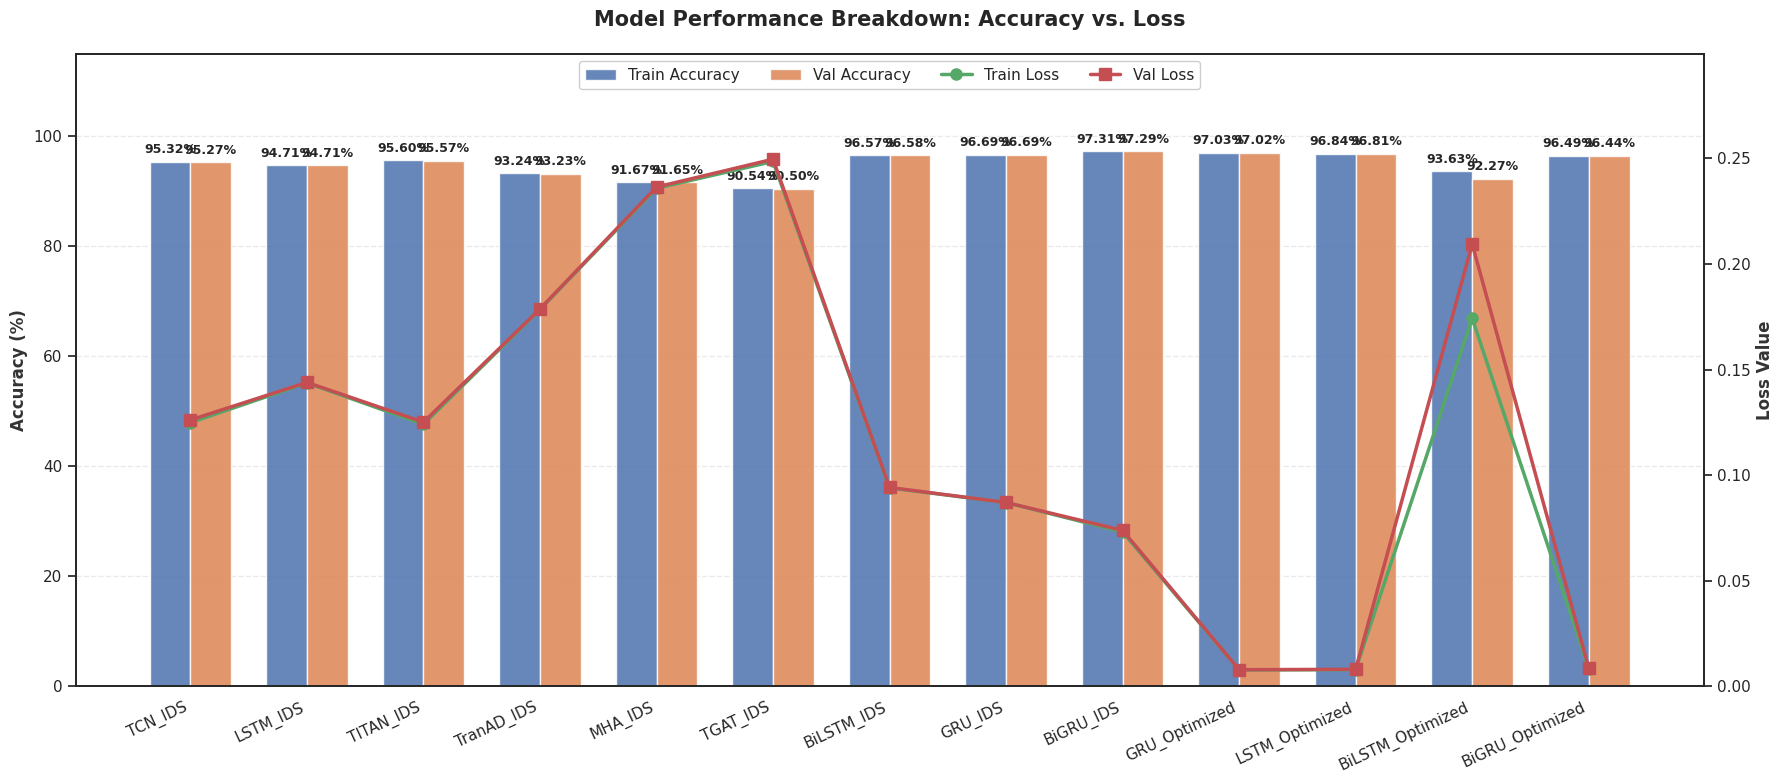

In [59]:
plot_registry_metrics(registry)

## Optimize BiLSTM IDS Model

In [32]:
# ==========================================
# CELL 8: OPTUNA SINGLE-OBJECTIVE EXECUTION (BiLSTM IDS)
# ==========================================
# Set which algorithm you want to optimize in this run
ALGO_TO_TUNE = "BiLSTM" 
timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
study_name = f"{ALGO_TO_TUNE}_Single_Objective_{timestamp}"
N_TRIALS = 50         


def main():
    print(f"Initializing Single-Objective Optuna Study for {study_name}...")
    
    study = get_study(study_name)
    
    # Pass the trial and the algo_abbr securely using a lambda function
    study.optimize(
        lambda trial: objective(trial, ALGO_TO_TUNE), 
        n_trials=N_TRIALS,
        callbacks=[duration_logging_callback]
    )

    return study

In [43]:
if __name__ == "__main__":
    study = main()

Initializing Single-Objective Optuna Study for BiLSTM_Single_Objective_20260712_013129...


/tmp/ipykernel_58/376658603.py:5: ExperimentalWarning: Argument ``multivariate`` is an experimental feature. The interface can change in the future.
  sampler=optuna.samplers.TPESampler(multivariate=True, seed=42, n_startup_trials=5),


INFO:tensorflow:Collective all_reduce tensors: 18 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
[I 2026-07-12 01:33:32,175] Trial 0 finished with values: [0.46311667561531067] and parameters: {'lr': 0.00043284502212938834, 'optimizer': 'Adam', 'loss': 'categorical_hinge', 'units_1': 90, 'units_2': 15, 'dropout_1': 0.00037381801866358396, 'dropout_2': 0.026713065149979655, 'activation_1': 'gelu', 'activation_2': 'gelu'}. Duration: 0:01:22.232714
INFO:tensorflow:Collective all_reduce tensors: 18 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
[I 2026-07-12 01:34:50,577] Trial 1 finished with values: [0.061993181705474854] and parameters: {'lr': 0.0010150667045928574, 'optimizer': 'AdamW', 'loss': 'categorical_focal_crossentropy', 'units_1': 60, 'units_2': 90, 'dropout_1': 0.0003329019834400152, 'dropout_2': 0.03346359193334512, 'activation_1': 'softmax', 'activa

Initializing Single-Objective Optuna Study for BiLSTM_Single_Objective_20260627_200535...
INFO:tensorflow:Collective all_reduce tensors: 18 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
[I 2026-06-27 20:07:21,775] Trial 0 finished with values: [0.7088598012924194] and parameters: {'units_1': 60, 'units_2': 90, 'dropout': 0.25839392397384603, 'lr': 0.00041041251620304464, 'loss': 'categorical_hinge'}. Duration: 0:01:42.485059
INFO:tensorflow:Collective all_reduce tensors: 18 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
[I 2026-06-27 20:08:57,317] Trial 1 finished with values: [0.584930956363678] and parameters: {'units_1': 15, 'units_2': 90, 'dropout': 0.09455160212245362, 'lr': 0.0012281951435166637, 'loss': 'categorical_hinge'}. Duration: 0:01:35.526250
INFO:tensorflow:Collective all_reduce tensors: 18 all_reduces, num_devices = 2, group_size = 2, implemen

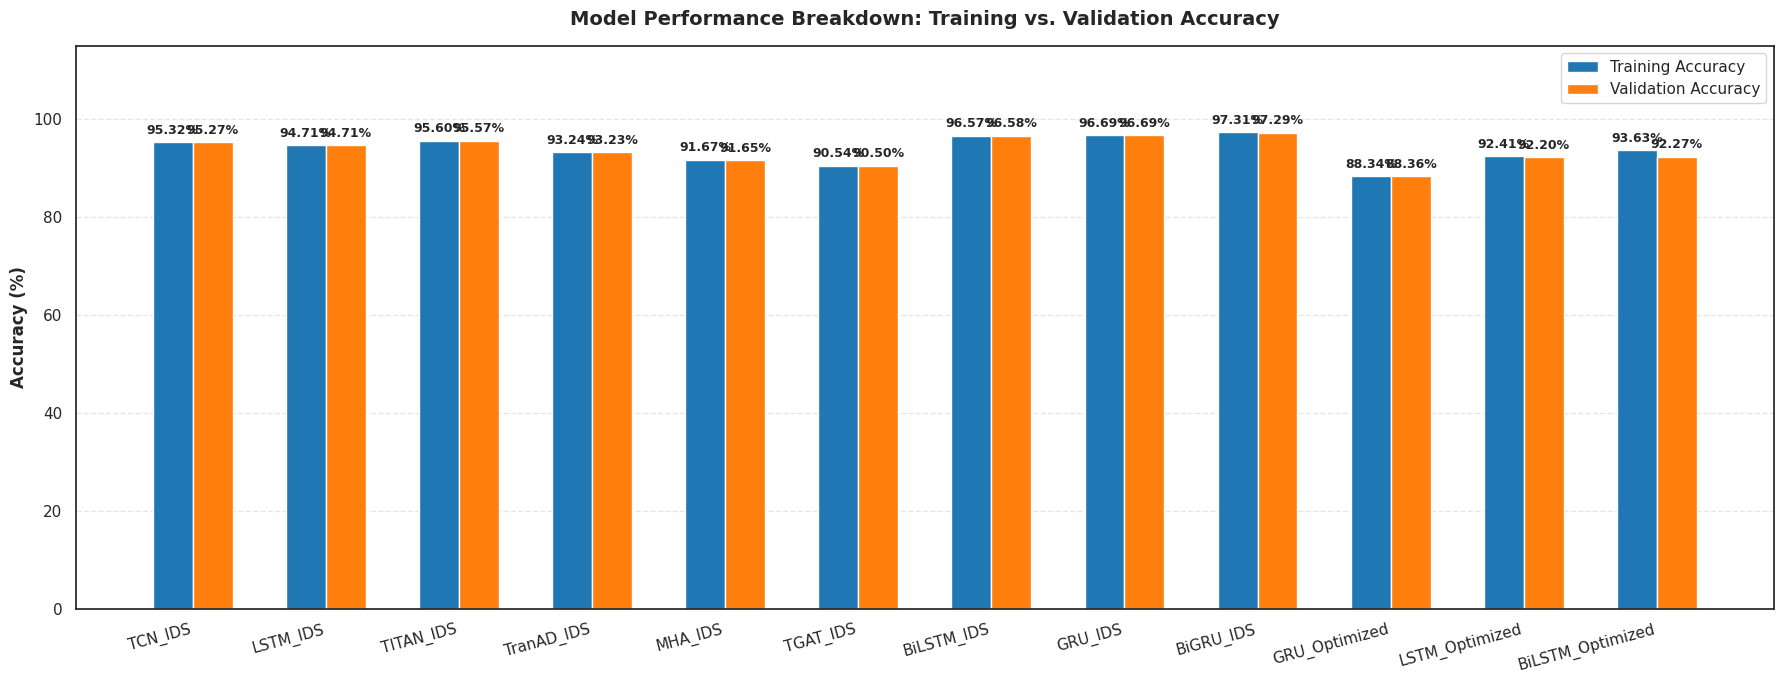

In [58]:
if __name__ == "__main__":
    study = main()

In [45]:
# Save results, fully retrain, and log to the global JSON registry
show_result(study, ALGO_TO_TUNE)


 SINGLE-OBJECTIVE OPTIMIZATION COMPLETE: BiLSTM
Study statistics: 
	Number of finished trials:  50
	Number of pruned trials:  21
	Number of complete trials:  29

[+] Best trial parameters saved to: /kaggle/working/bilstm_best_trial_20260712_021904.json

Selected Best Trial (Trial #10):
  Validation Loss: 0.0334
Optimized Hyperparameters:
    - lr: 0.0022621054316524438
    - optimizer: AdamW
    - loss: categorical_focal_crossentropy
    - d_model: 64
    - num_heads: 2
    - ff_dim: 128
    - dropout: 0.038587492706617474


In [35]:
bilstm_best_trial = get_best_trial('/kaggle/working/bilstm_best_trial_20260713_033018.json')
for key, value in bilstm_best_trial.saved_params.items():
    print(f"    - {key}: {value}")

    - lr: 0.00497736891607235
    - optimizer: Nadam
    - loss: categorical_focal_crossentropy
    - units_1: 30
    - units_2: 60
    - dropout_1: 0.0009932683143255858
    - dropout_2: 0.02706519235647191
    - activation_1: tanh
    - activation_2: tanh


In [41]:
train_best_model(bilstm_best_trial, ALGO_TO_TUNE)


Retraining Optimized BiLSTM Model for Full 50 Epochs...
Epoch 1/50


I0000 00:00:1783968913.710713      14 encapsulate_tpu_computations_pass.cc:266] Subgraph fingerprint:12665827798874082968
I0000 00:00:1783968914.720155    1692 tpu_compilation_cache_interface.cc:442] TPU host compilation cache miss: cache_key(8468983571961362363), session_name()


 2/54 ━━━━━━━━━━━━━━━━━━━━ 4s 94ms/step - accuracy: 0.0649 - loss: 0.9599  

I0000 00:00:1783968926.992914    1692 tpu_compile_op_common.cc:245] Compilation of 8468983571961362363 with session name  took 12.272714937s and succeeded
I0000 00:00:1783968927.023087    1692 tpu_compilation_cache_interface.cc:476] TPU host compilation cache: compilation complete for cache_key(8468983571961362363), session_name(), subgraph_key(std::string(property.function_name) = "cluster_one_step_on_data_12665827798874082968", property.function_library_fingerprint = 17855442192144094236, property.mlir_module_fingerprint = 0, property.num_replicas = 8, topology.chip_bounds().x = 2, topology.chip_bounds().y = 4, topology.chip_bounds().z = 1, topology.wrap().x = false, topology.wrap().y = false, topology.wrap().z = false, std::string(property.shapes_prefix) = "16384,4,15,;16384,34,;", property.guaranteed_constants_size = 0, embedding_partitions_fingerprint = "1688352644216761960")
I0000 00:00:1783968927.023113    1692 tpu_compilation_cache_interface.cc:542] After adding entry for key 8

53/54 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - accuracy: 0.4551 - loss: 0.3751

I0000 00:00:1783968931.437352    1698 tpu_compilation_cache_interface.cc:442] TPU host compilation cache miss: cache_key(17596066010372355181), session_name()


54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 302ms/step - accuracy: 0.4579 - loss: 0.3720

I0000 00:00:1783968943.019980    1698 tpu_compile_op_common.cc:245] Compilation of 17596066010372355181 with session name  took 11.5825877s and succeeded
I0000 00:00:1783968943.046294    1698 tpu_compilation_cache_interface.cc:476] TPU host compilation cache: compilation complete for cache_key(17596066010372355181), session_name(), subgraph_key(std::string(property.function_name) = "cluster_one_step_on_data_12665827798874082968", property.function_library_fingerprint = 17855442192144094236, property.mlir_module_fingerprint = 0, property.num_replicas = 8, topology.chip_bounds().x = 2, topology.chip_bounds().y = 4, topology.chip_bounds().z = 1, topology.wrap().x = false, topology.wrap().y = false, topology.wrap().z = false, std::string(property.shapes_prefix) = "6648,4,15,;6648,34,;", property.guaranteed_constants_size = 0, embedding_partitions_fingerprint = "1688352644216761960")
I0000 00:00:1783968943.046329    1698 tpu_compilation_cache_interface.cc:542] After adding entry for key 175


Epoch 1: val_loss improved from None to 0.08843, saving model to bilstm_optimized_best_v1.keras

Epoch 1: finished saving model to bilstm_optimized_best_v1.keras
54/54 ━━━━━━━━━━━━━━━━━━━━ 43s 497ms/step - accuracy: 0.6056 - loss: 0.2090 - val_accuracy: 0.7503 - val_loss: 0.0884
Epoch 2/50
53/54 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step - accuracy: 0.7516 - loss: 0.0844
Epoch 2: val_loss improved from 0.08843 to 0.06440, saving model to bilstm_optimized_best_v1.keras

Epoch 2: finished saving model to bilstm_optimized_best_v1.keras
54/54 ━━━━━━━━━━━━━━━━━━━━ 9s 163ms/step - accuracy: 0.7641 - loss: 0.0783 - val_accuracy: 0.7980 - val_loss: 0.0644
Epoch 3/50
53/54 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 0.7915 - loss: 0.0656
Epoch 3: val_loss improved from 0.06440 to 0.05459, saving model to bilstm_optimized_best_v1.keras

Epoch 3: finished saving model to bilstm_optimized_best_v1.keras
54/54 ━━━━━━━━━━━━━━━━━━━━ 10s 166ms/step - accuracy: 0.7978 - loss: 0.0629 - val_accuracy: 0.8179 - v

NameError: name 'plot_registry_accuracies' is not defined

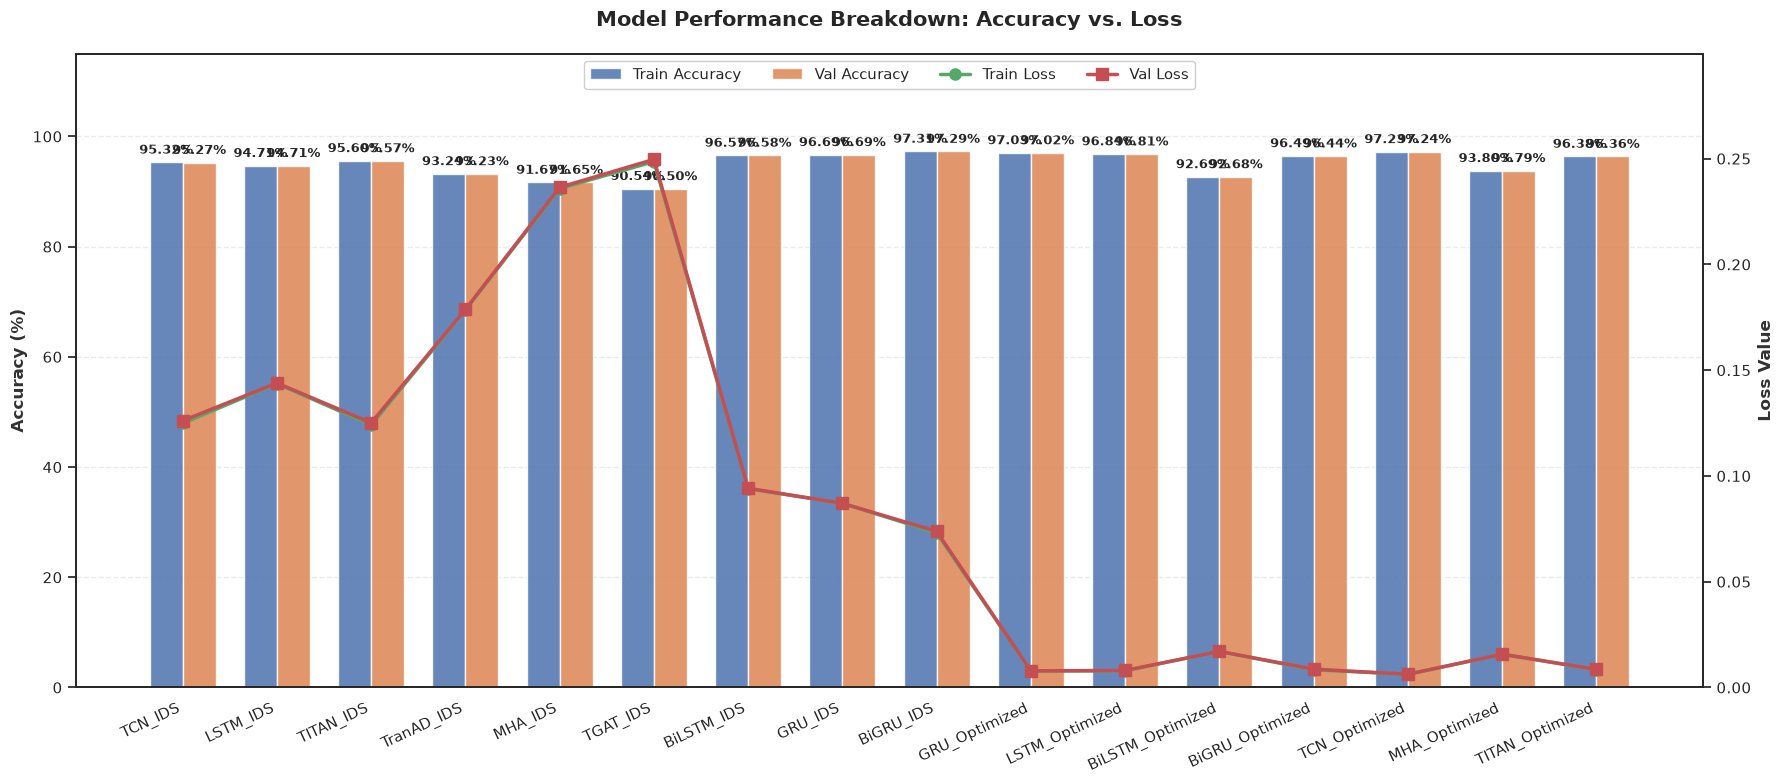

In [42]:
plot_registry_metrics(registry)

In [45]:
train_best_model(bilstm_best_trial, ALGO_TO_TUNE)


Retraining Optimized BiLSTM Model for Full 50 Epochs...
Epoch 1/50


I0000 00:00:1783969986.695397      14 encapsulate_tpu_computations_pass.cc:266] Subgraph fingerprint:6306734481292904072
I0000 00:00:1783969987.619260    1667 tpu_compilation_cache_interface.cc:442] TPU host compilation cache miss: cache_key(10284082561455705618), session_name()


  3/283 ━━━━━━━━━━━━━━━━━━━━ 12s 46ms/step - accuracy: 0.0748 - loss: 0.9613   

I0000 00:00:1783969999.128831    1667 tpu_compile_op_common.cc:245] Compilation of 10284082561455705618 with session name  took 11.509517321s and succeeded
I0000 00:00:1783969999.154800    1667 tpu_compilation_cache_interface.cc:476] TPU host compilation cache: compilation complete for cache_key(10284082561455705618), session_name(), subgraph_key(std::string(property.function_name) = "cluster_one_step_on_data_6306734481292904072", property.function_library_fingerprint = 4712546842857155796, property.mlir_module_fingerprint = 0, property.num_replicas = 8, topology.chip_bounds().x = 2, topology.chip_bounds().y = 4, topology.chip_bounds().z = 1, topology.wrap().x = false, topology.wrap().y = false, topology.wrap().z = false, std::string(property.shapes_prefix) = "3096,4,15,;3096,34,;", property.guaranteed_constants_size = 0, embedding_partitions_fingerprint = "1688352644216761960")
I0000 00:00:1783969999.154830    1667 tpu_compilation_cache_interface.cc:542] After adding entry for key 102

281/283 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.6629 - loss: 0.1761

I0000 00:00:1783970007.864405    1659 tpu_compilation_cache_interface.cc:442] TPU host compilation cache miss: cache_key(3089418748112903624), session_name()


283/283 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.6636 - loss: 0.1755

I0000 00:00:1783970019.558262    1659 tpu_compile_op_common.cc:245] Compilation of 3089418748112903624 with session name  took 11.693820408s and succeeded
I0000 00:00:1783970019.592450    1659 tpu_compilation_cache_interface.cc:476] TPU host compilation cache: compilation complete for cache_key(3089418748112903624), session_name(), subgraph_key(std::string(property.function_name) = "cluster_one_step_on_data_6306734481292904072", property.function_library_fingerprint = 4712546842857155796, property.mlir_module_fingerprint = 0, property.num_replicas = 8, topology.chip_bounds().x = 2, topology.chip_bounds().y = 4, topology.chip_bounds().z = 1, topology.wrap().x = false, topology.wrap().y = false, topology.wrap().z = false, std::string(property.shapes_prefix) = "1928,4,15,;1928,34,;", property.guaranteed_constants_size = 0, embedding_partitions_fingerprint = "1688352644216761960")
I0000 00:00:1783970019.592487    1659 tpu_compilation_cache_interface.cc:542] After adding entry for key 30894


Epoch 1: val_loss improved from None to 0.04302, saving model to bilstm_optimized_best_v1.keras

Epoch 1: finished saving model to bilstm_optimized_best_v1.keras
283/283 ━━━━━━━━━━━━━━━━━━━━ 47s 111ms/step - accuracy: 0.7661 - loss: 0.0908 - val_accuracy: 0.8487 - val_loss: 0.0430
Epoch 2/50
281/283 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.8550 - loss: 0.0425
Epoch 2: val_loss improved from 0.04302 to 0.02967, saving model to bilstm_optimized_best_v1.keras

Epoch 2: finished saving model to bilstm_optimized_best_v1.keras
283/283 ━━━━━━━━━━━━━━━━━━━━ 15s 51ms/step - accuracy: 0.8660 - loss: 0.0389 - val_accuracy: 0.8876 - val_loss: 0.0297
Epoch 3/50
281/283 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.8843 - loss: 0.0317
Epoch 3: val_loss improved from 0.02967 to 0.02564, saving model to bilstm_optimized_best_v1.keras

Epoch 3: finished saving model to bilstm_optimized_best_v1.keras
283/283 ━━━━━━━━━━━━━━━━━━━━ 15s 51ms/step - accuracy: 0.8875 - loss: 0.0302 - val_accuracy: 0

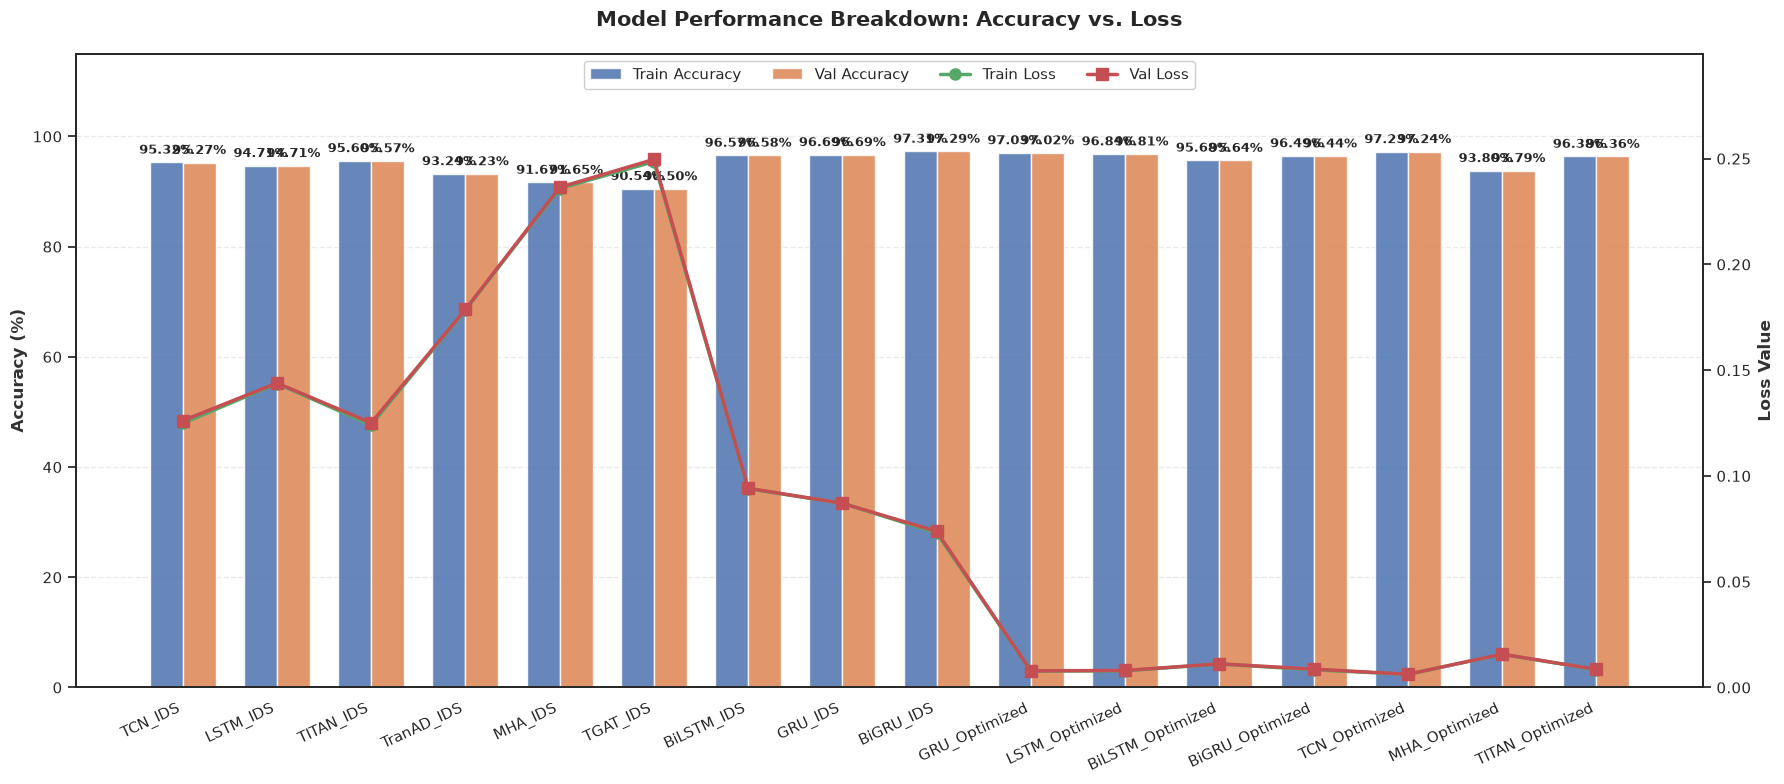

In [46]:
plot_registry_metrics(registry)

## Optimize TCN IDS Model

In [37]:
# ==========================================
# CELL 8: OPTUNA SINGLE-OBJECTIVE EXECUTION (LSTM IDS)
# ==========================================
# Set which algorithm you want to optimize in this run
ALGO_TO_TUNE = "TCN" 
timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
study_name = f"{ALGO_TO_TUNE}_Single_Objective_{timestamp}"
N_TRIALS = 50         


def main():
    print(f"Initializing Multi-Objective Optuna Study for {study_name}...")
    
    study = get_study(study_name)
    
    # Pass the trial and the algo_abbr securely using a lambda function
    study.optimize(
        lambda trial: objective(trial, ALGO_TO_TUNE), 
        n_trials=N_TRIALS,
        callbacks=[duration_logging_callback]
    )

    return study

In [38]:
if __name__ == "__main__":
    study = main()

Initializing Multi-Objective Optuna Study for TCN_Single_Objective_20260708_125620...


/tmp/ipykernel_57/376658603.py:5: ExperimentalWarning: Argument ``multivariate`` is an experimental feature. The interface can change in the future.
  sampler=optuna.samplers.TPESampler(multivariate=True, seed=42, n_startup_trials=5),


INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Redu

I0000 00:00:1783515404.910074     204 cuda_dnn.cc:529] Loaded cuDNN version 91002
I0000 00:00:1783515405.674909     206 cuda_dnn.cc:529] Loaded cuDNN version 91002


INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
[I 2026-07-08 12:57:36,569] Trial 0 finished with values: [0.9177780151367188] and parameters: {'lr': 0.00043284502212938834, 'optimizer': 'Adam', 'loss': 'categorical_hinge', 'filters': 64, 'dropout_1': 0.09699098521619944, 'dropout_2': 0.2497327922401265, 'activation_1': 'softmax', 'activation_2': 'gelu'}. Duration: 0:01:01.380926
INFO:tensorflow:Collective all_reduce tensors: 24 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
[I 2026-07-08 12:58:59,998] Trial 1 finished with values: [0.30271512269973755] and parameters: {'lr': 0.0004192159350410976, 'optimizer': 'AdamW', 'loss': 'categorical_hinge', 'filters': 128, 'dropout_1': 0.0965632033074559

In [39]:
# 5. Save results, fully retrain, and log to the global JSON registry
show_result(study, ALGO_TO_TUNE)


 SINGLE-OBJECTIVE OPTIMIZATION COMPLETE: TCN
Study statistics: 
	Number of finished trials:  50
	Number of pruned trials:  19
	Number of complete trials:  31

[+] Best trial parameters saved to: /kaggle/working/tcn_best_trial_20260708_134236.json

Selected Best Trial (Trial #22):
  Validation Loss: 0.0241
Optimized Hyperparameters:
    - lr: 0.004565497486103845
    - optimizer: Adam
    - loss: categorical_focal_crossentropy
    - filters: 128
    - dropout_1: 0.09800451433246012
    - dropout_2: 0.0711887052644295
    - activation_1: gelu
    - activation_2: gelu


In [38]:
tcn_best_trial = get_best_trial('/kaggle/working/tcn_best_trial_20260708_134236.json')

In [44]:
train_best_model(tcn_best_trial, ALGO_TO_TUNE)

NameError: name 'tcn_best_trial' is not defined

In [ ]:
train_best_model(study.best_trial, ALGO_TO_TUNE)


Retraining Optimized TCN Model for Full 50 Epochs...
Epoch 1/50
INFO:tensorflow:Collective all_reduce tensors: 24 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
1131/1131 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.7927 - loss: 0.0757
Epoch 1: val_loss improved from None to 0.03350, saving model to tcn_optimized_best_v1.keras

Epoch 1: finished saving model to tcn_optimized_best_v1.keras
1131/1131 ━━━━━━━━━━━━━━━━━━━━ 78s 63ms/step - accuracy: 0.8517 - loss: 0.0437 - val_accuracy: 0.8848 - val_loss: 0.0335
Epoch 2/50
1131/1131 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.8926 - loss: 0.0280
Epoch 2: val_loss improved from 0.03350 to 0.02541, saving model to tcn_optimized_best_v1.keras

Epoch 2: finished saving model to tcn_optimized_best_v1.keras
1131/1131 ━━━━━━━━━━━━━━━━━━━━ 67s 59ms/step - accuracy: 0.8985 - loss: 0.0257 - val_accuracy: 0.9053 - val_loss: 0.0254
Epoch 3/50
1130/1131 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/

In [ ]:
plot_registry_metrics(registry)

## Optimize MHA IDS Model

In [ ]:
# ==========================================
# CELL 8: OPTUNA SINGLE-OBJECTIVE EXECUTION (LSTM IDS)
# ==========================================
# Set which algorithm you want to optimize in this run
ALGO_TO_TUNE = "MHA" 
timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
study_name = f"{ALGO_TO_TUNE}_Single_Objective_{timestamp}"
N_TRIALS = 50         


def main():
    print(f"Initializing Multi-Objective Optuna Study for {study_name}...")
    
    study = get_study(study_name)
    
    # Pass the trial and the algo_abbr securely using a lambda function
    study.optimize(
        lambda trial: objective(trial, ALGO_TO_TUNE), 
        n_trials=N_TRIALS,
        callbacks=[duration_logging_callback]
    )

    return study

In [ ]:
if __name__ == "__main__":
    main()

In [ ]:
# 5. Save results, fully retrain, and log to the global JSON registry
show_result(study, ALGO_TO_TUNE, registry)

In [ ]:
train_best_model(study.best_trial, ALGO_TO_TUNE)

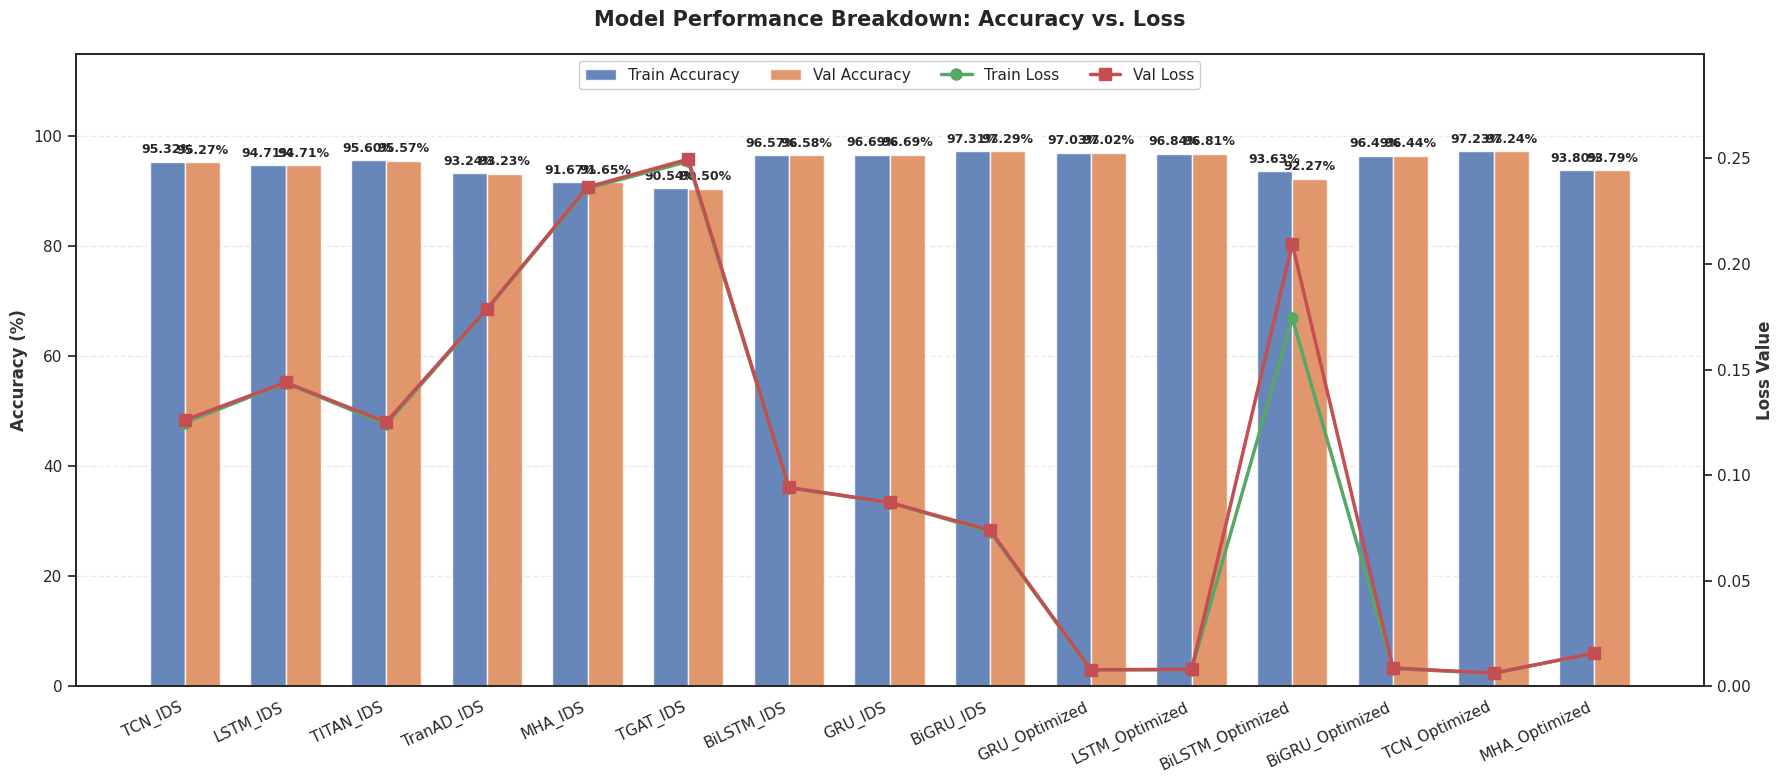

In [47]:
plot_registry_metrics(registry)

## Optimize TITAN IDS Model

In [54]:
# ==========================================
# CELL 8: OPTUNA SINGLE-OBJECTIVE EXECUTION (LSTM IDS)
# ==========================================
# Set which algorithm you want to optimize in this run
ALGO_TO_TUNE = "TITAN" 
timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
study_name = f"{ALGO_TO_TUNE}_Single_Objective_{timestamp}"
N_TRIALS = 50         


def main():
    print(f"Initializing Multi-Objective Optuna Study for {study_name}...")
    
    study = get_study(study_name)
    
    # Pass the trial and the algo_abbr securely using a lambda function
    study.optimize(
        lambda trial: objective(trial, ALGO_TO_TUNE), 
        n_trials=N_TRIALS,
        callbacks=[duration_logging_callback]
    )


    return study

In [49]:
if __name__ == "__main__":
    study = main()

Initializing Multi-Objective Optuna Study for TITAN_Single_Objective_20260710_012933...


/tmp/ipykernel_58/376658603.py:5: ExperimentalWarning: Argument ``multivariate`` is an experimental feature. The interface can change in the future.
  sampler=optuna.samplers.TPESampler(multivariate=True, seed=42, n_startup_trials=5),


INFO:tensorflow:Collective all_reduce tensors: 60 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
[I 2026-07-10 01:31:29,247] Trial 0 finished with values: [0.9577834606170654] and parameters: {'lr': 0.00043284502212938834, 'optimizer': 'Adam', 'loss': 'categorical_hinge', 'd_model': 64, 'num_heads': 4, 'persistent_tokens': 4, 'titan_dense_units': 64, 'titan_dense_act': 'relu'}. Duration: 0:01:45.884411
INFO:tensorflow:Collective all_reduce tensors: 60 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
[I 2026-07-10 01:32:37,948] Trial 1 finished with values: [0.5546878576278687] and parameters: {'lr': 0.001095266274863256, 'optimizer': 'RMSprop', 'loss': 'categorical_crossentropy', 'd_model': 32, 'num_heads': 2, 'persistent_tokens': 8, 'titan_dense_units': 16, 'titan_dense_act': 'swish'}. Duration: 0:01:08.683919
INFO:tensorflow:Collective all_reduce tensors: 60 a

In [51]:
#Save results, fully retrain, and log to the global JSON registry
show_result(study, ALGO_TO_TUNE)


 SINGLE-OBJECTIVE OPTIMIZATION COMPLETE: TITAN
Study statistics: 
	Number of finished trials:  50
	Number of pruned trials:  26
	Number of complete trials:  24

[+] Best trial parameters saved to: /kaggle/working/titan_best_trial_20260710_023343.json

Selected Best Trial (Trial #19):
  Validation Loss: 0.0333
Optimized Hyperparameters:
    - lr: 0.0012639776834554993
    - optimizer: Nadam
    - loss: categorical_focal_crossentropy
    - d_model: 64
    - num_heads: 2
    - persistent_tokens: 4
    - titan_dense_units: 64
    - titan_dense_act: gelu


In [59]:
titan_best_trial = get_best_trial('/kaggle/working/titan_best_trial_20260710_023338.json')

In [60]:
for key, value in titan_best_trial.params.items():
    print(f"    - {key}: {value}")

In [ ]:
train_best_model(titan_best_trial, ALGO_TO_TUNE)


Retraining Optimized TITAN Model for Full 50 Epochs...
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhos

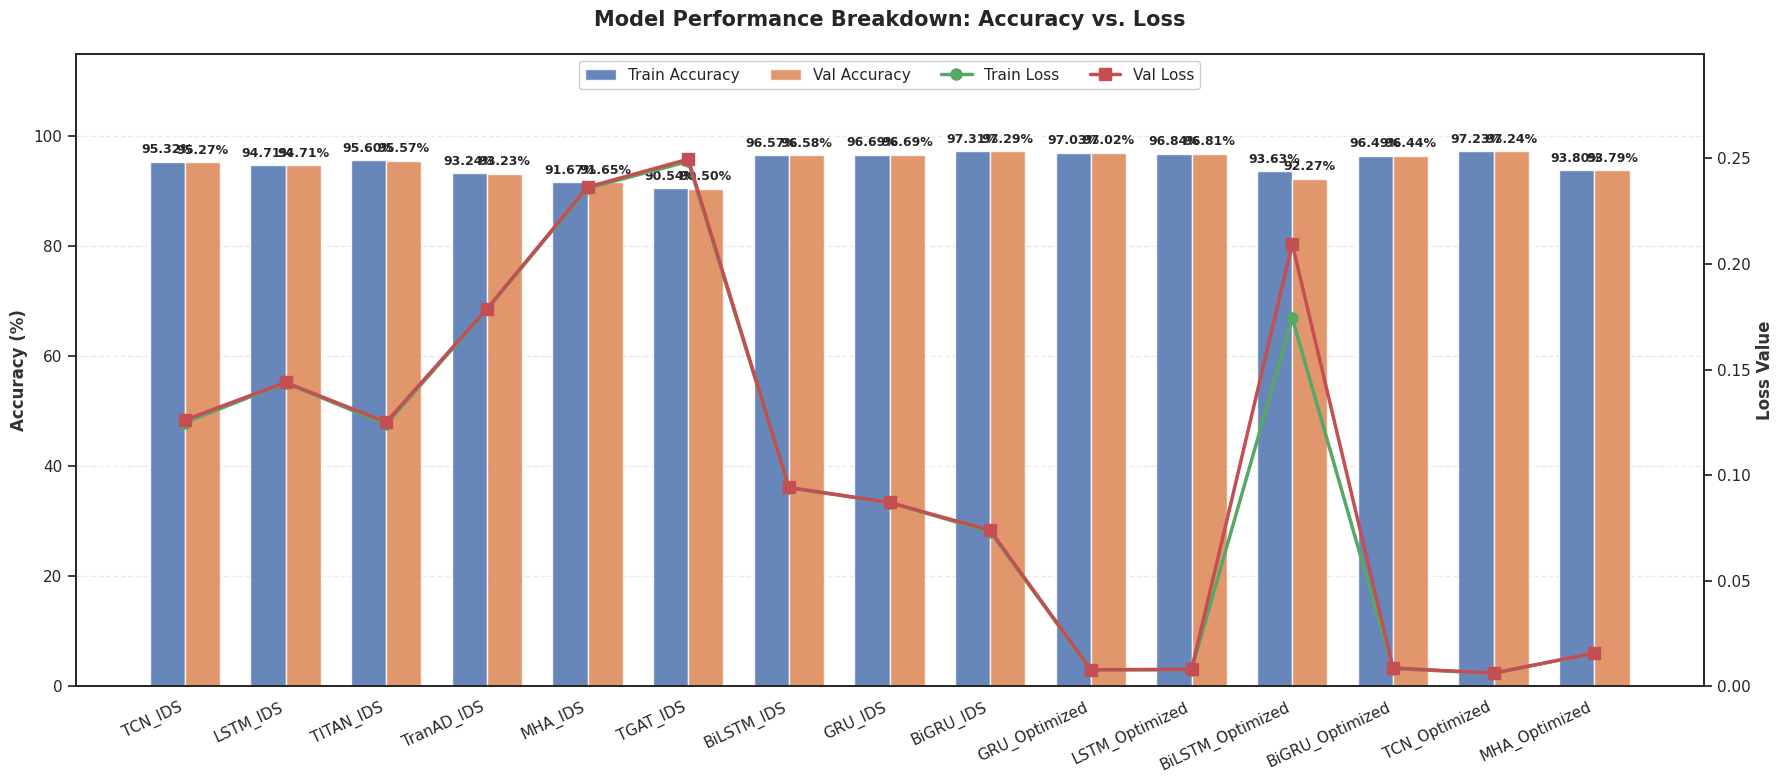

In [39]:
plot_registry_metrics(registry)

## Optimize TranAD IDS Model

In [47]:
# ==========================================
# CELL 8: OPTUNA SINGLE-OBJECTIVE EXECUTION (LSTM IDS)
# ==========================================
# Set which algorithm you want to optimize in this run
ALGO_TO_TUNE = "TranAD" 
timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
study_name = f"{ALGO_TO_TUNE}_Single_Objective_{timestamp}"
N_TRIALS = 50         


def main():
    print(f"Initializing Multi-Objective Optuna Study for {study_name}...")
    
    study = get_study(study_name)
    
    # Pass the trial and the algo_abbr securely using a lambda function
    study.optimize(
        lambda trial: objective(trial, ALGO_TO_TUNE), 
        n_trials=N_TRIALS,
        callbacks=[duration_logging_callback]
    )
    
    return study

In [38]:
if __name__ == "__main__":
    study = main()

Initializing Multi-Objective Optuna Study for TranAD_Single_Objective_20260712_003622...


/tmp/ipykernel_58/376658603.py:5: ExperimentalWarning: Argument ``multivariate`` is an experimental feature. The interface can change in the future.
  sampler=optuna.samplers.TPESampler(multivariate=True, seed=42, n_startup_trials=5),


INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Redu

In [39]:
#Save results, fully retrain, and log to the global JSON registry
show_result(study, ALGO_TO_TUNE)


 SINGLE-OBJECTIVE OPTIMIZATION COMPLETE: TranAD
Study statistics: 
	Number of finished trials:  50
	Number of pruned trials:  21
	Number of complete trials:  29

[+] Best trial parameters saved to: /kaggle/working/tranad_best_trial_20260712_012147.json

Selected Best Trial (Trial #10):
  Validation Loss: 0.0334
Optimized Hyperparameters:
    - lr: 0.0022621054316524438
    - optimizer: AdamW
    - loss: categorical_focal_crossentropy
    - d_model: 64
    - num_heads: 2
    - ff_dim: 128
    - dropout: 0.038587492706617474


In [49]:
tranad_best_trial = get_best_trial('/kaggle/working/tranad_best_trial_20260712_012147.json')
for key, value in tranad_best_trial.saved_params.items():
    print(f"    - {key}: {value}")

    - lr: 0.0022621054316524438
    - optimizer: AdamW
    - loss: categorical_focal_crossentropy
    - d_model: 64
    - num_heads: 2
    - ff_dim: 128
    - dropout: 0.038587492706617474


In [50]:
train_best_model(tranad_best_trial, ALGO_TO_TUNE)


Retraining Optimized TranAD Model for Full 50 Epochs...
Epoch 1/50


I0000 00:00:1783970981.602494      14 encapsulate_tpu_computations_pass.cc:266] Subgraph fingerprint:3350064973305257730
I0000 00:00:1783970982.614838    1644 tpu_compilation_cache_interface.cc:442] TPU host compilation cache miss: cache_key(10733067029427727463), session_name()


  3/283 ━━━━━━━━━━━━━━━━━━━━ 9s 34ms/step - accuracy: 0.0502 - loss: 0.8087    

I0000 00:00:1783971001.042162    1644 tpu_compile_op_common.cc:245] Compilation of 10733067029427727463 with session name  took 18.42728191s and succeeded
I0000 00:00:1783971001.080259    1644 tpu_compilation_cache_interface.cc:476] TPU host compilation cache: compilation complete for cache_key(10733067029427727463), session_name(), subgraph_key(std::string(property.function_name) = "cluster_one_step_on_data_3350064973305257730", property.function_library_fingerprint = 10273602469327175519, property.mlir_module_fingerprint = 0, property.num_replicas = 8, topology.chip_bounds().x = 2, topology.chip_bounds().y = 4, topology.chip_bounds().z = 1, topology.wrap().x = false, topology.wrap().y = false, topology.wrap().z = false, std::string(property.shapes_prefix) = "3096,4,15,;3096,34,;", property.guaranteed_constants_size = 0, embedding_partitions_fingerprint = "1688352644216761960")
I0000 00:00:1783971001.080292    1644 tpu_compilation_cache_interface.cc:542] After adding entry for key 107

281/283 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.5946 - loss: 0.2222

...

283/283 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step - accuracy: 0.5955 - loss: 0.2214

I0000 00:00:1783971028.191609    1664 tpu_compile_op_common.cc:245] Compilation of 553143557789465842 with session name  took 18.549264268s and succeeded
I0000 00:00:1783971028.230782    1664 tpu_compilation_cache_interface.cc:476] TPU host compilation cache: compilation complete for cache_key(553143557789465842), session_name(), subgraph_key(std::string(property.function_name) = "cluster_one_step_on_data_3350064973305257730", property.function_library_fingerprint = 10273602469327175519, property.mlir_module_fingerprint = 0, property.num_replicas = 8, topology.chip_bounds().x = 2, topology.chip_bounds().y = 4, topology.chip_bounds().z = 1, topology.wrap().x = false, topology.wrap().y = false, topology.wrap().z = false, std::string(property.shapes_prefix) = "1928,4,15,;1928,34,;", property.guaranteed_constants_size = 0, embedding_partitions_fingerprint = "1688352644216761960")
I0000 00:00:1783971028.230819    1664 tpu_compilation_cache_interface.cc:542] After adding entry for key 553143


Epoch 1: val_loss improved from None to 0.06126, saving model to tranad_optimized_best_v1.keras

Epoch 1: finished saving model to tranad_optimized_best_v1.keras
283/283 ━━━━━━━━━━━━━━━━━━━━ 63s 141ms/step - accuracy: 0.7192 - loss: 0.1161 - val_accuracy: 0.7714 - val_loss: 0.0613
Epoch 2/50
281/283 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.8153 - loss: 0.0556
Epoch 2: val_loss improved from 0.06126 to 0.04287, saving model to tranad_optimized_best_v1.keras

Epoch 2: finished saving model to tranad_optimized_best_v1.keras
283/283 ━━━━━━━━━━━━━━━━━━━━ 15s 52ms/step - accuracy: 0.8264 - loss: 0.0516 - val_accuracy: 0.8576 - val_loss: 0.0429
Epoch 3/50
282/283 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.8547 - loss: 0.0419
Epoch 3: val_loss improved from 0.04287 to 0.02895, saving model to tranad_optimized_best_v1.keras

Epoch 3: finished saving model to tranad_optimized_best_v1.keras
283/283 ━━━━━━━━━━━━━━━━━━━━ 15s 52ms/step - accuracy: 0.8624 - loss: 0.0389 - val_accuracy: 0

/usr/local/lib/python3.12/site-packages/keras/src/layers/layer.py:427: UserWarning: `build()` was called on layer 'transformer_encoder_block', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/usr/local/lib/python3.12/site-packages/keras/src/layers/layer.py:427: UserWarning: `build()` was called on layer 'transformer_encoder_block_1', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


Train Acc: 95.64% | Test Acc: 95.66%
Successfully added 'TranAD_Optimized' metrics to registry container.
Master benchmark dataset written to: /kaggle/working/all_network_models_report.json


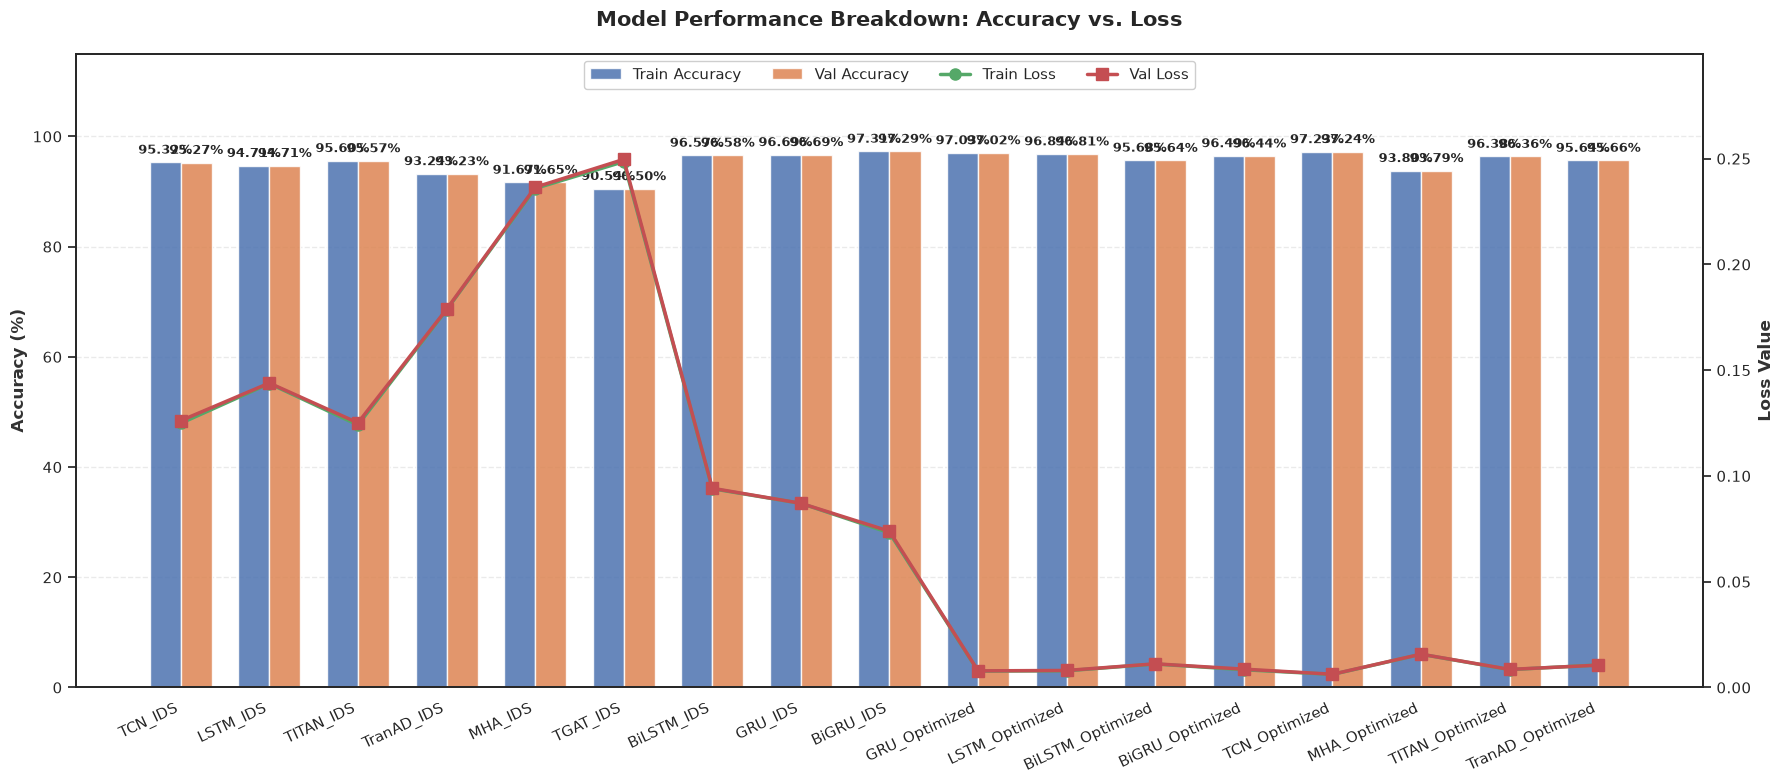

In [52]:
plot_registry_metrics(registry)

## Optimize TGAT IDS Model

In [33]:
# ==========================================
# CELL 8: OPTUNA SINGLE-OBJECTIVE EXECUTION (LSTM IDS)
# ==========================================
# Set which algorithm you want to optimize in this run
ALGO_TO_TUNE = "TGAT" 
timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
study_name = f"{ALGO_TO_TUNE}_Single_Objective_{timestamp}"
N_TRIALS = 50         


def main():
    print(f"Initializing Single-Objective Optuna Study for {study_name}...")
    
    study = get_study(study_name)
    
    # Pass the trial and the algo_abbr securely using a lambda function
    study.optimize(
        lambda trial: objective(trial, ALGO_TO_TUNE), 
        n_trials=N_TRIALS,
        callbacks=[duration_logging_callback]
    )

    return study

In [28]:
X_train, X_test, y_train, y_test, encoding_mappings = run_threshold_netflow_tgat_pipeline('/kaggle/working/ids_encoded_15_sel_feat.parquet', total_rows=1_000_000)

Preparing lazy encoding and safe downcasting...
Mapping temporal windows (incomplete sequences will be automatically skipped)...
Evaluating post-window class distributions for Threshold Stratification...


/tmp/ipykernel_58/4036603101.py:90: DeprecationWarning: the `streaming` parameter was deprecated in 1.25.0; use `engine` instead.
  meta_df = lazy_tgat_pool.select(["row_id", target_col]).collect(streaming=True)


Threshold: 100000 rows. Minorities keep all (214676 total).
The 19 major classes will be capped at ~41332 rows each.


Stratifying Classes:   0%|          | 0/34 [00:00<?, ?it/s]

Extracting stratified rows via streaming batch execution...


/tmp/ipykernel_58/4036603101.py:139: DeprecationWarning: the `streaming` parameter was deprecated in 1.25.0; use `engine` instead.
  .collect(streaming=True) # Forces Out-of-core batching to prevent OOM


Splitting dataset into 70% Train and 30% Test...
Assembling final 3D NumPy matrices for TGAT training...

Pipeline Executed Successfully without OOM!
X_train Shape: (699988, 4, 12) | y_train Shape: (699988,)
X_test Shape:  (299996, 4, 12)  | y_test Shape:  (299996,)


In [36]:
if __name__ == "__main__":
    study = main()

Initializing Single-Objective Optuna Study for TGAT_Single_Objective_20260712_025745...


/tmp/ipykernel_58/419361122.py:5: ExperimentalWarning: Argument ``multivariate`` is an experimental feature. The interface can change in the future.
  sampler=optuna.samplers.TPESampler(multivariate=True, seed=42, n_startup_trials=5),


INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Collective all_reduce tensors: 38 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1

In [37]:
# Save results, fully retrain, and log to the global JSON registry
show_result(study, ALGO_TO_TUNE)


 SINGLE-OBJECTIVE OPTIMIZATION COMPLETE: TGAT
Study statistics: 
	Number of finished trials:  50
	Number of pruned trials:  34
	Number of complete trials:  16

[+] Best trial parameters saved to: /kaggle/working/tgat_best_trial_20260712_033458.json

Selected Best Trial (Trial #45):
  Validation Loss: 0.4332
Optimized Hyperparameters:
    - lr: 0.0012932041098192037
    - optimizer: Adam
    - d_model: 64
    - num_heads: 2
    - dense_dim: 32


In [34]:
X_train, X_test, y_train, y_test, encoding_mappings = run_threshold_netflow_tgat_pipeline('/kaggle/working/ids_encoded_15_sel_feat.parquet', total_rows=10_000_000)

Preparing lazy encoding and safe downcasting...
Mapping temporal windows (incomplete sequences will be automatically skipped)...
Evaluating post-window class distributions for Threshold Stratification...


/tmp/ipykernel_58/4036603101.py:90: DeprecationWarning: the `streaming` parameter was deprecated in 1.25.0; use `engine` instead.
  meta_df = lazy_tgat_pool.select(["row_id", target_col]).collect(streaming=True)


Threshold: 1000000 rows. Minorities keep all (2472910 total).
The 9 major classes will be capped at ~836343 rows each.


Stratifying Classes:   0%|          | 0/34 [00:00<?, ?it/s]

Extracting stratified rows via streaming batch execution...


/tmp/ipykernel_58/4036603101.py:139: DeprecationWarning: the `streaming` parameter was deprecated in 1.25.0; use `engine` instead.
  .collect(streaming=True) # Forces Out-of-core batching to prevent OOM


Splitting dataset into 70% Train and 30% Test...
Assembling final 3D NumPy matrices for TGAT training...

Pipeline Executed Successfully without OOM!
X_train Shape: (6999997, 4, 12) | y_train Shape: (6999997,)
X_test Shape:  (3000000, 4, 12)  | y_test Shape:  (3000000,)


In [35]:
tgat_best_trial = get_best_trial('/kaggle/working/tgat_best_trial_20260712_033458.json')
for key, value in tgat_best_trial.saved_params.items():
    print(f"    - {key}: {value}")

    - lr: 0.0012932041098192037
    - optimizer: Adam
    - d_model: 64
    - num_heads: 2
    - dense_dim: 32


In [ ]:
train_best_model(tgat_best_trial, ALGO_TO_TUNE)


Retraining Optimized TGAT Model for Full 50 Epochs...
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost

In [ ]:
plot_registry_metrics(registry)